In [ ]:

import os
import sys
import platform
import torch

print("=== VEERA Environment Check ===")
print("Python:", sys.version)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU detected.")

try:
    import transformers
    print("Transformers:", transformers.__version__)
except ImportError:
    print("Transformers: not installed")

try:
    import datasets
    print("Datasets:", datasets.__version__)
except ImportError:
    print("Datasets: not installed")

print("\n=== Notebook working directory ===")
print(os.getcwd())


In [ ]:

from datasets import load_dataset
from collections import Counter

print("Loading RePOPE dataset...")

ds = load_dataset("MM-Hallu/RePOPE")

print("\n=== Dataset splits ===")
print(ds)

for split_name, split in ds.items():
    print(f"\n=== {split_name} ===")
    print("Number of rows:", len(split))
    print("Columns:", split.column_names)

    if len(split) > 0:
        print("\nFirst example:")
        print(split[0])

        for label_col in ["answer", "label", "ground_truth"]:
            if label_col in split.column_names:
                print(f"\nDistribution of {label_col}:")
                print(Counter(str(x) for x in split[label_col]))
                break


In [ ]:

import matplotlib.pyplot as plt
from collections import Counter

# Reproducible sample of 12 examples
sample = ds["train"].shuffle(seed=42).select(range(12))

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, example in enumerate(sample):
    image = example["image"].convert("RGB")

    axes[i].imshow(image)
    axes[i].set_title(
        f'ID: {example["image_id"]}\n'
        f'Q: {example["question"]}\n'
        f'Label: {example["answer"]}',
        fontsize=8
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
from collections import Counter

# Normalize labels and create a reproducible, balanced sample
data = ds["train"].shuffle(seed=42)

yes_rows = [
    i for i, row in enumerate(data)
    if str(row["answer"]).strip().lower() == "yes"
]
no_rows = [
    i for i, row in enumerate(data)
    if str(row["answer"]).strip().lower() == "no"
]

sample_size_per_class = 100

selected_indices = (
    yes_rows[:sample_size_per_class]
    + no_rows[:sample_size_per_class]
)

eval_ds = data.select(selected_indices).shuffle(seed=42)

print("Evaluation sample size:", len(eval_ds))
print("Label distribution:", Counter(
    row["answer"].strip().lower() for row in eval_ds
))

# Save a manifest for reproducibility (without duplicating image files)
manifest = pd.DataFrame([
    {
        "image_id": row["image_id"],
        "question": row["question"],
        "ground_truth": row["answer"].strip().lower(),
        "category": row["category"],
    }
    for row in eval_ds
])

manifest.to_csv(
    "/kaggle/working/veera_eval_manifest.csv",
    index=False
)

print("Manifest saved to /kaggle/working/veera_eval_manifest.csv")
display(manifest.head(10))


In [ ]:

import importlib.util
import transformers

print("Transformers version:", transformers.__version__)

packages = [
    "torch",
    "transformers",
    "accelerate",
    "qwen_vl_utils",
    "PIL",
    "pandas",
    "sklearn",
]

for package in packages:
    print(f"{package}:",
          "available" if importlib.util.find_spec(package)
          else "NOT INSTALLED")

try:
    from transformers import Qwen2_5_VLForConditionalGeneration
    print("\nQwen2.5-VL model class: available")
except Exception as e:
    print("\nQwen2.5-VL model class: unavailable")
    print(type(e).__name__ + ":", str(e)[:500])


In [ ]:

%pip install qwen-vl-utils


In [ ]:

import torch
import transformers
from qwen_vl_utils import process_vision_info
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())
print("Qwen model class: imported successfully")
print("Vision utilities: imported successfully")


In [ ]:

import torch
from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor,
)

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
)

processor = AutoProcessor.from_pretrained(MODEL_ID)

model.eval()

print("Model loaded successfully:", MODEL_ID)
print("GPU:", torch.cuda.get_device_name(0))
print(
    "Model device:",
    next(model.parameters()).device
)


In [ ]:

from qwen_vl_utils import process_vision_info

example = eval_ds[0]
image = example["image"].convert("RGB")
question = example["question"]

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {
                "type": "text",
                "text": (
                    f"{question} "
                    "Answer with only Yes or No."
                ),
            },
        ],
    }
]

prompt = processor.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)

image_inputs, video_inputs = process_vision_info(messages)

inputs = processor(
    text=[prompt],
    images=image_inputs,
    videos=video_inputs,
    padding=True,
    return_tensors="pt",
).to(model.device)

with torch.inference_mode():
    generated_ids = model.generate(
        **inputs,
        max_new_tokens=8,
        do_sample=False,
    )

new_tokens = generated_ids[:, inputs.input_ids.shape[1]:]

response = processor.batch_decode(
    new_tokens,
    skip_special_tokens=True,
)[0].strip()

print("Question:", question)
print("Ground truth:", example["answer"])
print("Model response:", repr(response))


In [ ]:

import time
import re
import pandas as pd
from tqdm.auto import tqdm
from qwen_vl_utils import process_vision_info

def predict_yes_no(image, question):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image.convert("RGB")},
            {
                "type": "text",
                "text": (
                    f"{question} "
                    "Answer with only Yes or No."
                ),
            },
        ],
    }]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    ).to(model.device)

    start = time.perf_counter()

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    latency = time.perf_counter() - start

    new_tokens = generated[:, inputs.input_ids.shape[1]:]
    raw = processor.batch_decode(
        new_tokens,
        skip_special_tokens=True,
    )[0].strip()

    match = re.match(r"^\s*(yes|no)\b", raw, flags=re.I)
    prediction = match.group(1).lower() if match else "unparsed"

    return prediction, raw, latency


results = []

for i, row in enumerate(tqdm(eval_ds, desc="VEERA baseline")):
    try:
        prediction, raw, latency = predict_yes_no(
            row["image"], row["question"]
        )

        truth = row["answer"].strip().lower()

        results.append({
            "image_id": row["image_id"],
            "question": row["question"],
            "ground_truth": truth,
            "prediction": prediction,
            "raw_response": raw,
            "correct": prediction == truth,
            "latency_seconds": latency,
            "category": row["category"],
        })

    except Exception as e:
        results.append({
            "image_id": row["image_id"],
            "question": row["question"],
            "ground_truth": row["answer"].strip().lower(),
            "prediction": "error",
            "raw_response": str(e)[:300],
            "correct": False,
            "latency_seconds": None,
            "category": row["category"],
        })

results_df = pd.DataFrame(results)
output_path = "/kaggle/working/veera_baseline_200.csv"
results_df.to_csv(output_path, index=False)

valid = results_df[
    results_df["prediction"].isin(["yes", "no"])
]

print("\n=== VEERA Initial Baseline ===")
print("Total examples:", len(results_df))
print("Parsed predictions:", len(valid))
print("Unparsed/errors:", len(results_df) - len(valid))
print(
    "Accuracy on all examples:",
    round(results_df["correct"].mean() * 100, 2), "%"
)
print(
    "Accuracy on parsed predictions:",
    round(valid["correct"].mean() * 100, 2) if len(valid) else 0,
    "%"
)
print("\nPrediction distribution:")
print(results_df["prediction"].value_counts())
print("\nMean generation latency (seconds):",
      round(results_df["latency_seconds"].mean(), 3))
print("\nSaved to:", output_path)


In [ ]:

import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
)

df = pd.read_csv("/kaggle/working/veera_baseline_200.csv")

valid = df[df["prediction"].isin(["yes", "no"])].copy()

# 1. Overall classification metrics
print("=== CLASSIFICATION REPORT ===")
print(classification_report(
    valid["ground_truth"],
    valid["prediction"],
    labels=["no", "yes"],
    zero_division=0,
))

# 2. Confusion matrix
cm = confusion_matrix(
    valid["ground_truth"],
    valid["prediction"],
    labels=["no", "yes"],
)

print("=== CONFUSION MATRIX ===")
print("Rows = actual [No, Yes]; columns = predicted [No, Yes]")
print(cm)

# 3. Accuracy by POPE category
print("\n=== ACCURACY BY CATEGORY ===")
print(
    valid.groupby("category")
    .agg(
        questions=("correct", "size"),
        accuracy=("correct", "mean"),
        mean_latency=("latency_seconds", "mean"),
    )
    .assign(accuracy=lambda x: (100 * x["accuracy"]).round(2))
    .round(3)
)

# 4. Inspect incorrect predictions
errors = valid[valid["correct"] == False]

print("\n=== ERROR ANALYSIS ===")
print("Incorrect predictions:", len(errors))

display(errors[
    [
        "image_id", "question", "ground_truth",
        "prediction", "category", "latency_seconds"
    ]
].head(20))

# 5. Save error cases for further inspection
errors.to_csv(
    "/kaggle/working/veera_baseline_errors.csv",
    index=False,
)

print("\nSaved error cases to veera_baseline_errors.csv")


In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

error_ids = set(
    str(x).zfill(12)
    for x in errors["image_id"].tolist()[:8]
)

# Find matching images in our evaluation sample
error_examples = [
    row for row in eval_ds
    if str(row["image_id"]).zfill(12) in error_ids
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, row in zip(axes.flatten(), error_examples):
    ax.imshow(row["image"].convert("RGB"))
    ax.set_title(
        f'{row["question"]}\n'
        f'True: {row["answer"]} | '
        f'Pred: {df.loc[df["image_id"].astype(str).str.zfill(12) == str(row["image_id"]).zfill(12), "prediction"].iloc[0]}',
        fontsize=8,
    )
    ax.axis("off")

for ax in axes.flatten()[len(error_examples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# Show the first 20 baseline errors with their original questions and labels
audit = errors[
    [
        "image_id",
        "question",
        "ground_truth",
        "prediction",
        "category",
    ]
].copy()

audit["image_id"] = audit["image_id"].astype(str).str.zfill(12)

display(audit.reset_index(drop=True))

print("\nFalse negatives:",
      ((audit["ground_truth"] == "yes") &
       (audit["prediction"] == "no")).sum())

print("False positives:",
      ((audit["ground_truth"] == "no") &
       (audit["prediction"] == "yes")).sum())


In [ ]:

import time
import re
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm

# Select 20 baseline errors for targeted diagnosis
error_keys = set(
    (str(row["image_id"]).zfill(12), row["question"])
    for _, row in errors.head(20).iterrows()
)

diagnostic_rows = [
    row for row in eval_ds
    if (
        str(row["image_id"]).zfill(12),
        row["question"]
    ) in error_keys
]

def make_crops(image):
    image = image.convert("RGB")
    w, h = image.size

    boxes = [
        (0, 0, w, h),                       # full image
        (0, 0, int(w * 0.7), int(h * 0.7)),
        (int(w * 0.3), 0, w, int(h * 0.7)),
        (0, int(h * 0.3), int(w * 0.7), h),
        (int(w * 0.3), int(h * 0.3), w, h),
    ]

    return [image.crop(box) for box in boxes]


def ask_yes_no(image, question):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {
                "type": "text",
                "text": (
                    f"{question} "
                    "Answer with only Yes or No."
                ),
            },
        ],
    }]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    ).to(model.device)

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
        )

    new_tokens = generated[:, inputs.input_ids.shape[1]:]
    raw = processor.batch_decode(
        new_tokens, skip_special_tokens=True
    )[0].strip()

    match = re.match(r"^\s*(yes|no)\b", raw, re.I)
    return match.group(1).lower() if match else "unparsed"


diagnostic_results = []

for row in tqdm(diagnostic_rows, desc="Multi-crop diagnostic"):
    start = time.perf_counter()
    crops = make_crops(row["image"])

    votes = [
        ask_yes_no(crop, row["question"])
        for crop in crops
    ]

    valid_votes = [v for v in votes if v in ("yes", "no")]

    if len(valid_votes) >= 3:
        final_prediction = (
            "yes" if valid_votes.count("yes") >
                     valid_votes.count("no")
            else "no"
        )
    else:
        final_prediction = "unparsed"

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    latency = time.perf_counter() - start

    diagnostic_results.append({
        "image_id": row["image_id"],
        "question": row["question"],
        "ground_truth": row["answer"].strip().lower(),
        "crop_votes": votes,
        "multi_crop_prediction": final_prediction,
        "correct": final_prediction == row["answer"].strip().lower(),
        "latency_seconds": latency,
    })

diagnostic_df = pd.DataFrame(diagnostic_results)
diagnostic_df.to_csv(
    "/kaggle/working/veera_multicrop_diagnostic.csv",
    index=False,
)

print("Diagnostic examples:", len(diagnostic_df))
print(
    "Multi-crop accuracy:",
    round(100 * diagnostic_df["correct"].mean(), 2), "%"
)
print(
    "Mean multi-crop latency:",
    round(diagnostic_df["latency_seconds"].mean(), 3), "seconds"
)
display(diagnostic_df.head(10))


In [ ]:

import time
import re
import torch
import pandas as pd
from tqdm.auto import tqdm

def verify_full_image(image, question):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image.convert("RGB")},
            {
                "type": "text",
                "text": (
                    f"Question: {question}\n"
                    "Inspect the entire image carefully. "
                    "Distinguish the requested object from "
                    "similar-looking objects. Answer Yes only "
                    "if the object is visibly present; otherwise "
                    "answer No. Output exactly one word: Yes or No."
                ),
            },
        ],
    }]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    ).to(model.device)

    start = time.perf_counter()

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    latency = time.perf_counter() - start

    new_tokens = generated[:, inputs.input_ids.shape[1]:]
    raw = processor.batch_decode(
        new_tokens, skip_special_tokens=True
    )[0].strip()

    match = re.match(r"^\s*(yes|no)\b", raw, re.I)
    prediction = match.group(1).lower() if match else "unparsed"

    return prediction, raw, latency


verification_results = []

for row in tqdm(diagnostic_rows, desc="Full-image verification"):
    pred, raw, latency = verify_full_image(
        row["image"], row["question"]
    )

    truth = row["answer"].strip().lower()

    verification_results.append({
        "image_id": row["image_id"],
        "question": row["question"],
        "ground_truth": truth,
        "prediction": pred,
        "raw_response": raw,
        "correct": pred == truth,
        "latency_seconds": latency,
    })

verify_df = pd.DataFrame(verification_results)

verify_df.to_csv(
    "/kaggle/working/veera_verification_diagnostic.csv",
    index=False,
)

print(
    "Verification accuracy:",
    round(100 * verify_df["correct"].mean(), 2), "%"
)
print(
    "Mean latency:",
    round(verify_df["latency_seconds"].mean(), 3), "seconds"
)
print("\nPrediction distribution:")
print(verify_df["prediction"].value_counts())

display(verify_df.head(10))


In [ ]:

import torch
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score

df = pd.read_csv("/kaggle/working/veera_baseline_200.csv")

# Compute probabilities for Yes and No as the next generated token.
# This is a diagnostic signal, not calibrated confidence.
records = []

for row in tqdm(eval_ds, desc="Token-probability diagnostic"):
    image = row["image"].convert("RGB")
    question = row["question"]

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {
                "type": "text",
                "text": f"{question} Answer with only Yes or No.",
            },
        ],
    }]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    ).to(model.device)

    with torch.inference_mode():
        output = model(**inputs)

    # Last prompt position predicts the first answer token.
    logits = output.logits[0, -1].float()
    probs = torch.softmax(logits, dim=-1)

    yes_ids = processor.tokenizer.encode(
        "Yes", add_special_tokens=False
    )
    no_ids = processor.tokenizer.encode(
        "No", add_special_tokens=False
    )

    # First-token probabilities; not full-string probabilities.
    p_yes = float(probs[yes_ids[0]].item())
    p_no = float(probs[no_ids[0]].item())

    records.append({
        "image_id": row["image_id"],
        "question": question,
        "ground_truth": row["answer"].strip().lower(),
        "p_yes_first_token": p_yes,
        "p_no_first_token": p_no,
        "max_yes_no_probability": max(p_yes, p_no),
    })

prob_df = pd.DataFrame(records)

# Join with saved baseline outcomes by image and question.
df["image_id"] = df["image_id"].astype(str).str.zfill(12)
prob_df["image_id"] = prob_df["image_id"].astype(str).str.zfill(12)

merged = prob_df.merge(
    df[["image_id", "question", "correct"]],
    on=["image_id", "question"],
    how="left",
    validate="one_to_one",
)

print("Examples matched:", merged["correct"].notna().sum())
print("\nMean first-token Yes probability by ground truth:")
print(merged.groupby("ground_truth")["p_yes_first_token"].mean())

print("\nMean Yes/No token probability by baseline correctness:")
print(merged.groupby("correct")["max_yes_no_probability"].mean())

if merged["correct"].nunique() == 2:
    auc = roc_auc_score(
        merged["correct"].astype(int),
        merged["max_yes_no_probability"],
    )
    print("\nROC-AUC using max Yes/No token probability:", round(auc, 4))

merged.to_csv(
    "/kaggle/working/veera_reliability_diagnostic.csv",
    index=False,
)
print("\nSaved reliability diagnostic.")


In [ ]:

# Reuse prob_df and df from the previous cell.
# No model inference is performed here.

prob_df["image_id"] = (
    prob_df["image_id"].astype(str).str.zfill(12)
)
df["image_id"] = df["image_id"].astype(str).str.zfill(12)

keys = ["image_id", "question"]

print("Probability rows:", len(prob_df))
print("Baseline rows:", len(df))

print(
    "Duplicate probability keys:",
    prob_df.duplicated(keys).sum()
)
print(
    "Duplicate baseline keys:",
    df.duplicated(keys).sum()
)

# Baseline correctness is deterministic for an identical
# image-question pair. Collapse repeated keys safely.
baseline_unique = (
    df[keys + ["correct"]]
    .drop_duplicates()
)

# Verify duplicate keys do not have conflicting correctness values.
conflicts = (
    df.groupby(keys)["correct"]
    .nunique()
    .gt(1)
    .sum()
)
print("Keys with conflicting correctness:", conflicts)

if conflicts:
    raise ValueError(
        "Conflicting correctness values found. "
        "Inspect duplicate rows before merging."
    )

merged = prob_df.merge(
    baseline_unique,
    on=keys,
    how="left",
    validate="many_to_one",
)

print("\nMatched baseline outcomes:", merged["correct"].notna().sum())
print("\nMean Yes-token probability by ground truth:")
print(merged.groupby("ground_truth")["p_yes_first_token"].mean())

print("\nMean max Yes/No token probability by correctness:")
print(merged.groupby("correct")["max_yes_no_probability"].mean())

from sklearn.metrics import roc_auc_score

valid = merged.dropna(subset=["correct"])

if valid["correct"].nunique() == 2:
    auc = roc_auc_score(
        valid["correct"].astype(int),
        valid["max_yes_no_probability"],
    )
    print("\nROC-AUC:", round(auc, 4))

merged.to_csv(
    "/kaggle/working/veera_reliability_diagnostic.csv",
    index=False,
)
print("\nSaved reliability diagnostic.")


In [ ]:

import numpy as np
import pandas as pd

df = pd.read_csv(
    "/kaggle/working/veera_reliability_diagnostic.csv"
)

# Each row has the model's original correctness and token score.
df = df.dropna(subset=["correct"]).copy()
df["correct"] = df["correct"].astype(bool)

# Retain the highest-scoring answers at each coverage level.
rows = []

for coverage_target in [0.50, 0.60, 0.70, 0.80, 0.90, 1.00]:
    threshold = df["max_yes_no_probability"].quantile(
        1 - coverage_target
    )

    accepted = df[
        df["max_yes_no_probability"] >= threshold
    ]

    rows.append({
        "target_coverage": coverage_target,
        "actual_coverage": len(accepted) / len(df),
        "accepted": len(accepted),
        "accuracy_on_accepted": (
            accepted["correct"].mean()
            if len(accepted) else np.nan
        ),
        "errors_on_accepted": int((~accepted["correct"]).sum()),
        "score_threshold": threshold,
    })

summary = pd.DataFrame(rows)

summary["accuracy_on_accepted"] *= 100
summary["actual_coverage"] *= 100

print("=== SELECTIVE PREDICTION DIAGNOSTIC ===")
display(summary.round(3))

print("\nBaseline accuracy:", round(df["correct"].mean() * 100, 2), "%")


In [ ]:

import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score

# Use rows with both a reliability score and a baseline correctness label
df = merged.dropna(
    subset=["correct", "max_yes_no_probability"]
).copy()

df["correct"] = df["correct"].astype(bool)

# Group identical image-question pairs to prevent leakage
df["group_key"] = (
    df["image_id"].astype(str) + "||" +
    df["question"].astype(str).str.strip().str.lower()
)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(df, groups=df["group_key"])
)

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

print("Train examples:", len(train_df))
print("Test examples:", len(test_df))
print("Train baseline accuracy:",
      round(train_df["correct"].mean() * 100, 2), "%")
print("Test baseline accuracy:",
      round(test_df["correct"].mean() * 100, 2), "%")

if train_df["correct"].nunique() == 2:
    print("Train reliability ROC-AUC:",
          round(roc_auc_score(
              train_df["correct"],
              train_df["max_yes_no_probability"]
          ), 4))

if test_df["correct"].nunique() == 2:
    print("Held-out reliability ROC-AUC:",
          round(roc_auc_score(
              test_df["correct"],
              test_df["max_yes_no_probability"]
          ), 4))


In [ ]:

import pandas as pd

# Select the threshold using TRAINING data only
target_coverage = 0.70

threshold = train_df[
    "max_yes_no_probability"
].quantile(1 - target_coverage)

print("Training-selected threshold:", round(threshold, 4))

def evaluate_selective(data, threshold, split_name):
    accepted = data[
        data["max_yes_no_probability"] >= threshold
    ]

    flagged = data[
        data["max_yes_no_probability"] < threshold
    ]

    return {
        "split": split_name,
        "total": len(data),
        "accepted": len(accepted),
        "coverage_pct": round(
            len(accepted) / len(data) * 100, 2
        ),
        "accepted_accuracy_pct": round(
            accepted["correct"].mean() * 100, 2
        ) if len(accepted) else None,
        "accepted_errors": int((~accepted["correct"]).sum()),
        "flagged": len(flagged),
        "flagged_errors": int((~flagged["correct"]).sum()),
        "baseline_accuracy_pct": round(
            data["correct"].mean() * 100, 2
        )
    }

results = pd.DataFrame([
    evaluate_selective(train_df, threshold, "Train"),
    evaluate_selective(test_df, threshold, "Held-out test")
])

display(results)


In [ ]:

# Inspect held-out examples using the threshold selected on training data.
threshold = 0.8769  # Training-selected threshold from your experiment

test_inspection = test_df.copy()

test_inspection["decision"] = test_inspection[
    "max_yes_no_probability"
].apply(
    lambda score: "ACCEPT" if score >= threshold else "FLAG"
)

test_inspection["outcome"] = test_inspection[
    "correct"
].map({
    True: "Correct",
    False: "Incorrect"
})

# Show flagged examples first, with errors at the top.
columns = [
    "image_id",
    "question",
    "ground_truth",
    "prediction",
    "max_yes_no_probability",
    "decision",
    "outcome",
]

display(
    test_inspection[columns]
    .sort_values(
        ["decision", "outcome", "max_yes_no_probability"],
        ascending=[True, True, True]
    )
    .reset_index(drop=True)
)


In [ ]:

print("test_df columns:")
print(test_df.columns.tolist())

print("\nBaseline dataframe columns:")
print(df.columns.tolist())


In [ ]:

import pandas as pd

threshold = 0.8769

test_inspection = test_df.copy()

test_inspection["decision"] = test_inspection[
    "max_yes_no_probability"
].apply(
    lambda score: "ACCEPT" if score >= threshold else "FLAG"
)

test_inspection["outcome"] = test_inspection[
    "correct"
].map({True: "Correct", False: "Incorrect"})

# Include only columns that actually exist.
preferred_columns = [
    "image_id",
    "question",
    "ground_truth",
    "prediction",
    "raw_response",
    "max_yes_no_probability",
    "decision",
    "outcome",
]

available_columns = [
    col for col in preferred_columns
    if col in test_inspection.columns
]

display(
    test_inspection[available_columns]
    .sort_values(
        ["decision", "outcome", "max_yes_no_probability"],
        ascending=[True, True, True]
    )
    .reset_index(drop=True)
)


In [ ]:

threshold = 0.8769

# Filter only the held-out examples flagged for verification
flagged_test = test_df[
    test_df["max_yes_no_probability"] < threshold
].copy()

flagged_test["outcome"] = flagged_test["correct"].map({
    True: "Correct",
    False: "Incorrect"
})

print("Flagged examples:", len(flagged_test))
print("Incorrect flagged:", int((~flagged_test["correct"]).sum()))
print("Correct flagged:", int(flagged_test["correct"].sum()))

# Show the flagged examples, lowest score first
display(
    flagged_test[
        [
            col for col in [
                "image_id",
                "question",
                "ground_truth",
                "max_yes_no_probability",
                "outcome"
            ]
            if col in flagged_test.columns
        ]
    ].sort_values("max_yes_no_probability")
    .reset_index(drop=True)
)


In [ ]:

import pandas as pd

baseline_path = "/kaggle/working/veera_baseline_200.csv"
baseline = pd.read_csv(baseline_path)

# Normalize keys for a reliable join
for frame in (baseline, flagged_test):
    frame["image_key"] = frame["image_id"].astype(str).str.strip()
    frame["question_key"] = (
        frame["question"].astype(str).str.strip().str.lower()
    )

prediction_columns = [
    "image_key",
    "question_key",
    "prediction",
    "raw_response",
    "latency_seconds",
]

available = [
    col for col in prediction_columns
    if col in baseline.columns
]

flagged_with_predictions = flagged_test.merge(
    baseline[available].drop_duplicates(
        ["image_key", "question_key"]
    ),
    on=["image_key", "question_key"],
    how="left",
    validate="many_to_one"
)

display(
    flagged_with_predictions[
        [
            "image_id",
            "question",
            "ground_truth",
            "prediction",
            "max_yes_no_probability",
            "outcome",
        ]
    ].sort_values("max_yes_no_probability")
)


In [ ]:

print("Baseline columns:")
print(baseline.columns.tolist())

print("\nFlagged columns:")
print(flagged_test.columns.tolist())

print("\nBaseline sample:")
display(baseline[["image_id", "question"]].head())

print("\nFlagged sample:")
display(flagged_test[["image_id", "question"]].head())

print("\nBaseline image_id dtype:", baseline["image_id"].dtype)
print("Flagged image_id dtype:", flagged_test["image_id"].dtype)


In [ ]:

# Normalize IDs consistently to 12-digit strings in both dataframes
baseline["image_key"] = (
    baseline["image_id"].astype(str).str.strip().str.zfill(12)
)
flagged_test["image_key"] = (
    flagged_test["image_id"].astype(str).str.strip().str.zfill(12)
)

# Normalize questions to avoid whitespace/case mismatches
baseline["question_key"] = (
    baseline["question"].astype(str).str.strip().str.lower()
)
flagged_test["question_key"] = (
    flagged_test["question"].astype(str).str.strip().str.lower()
)

# Restore the actual model predictions and raw responses
baseline_lookup = baseline[
    [
        "image_key",
        "question_key",
        "prediction",
        "raw_response",
        "latency_seconds",
    ]
].drop_duplicates(["image_key", "question_key"])

flagged_with_predictions = flagged_test.merge(
    baseline_lookup,
    on=["image_key", "question_key"],
    how="left",
    validate="many_to_one",
    indicator=True,
)

print("Matched rows:", (flagged_with_predictions["_merge"] == "both").sum())
print("Unmatched rows:", (flagged_with_predictions["_merge"] != "both").sum())

display(
    flagged_with_predictions[
        [
            "image_id",
            "question",
            "ground_truth",
            "prediction",
            "raw_response",
            "max_yes_no_probability",
            "outcome",
        ]
    ].sort_values("max_yes_no_probability")
)


In [ ]:

from IPython.display import display, Markdown
import pandas as pd

# Use the four held-out errors identified above
error_cases = flagged_with_predictions[
    flagged_with_predictions["correct"] == False
].copy()

# Find the corresponding images in the existing evaluation dataset
image_lookup = {}

for row in eval_ds:
    key = str(row["image_id"]).strip().zfill(12)
    image_lookup[key] = row["image"]

print("Error cases to inspect:", len(error_cases))

for _, row in error_cases.iterrows():
    key = str(row["image_id"]).strip().zfill(12)

    display(Markdown(
        f"### Image {key}\n"
        f"- **Question:** {row['question']}\n"
        f"- **Ground truth:** {row['ground_truth']}\n"
        f"- **Prediction:** {row['prediction']}\n"
        f"- **Reliability score:** "
        f"{row['max_yes_no_probability']:.3f}"
    ))

    if key in image_lookup:
        display(image_lookup[key])
    else:
        print("Image not found in eval_ds:", key)


In [ ]:

import re
import time
import pandas as pd
import torch
from IPython.display import display

def normalize_yes_no(text):
    match = re.match(
        r"^\s*(yes|no)\b",
        str(text),
        flags=re.IGNORECASE
    )
    return match.group(1).lower() if match else None

# Retrieve the original images from the existing evaluation dataset
image_lookup = {
    str(row["image_id"]).strip().zfill(12): row["image"]
    for row in eval_ds
}

verification_results = []

for _, row in error_cases.iterrows():
    image_id = str(row["image_id"]).strip().zfill(12)
    image = image_lookup[image_id]

    # Upscale the full image; this does not add new visual information,
    # but may change how the model processes small details.
    high_res_image = image.convert("RGB").resize((960, 640))

    prompt = (
        f"{row['question']} "
        "Inspect the entire image carefully, including small objects. "
        "Answer only Yes or No."
    )

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": high_res_image},
            {"type": "text", "text": prompt},
        ],
    }]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = processor(
        text=[text],
        images=[high_res_image],
        padding=True,
        return_tensors="pt",
    ).to(model.device)

    start = time.perf_counter()

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
        )

    latency = time.perf_counter() - start

    generated_ids = output_ids[:, inputs.input_ids.shape[1]:]
    response = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
    )[0].strip()

    prediction = normalize_yes_no(response)

    verification_results.append({
        "image_id": image_id,
        "question": row["question"],
        "ground_truth": str(row["ground_truth"]).lower(),
        "baseline_prediction": str(row["prediction"]).lower(),
        "verification_prediction": prediction,
        "raw_response": response,
        "correct_after_verification": (
            prediction == str(row["ground_truth"]).lower()
            if prediction is not None else False
        ),
        "verification_latency_seconds": latency,
    })

verification_df = pd.DataFrame(verification_results)
display(verification_df)


In [ ]:

# Verify the eight initially correct but flagged cases.
# Reuse the same prompt, resizing, and model settings as before.

import time
import re
import pandas as pd
import torch

correct_flagged = flagged_with_predictions[
    flagged_with_predictions["correct"] == True
].copy()

new_results = []

for _, row in correct_flagged.iterrows():
    image_id = str(row["image_id"]).strip().zfill(12)
    image = image_lookup[image_id].convert("RGB").resize((960, 640))

    prompt = (
        f"{row['question']} "
        "Inspect the entire image carefully, including small objects. "
        "Answer only Yes or No."
    )

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt},
        ],
    }]

    text_input = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = processor(
        text=[text_input],
        images=[image],
        padding=True,
        return_tensors="pt",
    ).to(model.device)

    start = time.perf_counter()

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
        )

    latency = time.perf_counter() - start
    generated_ids = output_ids[:, inputs.input_ids.shape[1]:]

    response = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
    )[0].strip()

    match = re.match(r"^\s*(yes|no)\b", response, re.I)
    prediction = match.group(1).lower() if match else None

    new_results.append({
        "image_id": image_id,
        "question": row["question"],
        "ground_truth": str(row["ground_truth"]).lower(),
        "baseline_prediction": str(row["prediction"]).lower(),
        "verification_prediction": prediction,
        "raw_response": response,
        "verification_latency_seconds": latency,
    })

correct_flagged_verification_df = pd.DataFrame(new_results)
display(correct_flagged_verification_df)


In [ ]:

# Combine the four initial errors and eight initially correct cases
combined_verification = pd.concat(
    [verification_df, correct_flagged_verification_df],
    ignore_index=True
)

combined_verification["ground_truth"] = (
    combined_verification["ground_truth"].astype(str).str.lower()
)
combined_verification["baseline_prediction"] = (
    combined_verification["baseline_prediction"].astype(str).str.lower()
)
combined_verification["verification_prediction"] = (
    combined_verification["verification_prediction"]
    .fillna("")
    .astype(str)
    .str.lower()
)

combined_verification["baseline_correct"] = (
    combined_verification["baseline_prediction"]
    == combined_verification["ground_truth"]
)

combined_verification["verified_correct"] = (
    combined_verification["verification_prediction"]
    == combined_verification["ground_truth"]
)

combined_verification["changed_answer"] = (
    combined_verification["baseline_prediction"]
    != combined_verification["verification_prediction"]
)

print("=== FLAGGED SUBSET RESULTS ===")
print("Examples:", len(combined_verification))
print("Baseline accuracy:",
      round(combined_verification["baseline_correct"].mean() * 100, 2), "%")
print("After verification:",
      round(combined_verification["verified_correct"].mean() * 100, 2), "%")
print("Errors corrected:",
      int((~combined_verification["baseline_correct"] &
           combined_verification["verified_correct"]).sum()))
print("Correct answers broken:",
      int((combined_verification["baseline_correct"] &
           ~combined_verification["verified_correct"]).sum()))
print("Answers changed:",
      int(combined_verification["changed_answer"].sum()))
print("Mean verification latency:",
      round(combined_verification["verification_latency_seconds"].mean(), 3),
      "seconds")

combined_verification.to_csv(
    "/kaggle/working/veera_flagged_verification_results.csv",
    index=False
)

print("\nSaved verification results.")


In [ ]:

# Build the complete held-out policy result:
# 48 accepted examples + 12 verified examples.

accepted_test = test_df[
    test_df["max_yes_no_probability"] >= threshold
].copy()

accepted_test["image_key"] = (
    accepted_test["image_id"].astype(str).str.strip().str.zfill(12)
)
accepted_test["question_key"] = (
    accepted_test["question"].astype(str).str.strip().str.lower()
)

accepted_test = accepted_test.merge(
    baseline[
        [
            "image_key",
            "question_key",
            "prediction",
            "latency_seconds",
        ]
    ].drop_duplicates(["image_key", "question_key"]),
    on=["image_key", "question_key"],
    how="left",
    validate="many_to_one",
)

accepted_test["final_prediction"] = (
    accepted_test["prediction"].astype(str).str.lower()
)
accepted_test["policy_action"] = "ACCEPT"

verified_test = combined_verification.copy()
verified_test["image_key"] = (
    verified_test["image_id"].astype(str).str.strip().str.zfill(12)
)
verified_test["question_key"] = (
    verified_test["question"].astype(str).str.strip().str.lower()
)
verified_test["final_prediction"] = (
    verified_test["verification_prediction"].astype(str).str.lower()
)
verified_test["policy_action"] = "VERIFY"

# Combine without rerunning the model.
accepted_columns = [
    "image_key", "question_key", "ground_truth",
    "final_prediction", "policy_action", "latency_seconds",
]
verified_columns = [
    "image_key", "question_key", "ground_truth",
    "final_prediction", "policy_action",
    "verification_latency_seconds",
]

accepted_policy = accepted_test[accepted_columns].copy()
accepted_policy = accepted_policy.rename(
    columns={"latency_seconds": "initial_latency_seconds"}
)
accepted_policy["verification_latency_seconds"] = 0.0

verified_policy = verified_test[verified_columns].copy()
verified_policy["initial_latency_seconds"] = 0.0

policy_df = pd.concat(
    [accepted_policy, verified_policy],
    ignore_index=True,
)

policy_df["correct"] = (
    policy_df["final_prediction"] == policy_df["ground_truth"].astype(str).str.lower()
)

print("=== FULL HELD-OUT POLICY ===")
print("Total examples:", len(policy_df))
print("Policy accuracy:", round(policy_df["correct"].mean() * 100, 2), "%")
print("Correct:", int(policy_df["correct"].sum()))
print("Errors:", int((~policy_df["correct"]).sum()))
print("Accepted without verification:",
      int((policy_df["policy_action"] == "ACCEPT").sum()))
print("Sent for verification:",
      int((policy_df["policy_action"] == "VERIFY").sum()))

policy_df.to_csv(
    "/kaggle/working/veera_heldout_policy_results.csv",
    index=False
)


In [ ]:

# Reconstruct end-to-end latency from recorded measurements.
# No new model inference is required.

baseline_latency = baseline.copy()
baseline_latency["image_key"] = (
    baseline_latency["image_id"].astype(str).str.strip().str.zfill(12)
)
baseline_latency["question_key"] = (
    baseline_latency["question"].astype(str).str.strip().str.lower()
)

latency_lookup = baseline_latency[
    ["image_key", "question_key", "latency_seconds"]
].drop_duplicates(["image_key", "question_key"])

latency_eval = policy_df.merge(
    latency_lookup,
    on=["image_key", "question_key"],
    how="left",
    validate="one_to_one",
)

latency_eval["verification_latency_seconds"] = (
    latency_eval["verification_latency_seconds"].fillna(0.0)
)

latency_eval["end_to_end_latency_seconds"] = (
    latency_eval["latency_seconds"]
    + latency_eval["verification_latency_seconds"]
)

print("=== POLICY VALIDATION ===")
print("Rows:", len(latency_eval))
print("Unique image-question pairs:",
      latency_eval[["image_key", "question_key"]].drop_duplicates().shape[0])
print("Missing baseline latency:",
      int(latency_eval["latency_seconds"].isna().sum()))

print("\n=== END-TO-END LATENCY ===")
print("Baseline mean latency:",
      round(baseline_latency["latency_seconds"].mean(), 3), "sec")
print("VEERA policy mean latency:",
      round(latency_eval["end_to_end_latency_seconds"].mean(), 3), "sec")
print("Mean additional latency:",
      round(
          latency_eval["verification_latency_seconds"].mean(), 3
      ), "sec")
print("Total additional verification time:",
      round(
          latency_eval["verification_latency_seconds"].sum(), 3
      ), "sec")

print("\n=== ACCURACY CHECK ===")
print("Policy accuracy:",
      round(latency_eval["correct"].mean() * 100, 2), "%")
print("Policy errors:",
      int((~latency_eval["correct"]).sum()))


In [ ]:

import pandas as pd

# Inspect the existing dataset without downloading it again.
source_df = ds["train"].to_pandas()

print("=== DATASET OVERVIEW ===")
print("Total rows:", len(source_df))
print("Columns:", source_df.columns.tolist())

print("\n=== LABEL DISTRIBUTION ===")
print(source_df["answer"].astype(str).str.lower().value_counts())

print("\n=== CATEGORY DISTRIBUTION ===")
print(source_df["category"].value_counts(dropna=False))

# Normalize keys for duplicate auditing.
source_df["image_key"] = (
    source_df["image_id"].astype(str).str.strip().str.zfill(12)
)
source_df["question_key"] = (
    source_df["question"].astype(str).str.strip().str.lower()
)

duplicate_mask = source_df.duplicated(
    subset=["image_key", "question_key"],
    keep=False,
)

print("\n=== DUPLICATE AUDIT ===")
print("Rows participating in duplicate pairs:", int(duplicate_mask.sum()))
print(
    "Unique duplicated image-question pairs:",
    source_df.loc[duplicate_mask, ["image_key", "question_key"]]
    .drop_duplicates()
    .shape[0]
)

# Check whether duplicate pairs have conflicting labels.
duplicate_rows = source_df[duplicate_mask]

if len(duplicate_rows):
    label_counts = duplicate_rows.groupby(
        ["image_key", "question_key"]
    )["answer"].nunique()

    print(
        "Duplicated pairs with conflicting labels:",
        int((label_counts > 1).sum())
    )
else:
    print("No duplicate image-question pairs found.")


In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split

# Start from the already-loaded source_df.
clean_df = source_df.copy()

clean_df["image_key"] = (
    clean_df["image_id"].astype(str).str.strip().str.zfill(12)
)
clean_df["question_key"] = (
    clean_df["question"].astype(str).str.strip().str.lower()
)
clean_df["label"] = (
    clean_df["answer"].astype(str).str.strip().str.lower()
)

# Check labels before deduplication.
assert set(clean_df["label"].unique()) <= {"yes", "no"}

# Keep one record for each image-question pair.
clean_df = clean_df.drop_duplicates(
    subset=["image_key", "question_key"],
    keep="first"
).reset_index(drop=True)

print("Unique image-question pairs:", len(clean_df))
print("\nDeduplicated label distribution:")
print(clean_df["label"].value_counts())

# Stratify on answer and category so each partition is more comparable.
clean_df["stratify_key"] = (
    clean_df["label"] + "_" + clean_df["category"].astype(str)
)

train_val_df, test_df_clean = train_test_split(
    clean_df,
    test_size=0.20,
    random_state=42,
    stratify=clean_df["stratify_key"]
)

train_df_clean, val_df_clean = train_test_split(
    train_val_df,
    test_size=0.25,
    random_state=42,
    stratify=train_val_df["stratify_key"]
)

print("\n=== SPLIT SIZES ===")
print("Train:", len(train_df_clean))
print("Validation:", len(val_df_clean))
print("Test:", len(test_df_clean))

print("\n=== DUPLICATE CHECK ===")
print("Train/test pair overlap:",
      len(set(zip(train_df_clean["image_key"],
                  train_df_clean["question_key"])) &
          set(zip(test_df_clean["image_key"],
                  test_df_clean["question_key"]))))

# Save manifests without serializing the image objects.
manifest_columns = [
    "image_id", "image_key", "question", "question_key",
    "label", "category"
]

train_df_clean[manifest_columns].to_csv(
    "/kaggle/working/veera_train_manifest.csv", index=False
)
val_df_clean[manifest_columns].to_csv(
    "/kaggle/working/veera_validation_manifest.csv", index=False
)
test_df_clean[manifest_columns].to_csv(
    "/kaggle/working/veera_test_manifest.csv", index=False
)

print("\nSaved the three manifests.")


In [ ]:

# Check whether the same image appears in multiple splits
train_images = set(train_df_clean["image_key"])
val_images = set(val_df_clean["image_key"])
test_images = set(test_df_clean["image_key"])

print("=== IMAGE-LEVEL OVERLAP ===")
print("Train ∩ Validation:", len(train_images & val_images))
print("Train ∩ Test:", len(train_images & test_images))
print("Validation ∩ Test:", len(val_images & test_images))

print("\n=== UNIQUE IMAGES PER SPLIT ===")
print("Train:", len(train_images))
print("Validation:", len(val_images))
print("Test:", len(test_images))
print("Unique images overall:", clean_df["image_key"].nunique())


In [ ]:

import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Use the deduplicated dataset created earlier
group_df = clean_df.reset_index(drop=True).copy()

# First: hold out 20% of unique images for testing
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)
train_val_idx, test_idx = next(
    split1.split(group_df, groups=group_df["image_key"])
)

train_val_df = group_df.iloc[train_val_idx].copy()
test_df_clean = group_df.iloc[test_idx].copy()

# Second: hold out 25% of the remaining images for validation
# This gives approximately 60% train, 20% validation, 20% test by image.
split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.25, random_state=43
)
train_idx, val_idx = next(
    split2.split(
        train_val_df,
        groups=train_val_df["image_key"]
    )
)

train_df_clean = train_val_df.iloc[train_idx].copy()
val_df_clean = train_val_df.iloc[val_idx].copy()

# Verify image-level separation
train_images = set(train_df_clean["image_key"])
val_images = set(val_df_clean["image_key"])
test_images = set(test_df_clean["image_key"])

print("=== GROUPED SPLIT SIZES ===")
print(f"Train:      {len(train_df_clean)} rows, {len(train_images)} images")
print(f"Validation: {len(val_df_clean)} rows, {len(val_images)} images")
print(f"Test:       {len(test_df_clean)} rows, {len(test_images)} images")

print("\n=== IMAGE OVERLAP (all must be zero) ===")
print("Train ∩ Validation:", len(train_images & val_images))
print("Train ∩ Test:", len(train_images & test_images))
print("Validation ∩ Test:", len(val_images & test_images))

assert not (train_images & val_images)
assert not (train_images & test_images)
assert not (val_images & test_images)

# Inspect label balance in each partition
for name, part in [
    ("Train", train_df_clean),
    ("Validation", val_df_clean),
    ("Test", test_df_clean),
]:
    print(f"\n{name} label distribution:")
    print(part["label"].value_counts())
    print((part["label"].value_counts(normalize=True) * 100).round(1))

# Save manifests for reproducibility
manifest_columns = [
    "image_id", "image_key", "question",
    "question_key", "label", "category"
]

train_df_clean[manifest_columns].to_csv(
    "/kaggle/working/veera_train_manifest.csv", index=False
)
val_df_clean[manifest_columns].to_csv(
    "/kaggle/working/veera_validation_manifest.csv", index=False
)
test_df_clean[manifest_columns].to_csv(
    "/kaggle/working/veera_test_manifest.csv", index=False
)

print("\nSaved the three image-grouped manifests.")


In [ ]:

# Check which VEERA inference helpers are available
print("Available inference functions:")

for name, obj in list(globals().items()):
    if callable(obj) and any(
        word in name.lower()
        for word in ["ask", "predict", "infer", "generate"]
    ):
        print(name)

print("\nModel loaded:", "model" in globals())
print("Processor loaded:", "processor" in globals())
print("Training split ready:", "train_df_clean" in globals())
print("Validation split ready:", "val_df_clean" in globals())
print("Test split ready:", "test_df_clean" in globals())


In [ ]:

import inspect

print("=== predict_yes_no ===")
print(inspect.signature(predict_yes_no))
print(inspect.getsource(predict_yes_no))

print("\n=== ask_yes_no ===")
print(inspect.signature(ask_yes_no))
print(inspect.getsource(ask_yes_no))


In [ ]:

import os
import time
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

OUTPUT_PATH = "/kaggle/working/veera_train_baseline.csv"
CHECKPOINT_EVERY = 50

results = []
start_all = time.perf_counter()
total = len(train_df_clean)

for i, (_, row) in enumerate(train_df_clean.iterrows(), start=1):
    try:
        prediction, raw, latency = predict_yes_no(
            row["image"],
            row["question"],
        )

        ground_truth = str(row["label"]).strip().lower()

        results.append({
            "image_id": str(row["image_key"]),
            "question": row["question"],
            "ground_truth": ground_truth,
            "prediction": prediction,
            "raw_response": raw,
            "correct": prediction == ground_truth,
            "latency_seconds": latency,
            "category": row["category"],
        })

    except Exception as e:
        results.append({
            "image_id": str(row["image_key"]),
            "question": row["question"],
            "ground_truth": str(row["label"]).strip().lower(),
            "prediction": "error",
            "raw_response": str(e)[:300],
            "correct": False,
            "latency_seconds": None,
            "category": row["category"],
        })

    # Save a checkpoint every 50 rows and at the end
    if i % CHECKPOINT_EVERY == 0 or i == total:
        pd.DataFrame(results).to_csv(OUTPUT_PATH, index=False)

        elapsed = time.perf_counter() - start_all
        completed = len(results)
        avg_latency = pd.to_numeric(
            pd.DataFrame(results)["latency_seconds"],
            errors="coerce",
        ).mean()

        print(
            f"Progress: {completed}/{total} "
            f"({completed / total:.1%}) | "
            f"Elapsed: {elapsed / 60:.1f} min | "
            f"Mean inference: {avg_latency:.3f} sec"
        )

print("\nTraining-split baseline finished.")
print("Saved to:", OUTPUT_PATH)

baseline_df = pd.DataFrame(results)

# Treat unparsed responses and errors as incorrect
y_true = baseline_df["ground_truth"]
y_pred = baseline_df["prediction"].where(
    baseline_df["prediction"].isin(["yes", "no"]),
    "__invalid__",
)

print("\n=== TRAINING BASELINE RESULTS ===")
print(f"Total questions: {len(baseline_df)}")
print(f"Parsed Yes/No: {baseline_df['prediction'].isin(['yes', 'no']).sum()}")
print(f"Unparsed/errors: {(~baseline_df['prediction'].isin(['yes', 'no'])).sum()}")
print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(
    "Mean inference latency:",
    round(baseline_df["latency_seconds"].mean(), 4),
    "seconds",
)
print(
    "Median inference latency:",
    round(baseline_df["latency_seconds"].median(), 4),
    "seconds",
)

print("\nConfusion matrix (rows=actual, columns=predicted; order: no, yes):")
valid = baseline_df[baseline_df["prediction"].isin(["no", "yes"])]
print(confusion_matrix(
    valid["ground_truth"],
    valid["prediction"],
    labels=["no", "yes"],
))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=["no", "yes"],
    zero_division=0,
))

print("\nAccuracy by category:")
print(
    baseline_df.assign(
        correct=baseline_df["prediction"] == baseline_df["ground_truth"]
    )
    .groupby("category")["correct"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "accuracy"})
    .round(4)
)


In [ ]:

import pandas as pd

baseline_df = pd.read_csv(
    "/kaggle/working/veera_train_baseline.csv"
)

print("Total rows:", len(baseline_df))
print("\nPrediction values:")
print(baseline_df["prediction"].value_counts(dropna=False))

print("\nFirst 10 captured errors:")
print(
    baseline_df[
        ["question", "prediction", "raw_response"]
    ].head(10).to_string(index=False)
)

print("\nMost common error messages:")
error_rows = baseline_df[
    baseline_df["prediction"] == "error"
]

print(
    error_rows["raw_response"]
    .value_counts(dropna=False)
    .head(10)
    .to_string()
)


In [ ]:

row = train_df_clean.iloc[0]

print("Image value type:", type(row["image"]))
print("Image value:", row["image"] if not isinstance(row["image"], dict)
      else {k: type(v).__name__ for k, v in row["image"].items()})


In [ ]:

from PIL import Image
from io import BytesIO

image_value = train_df_clean.iloc[0]["image"]

print("Dictionary keys:", list(image_value.keys()))

if image_value.get("bytes") is not None:
    test_image = Image.open(BytesIO(image_value["bytes"])).convert("RGB")
elif image_value.get("path") is not None:
    test_image = Image.open(image_value["path"]).convert("RGB")
else:
    raise ValueError("No image bytes or path found in this dataset row.")

print("Decoded image type:", type(test_image))
print("Image dimensions:", test_image.size)
display(test_image)


In [ ]:

from PIL import Image
from io import BytesIO
import pandas as pd

test_results = []

for i in range(3):
    row = train_df_clean.iloc[i]
    image_value = row["image"]

    # Decode the dataset's image dictionary into a PIL image
    if image_value.get("bytes") is not None:
        img = Image.open(
            BytesIO(image_value["bytes"])
        ).convert("RGB")
    else:
        img = Image.open(image_value["path"]).convert("RGB")

    prediction, raw, latency = predict_yes_no(
        img, row["question"]
    )

    test_results.append({
        "question": row["question"],
        "ground_truth": row["label"],
        "prediction": prediction,
        "raw_response": raw,
        "latency_seconds": latency,
    })

pd.DataFrame(test_results)


In [ ]:

import os
import time
import pandas as pd
from PIL import Image
from io import BytesIO
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

OUTPUT_PATH = "/kaggle/working/veera_train_baseline.csv"
CHECKPOINT_EVERY = 50

def decode_veera_image(image_value):
    if isinstance(image_value, Image.Image):
        return image_value.convert("RGB")

    if isinstance(image_value, dict):
        if image_value.get("bytes") is not None:
            return Image.open(
                BytesIO(image_value["bytes"])
            ).convert("RGB")

        if image_value.get("path"):
            return Image.open(image_value["path"]).convert("RGB")

    raise TypeError(f"Unsupported image format: {type(image_value)}")

results = []
start_all = time.perf_counter()
total = len(train_df_clean)

for i, (_, row) in enumerate(train_df_clean.iterrows(), start=1):
    try:
        img = decode_veera_image(row["image"])
        prediction, raw, latency = predict_yes_no(
            img, row["question"]
        )

        results.append({
            "image_id": str(row["image_key"]),
            "question": row["question"],
            "ground_truth": str(row["label"]).strip().lower(),
            "prediction": prediction,
            "raw_response": raw,
            "correct": prediction == str(row["label"]).strip().lower(),
            "latency_seconds": latency,
            "category": row["category"],
        })

    except Exception as e:
        results.append({
            "image_id": str(row["image_key"]),
            "question": row["question"],
            "ground_truth": str(row["label"]).strip().lower(),
            "prediction": "error",
            "raw_response": repr(e)[:300],
            "correct": False,
            "latency_seconds": None,
            "category": row["category"],
        })

    if i % CHECKPOINT_EVERY == 0 or i == total:
        checkpoint_df = pd.DataFrame(results)
        checkpoint_df.to_csv(OUTPUT_PATH, index=False)

        elapsed = time.perf_counter() - start_all
        valid_latency = pd.to_numeric(
            checkpoint_df["latency_seconds"], errors="coerce"
        ).dropna()

        mean_latency = (
            valid_latency.mean() if len(valid_latency) else float("nan")
        )

        print(
            f"{i}/{total} ({i / total:.1%}) | "
            f"Elapsed: {elapsed / 60:.1f} min | "
            f"Mean latency: {mean_latency:.3f}s"
        )

baseline_df = pd.DataFrame(results)
baseline_df.to_csv(OUTPUT_PATH, index=False)

valid = baseline_df[
    baseline_df["prediction"].isin(["yes", "no"])
].copy()

print("\n=== TRAINING BASELINE ===")
print("Rows:", len(baseline_df))
print("Valid predictions:", len(valid))
print("Errors/unparsed:", len(baseline_df) - len(valid))
print("Accuracy:", round(
    accuracy_score(valid["ground_truth"], valid["prediction"]), 4
) if len(valid) else "N/A")
print("Mean latency:", round(
    baseline_df["latency_seconds"].mean(), 4
), "seconds")

print("\nConfusion matrix (actual rows, predicted columns: no, yes):")
print(confusion_matrix(
    valid["ground_truth"], valid["prediction"],
    labels=["no", "yes"]
))

print("\nClassification report:")
print(classification_report(
    valid["ground_truth"], valid["prediction"],
    labels=["no", "yes"], zero_division=0
))

print("\nAccuracy by category:")
if len(valid):
    print(
        valid.assign(
            correct=valid["prediction"] == valid["ground_truth"]
        ).groupby("category")["correct"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "accuracy"})
        .round(4)
    )

print("\nSaved:", OUTPUT_PATH)


In [ ]:

import os
import zipfile

from pathlib import Path

work_dir = Path("/kaggle/working")
zip_path = work_dir / "VEERA_checkpoint_01.zip"

important_files = [
    "veera_train_baseline.csv",
    "veera_train_manifest.csv",
    "veera_validation_manifest.csv",
    "veera_test_manifest.csv",
    "veera_eval_manifest.csv",
    "veera_baseline_200.csv",
    "veera_reliability_diagnostic.csv",
    "veera_heldout_policy_results.csv",
    "veera_flagged_verification_results.csv",
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for filename in important_files:
        path = work_dir / filename
        if path.exists():
            zf.write(path, arcname=filename)
            print("Added:", filename)
        else:
            print("Not found, skipped:", filename)

print("\nCheckpoint ZIP created:", zip_path)
print("Size:", round(zip_path.stat().st_size / 1024, 1), "KB")


In [ ]:

from pathlib import Path

work_dir = Path("/kaggle/working")

for filename in [
    "veera_train_baseline.csv",
    "veera_train_manifest.csv",
    "veera_validation_manifest.csv",
    "veera_test_manifest.csv",
    "veera_validation_baseline.csv",
    "veera_reliability_validation.csv",
]:
    path = work_dir / filename
    print(
        f"{filename}: "
        + (f"{path.stat().st_size:,} bytes" if path.exists() else "not created yet")
    )

print("\nValidation questions:", len(val_df_clean))
print("Validation unique images:", val_df_clean["image_key"].nunique())
print("Model loaded:", "model" in globals())
print("Processor loaded:", "processor" in globals())


In [ ]:

import time
import pandas as pd
from pathlib import Path

OUTPUT_PATH = Path("/kaggle/working/veera_validation_baseline.csv")
CHECKPOINT_EVERY = 50

# Resume from an existing checkpoint if one exists.
# This avoids rerunning completed validation rows.
if OUTPUT_PATH.exists():
    existing = pd.read_csv(OUTPUT_PATH)
    completed_keys = set(
        zip(existing["image_id"].astype(str), existing["question"])
    )
    results = existing.to_dict("records")
    print("Resuming from", len(results), "saved rows")
else:
    completed_keys = set()
    results = []
    print("Starting fresh validation baseline")

total = len(val_df_clean)
start_all = time.perf_counter()

for i, (_, row) in enumerate(val_df_clean.iterrows(), start=1):
    image_id = str(row["image_key"])
    question = row["question"]
    key = (image_id, question)

    if key in completed_keys:
        continue

    try:
        img = decode_veera_image(row["image"])
        prediction, raw, latency = predict_yes_no(img, question)
        label = str(row["label"]).strip().lower()

        result = {
            "image_id": image_id,
            "question": question,
            "ground_truth": label,
            "prediction": prediction,
            "raw_response": raw,
            "correct": prediction == label,
            "latency_seconds": latency,
            "category": row["category"],
        }
    except Exception as e:
        result = {
            "image_id": image_id,
            "question": question,
            "ground_truth": str(row["label"]).strip().lower(),
            "prediction": "error",
            "raw_response": repr(e)[:300],
            "correct": False,
            "latency_seconds": None,
            "category": row["category"],
        }

    results.append(result)
    completed_keys.add(key)

    if len(results) % CHECKPOINT_EVERY == 0 or len(results) == total:
        checkpoint_df = pd.DataFrame(results)
        checkpoint_df.to_csv(OUTPUT_PATH, index=False)

        valid_latency = pd.to_numeric(
            checkpoint_df["latency_seconds"], errors="coerce"
        ).dropna()

        print(
            f"Saved {len(results)}/{total} rows | "
            f"Mean latency: "
            f"{valid_latency.mean():.3f}s"
            if len(valid_latency)
            else f"Saved {len(results)}/{total} rows"
        )

# Always write the final file
validation_df = pd.DataFrame(results)
validation_df.to_csv(OUTPUT_PATH, index=False)

valid = validation_df[
    validation_df["prediction"].isin(["yes", "no"])
]

print("\n=== VALIDATION BASELINE ===")
print("Rows:", len(validation_df))
print("Valid predictions:", len(valid))
print("Errors/unparsed:", len(validation_df) - len(valid))

if len(valid):
    print(
        "Accuracy:",
        round((valid["prediction"] == valid["ground_truth"]).mean(), 4),
    )

print(
    "Mean latency:",
    pd.to_numeric(validation_df["latency_seconds"], errors="coerce").mean(),
)
print("Saved to:", OUTPUT_PATH)


In [ ]:

def normalize_image_id(value):
    return str(value).strip().split(".")[0].zfill(12)

baseline_id = normalize_image_id("310196")
print("Normalized ID:", baseline_id)

matches = val_df_clean[
    (val_df_clean["image_key"].map(normalize_image_id) == baseline_id)
    & (
        val_df_clean["question"].astype(str).str.strip()
        == "Is there a snowboard in the image?".strip()
    )
]

print("Matching rows:", len(matches))


In [ ]:
completed_keys = {
    (normalize_image_id(r["image_id"]), str(r["question"]).strip())
    for r in score_df.to_dict("records")
}

In [ ]:

# ============================================================
# VEERA — Validation Reliability Scoring (Corrected)
# ============================================================

import os
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score

BASELINE_PATH = "/kaggle/working/veera_validation_baseline.csv"
OUTPUT_PATH = "/kaggle/working/veera_reliability_validation.csv"

# 1. Load validation baseline
validation_df = pd.read_csv(
    BASELINE_PATH,
    dtype={"image_id": str}
)

required_columns = {
    "image_id", "question", "ground_truth", "prediction"
}
missing = required_columns - set(validation_df.columns)

if missing:
    raise ValueError(f"Missing required columns: {missing}")

print("Validation rows:", len(validation_df))

# 2. Normalize image IDs
def normalize_image_id(value):
    return str(value).strip().split(".")[0].zfill(12)

# 3. Load existing scoring checkpoint if available
result_columns = [
    "image_id", "question", "baseline_prediction",
    "raw_response", "ground_truth", "correct",
    "p_yes", "p_no", "max_yes_no_token_probability"
]

if os.path.exists(OUTPUT_PATH):
    score_df = pd.read_csv(
        OUTPUT_PATH,
        dtype={"image_id": str}
    )

    for col in result_columns:
        if col not in score_df.columns:
            score_df[col] = None

    score_df = score_df[result_columns]
    print("Existing checkpoint rows:", len(score_df))
else:
    score_df = pd.DataFrame(columns=result_columns)
    print("Starting a new scoring run.")

score_results = score_df.to_dict("records")

completed_keys = {
    (
        normalize_image_id(r["image_id"]),
        str(r["question"]).strip()
    )
    for r in score_results
}

# 4. Token IDs for Yes and No
yes_ids = processor.tokenizer.encode(
    "Yes", add_special_tokens=False
)
no_ids = processor.tokenizer.encode(
    "No", add_special_tokens=False
)

yes_token_id = yes_ids[0]
no_token_id = no_ids[0]

print("Yes token ID:", yes_token_id)
print("No token ID:", no_token_id)

# 5. Score validation examples
total = len(validation_df)

for i, row in validation_df.iterrows():

    image_id = normalize_image_id(row["image_id"])
    question = str(row["question"]).strip()
    key = (image_id, question)

    if key in completed_keys:
        continue

    # Match the corresponding image and question
    matches = val_df_clean[
        (
            val_df_clean["image_key"]
            .map(normalize_image_id) == image_id
        )
        & (
            val_df_clean["question"]
            .astype(str).str.strip() == question
        )
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Expected one validation row for {key}; "
            f"found {len(matches)}"
        )

    dataset_row = matches.iloc[0]
    img = decode_veera_image(dataset_row["image"])

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": img.convert("RGB")},
            {
                "type": "text",
                "text": f"{question} Answer with only Yes or No."
            }
        ]
    }]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model(**inputs)

    logits = outputs.logits[0, -1].float()
    probabilities = torch.softmax(logits, dim=-1)

    p_yes = float(probabilities[yes_token_id].item())
    p_no = float(probabilities[no_token_id].item())

    prediction = str(row["prediction"]).strip().lower()
    ground_truth = str(row["ground_truth"]).strip().lower()

    # Use the saved baseline correctness when available.
    if "correct" in validation_df.columns:
        correct = int(row["correct"])
    else:
        correct = int(prediction == ground_truth)

    raw_response = (
        str(row["raw_response"])
        if "raw_response" in validation_df.columns
        else ""
    )

    score_results.append({
        "image_id": image_id,
        "question": question,
        "baseline_prediction": prediction,
        "raw_response": raw_response,
        "ground_truth": ground_truth,
        "correct": correct,
        "p_yes": p_yes,
        "p_no": p_no,
        "max_yes_no_token_probability": max(p_yes, p_no)
    })

    completed_keys.add(key)

    if len(score_results) % 25 == 0:
        pd.DataFrame(
            score_results, columns=result_columns
        ).to_csv(OUTPUT_PATH, index=False)

        print(f"Scored {len(score_results)}/{total} rows")

# 6. Save final results
score_df = pd.DataFrame(
    score_results, columns=result_columns
)
score_df.to_csv(OUTPUT_PATH, index=False)

print("\n========== VEERA RESULTS ==========")
print("Baseline rows:", total)
print("Scored rows:", len(score_df))
print("Correct predictions:", int(score_df["correct"].sum()))
print("Accuracy:", round(score_df["correct"].mean(), 4))
print("Saved to:", OUTPUT_PATH)

# 7. Reliability ROC-AUC
score_df["correct"] = pd.to_numeric(
    score_df["correct"], errors="coerce"
)
score_df["max_yes_no_token_probability"] = pd.to_numeric(
    score_df["max_yes_no_token_probability"],
    errors="coerce"
)

valid = score_df[
    ["correct", "max_yes_no_token_probability"]
].dropna()

if valid["correct"].nunique() == 2:
    auc = roc_auc_score(
        valid["correct"].astype(int),
        valid["max_yes_no_token_probability"]
    )
    print("Reliability ROC-AUC:", round(auc, 4))
else:
    print("ROC-AUC unavailable: only one correctness class.")

print("===================================")


In [ ]:

import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score

PATH = "/kaggle/working/veera_reliability_validation.csv"
df = pd.read_csv(PATH)

df["correct"] = pd.to_numeric(df["correct"], errors="coerce")
df["reliability_score"] = pd.to_numeric(
    df["max_yes_no_token_probability"], errors="coerce"
)

df = df.dropna(subset=["correct", "reliability_score"]).copy()
df["correct"] = df["correct"].astype(int)

print("VALIDATION RELIABILITY ANALYSIS")
print("-" * 45)
print("Rows analysed:", len(df))
print("Baseline accuracy:", round(df["correct"].mean(), 4))
print("ROC-AUC:", round(
    roc_auc_score(df["correct"], df["reliability_score"]), 4
))

print("\nReliability score distribution:")
print(
    df.groupby("correct")["reliability_score"]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .rename(index={0: "Incorrect", 1: "Correct"})
      .round(4)
)

print("\nSELECTIVE PREDICTION")
print("-" * 65)
print(f"{'Coverage':>10} {'Threshold':>12} {'Accepted':>10} {'Accuracy':>12}")

# Thresholds are chosen from validation scores for diagnostic analysis.
for target_coverage in [0.95, 0.90, 0.80, 0.70, 0.60, 0.50]:
    threshold = df["reliability_score"].quantile(1 - target_coverage)
    accepted = df[df["reliability_score"] >= threshold]

    print(
        f"{len(accepted)/len(df):>9.1%} "
        f"{threshold:>12.4f} "
        f"{len(accepted):>10} "
        f"{accepted['correct'].mean():>11.2%}"
    )

print("\nInterpretation:")
print("Higher selective accuracy is useful only if coverage is also reported.")
print("Choose the final threshold on validation, then evaluate once on test.")


In [ ]:

import os
import pandas as pd
from sklearn.metrics import roc_auc_score

# Threshold selected using validation data only.
VALIDATION_THRESHOLD = 0.7853

TEST_BASELINE_PATH = "/kaggle/working/veera_test_baseline.csv"
TEST_RELIABILITY_PATH = "/kaggle/working/veera_reliability_test.csv"

print("Looking for test files...")

for path in [TEST_BASELINE_PATH, TEST_RELIABILITY_PATH]:
    print(path, "->", "FOUND" if os.path.exists(path) else "NOT FOUND")

if not (
    os.path.exists(TEST_BASELINE_PATH)
    and os.path.exists(TEST_RELIABILITY_PATH)
):
    print(
        "\nStop here: the test files are not both available. "
        "Do not use validation scores as test results. "
        "We need to generate test baseline predictions and test "
        "reliability scores from the existing held-out test manifest."
    )
else:
    baseline = pd.read_csv(
        TEST_BASELINE_PATH, dtype={"image_id": str}
    )
    reliability = pd.read_csv(
        TEST_RELIABILITY_PATH, dtype={"image_id": str}
    )

    keys = ["image_id", "question"]

    baseline["image_id"] = baseline["image_id"].map(
        lambda x: str(x).strip().split(".")[0].zfill(12)
    )
    reliability["image_id"] = reliability["image_id"].map(
        lambda x: str(x).strip().split(".")[0].zfill(12)
    )

    merged = baseline.merge(
        reliability[keys + ["max_yes_no_token_probability"]],
        on=keys,
        how="inner",
        validate="one_to_one"
    )

    if len(merged) != len(baseline):
        raise ValueError(
            "Not every test baseline row has exactly one reliability score."
        )

    merged["correct"] = (
        merged["prediction"].astype(str).str.lower().str.strip()
        == merged["ground_truth"].astype(str).str.lower().str.strip()
    ).astype(int)

    merged["accepted"] = (
        merged["max_yes_no_token_probability"] >= VALIDATION_THRESHOLD
    )

    accepted = merged[merged["accepted"]]
    coverage = len(accepted) / len(merged)

    print("\nHELD-OUT TEST RESULTS")
    print("---------------------")
    print("Test samples:", len(merged))
    print("Baseline accuracy:", round(merged["correct"].mean(), 4))
    print("Threshold:", VALIDATION_THRESHOLD)
    print("Accepted:", len(accepted))
    print("Coverage:", round(coverage, 4))

    if len(accepted):
        print(
            "Accepted-answer accuracy:",
            round(accepted["correct"].mean(), 4)
        )
        print(
            "Accepted errors:",
            int((1 - accepted["correct"]).sum())
        )

    if merged["correct"].nunique() == 2:
        print(
            "Test reliability ROC-AUC:",
            round(
                roc_auc_score(
                    merged["correct"],
                    merged["max_yes_no_token_probability"]
                ),
                4
            )
        )


In [ ]:

# ============================================================
# VEERA — Held-out Test Baseline (Corrected)
# ============================================================

import os
import pandas as pd
import torch

TEST_MANIFEST = "/kaggle/working/veera_test_manifest.csv"
TEST_OUTPUT = "/kaggle/working/veera_test_baseline.csv"

if not os.path.exists(TEST_MANIFEST):
    raise FileNotFoundError(f"Test manifest not found: {TEST_MANIFEST}")

test_df = pd.read_csv(
    TEST_MANIFEST,
    dtype={"image_id": str, "image_key": str}
)

print("Test manifest rows:", len(test_df))
print("Columns:", test_df.columns.tolist())

required = {"image_id", "question", "label", "category"}
missing = required - set(test_df.columns)

if missing:
    raise ValueError(f"Missing manifest columns: {missing}")

def normalize_image_id(value):
    return str(value).strip().split(".")[0].zfill(12)

# Convert the manifest's label column into ground truth.
test_df["ground_truth"] = (
    test_df["label"].astype(str).str.strip().str.lower()
)

# Check the actual label representation before inference.
print("Ground-truth label counts:")
print(test_df["ground_truth"].value_counts(dropna=False))

allowed_labels = {"yes", "no"}
if not set(test_df["ground_truth"].unique()).issubset(allowed_labels):
    raise ValueError(
        "The label column is not encoded as yes/no. "
        "Inspect the label counts above before continuing."
    )

columns = [
    "image_id", "question", "ground_truth", "prediction",
    "raw_response", "correct", "latency_seconds", "category"
]

# Resume if a previous run saved results.
if os.path.exists(TEST_OUTPUT):
    old = pd.read_csv(TEST_OUTPUT, dtype={"image_id": str})

    for col in columns:
        if col not in old.columns:
            old[col] = None

    results = old[columns].to_dict("records")
    print("Existing result rows:", len(results))
else:
    results = []
    print("Starting new test inference.")

completed = {
    (
        normalize_image_id(r["image_id"]),
        str(r["question"]).strip()
    )
    for r in results
}

# Ensure the held-out test rows map to the existing cleaned dataset.
for i, row in test_df.iterrows():

    image_id = normalize_image_id(row["image_id"])
    question = str(row["question"]).strip()
    key = (image_id, question)

    if key in completed:
        continue

    dataset_matches = clean_df[
        (
            clean_df["image_key"].map(normalize_image_id)
            == image_id
        )
        & (
            clean_df["question"].astype(str).str.strip()
            == question
        )
    ]

    if len(dataset_matches) != 1:
        raise ValueError(
            f"Expected one clean dataset row for {key}; "
            f"found {len(dataset_matches)}"
        )

    dataset_row = dataset_matches.iloc[0]
    img = decode_veera_image(dataset_row["image"])

    prediction, raw_response, latency = predict_yes_no(
        img, question
    )

    ground_truth = str(row["ground_truth"]).strip().lower()
    prediction = str(prediction).strip().lower()

    results.append({
        "image_id": image_id,
        "question": question,
        "ground_truth": ground_truth,
        "prediction": prediction,
        "raw_response": raw_response,
        "correct": int(prediction == ground_truth),
        "latency_seconds": latency,
        "category": row["category"]
    })

    completed.add(key)

    if len(results) % 50 == 0:
        pd.DataFrame(results, columns=columns).to_csv(
            TEST_OUTPUT, index=False
        )
        print(f"Processed {len(results)}/{len(test_df)} rows")

# Save the complete baseline.
test_baseline = pd.DataFrame(results, columns=columns)
test_baseline.to_csv(TEST_OUTPUT, index=False)

print("\n========== HELD-OUT TEST BASELINE ==========")
print("Rows:", len(test_baseline))
print("Unique images:", test_baseline["image_id"].nunique())
print(
    "Parsed predictions:",
    test_baseline["prediction"].isin(["yes", "no"]).sum()
)
print("Accuracy:", round(test_baseline["correct"].mean(), 4))
print(
    "Mean latency:",
    round(pd.to_numeric(
        test_baseline["latency_seconds"], errors="coerce"
    ).mean(), 4)
)
print("Saved:", TEST_OUTPUT)
print("============================================")


In [ ]:

# ============================================================
# VEERA — Held-out Test Reliability Scoring
# ============================================================

import os
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score

BASELINE_PATH = "/kaggle/working/veera_test_baseline.csv"
OUTPUT_PATH = "/kaggle/working/veera_reliability_test.csv"

def normalize_image_id(value):
    return str(value).strip().split(".")[0].zfill(12)

test_baseline = pd.read_csv(
    BASELINE_PATH,
    dtype={"image_id": str}
)

print("Test baseline rows:", len(test_baseline))

result_columns = [
    "image_id", "question", "baseline_prediction",
    "raw_response", "ground_truth", "correct",
    "p_yes", "p_no", "max_yes_no_token_probability"
]

if os.path.exists(OUTPUT_PATH):
    previous = pd.read_csv(
        OUTPUT_PATH, dtype={"image_id": str}
    )
    for col in result_columns:
        if col not in previous.columns:
            previous[col] = None
    score_results = previous[result_columns].to_dict("records")
    print("Resuming existing score rows:", len(score_results))
else:
    score_results = []
    print("Starting test reliability scoring.")

completed_keys = {
    (
        normalize_image_id(r["image_id"]),
        str(r["question"]).strip()
    )
    for r in score_results
}

yes_ids = processor.tokenizer.encode(
    "Yes", add_special_tokens=False
)
no_ids = processor.tokenizer.encode(
    "No", add_special_tokens=False
)

yes_token_id = yes_ids[0]
no_token_id = no_ids[0]

print("Yes token ID:", yes_token_id)
print("No token ID:", no_token_id)

for i, row in test_baseline.iterrows():

    image_id = normalize_image_id(row["image_id"])
    question = str(row["question"]).strip()
    key = (image_id, question)

    if key in completed_keys:
        continue

    # Retrieve the matching image from the existing cleaned dataset.
    matches = clean_df[
        (
            clean_df["image_key"].map(normalize_image_id)
            == image_id
        )
        & (
            clean_df["question"].astype(str).str.strip()
            == question
        )
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Expected one clean dataset row for {key}; "
            f"found {len(matches)}"
        )

    img = decode_veera_image(matches.iloc[0]["image"])

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": img.convert("RGB")},
            {
                "type": "text",
                "text": f"{question} Answer with only Yes or No."
            }
        ]
    }]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model(**inputs)

    logits = outputs.logits[0, -1].float()
    probabilities = torch.softmax(logits, dim=-1)

    p_yes = float(probabilities[yes_token_id].item())
    p_no = float(probabilities[no_token_id].item())

    score_results.append({
        "image_id": image_id,
        "question": question,
        "baseline_prediction": str(row["prediction"]).strip().lower(),
        "raw_response": str(row["raw_response"]),
        "ground_truth": str(row["ground_truth"]).strip().lower(),
        "correct": int(row["correct"]),
        "p_yes": p_yes,
        "p_no": p_no,
        "max_yes_no_token_probability": max(p_yes, p_no)
    })

    completed_keys.add(key)

    if len(score_results) % 25 == 0:
        pd.DataFrame(
            score_results, columns=result_columns
        ).to_csv(OUTPUT_PATH, index=False)
        print(f"Scored {len(score_results)}/{len(test_baseline)} rows")

score_df = pd.DataFrame(score_results, columns=result_columns)
score_df.to_csv(OUTPUT_PATH, index=False)

print("\n========== TEST RELIABILITY RESULTS ==========")
print("Scored rows:", len(score_df))
print("Baseline accuracy:", round(
    pd.to_numeric(score_df["correct"]).mean(), 4
))
print("Saved:", OUTPUT_PATH)

valid = score_df.dropna(
    subset=["correct", "max_yes_no_token_probability"]
)

if valid["correct"].nunique() == 2:
    auc = roc_auc_score(
        valid["correct"].astype(int),
        valid["max_yes_no_token_probability"].astype(float)
    )
    print("Test reliability ROC-AUC:", round(auc, 4))
else:
    print("ROC-AUC unavailable: only one correctness class.")

print("==============================================")


In [ ]:

# ============================================================
# VEERA — Final Held-out Selective Prediction Evaluation
# ============================================================

import pandas as pd
from sklearn.metrics import roc_auc_score

THRESHOLD = 0.7853

PATH = "/kaggle/working/veera_reliability_test.csv"
df = pd.read_csv(PATH)

df["correct"] = pd.to_numeric(df["correct"], errors="coerce")
df["score"] = pd.to_numeric(
    df["max_yes_no_token_probability"], errors="coerce"
)

df = df.dropna(subset=["correct", "score"]).copy()
df["correct"] = df["correct"].astype(int)

# Apply the threshold selected on validation; do not retune it here.
df["accepted"] = df["score"] >= THRESHOLD

accepted = df[df["accepted"]]
flagged = df[~df["accepted"]]

baseline_accuracy = df["correct"].mean()
coverage = len(accepted) / len(df)
accepted_accuracy = (
    accepted["correct"].mean() if len(accepted) else float("nan")
)
flagged_error_rate = (
    1 - flagged["correct"].mean() if len(flagged) else float("nan")
)

print("=" * 55)
print("VEERA — HELD-OUT TEST EVALUATION")
print("=" * 55)
print("Test samples:", len(df))
print("Frozen validation threshold:", THRESHOLD)
print()
print("Baseline accuracy:", round(baseline_accuracy, 4))
print("Accepted samples:", len(accepted))
print("Coverage:", round(coverage, 4))
print("Accepted-answer accuracy:", round(accepted_accuracy, 4))
print("Errors among accepted:", int((1 - accepted["correct"]).sum()))
print("Flagged for verification:", len(flagged))
print("Error rate among flagged:", round(flagged_error_rate, 4))
print("Errors in entire test set:", int((1 - df["correct"]).sum()))

if df["correct"].nunique() == 2:
    print(
        "Test reliability ROC-AUC:",
        round(roc_auc_score(df["correct"], df["score"]), 4)
    )

print("=" * 55)

# Save the per-example evaluation for later verification experiments.
OUTPUT_PATH = "/kaggle/working/veera_test_selective_results.csv"
df.to_csv(OUTPUT_PATH, index=False)
print("Saved evaluation:", OUTPUT_PATH)


In [ ]:

from pathlib import Path
import zipfile

WORK = Path("/kaggle/working")
ZIP_PATH = WORK / "VEERA_checkpoint_02.zip"

files_to_save = [
    "veera_train_manifest.csv",
    "veera_validation_manifest.csv",
    "veera_test_manifest.csv",
    "veera_train_baseline.csv",
    "veera_validation_baseline.csv",
    "veera_test_baseline.csv",
    "veera_reliability_validation.csv",
    "veera_reliability_test.csv",
    "veera_test_selective_results.csv",
]

# Record what has been completed and what comes next.
progress_note = """VEERA — Research Checkpoint 02

Completed:
- Dataset loaded and duplicate image-question pairs audited.
- Dataset deduplicated and split by image into train, validation, and test.
- No image overlap between the three splits.
- Qwen2.5-VL-3B baseline evaluated on train, validation, and test.
- Reliability score evaluated on validation and test.
- Selective threshold chosen on validation and frozen for test.
- Held-out selective evaluation completed.

Held-out test:
- Samples: 958
- Baseline accuracy: 93.74%
- Frozen threshold: 0.7853
- Accepted: 750
- Coverage: 78.29%
- Accepted-answer accuracy: 98.27%
- Errors among accepted: 13
- Flagged: 208
- Reliability ROC-AUC: 0.8803

Next:
- Develop verification/evidence-acquisition policy using validation data.
- Compare baseline, selective-only, and verification policies.
- Evaluate final frozen policy on held-out test data.
- Measure corrections, newly introduced errors, coverage, and latency.
- Run ablations and document limitations.

Important:
The token probability score is not a calibrated probability of correctness.
Do not tune the verification policy on the held-out test set.
"""

note_path = WORK / "VEERA_checkpoint_notes.txt"
note_path.write_text(progress_note, encoding="utf-8")

existing_files = []
missing_files = []

for filename in files_to_save:
    path = WORK / filename
    if path.is_file():
        existing_files.append(path)
    else:
        missing_files.append(filename)

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in existing_files:
        zf.write(path, arcname=path.name)
    zf.write(note_path, arcname=note_path.name)

print("=" * 55)
print("VEERA CHECKPOINT CREATED")
print("=" * 55)
print(f"ZIP: {ZIP_PATH}")
print(f"Files included: {len(existing_files) + 1}")
print("\nIncluded CSV files:")
for path in existing_files:
    print(f"  ✓ {path.name}")

print("\nCheckpoint notes:")
print("  ✓ VEERA_checkpoint_notes.txt")

if missing_files:
    print("\nFiles not found (not included):")
    for filename in missing_files:
        print(f"  - {filename}")
else:
    print("\nAll requested CSV files were found.")

print("\nNext: download VEERA_checkpoint_02.zip")
print("Save a new notebook version, then download the .ipynb separately.")


In [ ]:
print("VEERA session ready")

In [ ]:

from pathlib import Path
import zipfile
import pandas as pd

WORK = Path("/kaggle/working")
ZIP_PATH = WORK / "VEERA_checkpoint_02.zip"

# Checkpoint files may still exist in the current Kaggle session.
if ZIP_PATH.exists():
    print("Checkpoint ZIP found:", ZIP_PATH)
else:
    print("Checkpoint ZIP is not in the current working directory.")
    print("Upload it from your Mac using Kaggle's Upload option,")
    print("or use the existing CSV files shown in the Output panel.")

required = [
    "veera_validation_baseline.csv",
    "veera_reliability_validation.csv",
    "veera_validation_manifest.csv",
]

for name in required:
    path = WORK / name
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {name}")

# Load validation data only if all required files are present.
if all((WORK / name).exists() for name in required):
    val_baseline = pd.read_csv(WORK / "veera_validation_baseline.csv")
    val_reliability = pd.read_csv(WORK / "veera_reliability_validation.csv")
    val_manifest = pd.read_csv(WORK / "veera_validation_manifest.csv")

    print("\nValidation files loaded successfully.")
    print("Baseline rows:", len(val_baseline))
    print("Reliability rows:", len(val_reliability))
    print("Manifest rows:", len(val_manifest))

    print("\nBaseline columns:")
    print(val_baseline.columns.tolist())

    print("\nReliability columns:")
    print(val_reliability.columns.tolist())
else:
    print("\nAt least one file is missing. Do not rerun inference yet.")


In [ ]:

import pandas as pd
import numpy as np

THRESHOLD = 0.7853

# Use the validation files already loaded in memory.
baseline = val_baseline.copy()
reliability = val_reliability.copy()

# Normalize image IDs to avoid mismatches caused by numeric formatting.
def normalize_id(value):
    return str(value).strip().split(".")[0].zfill(12)

for df in (baseline, reliability):
    df["image_key"] = df["image_id"].apply(normalize_id)

# Match predictions and reliability scores using image ID + question.
baseline["question_key"] = baseline["question"].astype(str).str.strip()
reliability["question_key"] = reliability["question"].astype(str).str.strip()

score_cols = [
    "image_key", "question_key",
    "max_yes_no_token_probability"
]
if "baseline_prediction" in reliability.columns:
    score_cols.append("baseline_prediction")

audit = baseline.merge(
    reliability[score_cols],
    on=["image_key", "question_key"],
    how="left",
    validate="one_to_one"
)

audit["score"] = pd.to_numeric(
    audit["max_yes_no_token_probability"], errors="coerce"
)
audit["correct"] = pd.to_numeric(
    audit["correct"], errors="coerce"
)
audit = audit.dropna(subset=["score", "correct"]).copy()
audit["correct"] = audit["correct"].astype(int)
audit["flagged"] = audit["score"] < THRESHOLD

flagged = audit[audit["flagged"]].copy()
flagged_errors = flagged[flagged["correct"] == 0].copy()
accepted_errors = audit[
    (~audit["flagged"]) & (audit["correct"] == 0)
].copy()

print("=" * 55)
print("VEERA — VALIDATION VERIFICATION AUDIT")
print("=" * 55)
print("Matched validation rows:", len(audit))
print("Threshold:", THRESHOLD)
print("Flagged for verification:", len(flagged))
print("Flagged answers that are wrong:", len(flagged_errors))
print("Flagged-group error rate:",
      round(1 - flagged["correct"].mean(), 4) if len(flagged) else None)
print("Accepted answers that are wrong:", len(accepted_errors))
print("Missing reliability scores:", baseline.shape[0] - len(audit))

print("\nFlagged cases by category:")
print(flagged.groupby("category").agg(
    samples=("correct", "size"),
    errors=("correct", lambda s: int((s == 0).sum())),
    mean_score=("score", "mean")
).round(3).to_string())

print("\nExamples of flagged errors:")
display(
    flagged_errors[
        ["image_id", "question", "ground_truth",
         "prediction", "score", "category"]
    ].head(15)
)

# Save the validation-only audit for reproducibility.
OUT = "/kaggle/working/veera_validation_flagged_audit.csv"
audit.to_csv(OUT, index=False)
print("\nSaved:", OUT)


In [ ]:

# VEERA — Check experiment readiness
import torch

print("=" * 50)
print("VEERA — VERIFICATION READINESS CHECK")
print("=" * 50)

print("PyTorch available:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

model_loaded = (
    "model" in globals()
    and hasattr(model, "generate")
)

processor_loaded = (
    "processor" in globals()
    and hasattr(processor, "apply_chat_template")
)

dataset_loaded = "ds" in globals()

print("Qwen model loaded:", model_loaded)
print("Processor loaded:", processor_loaded)
print("RePOPE dataset loaded:", dataset_loaded)

if model_loaded and processor_loaded:
    print("Model device:", next(model.parameters()).device)

if dataset_loaded:
    print("Dataset splits:", list(ds.keys()))
    print("Training split rows:", len(ds["train"]))

print("\nReady to proceed:",
      model_loaded and processor_loaded and dataset_loaded)


In [ ]:

%pip install -q qwen-vl-utils


In [ ]:

from qwen_vl_utils import process_vision_info

print("VEERA vision utilities imported successfully!")


In [ ]:

import torch
import pandas as pd
import numpy as np
import re
import time
from pathlib import Path
from datasets import load_dataset
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration
from qwen_vl_utils import process_vision_info

print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("GPU is unavailable. Check Kaggle accelerator settings.")

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

print("\nLoading Qwen processor...")
processor = AutoProcessor.from_pretrained(MODEL_ID)

print("\nLoading Qwen model...")
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)
model.eval()

print("\nLoading RePOPE dataset...")
ds = load_dataset("MM-Hallu/RePOPE")

print("\n" + "=" * 50)
print("VEERA RESTORATION CHECK")
print("=" * 50)
print("Model:", MODEL_ID)
print("Model device:", next(model.parameters()).device)
print("Dataset splits:", list(ds.keys()))
print("Training rows:", len(ds["train"]))
print("Model and dataset restored successfully.")


In [ ]:

from pathlib import Path
from io import BytesIO
from PIL import Image
import pandas as pd

WORK = Path("/kaggle/working")

manifest_path = WORK / "veera_validation_manifest.csv"
audit_path = WORK / "veera_validation_flagged_audit.csv"

if not manifest_path.exists():
    raise FileNotFoundError(
        f"Validation manifest not found: {manifest_path}"
    )

val_manifest = pd.read_csv(manifest_path)

def decode_veera_image(image_value):
    if isinstance(image_value, Image.Image):
        return image_value.convert("RGB")

    if isinstance(image_value, dict):
        if image_value.get("bytes") is not None:
            return Image.open(
                BytesIO(image_value["bytes"])
            ).convert("RGB")

        if image_value.get("path"):
            return Image.open(
                image_value["path"]
            ).convert("RGB")

    raise TypeError(
        f"Unsupported image value: {type(image_value)}"
    )

print("Validation manifest loaded:", len(val_manifest))
print("Manifest columns:", val_manifest.columns.tolist())
print("\nFirst five validation rows:")
display(val_manifest.head())

print("\nImage decoder ready.")
print("Flagged audit file exists:", audit_path.exists())


In [ ]:

import pandas as pd

# Inspect dataset image IDs and compare them with validation IDs.
dataset_df = ds["train"].to_pandas()

print("Dataset rows:", len(dataset_df))
print("Dataset columns:", dataset_df.columns.tolist())

print("\nDataset image_id examples:")
print(dataset_df["image_id"].head(10).tolist())

def normalize_id(value):
    return str(value).strip().split(".")[0].zfill(12)

dataset_ids = set(dataset_df["image_id"].map(normalize_id))
validation_ids = set(val_manifest["image_id"].map(normalize_id))

print("\nUnique dataset image IDs:", len(dataset_ids))
print("Unique validation image IDs:", len(validation_ids))
print("Validation IDs found in dataset:", len(validation_ids & dataset_ids))
print("Validation IDs missing from dataset:", len(validation_ids - dataset_ids))

print("\nExamples of missing IDs:")
print(sorted(validation_ids - dataset_ids)[:10])


In [ ]:
import pandas as pd
import numpy as np

THRESHOLD = 0.7853
SEED = 42

# Normalize image IDs consistently.
def normalize_id(value):
    return str(value).strip().split(".")[0].zfill(12)

# Map each unique image ID to one original dataset row.
dataset_df = ds["train"].to_pandas()
dataset_df["image_key"] = dataset_df["image_id"].map(normalize_id)

image_lookup = (
    dataset_df.drop_duplicates("image_key")
    .set_index("image_key")["image"]
    .to_dict()
)

# Join validation predictions with their reliability scores.
val_check = val_baseline.copy()
val_check["image_key"] = val_check["image_id"].map(normalize_id)

rel = val_reliability.copy()
rel["image_key"] = rel["image_id"].map(normalize_id)

val_check = val_check.merge(
    rel[["image_key", "question", "reliability_score"]],
    on=["image_key", "question"],
    how="left",
    validate="one_to_one"
)

val_check["flagged"] = (
    val_check["reliability_score"] < THRESHOLD
)
val_check["correct"] = (
    val_check["prediction"].str.lower()
    == val_check["ground_truth"].str.lower()
)

# Select flagged errors and flagged correct answers separately.
flagged_errors = val_check[
    val_check["flagged"] & ~val_check["correct"]
]
flagged_correct = val_check[
    val_check["flagged"] & val_check["correct"]
]

n_errors = min(15, len(flagged_errors))
n_correct = min(15, len(flagged_correct))

sample_errors = flagged_errors.sample(
    n=n_errors, random_state=SEED
)
sample_correct = flagged_correct.sample(
    n=n_correct, random_state=SEED
)

verification_sample = (
    pd.concat([sample_errors, sample_correct])
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

verification_sample["sample_group"] = np.where(
    verification_sample["correct"],
    "flagged_correct",
    "flagged_error"
)

print("Image lookup entries:", len(image_lookup))
print("Flagged validation errors:", len(flagged_errors))
print("Flagged correct answers:", len(flagged_correct))
print("Selected diagnostic cases:", len(verification_sample))
print("\nSample composition:")
print(verification_sample["sample_group"].value_counts())
print("\nMissing image mappings:",
      (~verification_sample["image_key"].isin(image_lookup)).sum())

verification_sample.head()

In [ ]:
print("Reliability columns:")
print(val_reliability.columns.tolist())

print("\nFirst 3 rows:")
display(val_reliability.head(3))

In [ ]:
import pandas as pd
import numpy as np

THRESHOLD = 0.7853
SEED = 42

def normalize_id(value):
    return str(value).strip().split(".")[0].zfill(12)

# Find the reliability score column.
possible_score_cols = [
    "reliability_score", "score", "yes_no_score",
    "max_yes_no_probability", "token_probability"
]

score_col = next(
    (col for col in possible_score_cols
     if col in val_reliability.columns),
    None
)

if score_col is None:
    raise ValueError(
        "Could not identify the reliability score column. "
        f"Available columns: {val_reliability.columns.tolist()}"
    )

print("Using reliability column:", score_col)

# Prepare the validation baseline.
val_check = val_baseline.copy()
val_check["image_key"] = val_check["image_id"].map(normalize_id)

# Prepare reliability scores.
rel = val_reliability.copy()
rel["image_key"] = rel["image_id"].map(normalize_id)

# Match by image ID and question.
val_check = val_check.merge(
    rel[["image_key", "question", score_col]].rename(
        columns={score_col: "reliability_score"}
    ),
    on=["image_key", "question"],
    how="left",
    validate="one_to_one"
)

if val_check["reliability_score"].isna().any():
    raise ValueError(
        f"{val_check['reliability_score'].isna().sum()} validation "
        "rows did not receive a reliability score. Check the join keys."
    )

val_check["flagged"] = val_check["reliability_score"] < THRESHOLD
val_check["correct"] = (
    val_check["prediction"].str.lower()
    == val_check["ground_truth"].str.lower()
)

flagged_errors = val_check[
    val_check["flagged"] & ~val_check["correct"]
]
flagged_correct = val_check[
    val_check["flagged"] & val_check["correct"]
]

n_errors = min(15, len(flagged_errors))
n_correct = min(15, len(flagged_correct))

verification_sample = pd.concat([
    flagged_errors.sample(n=n_errors, random_state=SEED),
    flagged_correct.sample(n=n_correct, random_state=SEED)
]).sample(frac=1, random_state=SEED).reset_index(drop=True)

verification_sample["sample_group"] = np.where(
    verification_sample["correct"],
    "flagged_correct",
    "flagged_error"
)

print("\nImage lookup entries:", len(image_lookup))
print("Flagged errors:", len(flagged_errors))
print("Flagged correct answers:", len(flagged_correct))
print("Selected diagnostic cases:", len(verification_sample))
print("Missing image mappings:",
      (~verification_sample["image_key"].isin(image_lookup)).sum())

display(verification_sample.head())

In [ ]:
possible_score_cols = [
    "reliability_score",
    "score",
    "yes_no_score",
    "max_yes_no_probability",
    "token_probability",
    "max_yes_no_token_probability",
]

score_col = next(
    (col for col in possible_score_cols
     if col in val_reliability.columns),
    None
)

print("Using reliability column:", score_col)

In [ ]:
print("1. Baseline loaded:", "val_baseline" in globals())
print("2. Reliability loaded:", "val_reliability" in globals())
print("3. Image lookup loaded:", "image_lookup" in globals())
print("4. Score column:", score_col)

print("\nReliability score preview:")
display(val_reliability[
    ["image_id", "question", "max_yes_no_token_probability"]
].head())

print("\nBaseline columns:")
print(val_baseline.columns.tolist())

In [ ]:
THRESHOLD = 0.7853
SEED = 42

val_check = val_baseline.copy()
val_check["image_key"] = val_check["image_id"].map(normalize_id)

rel = val_reliability.copy()
rel["image_key"] = rel["image_id"].map(normalize_id)

val_check = val_check.merge(
    rel[["image_key", "question", score_col]].rename(
        columns={score_col: "reliability_score"}
    ),
    on=["image_key", "question"],
    how="left",
    validate="one_to_one"
)

print("Validation rows:", len(val_check))
print("Missing scores:", val_check["reliability_score"].isna().sum())

val_check["flagged"] = val_check["reliability_score"] < THRESHOLD
val_check["correct"] = (
    val_check["prediction"].str.lower()
    == val_check["ground_truth"].str.lower()
)

flagged_errors = val_check[val_check["flagged"] & ~val_check["correct"]]
flagged_correct = val_check[val_check["flagged"] & val_check["correct"]]

verification_sample = pd.concat([
    flagged_errors.sample(
        n=min(15, len(flagged_errors)), random_state=SEED
    ),
    flagged_correct.sample(
        n=min(15, len(flagged_correct)), random_state=SEED
    )
]).sample(frac=1, random_state=SEED).reset_index(drop=True)

verification_sample["sample_group"] = np.where(
    verification_sample["correct"],
    "flagged_correct",
    "flagged_error"
)

print("\nFlagged errors:", len(flagged_errors))
print("Flagged correct:", len(flagged_correct))
print("Selected cases:", len(verification_sample))
print("Missing images:", (~verification_sample["image_key"].isin(image_lookup)).sum())

display(verification_sample.head())

In [ ]:
import time
import re
import torch
import pandas as pd

def verify_targeted(image, question):
    targeted_question = (
        f"{question}\n\n"
        "Perform a careful visual inspection specifically for the object "
        "asked about. Distinguish the object from visually similar objects. "
        "Answer Yes only if the object is visibly present in the image; "
        "otherwise answer No. Do not guess. Reply with only Yes or No."
    )

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image.convert("RGB")},
            {"type": "text", "text": targeted_question},
        ],
    }]

    prompt = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    ).to(model.device)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        generated = model.generate(
            **inputs, max_new_tokens=8, do_sample=False
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    latency = time.perf_counter() - start
    new_tokens = generated[:, inputs.input_ids.shape[1]:]
    raw = processor.batch_decode(
        new_tokens, skip_special_tokens=True
    )[0].strip()

    match = re.match(r"^\s*(yes|no)\b", raw, flags=re.I)
    prediction = match.group(1).lower() if match else "unparsed"

    return prediction, raw, latency


verification_results = []

for i, row in verification_sample.iterrows():
    image = decode_veera_image(image_lookup[row["image_key"]])

    try:
        prediction, raw, latency = verify_targeted(
            image, row["question"]
        )

        verification_results.append({
            "image_id": row["image_key"],
            "question": row["question"],
            "ground_truth": row["ground_truth"].lower(),
            "baseline_prediction": row["prediction"].lower(),
            "reliability_score": row["reliability_score"],
            "sample_group": row["sample_group"],
            "verification_prediction": prediction,
            "verification_raw": raw,
            "verification_latency_seconds": latency,
        })

    except Exception as e:
        verification_results.append({
            "image_id": row["image_key"],
            "question": row["question"],
            "ground_truth": row["ground_truth"].lower(),
            "baseline_prediction": row["prediction"].lower(),
            "reliability_score": row["reliability_score"],
            "sample_group": row["sample_group"],
            "verification_prediction": "error",
            "verification_raw": repr(e),
            "verification_latency_seconds": None,
        })

    if (i + 1) % 5 == 0:
        print(f"Completed {i + 1}/{len(verification_sample)} cases")

verification_df = pd.DataFrame(verification_results)
verification_df.to_csv(
    "/kaggle/working/veera_targeted_verification_30.csv",
    index=False
)

print("\nVerification completed.")
display(verification_df.head(10))

In [ ]:
import pandas as pd
import numpy as np

results_path = "/kaggle/working/veera_targeted_verification_30.csv"
results = pd.read_csv(results_path)

# Exclude inference failures and unparsed responses from accuracy metrics.
valid = results[
    results["verification_prediction"].isin(["yes", "no"])
].copy()

valid["baseline_correct"] = (
    valid["baseline_prediction"] == valid["ground_truth"]
)
valid["verification_correct"] = (
    valid["verification_prediction"] == valid["ground_truth"]
)

corrected = (
    (~valid["baseline_correct"]) & valid["verification_correct"]
).sum()

broken = (
    valid["baseline_correct"] & (~valid["verification_correct"])
).sum()

baseline_accuracy = valid["baseline_correct"].mean()
verification_accuracy = valid["verification_correct"].mean()

print("=== VEERA: Targeted Verification Diagnostic ===")
print(f"Total cases: {len(results)}")
print(f"Valid verification outputs: {len(valid)}")
print(f"Failed/unparsed outputs: {len(results) - len(valid)}")

print(f"\nBaseline accuracy: {baseline_accuracy:.2%}")
print(f"Verification accuracy: {verification_accuracy:.2%}")
print(f"Baseline errors corrected: {corrected}")
print(f"Previously correct answers broken: {broken}")
print(f"Net change in correct answers: {corrected - broken}")

if len(valid):
    print(
        "\nMean verification latency: "
        f"{valid['verification_latency_seconds'].mean():.3f} sec"
    )
    print(
        "Median verification latency: "
        f"{valid['verification_latency_seconds'].median():.3f} sec"
    )

print("\n=== Results by diagnostic group ===")
print(
    valid.groupby("sample_group").agg(
        cases=("ground_truth", "size"),
        baseline_accuracy=("baseline_correct", "mean"),
        verification_accuracy=("verification_correct", "mean"),
        mean_latency=("verification_latency_seconds", "mean"),
    ).round(3)
)

print("\n=== Cases that changed ===")
changed = valid[
    valid["baseline_prediction"] != valid["verification_prediction"]
]
display(changed[
    [
        "image_id", "question", "ground_truth",
        "baseline_prediction", "verification_prediction",
        "sample_group", "verification_latency_seconds"
    ]
])

In [ ]:
# Inspect image dimensions for the 30 diagnostic cases.
from PIL import Image

for i in range(min(5, len(verification_sample))):
    row = verification_sample.iloc[i]
    image = decode_veera_image(image_lookup[row["image_key"]])

    print(
        f"Case {i + 1}: image_id={row['image_key']}, "
        f"size={image.size}, question={row['question']}"
    )

In [ ]:
import time
import re
import torch
import pandas as pd
from PIL import Image

def make_veera_crops(image, overlap=0.15):
    """Create four overlapping quadrant crops."""
    image = image.convert("RGB")
    width, height = image.size

    mid_x, mid_y = width // 2, height // 2
    pad_x = int(width * overlap / 2)
    pad_y = int(height * overlap / 2)

    boxes = [
        (0, 0, min(width, mid_x + pad_x),
         min(height, mid_y + pad_y)),
        (max(0, mid_x - pad_x), 0, width,
         min(height, mid_y + pad_y)),
        (0, max(0, mid_y - pad_y),
         min(width, mid_x + pad_x), height),
        (max(0, mid_x - pad_x),
         max(0, mid_y - pad_y), width, height),
    ]

    return [image.crop(box) for box in boxes]


def predict_on_crop(crop, question):
    """Answer the presence question using one crop."""
    prompt_text = (
        f"{question}\n\n"
        "Inspect only the visible content of this image region. "
        "Answer Yes only if the requested object is visibly present "
        "in this region. Otherwise answer No. Do not guess. "
        "Reply with only Yes or No."
    )

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": crop},
            {"type": "text", "text": prompt_text},
        ],
    }]

    prompt = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    ).to(model.device)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        generated = model.generate(
            **inputs, max_new_tokens=8, do_sample=False
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    latency = time.perf_counter() - start
    new_tokens = generated[:, inputs.input_ids.shape[1]:]
    raw = processor.batch_decode(
        new_tokens, skip_special_tokens=True
    )[0].strip()

    match = re.match(r"^\s*(yes|no)\b", raw, flags=re.I)
    prediction = match.group(1).lower() if match else "unparsed"

    return prediction, raw, latency


def aggregate_crop_answers(predictions):
    if "yes" in predictions:
        return "yes"
    if all(p == "no" for p in predictions):
        return "no"
    return "unparsed"


crop_results = []

for i, row in verification_sample.iterrows():
    image = decode_veera_image(image_lookup[row["image_key"]])
    crops = make_veera_crops(image)

    crop_predictions = []
    crop_raw_responses = []
    crop_latencies = []
    crop_error = None

    for crop_idx, crop in enumerate(crops):
        try:
            pred, raw, latency = predict_on_crop(
                crop, row["question"]
            )
            crop_predictions.append(pred)
            crop_raw_responses.append(raw)
            crop_latencies.append(latency)
        except Exception as e:
            crop_predictions.append("error")
            crop_raw_responses.append(repr(e))
            crop_latencies.append(None)
            crop_error = repr(e)

    # An inference error is not equivalent to a No answer.
    if "error" in crop_predictions:
        aggregate = "error"
    else:
        aggregate = aggregate_crop_answers(crop_predictions)

    crop_results.append({
        "image_id": row["image_key"],
        "question": row["question"],
        "ground_truth": row["ground_truth"].lower(),
        "baseline_prediction": row["prediction"].lower(),
        "targeted_prediction": (
            verification_df.iloc[i]["verification_prediction"]
            if i < len(verification_df) else None
        ),
        "sample_group": row["sample_group"],
        "crop_predictions": "|".join(crop_predictions),
        "crop_raw_responses": " || ".join(crop_raw_responses),
        "crop_aggregate_prediction": aggregate,
        "crop_total_latency_seconds": sum(
            x for x in crop_latencies if x is not None
        ),
        "crop_error": crop_error,
    })

    if (i + 1) % 5 == 0:
        print(f"Completed {i + 1}/{len(verification_sample)} cases")

crop_df = pd.DataFrame(crop_results)
crop_df.to_csv(
    "/kaggle/working/veera_crop_verification_30.csv",
    index=False
)

print("\nCrop experiment saved.")
display(crop_df.head(10))

In [ ]:
valid_crop = crop_df[
    crop_df["crop_aggregate_prediction"].isin(["yes", "no"])
].copy()

valid_crop["baseline_correct"] = (
    valid_crop["baseline_prediction"] == valid_crop["ground_truth"]
)
valid_crop["crop_correct"] = (
    valid_crop["crop_aggregate_prediction"] == valid_crop["ground_truth"]
)

print("Valid crop outputs:", len(valid_crop), "/", len(crop_df))
print("Baseline accuracy:", round(
    valid_crop["baseline_correct"].mean(), 4
))
print("Crop accuracy:", round(
    valid_crop["crop_correct"].mean(), 4
))
print("Errors corrected:", int((
    ~valid_crop["baseline_correct"] & valid_crop["crop_correct"]
).sum()))
print("Correct answers broken:", int((
    valid_crop["baseline_correct"] & ~valid_crop["crop_correct"]
).sum()))
print("Mean total crop latency:", round(
    valid_crop["crop_total_latency_seconds"].mean(), 3
), "seconds")

display(crop_df[[
    "image_id", "question", "ground_truth",
    "baseline_prediction", "crop_predictions",
    "crop_aggregate_prediction", "crop_total_latency_seconds"
]])

In [ ]:
import pandas as pd
import time

THRESHOLD = 0.7853

# Select all flagged validation cases.
full_flagged = val_check[
    val_check["reliability_score"] < THRESHOLD
].copy().reset_index(drop=True)

print("Flagged validation cases:", len(full_flagged))

full_crop_results = []

for i, row in full_flagged.iterrows():
    image = decode_veera_image(image_lookup[row["image_key"]])
    crops = make_veera_crops(image)

    predictions = []
    raw_responses = []
    latencies = []
    error_message = None

    for crop in crops:
        try:
            pred, raw, latency = predict_on_crop(
                crop, row["question"]
            )
            predictions.append(pred)
            raw_responses.append(raw)
            latencies.append(latency)
        except Exception as e:
            predictions.append("error")
            raw_responses.append(repr(e))
            latencies.append(None)
            error_message = repr(e)

    if "error" in predictions:
        aggregate = "error"
    else:
        aggregate = aggregate_crop_answers(predictions)

    full_crop_results.append({
        "image_id": row["image_key"],
        "question": row["question"],
        "ground_truth": row["ground_truth"].lower(),
        "baseline_prediction": row["prediction"].lower(),
        "reliability_score": row["reliability_score"],
        "crop_predictions": "|".join(predictions),
        "crop_aggregate_prediction": aggregate,
        "crop_total_latency_seconds": sum(
            x for x in latencies if x is not None
        ),
        "error": error_message,
    })

    if (i + 1) % 20 == 0 or i + 1 == len(full_flagged):
        print(f"Completed {i + 1}/{len(full_flagged)}")

full_crop_df = pd.DataFrame(full_crop_results)

output_path = "/kaggle/working/veera_crop_validation_191.csv"
full_crop_df.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("Total cases:", len(full_crop_df))
print("Inference errors:", full_crop_df["error"].notna().sum())

In [ ]:
import pandas as pd
import numpy as np

full_crop_df = pd.read_csv(
    "/kaggle/working/veera_crop_validation_191.csv"
)

valid_full = full_crop_df[
    full_crop_df["crop_aggregate_prediction"].isin(["yes", "no"])
].copy()

valid_full["baseline_correct"] = (
    valid_full["baseline_prediction"] == valid_full["ground_truth"]
)
valid_full["crop_correct"] = (
    valid_full["crop_aggregate_prediction"] == valid_full["ground_truth"]
)

baseline_errors = ~valid_full["baseline_correct"]
crop_errors = ~valid_full["crop_correct"]

corrected = (baseline_errors & valid_full["crop_correct"]).sum()
broken = (valid_full["baseline_correct"] & crop_errors).sum()

print("=== VEERA: Full Flagged Validation Evaluation ===")
print(f"Valid cases: {len(valid_full)}/{len(full_crop_df)}")
print(f"Baseline accuracy: {valid_full['baseline_correct'].mean():.4f}")
print(f"Crop accuracy: {valid_full['crop_correct'].mean():.4f}")
print(f"Errors corrected: {corrected}")
print(f"Correct answers broken: {broken}")
print(f"Net additional correct answers: {corrected - broken}")
print(f"Baseline errors: {baseline_errors.sum()}")
print(f"Crop errors: {crop_errors.sum()}")
print(
    "Mean crop latency: "
    f"{valid_full['crop_total_latency_seconds'].mean():.3f} sec"
)
print(
    "Median crop latency: "
    f"{valid_full['crop_total_latency_seconds'].median():.3f} sec"
)

print("\n=== Breakdown by category ===")
print(
    valid_full.assign(
        category=valid_full["image_id"].map(
            val_check.drop_duplicates("image_key")
            .set_index("image_key")["category"]
        )
    ).groupby("category").agg(
        cases=("crop_correct", "size"),
        baseline_accuracy=("baseline_correct", "mean"),
        crop_accuracy=("crop_correct", "mean"),
    ).round(3)
)

In [ ]:
category_lookup = val_check.drop_duplicates("image_key").copy()
category_lookup["image_key"] = (
    category_lookup["image_key"].astype(str).str.zfill(12)
)

category_map = category_lookup.set_index("image_key")["category"]

valid_full["image_id"] = (
    valid_full["image_id"].astype(str).str.zfill(12)
)
valid_full["category"] = valid_full["image_id"].map(category_map)

print("Rows with missing category:", valid_full["category"].isna().sum())

print(
    valid_full.groupby("category").agg(
        cases=("crop_correct", "size"),
        baseline_accuracy=("baseline_correct", "mean"),
        crop_accuracy=("crop_correct", "mean"),
        corrected=("baseline_correct", lambda s: 0),
    ).round(3)
)

In [ ]:
print("Validation categories:")
print(val_check["category"].value_counts(dropna=False))

print("\nValidation image keys:")
print(val_check["image_key"].head(10).tolist())

print("\nCrop result image IDs:")
print(valid_full["image_id"].head(10).tolist())

print("\nUnique validation images by category:")
print(
    val_check.drop_duplicates("image_key")
    .groupby("category")["image_key"]
    .nunique()
)

print("\nSample mapping:")
print(
    valid_full[["image_id", "category"]]
    .drop_duplicates()
    .head(20)
)

In [ ]:
category_lookup = val_check[
    ["image_key", "question", "category"]
].drop_duplicates().copy()

valid_full["image_key"] = (
    valid_full["image_id"].astype(str).str.zfill(12)
)

# Use the same question text as the evaluation records.
category_lookup["question"] = category_lookup["question"].astype(str)
valid_full["question"] = valid_full["question"].astype(str)

valid_full = valid_full.drop(
    columns=["category"], errors="ignore"
).merge(
    category_lookup,
    on=["image_key", "question"],
    how="left",
    validate="many_to_one"
)

print("Missing categories:", valid_full["category"].isna().sum())

print(
    valid_full.groupby("category").agg(
        cases=("crop_correct", "size"),
        baseline_accuracy=("baseline_correct", "mean"),
        crop_accuracy=("crop_correct", "mean"),
    ).round(3)
)

In [ ]:

import pandas as pd

df = pd.read_csv(
    "/kaggle/working/veera_crop_validation_191.csv"
)

df["baseline_correct"] = (
    df["baseline_prediction"] == df["ground_truth"]
)
df["crop_correct"] = (
    df["crop_aggregate_prediction"] == df["ground_truth"]
)

# Attach verified categories using image ID AND question.
lookup = val_check[
    ["image_key", "question", "category"]
].drop_duplicates()

df["image_key"] = df["image_id"].astype(str).str.zfill(12)
df["question"] = df["question"].astype(str)
lookup["image_key"] = lookup["image_key"].astype(str).str.zfill(12)
lookup["question"] = lookup["question"].astype(str)

df = df.merge(
    lookup,
    on=["image_key", "question"],
    how="left",
    validate="many_to_one"
)

df["corrected"] = (
    ~df["baseline_correct"] & df["crop_correct"]
)
df["broken"] = (
    df["baseline_correct"] & ~df["crop_correct"]
)

print(
    df.groupby("category").agg(
        cases=("crop_correct", "size"),
        corrected=("corrected", "sum"),
        broken=("broken", "sum"),
        baseline_accuracy=("baseline_correct", "mean"),
        crop_accuracy=("crop_correct", "mean"),
        mean_crop_latency=("crop_total_latency_seconds", "mean"),
    ).round(3)
)


In [ ]:

import pandas as pd
import numpy as np

# Reload both files to avoid duplicate columns from earlier merges
df = pd.read_csv(
    "/kaggle/working/veera_crop_validation_191.csv"
)

rel = pd.read_csv(
    "/kaggle/working/veera_reliability_validation.csv"
)

# Normalize join keys
df["image_key"] = df["image_id"].astype(str).str.zfill(12)
rel["image_key"] = rel["image_id"].astype(str).str.zfill(12)

df["question"] = df["question"].astype(str)
rel["question"] = rel["question"].astype(str)

# Build a lookup with one explicitly named score column
score_lookup = (
    rel[[
        "image_key",
        "question",
        "max_yes_no_token_probability"
    ]]
    .drop_duplicates(subset=["image_key", "question"])
    .rename(columns={
        "max_yes_no_token_probability": "reliability_score"
    })
)

# Merge cleanly
df = df.drop(
    columns=["reliability_score", "category"],
    errors="ignore"
)

df = df.merge(
    score_lookup,
    on=["image_key", "question"],
    how="left",
    validate="many_to_one"
)

print("Rows:", len(df))
print("Missing scores:", df["reliability_score"].isna().sum())
print("Score column count:", list(df.columns).count("reliability_score"))

# Calculate outcomes
df["baseline_correct"] = (
    df["baseline_prediction"] == df["ground_truth"]
)
df["crop_correct"] = (
    df["crop_aggregate_prediction"] == df["ground_truth"]
)

df["corrected"] = (
    ~df["baseline_correct"] & df["crop_correct"]
)
df["broken"] = (
    df["baseline_correct"] & ~df["crop_correct"]
)

scored = df.dropna(subset=["reliability_score"]).copy()

scored["score_band"] = pd.cut(
    scored["reliability_score"].astype(float),
    bins=[-np.inf, 0.4, 0.6, 0.7853, 0.9, np.inf],
    labels=["<=0.4", "0.4–0.6", "0.6–0.7853", "0.7853–0.9", ">0.9"]
)

print("\nOutcome by reliability band:")
print(pd.crosstab(scored["score_band"], [
    scored["corrected"].map({True: "corrected", False: "not_corrected"}),
    scored["broken"].map({True: "broken", False: "not_broken"})
]))

print("\nNet benefit by reliability band:")
print(
    scored.groupby("score_band", observed=False).apply(
        lambda g: pd.Series({
            "cases": len(g),
            "corrected": int(g["corrected"].sum()),
            "broken": int(g["broken"].sum()),
            "net_correct": int(g["corrected"].sum() - g["broken"].sum()),
        }),
        include_groups=False
    )
)


In [ ]:

# Evaluate a diagnostic policy that uses crops only in the 0.4–0.6 band.
# This is exploratory: the band was identified using these same validation results.

df = scored.copy()

df["use_crop"] = (
    (df["reliability_score"] > 0.4)
    & (df["reliability_score"] <= 0.6)
)

df["policy_correct"] = np.where(
    df["use_crop"],
    df["crop_correct"],
    df["baseline_correct"]
)

baseline_correct = int(df["baseline_correct"].sum())
policy_correct = int(df["policy_correct"].sum())

print("Flagged validation cases:", len(df))
print(f"Baseline accuracy: {baseline_correct / len(df):.4f}")
print(f"Diagnostic policy accuracy: {policy_correct / len(df):.4f}")
print("Net additional correct:", policy_correct - baseline_correct)
print("Cases using crops:", int(df["use_crop"].sum()))

# Approximate average added latency across all 954 validation questions.
# Only the flagged subset is represented in this dataframe.
mean_crop_latency = df.loc[
    df["use_crop"], "crop_total_latency_seconds"
].mean()

estimated_extra_seconds = (
    df["use_crop"].sum() * mean_crop_latency / 954
)

print(f"Mean crop latency when used: {mean_crop_latency:.3f} sec")
print(
    "Estimated extra latency per original validation question:",
    round(estimated_extra_seconds, 4), "sec"
)


In [ ]:

import pandas as pd
import numpy as np

# Full validation baseline: all 954 questions
baseline = pd.read_csv(
    "/kaggle/working/veera_validation_baseline.csv"
)

# Crop results: the 191 flagged validation questions
crops = pd.read_csv(
    "/kaggle/working/veera_crop_validation_191.csv"
)

# Reliability scores for validation questions
reliability = pd.read_csv(
    "/kaggle/working/veera_reliability_validation.csv"
)

def normalize_id(series):
    return series.astype(str).str.strip().str.replace(
        r"\.0$", "", regex=True
    ).str.zfill(12)

for frame in [baseline, crops, reliability]:
    frame["image_key"] = normalize_id(frame["image_id"])
    frame["question"] = frame["question"].astype(str)

# Ensure one row per image-question pair
key = ["image_key", "question"]
assert not baseline.duplicated(key).any()
assert not crops.duplicated(key).any()
assert not reliability.duplicated(key).any()

# Join the reliability score to the crop results
score_lookup = reliability[
    key + ["max_yes_no_token_probability"]
].rename(columns={
    "max_yes_no_token_probability": "reliability_score"
})

crops = crops.merge(
    score_lookup, on=key, how="left", validate="one_to_one"
)

assert len(baseline) == 954
assert len(crops) == 191
assert crops["reliability_score"].notna().all()

# Baseline predictions for all validation questions
baseline["baseline_correct"] = (
    baseline["prediction"].str.lower()
    == baseline["ground_truth"].str.lower()
)

# Diagnostic acquisition rule, frozen for this calculation
crops["use_crop"] = crops["reliability_score"].between(
    0.4, 0.6, inclusive="right"
)

crops["crop_correct"] = (
    crops["crop_aggregate_prediction"].str.lower()
    == crops["ground_truth"].str.lower()
)

# Verify that every crop case matches a baseline case
joined = baseline[key + ["baseline_correct"]].merge(
    crops[key + ["use_crop", "crop_correct"]],
    on=key, how="left", validate="one_to_one"
)

# Unflagged questions keep their baseline predictions.
# Flagged questions outside the acquisition band also keep baseline.
# Only selected cases use the crop result.
joined["policy_correct"] = np.where(
    joined["use_crop"].eq(True).fillna(False),
    joined["crop_correct"].fillna(False),
    joined["baseline_correct"]
)

print("Validation questions:", len(joined))
print("Baseline accuracy:", round(joined["baseline_correct"].mean(), 4))
print("Diagnostic policy accuracy:", round(joined["policy_correct"].mean(), 4))
print(
    "Net additional correct:",
    int(joined["policy_correct"].sum() - joined["baseline_correct"].sum())
)
print("Crop acquisitions:", int(joined["use_crop"].fillna(False).sum()))

# Estimate added latency across the full validation set
selected = crops[crops["use_crop"]]
added_latency = (
    selected["crop_total_latency_seconds"].sum() / len(joined)
)

print("Estimated added latency per question:", round(added_latency, 4), "sec")


In [ ]:

import pandas as pd
import numpy as np

# Reload fresh dataframes
baseline = pd.read_csv(
    "/kaggle/working/veera_validation_baseline.csv"
)
crops = pd.read_csv(
    "/kaggle/working/veera_crop_validation_191.csv"
)
reliability = pd.read_csv(
    "/kaggle/working/veera_reliability_validation.csv"
)

def normalize_id(series):
    return (
        series.astype(str).str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(12)
    )

key = ["image_key", "question"]

for frame in [baseline, crops, reliability]:
    frame["image_key"] = normalize_id(frame["image_id"])
    frame["question"] = frame["question"].astype(str)

# Keep only the required columns; avoid stale merge columns
score_lookup = reliability[
    ["image_key", "question", "max_yes_no_token_probability"]
].copy()

score_lookup = score_lookup.rename(
    columns={"max_yes_no_token_probability": "reliability_score"}
)

score_lookup = score_lookup.drop_duplicates(
    subset=key, keep="first"
)

# Remove any old score columns before merging
crops = crops.drop(
    columns=["reliability_score", "max_yes_no_token_probability"],
    errors="ignore"
)

crops = crops.merge(
    score_lookup,
    on=key,
    how="left",
    validate="one_to_one"
)

print("Crop columns:", crops.columns.tolist())
print("Rows:", len(crops))
print("Missing scores:", crops["reliability_score"].isna().sum())

assert len(baseline) == 954
assert len(crops) == 191
assert crops["reliability_score"].notna().all()

# Baseline correctness
baseline["baseline_correct"] = (
    baseline["prediction"].astype(str).str.lower()
    == baseline["ground_truth"].astype(str).str.lower()
)

# Exploratory acquisition band: (0.4, 0.6]
crops["use_crop"] = crops["reliability_score"].between(
    0.4, 0.6, inclusive="right"
)

crops["crop_correct"] = (
    crops["crop_aggregate_prediction"].astype(str).str.lower()
    == crops["ground_truth"].astype(str).str.lower()
)

# Combine results for all 954 validation questions
joined = baseline[key + ["baseline_correct"]].merge(
    crops[key + ["use_crop", "crop_correct", "crop_total_latency_seconds"]],
    on=key,
    how="left",
    validate="one_to_one"
)

joined["use_crop"] = joined["use_crop"].fillna(False).astype(bool)

joined["policy_correct"] = np.where(
    joined["use_crop"],
    joined["crop_correct"].fillna(False),
    joined["baseline_correct"]
)

print("\n=== Complete Validation Policy ===")
print("Validation questions:", len(joined))
print("Baseline accuracy:", round(joined["baseline_correct"].mean(), 4))
print("Diagnostic policy accuracy:", round(joined["policy_correct"].mean(), 4))
print(
    "Net additional correct:",
    int(joined["policy_correct"].sum() - joined["baseline_correct"].sum())
)
print("Crop acquisitions:", int(joined["use_crop"].sum()))

selected = joined.loc[joined["use_crop"], "crop_total_latency_seconds"]
added_latency = selected.sum() / len(joined)

print(
    "Estimated added latency per question:",
    round(added_latency, 4), "sec"
)


In [ ]:

import os
import pandas as pd
import numpy as np

BASELINE_PATH = "/kaggle/working/veera_test_baseline.csv"
RELIABILITY_PATH = "/kaggle/working/veera_reliability_test.csv"
CROP_PATH = "/kaggle/working/veera_crop_test_208.csv"

if not os.path.exists(CROP_PATH):
    print("Test crop results are not available at the expected path.")
    print("Available crop files:")
    for name in os.listdir("/kaggle/working"):
        if "crop" in name.lower() and name.endswith(".csv"):
            print(name)
else:
    baseline = pd.read_csv(BASELINE_PATH)
    reliability = pd.read_csv(RELIABILITY_PATH)
    crops = pd.read_csv(CROP_PATH)

    def norm_id(s):
        return (
            s.astype(str).str.strip()
            .str.replace(r"\.0$", "", regex=True)
            .str.zfill(12)
        )

    key = ["image_key", "question"]

    for frame in [baseline, reliability, crops]:
        frame["image_key"] = norm_id(frame["image_id"])
        frame["question"] = frame["question"].astype(str)

    baseline["baseline_correct"] = (
        baseline["prediction"].astype(str).str.lower()
        == baseline["ground_truth"].astype(str).str.lower()
    )

    scores = reliability[
        key + ["max_yes_no_token_probability"]
    ].rename(columns={
        "max_yes_no_token_probability": "reliability_score"
    }).drop_duplicates(key)

    crops = crops.drop(
        columns=["reliability_score"], errors="ignore"
    ).merge(
        scores, on=key, how="left", validate="one_to_one"
    )

    crops["use_crop"] = crops["reliability_score"].between(
        0.4, 0.6, inclusive="right"
    )

    crops["crop_correct"] = (
        crops["crop_aggregate_prediction"].astype(str).str.lower()
        == crops["ground_truth"].astype(str).str.lower()
    )

    joined = baseline[key + [
        "baseline_correct", "latency_seconds"
    ]].merge(
        crops[key + [
            "use_crop", "crop_correct", "crop_total_latency_seconds"
        ]],
        on=key, how="left", validate="one_to_one"
    )

    joined["use_crop"] = joined["use_crop"].eq(True)

    # Use crop output only for selected cases; baseline otherwise.
    joined["policy_correct"] = np.where(
        joined["use_crop"],
        joined["crop_correct"],
        joined["baseline_correct"]
    )

    print("Test questions:", len(joined))
    print("Baseline accuracy:", round(joined["baseline_correct"].mean(), 4))
    print("Policy accuracy:", round(joined["policy_correct"].mean(), 4))
    print(
        "Net additional correct:",
        int(joined["policy_correct"].sum()
            - joined["baseline_correct"].sum())
    )
    print("Crop acquisitions:", int(joined["use_crop"].sum()))
    print(
        "Estimated added latency/question:",
        round(
            joined.loc[
                joined["use_crop"], "crop_total_latency_seconds"
            ].sum() / len(joined), 4
        ), "sec"
    )


In [ ]:

import pandas as pd

baseline = pd.read_csv(
    "/kaggle/working/veera_test_baseline.csv"
)
reliability = pd.read_csv(
    "/kaggle/working/veera_reliability_test.csv"
)

def norm_id(s):
    return (
        s.astype(str).str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(12)
    )

for frame in [baseline, reliability]:
    frame["image_key"] = norm_id(frame["image_id"])
    frame["question"] = frame["question"].astype(str)

key = ["image_key", "question"]

print("Baseline rows:", len(baseline))
print("Reliability rows:", len(reliability))
print("Baseline duplicate keys:", baseline.duplicated(key).sum())
print("Reliability duplicate keys:", reliability.duplicated(key).sum())

# Attach the frozen reliability scores to the test baseline.
score_lookup = reliability[
    key + ["max_yes_no_token_probability"]
].rename(columns={
    "max_yes_no_token_probability": "reliability_score"
})

test = baseline.merge(
    score_lookup,
    on=key,
    how="left",
    validate="one_to_one"
)

print("Missing scores:", test["reliability_score"].isna().sum())

# Frozen flagging threshold from validation
THRESHOLD = 0.7853
test["flagged"] = test["reliability_score"] < THRESHOLD

print("Flagged test cases:", int(test["flagged"].sum()))
print("Unflagged test cases:", int((~test["flagged"]).sum()))

# Frozen exploratory crop-acquisition band
test["use_crop"] = (
    test["flagged"]
    & test["reliability_score"].between(0.4, 0.6, inclusive="right")
)

print("Crop candidates:", int(test["use_crop"].sum()))

test.loc[test["use_crop"], [
    "image_id", "question", "ground_truth",
    "prediction", "reliability_score"
]].to_csv(
    "/kaggle/working/veera_test_crop_manifest.csv",
    index=False
)

print("Saved test crop manifest.")


In [ ]:

from pathlib import Path

manifest_path = Path(
    "/kaggle/working/veera_test_crop_manifest.csv"
)

assert manifest_path.exists(), "Test crop manifest is missing."

crop_manifest = pd.read_csv(manifest_path)

required_columns = {
    "image_id", "question", "ground_truth",
    "prediction", "reliability_score"
}
assert required_columns.issubset(crop_manifest.columns)

assert len(crop_manifest) == 85, (
    f"Expected 85 crop candidates, found {len(crop_manifest)}"
)

# Confirm that the previously defined helpers exist.
required_helpers = [
    "decode_veera_image",
    "make_veera_crops",
    "predict_on_crop",
    "aggregate_crop_answers",
    "image_lookup",
    "normalize_id",
]

missing = [
    name for name in required_helpers
    if name not in globals()
]

print("Manifest:", manifest_path)
print("Crop candidates:", len(crop_manifest))
print("Missing helpers:", missing)

if not missing:
    print("Setup looks ready for crop inference.")
else:
    print("Restore the missing helpers before running inference.")


In [ ]:

import pandas as pd
import torch
import time
from pathlib import Path

manifest_path = "/kaggle/working/veera_test_crop_manifest.csv"
output_path = "/kaggle/working/veera_crop_test_85.csv"

crop_manifest = pd.read_csv(manifest_path)

# Avoid accidentally overwriting an existing completed experiment.
if Path(output_path).exists():
    print(f"Output already exists: {output_path}")
    print("Inspect it before deciding whether to rerun.")
else:
    rows = []

    for i, row in crop_manifest.iterrows():
        image_key = normalize_single_id(row["image_id"])
        image_row = image_lookup.get(image_key)

        if image_row is None:
            rows.append({
                **row.to_dict(),
                "crop_predictions": None,
                "crop_aggregate_prediction": None,
                "crop_total_latency_seconds": None,
                "error": f"Image not found: {image_key}",
            })
            continue

        try:
            image = decode_veera_image(image_row["image"])
            crops = make_veera_crops(image)

            crop_predictions = []
            total_latency = 0.0

            for crop in crops:
                prediction, raw, latency = predict_on_crop(
                    crop, str(row["question"])
                )
                crop_predictions.append(prediction)
                total_latency += float(latency)

            aggregate = aggregate_crop_answers(crop_predictions)

            rows.append({
                **row.to_dict(),
                "crop_predictions": "|".join(
                    str(p) for p in crop_predictions
                ),
                "crop_aggregate_prediction": aggregate,
                "crop_total_latency_seconds": total_latency,
                "error": None,
            })

        except Exception as exc:
            rows.append({
                **row.to_dict(),
                "crop_predictions": None,
                "crop_aggregate_prediction": None,
                "crop_total_latency_seconds": None,
                "error": repr(exc),
            })

        if (len(rows) % 10 == 0) or (i == crop_manifest.index[-1]):
            print(f"Processed {len(rows)}/{len(crop_manifest)}")

    crop_results = pd.DataFrame(rows)
    crop_results.to_csv(output_path, index=False)

    print("\nSaved:", output_path)
    print("Rows:", len(crop_results))
    print("Errors:", crop_results["error"].notna().sum())
    print("Valid aggregates:",
          crop_results["crop_aggregate_prediction"].notna().sum())


In [ ]:

def normalize_single_id(value):
    """Normalize a single image ID, including IDs read as floats."""
    return str(value).strip().split(".")[0].zfill(12)

print(normalize_single_id(190185))
print(normalize_single_id("190185"))


In [ ]:

import pandas as pd

path = "/kaggle/working/veera_crop_test_85.csv"
results = pd.read_csv(path)

print("Total rows:", len(results))
print("\nError breakdown:")
print(results["error"].value_counts(dropna=False).head(10))

print("\nFirst error:")
print(results.loc[results["error"].notna(), "error"].iloc[0])

print("\nAvailable columns:")
print(results.columns.tolist())


In [ ]:

failed = results[results["error"].notna()].iloc[0]

print("Image ID:", failed["image_id"])
print("Question:", failed["question"])
print("Error:", failed["error"])

image_key = normalize_single_id(failed["image_id"])
print("Normalized image key:", image_key)
print("Image lookup type:", type(image_lookup))
print("Image found:", image_key in image_lookup)


In [ ]:

image_key = normalize_single_id(
    crop_manifest.iloc[0]["image_id"]
)

image_row = image_lookup[image_key]

print("Lookup value type:", type(image_row))

if isinstance(image_row, dict):
    print("Dictionary keys:", list(image_row.keys()))
else:
    print("Image object size:", getattr(image_row, "size", None))
    print("Image mode:", getattr(image_row, "mode", None))


In [ ]:

import pandas as pd
from pathlib import Path

# Input and output files
manifest_path = "/kaggle/working/veera_test_crop_manifest.csv"
output_path = "/kaggle/working/veera_crop_test_85_retry.csv"

# Load the 85 selected test cases
crop_manifest = pd.read_csv(manifest_path)

assert len(crop_manifest) == 85, (
    f"Expected 85 cases, found {len(crop_manifest)}"
)

# Check that required helpers and model objects exist
required = [
    "normalize_single_id",
    "decode_veera_image",
    "make_veera_crops",
    "predict_on_crop",
    "aggregate_crop_answers",
    "image_lookup",
    "model",
    "processor",
]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        f"Missing notebook variables/functions: {missing}. "
        "Restore those definitions before running inference."
    )

rows = []

for idx, row in crop_manifest.iterrows():
    image_key = normalize_single_id(row["image_id"])
    image_row = image_lookup.get(image_key)

    result = {
        **row.to_dict(),
        "crop_predictions": None,
        "crop_aggregate_prediction": None,
        "crop_total_latency_seconds": None,
        "error": None,
    }

    try:
        if image_row is None:
            raise KeyError(f"Image not found in lookup: {image_key}")

        # The lookup stores the image dictionary directly.
        # It does NOT necessarily store a dataset row with an "image" key.
        if isinstance(image_row, dict) and (
            "bytes" in image_row or "path" in image_row
        ):
            image = decode_veera_image(image_row)
        elif isinstance(image_row, dict) and "image" in image_row:
            image = decode_veera_image(image_row["image"])
        else:
            image = decode_veera_image(image_row)

        crops = make_veera_crops(image)

        crop_predictions = []
        total_latency = 0.0

        for crop in crops:
            prediction, raw, latency = predict_on_crop(
                crop, str(row["question"])
            )
            crop_predictions.append(prediction)
            total_latency += float(latency)

        aggregate = aggregate_crop_answers(crop_predictions)

        result["crop_predictions"] = "|".join(
            str(p) for p in crop_predictions
        )
        result["crop_aggregate_prediction"] = aggregate
        result["crop_total_latency_seconds"] = total_latency

    except Exception as exc:
        result["error"] = repr(exc)

    rows.append(result)

    if len(rows) % 10 == 0 or len(rows) == len(crop_manifest):
        print(f"Processed {len(rows)}/{len(crop_manifest)}")

# Save results, preserving any previous failed attempt
crop_results = pd.DataFrame(rows)
crop_results.to_csv(output_path, index=False)

print("\n--- Crop verification summary ---")
print("Saved to:", output_path)
print("Total rows:", len(crop_results))
print("Errors:", crop_results["error"].notna().sum())
print(
    "Valid aggregates:",
    crop_results["crop_aggregate_prediction"].notna().sum()
)

if crop_results["error"].notna().any():
    print("\nError breakdown:")
    print(crop_results.loc[
        crop_results["error"].notna(), "error"
    ].value_counts().head(10))


In [ ]:

import pandas as pd

results = pd.read_csv(
    "/kaggle/working/veera_crop_test_85_retry.csv"
)

print("Total rows:", len(results))
print("Errors:", results["error"].notna().sum())
print(
    "Valid predictions:",
    results["crop_aggregate_prediction"].notna().sum()
)

print("\nFirst failed cases, if any:")
print(
    results.loc[
        results["error"].notna(),
        ["image_id", "question", "error"]
    ].head()
)


In [ ]:

import pandas as pd
import numpy as np

BASELINE_PATH = "/kaggle/working/veera_test_baseline.csv"
CROP_PATH = "/kaggle/working/veera_crop_test_85_retry.csv"
OUTPUT_PATH = "/kaggle/working/veera_frozen_policy_test_results.csv"

baseline = pd.read_csv(BASELINE_PATH)
crops = pd.read_csv(CROP_PATH)

def norm_id(value):
    return str(value).strip().split(".")[0].zfill(12)

def norm_answer(value):
    if pd.isna(value):
        return None
    answer = str(value).strip().lower()
    if answer in ("yes", "no"):
        return answer
    return answer

# Create matching keys
baseline["image_key"] = baseline["image_id"].map(norm_id)
crops["image_key"] = crops["image_id"].map(norm_id)

baseline["question_key"] = baseline["question"].astype(str).str.strip()
crops["question_key"] = crops["question"].astype(str).str.strip()

keys = ["image_key", "question_key"]

assert len(baseline) == 958, f"Unexpected baseline size: {len(baseline)}"
assert len(crops) == 85, f"Unexpected crop size: {len(crops)}"
assert not baseline.duplicated(keys).any(), "Duplicate baseline keys"
assert not crops.duplicated(keys).any(), "Duplicate crop keys"

# Check every crop result matches exactly one test baseline row
matched = crops.merge(
    baseline[keys],
    on=keys,
    how="left",
    indicator=True,
    validate="one_to_one"
)

assert (matched["_merge"] == "both").all(), (
    "Some crop results did not match the test baseline."
)

# Merge crop results into the full test set
crop_columns = crops[
    keys + [
        "crop_aggregate_prediction",
        "crop_total_latency_seconds",
        "error",
    ]
]

results = baseline.merge(
    crop_columns,
    on=keys,
    how="left",
    validate="one_to_one"
)

assert len(results) == 958
assert results["crop_aggregate_prediction"].notna().sum() == 85
assert results["error"].dropna().eq("").all() or results["error"].isna().all()

results["ground_truth_norm"] = results["ground_truth"].map(norm_answer)
results["baseline_norm"] = results["prediction"].map(norm_answer)
results["crop_norm"] = results["crop_aggregate_prediction"].map(norm_answer)

# Only use crop results when the frozen acquisition rule selected a case
results["used_crop"] = results["crop_norm"].notna()

results["policy_prediction"] = results["baseline_norm"]
results.loc[results["used_crop"], "policy_prediction"] = (
    results.loc[results["used_crop"], "crop_norm"]
)

results["baseline_correct"] = (
    results["baseline_norm"] == results["ground_truth_norm"]
)
results["policy_correct"] = (
    results["policy_prediction"] == results["ground_truth_norm"]
)

# Count changes only among cases where crop verification was used
used = results[results["used_crop"]].copy()
corrected = (
    (~used["baseline_correct"]) & used["policy_correct"]
).sum()
broken = (
    used["baseline_correct"] & (~used["policy_correct"])
).sum()

baseline_accuracy = results["baseline_correct"].mean()
policy_accuracy = results["policy_correct"].mean()
crop_accuracy = used["policy_correct"].mean()

mean_crop_latency = used["crop_total_latency_seconds"].mean()
extra_latency_per_test_question = (
    used["crop_total_latency_seconds"].sum() / len(results)
)

print("========== FROZEN TEST POLICY EVALUATION ==========")
print(f"Test questions: {len(results)}")
print(f"Baseline accuracy: {baseline_accuracy:.4%} "
      f"({results['baseline_correct'].sum()}/{len(results)})")
print(f"Policy accuracy:   {policy_accuracy:.4%} "
      f"({results['policy_correct'].sum()}/{len(results)})")
print(f"Net correct change: "
      f"{int(results['policy_correct'].sum() - results['baseline_correct'].sum()):+d}")
print()
print(f"Crop acquisitions: {len(used)}")
print(f"Crop coverage: {len(used)/len(results):.2%}")
print(f"Accuracy on crop cases: {crop_accuracy:.4%}")
print(f"Baseline errors corrected: {int(corrected)}")
print(f"Previously correct answers broken: {int(broken)}")
print(f"Mean crop latency when used: {mean_crop_latency:.3f} sec")
print(f"Added latency averaged across all test questions: "
      f"{extra_latency_per_test_question:.3f} sec/question")

# Save complete, row-level test predictions for reproducibility
results.to_csv(OUTPUT_PATH, index=False)
print("\nSaved row-level results:", OUTPUT_PATH)


In [ ]:

import pandas as pd
import numpy as np

RESULTS_PATH = (
    "/kaggle/working/veera_frozen_policy_test_results.csv"
)

df = pd.read_csv(RESULTS_PATH)

# Identify predictions that changed after crop verification
changed = df[
    df["used_crop"].astype(str).str.lower().isin(["true", "1"])
    & (
        df["baseline_norm"] != df["policy_prediction"]
    )
].copy()

changed["outcome"] = np.select(
    [
        (~changed["baseline_correct"]) & changed["policy_correct"],
        changed["baseline_correct"] & (~changed["policy_correct"]),
    ],
    [
        "CORRECTED",
        "BROKEN",
    ],
    default="CHANGED — CHECK",
)

# Show the evidence for every changed answer
preferred_columns = [
    "image_id",
    "question",
    "ground_truth",
    "baseline_norm",
    "crop_predictions",
    "crop_aggregate_prediction",
    "policy_prediction",
    "outcome",
    "crop_total_latency_seconds",
]

columns = [c for c in preferred_columns if c in changed.columns]

print("Changed predictions:", len(changed))
print("Corrected:", (changed["outcome"] == "CORRECTED").sum())
print("Broken:", (changed["outcome"] == "BROKEN").sum())

display(
    changed[columns]
    .sort_values("outcome")
    .reset_index(drop=True)
)

# Save a separate audit file
audit_path = "/kaggle/working/veera_test_changed_cases_audit.csv"
changed[columns].to_csv(audit_path, index=False)

print("\nSaved error analysis to:", audit_path)


In [ ]:

# Analyze only the 85 cases where crops were acquired
used = df[df["used_crop"].astype(str).str.lower().isin(["true", "1"])].copy()

used["outcome"] = np.select(
    [
        (~used["baseline_correct"]) & used["policy_correct"],
        used["baseline_correct"] & (~used["policy_correct"]),
    ],
    ["CORRECTED", "BROKEN"],
    default="UNCHANGED",
)

if "category" in used.columns:
    category_summary = used.groupby("category").agg(
        cases=("outcome", "size"),
        corrected=("outcome", lambda s: (s == "CORRECTED").sum()),
        broken=("outcome", lambda s: (s == "BROKEN").sum()),
        unchanged=("outcome", lambda s: (s == "UNCHANGED").sum()),
        baseline_accuracy=("baseline_correct", "mean"),
        policy_accuracy=("policy_correct", "mean"),
        mean_latency=("crop_total_latency_seconds", "mean"),
    ).reset_index()

    print("Results by category:")
    display(category_summary)
else:
    print("No category column found in this results file.")
    print("Available columns:", used.columns.tolist())

print("\nResults by ground-truth answer:")
display(
    used.groupby("ground_truth_norm").agg(
        cases=("policy_correct", "size"),
        baseline_accuracy=("baseline_correct", "mean"),
        policy_accuracy=("policy_correct", "mean"),
        corrected=("outcome", lambda s: (s == "CORRECTED").sum()),
        broken=("outcome", lambda s: (s == "BROKEN").sum()),
    ).reset_index()
)


In [ ]:

import pandas as pd
import numpy as np

path = "/kaggle/working/veera_crop_test_85_retry.csv"
crops = pd.read_csv(path)

def parse_crop_predictions(value):
    if pd.isna(value):
        return []
    return [
        x.strip().lower()
        for x in str(value).split("|")
        if x.strip()
    ]

crops["parsed_crops"] = crops["crop_predictions"].apply(
    parse_crop_predictions
)

def summarize_agreement(predictions):
    valid = [p for p in predictions if p in ("yes", "no")]
    yes_count = valid.count("yes")
    no_count = valid.count("no")

    if not valid:
        return pd.Series({
            "yes_crops": np.nan,
            "no_crops": np.nan,
            "agreement": "invalid",
            "positive_fraction": np.nan,
        })

    if yes_count == len(valid):
        agreement = "unanimous_yes"
    elif no_count == len(valid):
        agreement = "unanimous_no"
    else:
        agreement = "mixed"

    return pd.Series({
        "yes_crops": yes_count,
        "no_crops": no_count,
        "agreement": agreement,
        "positive_fraction": yes_count / len(valid),
    })

agreement = crops["parsed_crops"].apply(summarize_agreement)
crops = pd.concat([crops, agreement], axis=1)

print("Crop agreement counts:")
display(crops["agreement"].value_counts().rename_axis(
    "agreement"
).reset_index(name="cases"))

print("\nCrop answer combinations:")
display(
    crops.groupby(
        ["yes_crops", "no_crops"], dropna=False
    ).size().reset_index(name="cases")
)

print("\nGround-truth breakdown:")
display(
    crops.groupby(
        ["ground_truth", "agreement"], dropna=False
    ).size().reset_index(name="cases")
)

print("\nSaved analysis:")
out = "/kaggle/working/veera_test_crop_agreement_audit.csv"
crops.to_csv(out, index=False)
print(out)


In [ ]:

import pandas as pd
import numpy as np

baseline_path = "/kaggle/working/veera_frozen_policy_test_results.csv"
crop_path = "/kaggle/working/veera_crop_test_85_retry.csv"

df = pd.read_csv(baseline_path)
crops = pd.read_csv(crop_path)

def norm_id(value):
    return str(value).strip().split(".")[0].zfill(12)

def norm_answer(value):
    if pd.isna(value):
        return None
    value = str(value).strip().lower()
    return value if value in ("yes", "no") else None

def parse_votes(value):
    if pd.isna(value):
        return []
    return [
        item.strip().lower()
        for item in str(value).split("|")
        if item.strip().lower() in ("yes", "no")
    ]

# Create reliable matching keys in both files
for frame in (df, crops):
    frame["image_key"] = frame["image_id"].map(norm_id)
    frame["question_key"] = frame["question"].astype(str).str.strip()

keys = ["image_key", "question_key"]

assert not df.duplicated(keys).any(), "Duplicate baseline keys"
assert not crops.duplicated(keys).any(), "Duplicate crop keys"

# Keep only the crop columns needed for the comparison
crop_info = crops[
    keys + ["crop_predictions", "crop_aggregate_prediction"]
].copy()

df = df.drop(
    columns=[
        c for c in ["crop_predictions", "crop_aggregate_prediction"]
        if c in df.columns
    ]
)

df = df.merge(
    crop_info,
    on=keys,
    how="left",
    validate="one_to_one"
)

assert df["crop_predictions"].notna().sum() == 85, (
    "Expected crop predictions for exactly 85 cases."
)

df["truth"] = df["ground_truth"].map(norm_answer)
df["baseline"] = df["baseline_norm"].map(norm_answer)
df["votes"] = df["crop_predictions"].apply(parse_votes)

def majority_vote(votes):
    yes_count = votes.count("yes")
    no_count = votes.count("no")

    if yes_count > no_count:
        return "yes"
    if no_count > yes_count:
        return "no"
    return None

df["majority_crop"] = df["votes"].apply(majority_vote)
df["yes_count"] = df["votes"].apply(lambda x: x.count("yes"))
df["no_count"] = df["votes"].apply(lambda x: x.count("no"))

# Baseline prediction remains unchanged unless crops were acquired
df["used_crop"] = df["crop_predictions"].notna()

# Diagnostic A: use majority vote on all 85 acquired cases
df["majority_policy"] = df["baseline"]
df.loc[df["used_crop"], "majority_policy"] = (
    df.loc[df["used_crop"], "majority_crop"]
)

# Diagnostic B: change the answer only when at least 3 of 4 crops agree
df["three_vote_policy"] = df["baseline"]
strong_agreement = (
    df["used_crop"]
    & (
        (df["yes_count"] >= 3)
        | (df["no_count"] >= 3)
    )
)
df.loc[strong_agreement, "three_vote_policy"] = (
    df.loc[strong_agreement, "majority_crop"]
)

def evaluate(name, prediction_column):
    valid = df["truth"].notna() & df[prediction_column].notna()
    correct = (
        df.loc[valid, prediction_column]
        == df.loc[valid, "truth"]
    )
    print(
        f"{name}: {correct.mean():.4%} accuracy, "
        f"{int(correct.sum())}/{int(valid.sum())} correct, "
        f"{int(valid.sum())} evaluated"
    )

print("=== Diagnostic comparison ===")
evaluate("Baseline", "baseline")
evaluate("Existing crop policy", "policy_prediction")
evaluate("Majority-vote diagnostic", "majority_policy")
evaluate("3-of-4 agreement diagnostic", "three_vote_policy")

print("\n=== Crop vote patterns ===")
display(
    df[df["used_crop"]]
    .groupby(["yes_count", "no_count"])
    .agg(
        cases=("truth", "size"),
        baseline_accuracy=("baseline_correct", "mean")
    )
    .reset_index()
)

# Save exploratory analysis for reproducibility
output_path = "/kaggle/working/veera_crop_aggregation_diagnostics.csv"
df.to_csv(output_path, index=False)
print("\nSaved:", output_path)


In [ ]:

from pathlib import Path

root = Path("/kaggle/working")

patterns = [
    "veera_validation_baseline.csv",
    "veera_reliability_validation.csv",
    "veera_crop_validation_191.csv",
    "veera_validation_flagged_audit.csv",
    "veera_targeted_verification_30.csv",
    "veera_crop_verification_30.csv",
]

print("Validation artifacts:")
for filename in patterns:
    path = root / filename
    print(
        f"{'FOUND' if path.exists() else 'MISSING':7} "
        f"{filename}"
    )


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path("/kaggle/working")

baseline = pd.read_csv(ROOT / "veera_validation_baseline.csv")
reliability = pd.read_csv(ROOT / "veera_reliability_validation.csv")
crops = pd.read_csv(ROOT / "veera_crop_validation_191.csv")

def norm_id(value):
    return str(value).strip().split(".")[0].zfill(12)

def norm_answer(value):
    if pd.isna(value):
        return None
    answer = str(value).strip().lower()
    return answer if answer in ("yes", "no") else None

def norm_question(value):
    return str(value).strip()

# Create consistent matching keys.
for frame in (baseline, reliability, crops):
    frame["image_key"] = frame["image_id"].map(norm_id)
    frame["question_key"] = frame["question"].map(norm_question)

keys = ["image_key", "question_key"]

assert not baseline.duplicated(keys).any()
assert not reliability.duplicated(keys).any()
assert not crops.duplicated(keys).any()

# Join reliability scores to baseline predictions.
score_col = "max_yes_no_token_probability"
if score_col not in reliability.columns:
    raise KeyError(
        f"Missing {score_col}. Available columns: "
        f"{reliability.columns.tolist()}"
    )

val = baseline.merge(
    reliability[keys + [score_col]],
    on=keys,
    how="left",
    validate="one_to_one"
)

assert val[score_col].notna().all(), "Some validation scores are missing."

val = val.rename(columns={score_col: "reliability_score"})
val["truth"] = val["ground_truth"].map(norm_answer)
val["baseline_prediction"] = val["prediction"].map(norm_answer)
val["baseline_correct"] = (
    val["baseline_prediction"] == val["truth"]
)

# Attach crop outcomes to the 191 flagged validation cases.
crop_cols = [
    "crop_aggregate_prediction",
    "crop_total_latency_seconds",
    "error",
]
available_crop_cols = [c for c in crop_cols if c in crops.columns]

val = val.merge(
    crops[keys + available_crop_cols],
    on=keys,
    how="left",
    validate="one_to_one"
)

val["flagged"] = val["reliability_score"] < 0.7853
val["crop_available"] = val["crop_aggregate_prediction"].notna()

# A case is corrected if baseline was wrong and crop result is right.
val["crop_prediction"] = val["crop_aggregate_prediction"].map(norm_answer)
val["crop_correct"] = val["crop_prediction"] == val["truth"]

val["crop_outcome"] = np.select(
    [
        val["crop_available"]
        & (~val["baseline_correct"])
        & val["crop_correct"],

        val["crop_available"]
        & val["baseline_correct"]
        & (~val["crop_correct"]),
    ],
    ["CORRECTED", "BROKEN"],
    default="UNCHANGED_OR_NOT_ACQUIRED"
)

print("=== Validation dataset integrity ===")
print("Baseline rows:", len(baseline))
print("Reliability rows:", len(reliability))
print("Validation rows with scores:", len(val))
print("Flagged by frozen threshold:", int(val["flagged"].sum()))
print("Cases with crop results:", int(val["crop_available"].sum()))
print("Missing crop errors:", int(
    crops["error"].notna().sum()
) if "error" in crops.columns else "error column unavailable")

print("\n=== Crop outcomes on validation ===")
print(val["crop_outcome"].value_counts())

print("\n=== Outcomes by reliability-score band ===")
bins = [-np.inf, 0.4, 0.6, 0.7853, np.inf]
labels = ["<=0.4", "(0.4,0.6]", "(0.6,0.7853]", ">0.7853"]
val["score_band"] = pd.cut(
    val["reliability_score"],
    bins=bins,
    labels=labels,
    right=True,
    include_lowest=True
)

crop_val = val[val["crop_available"]].copy()

band_summary = crop_val.groupby(
    "score_band", observed=False
).agg(
    cases=("truth", "size"),
    baseline_accuracy=("baseline_correct", "mean"),
    crop_accuracy=("crop_correct", "mean"),
    corrected=("crop_outcome", lambda x: (x == "CORRECTED").sum()),
    broken=("crop_outcome", lambda x: (x == "BROKEN").sum()),
    mean_latency=("crop_total_latency_seconds", "mean"),
).reset_index()

display(band_summary)

print("\n=== Outcomes by dataset category ===")
if "category" in val.columns:
    category_summary = crop_val.groupby(
        "category", observed=False
    ).agg(
        cases=("truth", "size"),
        baseline_accuracy=("baseline_correct", "mean"),
        crop_accuracy=("crop_correct", "mean"),
        corrected=("crop_outcome", lambda x: (x == "CORRECTED").sum()),
        broken=("crop_outcome", lambda x: (x == "BROKEN").sum()),
    ).reset_index()
    display(category_summary)
else:
    print("No category column found.")

# Save joined validation audit for reproducibility.
out = ROOT / "veera_validation_controller_audit.csv"
val.to_csv(out, index=False)
print("\nSaved:", out)


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

BASE = Path("/kaggle/working")

baseline = pd.read_csv(BASE / "veera_validation_baseline.csv")
reliability = pd.read_csv(BASE / "veera_reliability_validation.csv")
crops = pd.read_csv(BASE / "veera_crop_validation_191.csv")

def norm_id(x):
    return str(x).strip().split(".")[0].zfill(12)

def norm_answer(x):
    if pd.isna(x):
        return None
    x = str(x).strip().lower()
    if x.startswith("yes"):
        return "yes"
    if x.startswith("no"):
        return "no"
    return None

# Build consistent matching keys
for df in (baseline, reliability, crops):
    df["image_key"] = df["image_id"].map(norm_id)
    df["question_key"] = (
        df["question"].astype(str).str.strip().str.lower()
    )

keys = ["image_key", "question_key"]

# Avoid duplicate columns when merging
b = baseline[keys + ["ground_truth", "prediction", "latency_seconds"]].copy()
r = reliability[keys + [
    "max_yes_no_token_probability"
]].copy()
c = crops[keys + [
    "crop_aggregate_prediction",
    "crop_total_latency_seconds"
]].copy()

# Validate that each table has one row per image-question pair
for name, df in [("baseline", b), ("reliability", r), ("crops", c)]:
    assert not df.duplicated(keys).any(), f"Duplicate keys in {name}"

val = b.merge(r, on=keys, how="left", validate="one_to_one")
val = val.merge(c, on=keys, how="left", validate="one_to_one")

val["gt"] = val["ground_truth"].map(norm_answer)
val["base_pred"] = val["prediction"].map(norm_answer)
val["crop_pred"] = val["crop_aggregate_prediction"].map(norm_answer)
val["score"] = pd.to_numeric(
    val["max_yes_no_token_probability"], errors="coerce"
)

assert len(val) == len(b) == 954
assert val["score"].notna().all()
assert val["gt"].notna().all()
assert val["base_pred"].notna().all()

val["base_correct"] = val["base_pred"] == val["gt"]
val["crop_available"] = val["crop_pred"].notna()

# Policy 1: baseline only
val["p1_prediction"] = val["base_pred"]

# Policy 2: crop every flagged sample using the frozen threshold
THRESHOLD = 0.7853
val["flagged"] = val["score"] < THRESHOLD
val["p2_prediction"] = val["base_pred"]
mask2 = val["flagged"] & val["crop_available"]
val.loc[mask2, "p2_prediction"] = val.loc[
    mask2, "crop_pred"
]

# Policy 3: crop only in the exploratory middle score band
val["p3_prediction"] = val["base_pred"]
mask3 = (
    val["flagged"]
    & val["score"].gt(0.4)
    & val["score"].le(0.6)
    & val["crop_available"]
)
val.loc[mask3, "p3_prediction"] = val.loc[
    mask3, "crop_pred"
]

# Policy 4: conservative 3-of-4 crop agreement.
# Only apply the crop aggregate when at least 3 crops agree
# with that aggregate. Otherwise retain the baseline.
def crop_vote_count(value):
    if pd.isna(value):
        return None
    try:
        votes = eval(value, {"__builtins__": {}}, {})
        answers = [norm_answer(v) for v in votes]
        answers = [v for v in answers if v is not None]
        if not answers:
            return None
        pred = max(set(answers), key=answers.count)
        return sum(v == pred for v in answers)
    except Exception:
        return None

val["crop_agreement"] = crops.set_index(keys)[
    "crop_predictions"
].reindex(pd.MultiIndex.from_frame(val[keys])).to_numpy() \
    if "crop_predictions" in crops.columns else np.nan

# Parse the stored crop predictions safely using literal_eval
import ast

def safe_vote_count(value):
    if not isinstance(value, str):
        return np.nan
    try:
        votes = ast.literal_eval(value)
        answers = [norm_answer(v) for v in votes]
        answers = [v for v in answers if v is not None]
        if not answers:
            return np.nan
        counts = pd.Series(answers).value_counts()
        return int(counts.iloc[0])
    except Exception:
        return np.nan

if "crop_predictions" in crops.columns:
    crop_votes = crops[keys + ["crop_predictions"]].copy()
    crop_votes["agreement_count"] = crop_votes[
        "crop_predictions"
    ].map(safe_vote_count)
    val = val.merge(
        crop_votes[keys + ["agreement_count"]],
        on=keys,
        how="left",
        validate="one_to_one"
    )
else:
    val["agreement_count"] = np.nan

val["p4_prediction"] = val["base_pred"]
mask4 = (
    val["flagged"]
    & val["agreement_count"].ge(3)
    & val["crop_available"]
)
val.loc[mask4, "p4_prediction"] = val.loc[
    mask4, "crop_pred"
]

def evaluate_policy(df, prediction_col, name):
    pred = df[prediction_col]
    acquired = pred.ne(df["base_pred"])
    # Acquisition cost counts cases where crops were actually used,
    # even if the final answer did not change.
    if name == "Baseline only":
        crop_used = pd.Series(False, index=df.index)
    elif name == "Crop all flagged":
        crop_used = df["flagged"] & df["crop_available"]
    elif name == "Crop middle band":
        crop_used = mask3
    else:
        crop_used = mask4

    correct = pred == df["gt"]
    baseline_correct = df["base_pred"] == df["gt"]

    return {
        "policy": name,
        "accuracy": correct.mean(),
        "correct": int(correct.sum()),
        "errors": int((~correct).sum()),
        "corrected": int((~baseline_correct & correct).sum()),
        "broken": int((baseline_correct & ~correct).sum()),
        "net_gain": int(correct.sum() - baseline_correct.sum()),
        "crop_acquisitions": int(crop_used.sum()),
        "acquisition_rate": crop_used.mean(),
        "mean_crop_latency_when_used": (
            df.loc[crop_used, "crop_total_latency_seconds"].mean()
            if crop_used.any() else 0.0
        ),
        "extra_latency_per_question": (
            df.loc[crop_used, "crop_total_latency_seconds"].sum()
            / len(df)
        )
    }

results = pd.DataFrame([
    evaluate_policy(val, "p1_prediction", "Baseline only"),
    evaluate_policy(val, "p2_prediction", "Crop all flagged"),
    evaluate_policy(val, "p3_prediction", "Crop middle band"),
    evaluate_policy(val, "p4_prediction", "Crop with 3-of-4 agreement"),
])

print(results.to_string(index=False))
results.to_csv(BASE / "veera_validation_policy_comparison.csv", index=False)
print("\nSaved:", BASE / "veera_validation_policy_comparison.csv")


In [ ]:

import pandas as pd
import ast
from pathlib import Path

path = Path("/kaggle/working/veera_crop_validation_191.csv")
crops = pd.read_csv(path)

print("Columns:", crops.columns.tolist())
print("\nExample crop_predictions values:")
print(crops["crop_predictions"].head(10).to_list())

def inspect_votes(value):
    if not isinstance(value, str):
        return {"parsed": False, "value": value}

    try:
        parsed = ast.literal_eval(value)
        answers = [
            str(v).strip().lower()
            for v in parsed
            if str(v).strip().lower() in ("yes", "no")
        ]

        if not answers:
            return {
                "parsed": True,
                "answers": answers,
                "agreement": 0
            }

        counts = pd.Series(answers).value_counts()
        return {
            "parsed": True,
            "answers": answers,
            "agreement": int(counts.iloc[0])
        }

    except Exception as e:
        return {
            "parsed": False,
            "error": repr(e),
            "value": value
        }

diagnostics = crops["crop_predictions"].map(inspect_votes)
print("\nDiagnostic examples:")
for item in diagnostics.head(10):
    print(item)

print("\nParsed successfully:", sum(d["parsed"] for d in diagnostics))
print("Agreement counts:")
print(pd.Series([
    d.get("agreement")
    for d in diagnostics
    if d["parsed"]
]).value_counts(dropna=False).sort_index())


In [ ]:

import pandas as pd
from pathlib import Path

BASE = Path("/kaggle/working")
crops = pd.read_csv(BASE / "veera_crop_validation_191.csv")

def parse_crop_votes(value):
    if not isinstance(value, str):
        return []

    return [
        answer.strip().lower()
        for answer in value.split("|")
        if answer.strip().lower() in ("yes", "no")
    ]

crops["parsed_votes"] = crops["crop_predictions"].map(parse_crop_votes)

def agreement_count(votes):
    if not votes:
        return 0
    return max(votes.count("yes"), votes.count("no"))

crops["agreement_count"] = crops["parsed_votes"].map(agreement_count)

print("Total crop cases:", len(crops))
print("Valid four-vote cases:", (crops["parsed_votes"].map(len) == 4).sum())
print("\nAgreement-count distribution:")
print(crops["agreement_count"].value_counts().sort_index())

print("\nExamples:")
print(crops[
    ["crop_predictions", "parsed_votes", "agreement_count"]
].head(10).to_string(index=False))

assert len(crops) == 191
assert (crops["parsed_votes"].map(len) == 4).all()

crops.to_csv(BASE / "veera_crop_validation_vote_audit.csv", index=False)
print("\nSaved: veera_crop_validation_vote_audit.csv")


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

BASE = Path("/kaggle/working")

baseline = pd.read_csv(BASE / "veera_validation_baseline.csv")
reliability = pd.read_csv(BASE / "veera_reliability_validation.csv")
crops = pd.read_csv(BASE / "veera_crop_validation_vote_audit.csv")

def norm_id(x):
    return str(x).strip().split(".")[0].zfill(12)

def norm_answer(x):
    if pd.isna(x):
        return None
    x = str(x).strip().lower()
    if x.startswith("yes"):
        return "yes"
    if x.startswith("no"):
        return "no"
    return None

for df in (baseline, reliability, crops):
    df["image_key"] = df["image_id"].map(norm_id)
    df["question_key"] = df["question"].astype(str).str.strip().str.lower()

keys = ["image_key", "question_key"]

b = baseline[keys + ["ground_truth", "prediction"]].copy()
r = reliability[keys + ["max_yes_no_token_probability"]].copy()
c = crops[keys + [
    "crop_aggregate_prediction",
    "crop_total_latency_seconds",
    "agreement_count"
]].copy()

val = b.merge(r, on=keys, validate="one_to_one")
val = val.merge(c, on=keys, validate="one_to_one")

val["gt"] = val["ground_truth"].map(norm_answer)
val["base"] = val["prediction"].map(norm_answer)
val["crop"] = val["crop_aggregate_prediction"].map(norm_answer)
val["score"] = pd.to_numeric(
    val["max_yes_no_token_probability"], errors="coerce"
)

assert len(val) == 954
assert val["score"].notna().all()
assert val["gt"].notna().all()
assert val["base"].notna().all()

val["flagged"] = val["score"] < 0.7853
val["crop_available"] = val["crop"].notna()

# Recreate the middle-band policy
middle = (
    val["flagged"]
    & val["score"].gt(0.4)
    & val["score"].le(0.6)
    & val["crop_available"]
)

# Apply crops only when at least 3 of 4 votes agree
agree3 = (
    val["flagged"]
    & val["agreement_count"].ge(3)
    & val["crop_available"]
)

policies = {
    "Baseline only": pd.Series(val["base"], index=val.index),
    "Crop middle band": pd.Series(val["base"], index=val.index),
    "Crop with 3-of-4 agreement": pd.Series(val["base"], index=val.index),
}

policies["Crop middle band"].loc[middle] = val.loc[middle, "crop"]
policies["Crop with 3-of-4 agreement"].loc[agree3] = val.loc[agree3, "crop"]

rows = []
baseline_correct = policies["Baseline only"].eq(val["gt"])
baseline_total_correct = int(baseline_correct.sum())

for name, pred in policies.items():
    correct = pred.eq(val["gt"])
    if name == "Baseline only":
        used = pd.Series(False, index=val.index)
    elif name == "Crop middle band":
        used = middle
    else:
        used = agree3

    rows.append({
        "policy": name,
        "accuracy": correct.mean(),
        "correct": int(correct.sum()),
        "errors": int((~correct).sum()),
        "corrected": int((~baseline_correct & correct).sum()),
        "broken": int((baseline_correct & ~correct).sum()),
        "net_gain": int(correct.sum() - baseline_total_correct),
        "crop_acquisitions": int(used.sum()),
        "acquisition_rate": used.mean(),
        "mean_crop_latency_when_used": (
            val.loc[used, "crop_total_latency_seconds"].mean()
            if used.any() else 0.0
        ),
        "extra_latency_per_question": (
            val.loc[used, "crop_total_latency_seconds"].sum() / len(val)
        ),
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False))
results.to_csv(BASE / "veera_validation_policy_comparison_v2.csv", index=False)
print("\nSaved: veera_validation_policy_comparison_v2.csv")


In [ ]:

import pandas as pd
from pathlib import Path

BASE = Path("/kaggle/working")

baseline = pd.read_csv(BASE / "veera_validation_baseline.csv")
reliability = pd.read_csv(BASE / "veera_reliability_validation.csv")
crops = pd.read_csv(BASE / "veera_crop_validation_vote_audit.csv")

def norm_id(x):
    return str(x).strip().split(".")[0].zfill(12)

for name, df in [
    ("baseline", baseline),
    ("reliability", reliability),
    ("crops", crops),
]:
    df["image_key"] = df["image_id"].map(norm_id)
    df["question_key"] = df["question"].astype(str).str.strip().str.lower()

    print(f"\n--- {name} ---")
    print("Rows:", len(df))
    print("Unique image-question keys:", len(df[["image_key", "question_key"]].drop_duplicates()))
    print("Duplicate keys:", df.duplicated(["image_key", "question_key"]).sum())

bkeys = set(zip(baseline["image_key"], baseline["question_key"]))
rkeys = set(zip(reliability["image_key"], reliability["question_key"]))
ckeys = set(zip(crops["image_key"], crops["question_key"]))

print("\n--- Key overlap ---")
print("Baseline ∩ reliability:", len(bkeys & rkeys))
print("Baseline ∩ crops:", len(bkeys & ckeys))
print("Reliability ∩ crops:", len(rkeys & ckeys))
print("Baseline-only keys:", len(bkeys - rkeys))
print("Reliability-only keys:", len(rkeys - bkeys))
print("Crop-only keys:", len(ckeys - bkeys))

print("\nExamples of baseline keys missing from reliability:")
print(list(bkeys - rkeys)[:5])

print("\nExamples of duplicate baseline keys:")
print(
    baseline.loc[
        baseline.duplicated(["image_key", "question_key"], keep=False),
        ["image_id", "question"]
    ].head(10).to_string(index=False)
)


In [ ]:

import pandas as pd
from pathlib import Path

BASE = Path("/kaggle/working")

baseline = pd.read_csv(BASE / "veera_validation_baseline.csv")
reliability = pd.read_csv(BASE / "veera_reliability_validation.csv")
crops = pd.read_csv(BASE / "veera_crop_validation_vote_audit.csv")

def norm_id(x):
    return str(x).strip().split(".")[0].zfill(12)

def norm_answer(x):
    if pd.isna(x):
        return None
    x = str(x).strip().lower()
    if x.startswith("yes"):
        return "yes"
    if x.startswith("no"):
        return "no"
    return None

for df in (baseline, reliability, crops):
    df["image_key"] = df["image_id"].map(norm_id)
    df["question_key"] = df["question"].astype(str).str.strip().str.lower()

keys = ["image_key", "question_key"]

b = baseline[keys + ["ground_truth", "prediction"]].copy()
r = reliability[keys + ["max_yes_no_token_probability"]].copy()
c = crops[keys + [
    "crop_aggregate_prediction",
    "crop_total_latency_seconds",
    "agreement_count"
]].copy()

val = b.merge(r, on=keys, how="left", validate="one_to_one")
val = val.merge(c, on=keys, how="left", validate="one_to_one")

val["gt"] = val["ground_truth"].map(norm_answer)
val["base"] = val["prediction"].map(norm_answer)
val["crop"] = val["crop_aggregate_prediction"].map(norm_answer)
val["score"] = pd.to_numeric(
    val["max_yes_no_token_probability"], errors="coerce"
)

print("Merged validation rows:", len(val))
print("Rows with reliability scores:", val["score"].notna().sum())
print("Rows with crop results:", val["crop"].notna().sum())

assert len(val) == 954, f"Expected 954 rows, got {len(val)}"
assert val["score"].notna().all()
assert val["gt"].notna().all()
assert val["base"].notna().all()

val["flagged"] = val["score"] < 0.7853
val["crop_available"] = val["crop"].notna()

middle = (
    val["flagged"]
    & val["score"].gt(0.4)
    & val["score"].le(0.6)
    & val["crop_available"]
)

agree3 = (
    val["flagged"]
    & val["agreement_count"].ge(3)
    & val["crop_available"]
)

policies = {
    "Baseline only": val["base"].copy(),
    "Crop middle band": val["base"].copy(),
    "Crop with 3-of-4 agreement": val["base"].copy(),
}

policies["Crop middle band"].loc[middle] = val.loc[middle, "crop"]
policies["Crop with 3-of-4 agreement"].loc[agree3] = val.loc[agree3, "crop"]

baseline_correct = policies["Baseline only"].eq(val["gt"])
baseline_total = int(baseline_correct.sum())

rows = []

for name, pred in policies.items():
    correct = pred.eq(val["gt"])

    if name == "Baseline only":
        used = pd.Series(False, index=val.index)
    elif name == "Crop middle band":
        used = middle
    else:
        used = agree3

    rows.append({
        "policy": name,
        "accuracy": correct.mean(),
        "correct": int(correct.sum()),
        "errors": int((~correct).sum()),
        "corrected": int((~baseline_correct & correct).sum()),
        "broken": int((baseline_correct & ~correct).sum()),
        "net_gain": int(correct.sum() - baseline_total),
        "crop_acquisitions": int(used.sum()),
        "acquisition_rate": used.mean(),
        "mean_crop_latency_when_used": (
            val.loc[used, "crop_total_latency_seconds"].mean()
            if used.any() else 0.0
        ),
        "extra_latency_per_question": (
            val.loc[used, "crop_total_latency_seconds"].sum() / len(val)
        ),
    })

results = pd.DataFrame(rows)
print("\nPolicy comparison:")
print(results.to_string(index=False))

results.to_csv(
    BASE / "veera_validation_policy_comparison_v2.csv",
    index=False
)
print("\nSaved: veera_validation_policy_comparison_v2.csv")


In [ ]:

from pathlib import Path
from datetime import datetime, timezone
import json
import shutil
import pandas as pd

BASE = Path("/kaggle/working")
CHECKPOINT = BASE / "VEERA_checkpoint_v1"
CHECKPOINT.mkdir(parents=True, exist_ok=True)

# Copy the existing experiment artifacts
files_to_save = [
    "veera_validation_baseline.csv",
    "veera_reliability_validation.csv",
    "veera_crop_validation_191.csv",
    "veera_validation_flagged_audit.csv",
    "veera_validation_controller_audit.csv",
    "veera_crop_validation_vote_audit.csv",
    "veera_validation_policy_comparison.csv",
    "veera_validation_policy_comparison_v2.csv",
    "veera_test_baseline.csv",
    "veera_reliability_test.csv",
    "veera_test_selective_results.csv",
    "veera_frozen_policy_test_results.csv",
    "veera_crop_test_85_retry.csv",
]

copied = []
missing = []

for filename in files_to_save:
    source = BASE / filename
    if source.exists():
        shutil.copy2(source, CHECKPOINT / filename)
        copied.append(filename)
    else:
        missing.append(filename)

# Save a written research checkpoint
checkpoint_notes = {
    "project": "VEERA",
    "checkpoint": "v1 - baseline and acquisition-policy audit",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "dataset": "MM-Hallu/RePOPE",
    "split": "Deduplicated image-grouped train/validation/test split",
    "validation": {
        "questions": 954,
        "unique_images": 100,
        "baseline_correct": 893,
        "baseline_accuracy": 893 / 954,
        "baseline_errors": 61,
        "middle_band_policy_correct": 901,
        "middle_band_policy_accuracy": 901 / 954,
        "middle_band_net_gain": 8,
        "middle_band_crop_acquisitions": 58,
        "three_of_four_policy_correct": 890,
        "three_of_four_policy_net_gain": -3,
        "three_of_four_crop_acquisitions": 163
    },
    "interpretation": [
        "The middle-band result is exploratory because the band was selected after inspecting validation outcomes.",
        "The 3-of-4 crop-agreement policy performed worse than the baseline on validation.",
        "Do not claim independent generalization from these results.",
        "The existing test set has already been used for exploratory policy analysis.",
        "Do not tune another policy against that test set and report it as untouched."
    ],
    "next_steps": [
        "Preserve current results.",
        "Develop a prespecified acquisition controller using training data or a new development split.",
        "Choose thresholds before independent evaluation.",
        "Evaluate the frozen controller on a fresh image-level holdout."
    ],
    "copied_artifacts": copied,
    "missing_artifacts": missing
}

notes_path = CHECKPOINT / "checkpoint_notes.json"
with open(notes_path, "w") as f:
    json.dump(checkpoint_notes, f, indent=2)

print("Checkpoint directory:", CHECKPOINT)
print("Artifacts copied:", len(copied))
for filename in copied:
    print("  SAVED:", filename)

if missing:
    print("\nArtifacts not found (not copied):")
    for filename in missing:
        print("  MISSING:", filename)

print("\nResearch notes saved:", notes_path)


In [ ]:

from pathlib import Path
import json

CHECKPOINT = Path("/kaggle/working/VEERA_checkpoint_v1")

print("Checkpoint exists:", CHECKPOINT.exists())
print("\nSaved files:")
for path in sorted(CHECKPOINT.iterdir()):
    print(f"{path.name:45} {path.stat().st_size:,} bytes")

with open(CHECKPOINT / "checkpoint_notes.json") as f:
    notes = json.load(f)

print("\nRecorded baseline accuracy:",
      f"{notes['validation']['baseline_accuracy']:.2%}")
print("Recorded middle-band accuracy:",
      f"{notes['validation']['middle_band_policy_accuracy']:.2%}")
print("Recorded middle-band net gain:",
      notes["validation"]["middle_band_net_gain"])


In [ ]:

import shutil
from pathlib import Path

BASE = Path("/kaggle/working")
CHECKPOINT = BASE / "VEERA_checkpoint_v1"

zip_path = shutil.make_archive(
    str(BASE / "VEERA_checkpoint_v1"),
    "zip",
    root_dir=CHECKPOINT
)

print("ZIP created:", zip_path)
print("Size:", Path(zip_path).stat().st_size, "bytes")


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

BASE = Path("/kaggle/working")
OUT = BASE / "VEERA_checkpoint_v1"

baseline = pd.read_csv(BASE / "veera_validation_baseline.csv")
reliability = pd.read_csv(BASE / "veera_reliability_validation.csv")
crops = pd.read_csv(BASE / "veera_crop_validation_191.csv")

def norm_id(x):
    return str(x).strip().split(".")[0].zfill(12)

def norm_answer(x):
    if pd.isna(x):
        return None
    x = str(x).strip().lower()
    if x.startswith("yes"):
        return "yes"
    if x.startswith("no"):
        return "no"
    return None

def make_keys(df):
    df = df.copy()
    df["image_key"] = df["image_id"].map(norm_id)
    df["question_key"] = (
        df["question"].astype(str).str.strip().str.lower()
    )
    return df

baseline = make_keys(baseline)
reliability = make_keys(reliability)
crops = make_keys(crops)
keys = ["image_key", "question_key"]

# Select only columns that actually exist.
baseline_cols = keys + ["ground_truth", "prediction"]
if "category" in baseline.columns:
    baseline_cols.append("category")

b = baseline[baseline_cols].copy()
r = reliability[
    keys + ["max_yes_no_token_probability"]
].copy()
c = crops[
    keys + [
        "crop_aggregate_prediction",
        "crop_total_latency_seconds"
    ]
].copy()

audit = c.merge(b, on=keys, how="left", validate="one_to_one")
audit = audit.merge(r, on=keys, how="left", validate="one_to_one")

audit["ground_truth"] = audit["ground_truth"].map(norm_answer)
audit["initial_prediction"] = audit["prediction"].map(norm_answer)
audit["crop_prediction"] = audit["crop_aggregate_prediction"].map(norm_answer)
audit["reliability_score"] = pd.to_numeric(
    audit["max_yes_no_token_probability"], errors="coerce"
)

audit["initial_correct"] = (
    audit["initial_prediction"] == audit["ground_truth"]
)
audit["crop_correct"] = (
    audit["crop_prediction"] == audit["ground_truth"]
)

audit["acquisition_outcome"] = np.select(
    [
        (~audit["initial_correct"]) & audit["crop_correct"],
        audit["initial_correct"] & (~audit["crop_correct"]),
        audit["initial_correct"] & audit["crop_correct"],
        (~audit["initial_correct"]) & (~audit["crop_correct"]),
    ],
    ["CORRECTED", "BROKE_CORRECT", "BOTH_CORRECT", "BOTH_WRONG"],
    default="UNKNOWN"
)

audit["acquisition_helped"] = (
    audit["crop_correct"].astype(int)
    - audit["initial_correct"].astype(int)
)

audit["initial_prediction_is_yes"] = (
    audit["initial_prediction"] == "yes"
).astype(int)

audit["initial_prediction_is_no"] = (
    audit["initial_prediction"] == "no"
).astype(int)

assert len(audit) == 191, f"Expected 191 cases, got {len(audit)}"
assert audit["ground_truth"].notna().all()
assert audit["initial_prediction"].notna().all()
assert audit["crop_prediction"].notna().all()
assert audit["reliability_score"].notna().all()

print("Controller outcome audit:", len(audit), "cases")
print("\nObserved outcomes:")
print(audit["acquisition_outcome"].value_counts())

print("\nReliability score by outcome:")
print(
    audit.groupby("acquisition_outcome")["reliability_score"]
    .agg(["count", "mean", "median"])
    .round(4)
)

print("\nAcquisition effect:")
print("Corrected:", int(
    ((~audit["initial_correct"]) & audit["crop_correct"]).sum()
))
print("Broke correct answers:", int(
    (audit["initial_correct"] & (~audit["crop_correct"])).sum()
))
print("Net change:", int(audit["acquisition_helped"].sum()))

OUT.mkdir(parents=True, exist_ok=True)
save_path = OUT / "veera_controller_outcome_audit_exploratory.csv"
audit.to_csv(save_path, index=False)

print("\nSaved:", save_path)
print("This is an exploratory validation audit, not an independent evaluation.")


In [ ]:
import pandas as pd
from pathlib import Path

audit_path = Path(
    "/kaggle/working/VEERA_checkpoint_v1/"
    "veera_controller_outcome_audit_exploratory.csv"
)

audit = pd.read_csv(audit_path)

print("Audit rows:", len(audit))
print("\nOutcome counts:")
print(audit["acquisition_outcome"].value_counts())

print("\nMedian reliability score by outcome:")
print(
    audit.groupby("acquisition_outcome")["reliability_score"]
    .agg(["count", "mean", "median"])
    .round(4)
)

assert len(audit) == 191
assert audit["acquisition_outcome"].notna().all()

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/kaggle/working")

candidates = [
    "veera_train_manifest.csv",
    "veera_train_baseline.csv",
    "veera_reliability_validation.csv",
    "veera_crop_validation_191.csv",
]

for filename in candidates:
    path = BASE / filename
    print(f"\n{filename}: {'FOUND' if path.exists() else 'MISSING'}")

    if path.exists():
        df = pd.read_csv(path)
        print("  Rows:", len(df))
        print("  Columns:", df.columns.tolist())

### Controller Development Dataset — Key Normalization

The initial merge failed because image identifiers used different representations across the training manifest and baseline results. The manifest stores IDs without leading zeros, while the baseline stores zero-padded 12-character IDs.

Both datasets contain 2,867 rows with no duplicate image-question keys. The merge will normalize image IDs and question text before matching. We will validate the one-to-one merge and check image-level separation before creating the development and reserve manifests.

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/kaggle/working")

manifest = pd.read_csv(BASE / "veera_train_manifest.csv")
baseline = pd.read_csv(BASE / "veera_train_baseline.csv")

print("Manifest rows:", len(manifest))
print("Baseline rows:", len(baseline))

print("\nManifest duplicate keys:")
print(
    manifest.duplicated(["image_key", "question_key"]).sum()
)

# Recreate keys for the baseline.
baseline["image_key"] = (
    baseline["image_id"].astype(str).str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(12)
)
baseline["question_key"] = baseline["question"].astype(str).str.strip()

print("\nBaseline duplicate keys:")
print(baseline.duplicated(["image_key", "question_key"]).sum())

# Compare actual key sets.
manifest_keys = set(
    zip(manifest["image_key"].astype(str), manifest["question_key"].astype(str))
)
baseline_keys = set(
    zip(baseline["image_key"].astype(str), baseline["question_key"].astype(str))
)

print("\nUnique manifest keys:", len(manifest_keys))
print("Unique baseline keys:", len(baseline_keys))
print("Keys only in manifest:", len(manifest_keys - baseline_keys))
print("Keys only in baseline:", len(baseline_keys - manifest_keys))

print("\nManifest image_key examples:")
print(manifest["image_key"].head(5).tolist())

print("\nBaseline normalized image_key examples:")
print(baseline["image_key"].head(5).tolist())

print("\nManifest question examples:")
print(manifest["question"].head(3).tolist())

print("\nBaseline question examples:")
print(baseline["question"].head(3).tolist())

In [ ]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

BASE = Path("/kaggle/working")

manifest = pd.read_csv(BASE / "veera_train_manifest.csv")
baseline = pd.read_csv(BASE / "veera_train_baseline.csv")

def normalize_image_id(series):
    return (
        series.astype(str)
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(12)
    )

# Normalize IDs and question keys on BOTH datasets.
manifest["image_key"] = normalize_image_id(manifest["image_key"])
manifest["question_key"] = manifest["question"].astype(str).str.strip()

baseline["image_key"] = normalize_image_id(baseline["image_id"])
baseline["question_key"] = baseline["question"].astype(str).str.strip()

KEYS = ["image_key", "question_key"]

assert not manifest.duplicated(KEYS).any()
assert not baseline.duplicated(KEYS).any()

# Validate the merge instead of silently dropping unmatched rows.
merged = manifest.merge(
    baseline[
        KEYS
        + ["ground_truth", "prediction", "correct", "latency_seconds"]
    ],
    on=KEYS,
    how="outer",
    indicator=True,
    validate="one_to_one"
)

print("Merge status:")
print(merged["_merge"].value_counts())

assert (merged["_merge"] == "both").all(), (
    "Some manifest and baseline rows do not match. "
    "Inspect the merge status before proceeding."
)

merged = merged.drop(columns="_merge")

assert len(merged) == 2867

print("\nMatched training examples:", len(merged))
print("Training baseline accuracy:", round(merged["correct"].mean(), 4))

print("\nCategory breakdown:")
print(
    merged.groupby("category")["correct"]
    .agg(["count", "mean"])
    .round(4)
)

# Split by image, never by individual question.
image_labels = (
    merged.groupby("image_key")["correct"]
    .mean()
    .reset_index(name="image_accuracy")
)

image_labels["stratum"] = pd.qcut(
    image_labels["image_accuracy"].rank(method="first"),
    q=3,
    labels=False
)

dev_images, reserve_images = train_test_split(
    image_labels["image_key"],
    test_size=0.30,
    random_state=42,
    stratify=image_labels["stratum"]
)

dev_image_set = set(dev_images)
reserve_image_set = set(reserve_images)

dev = merged[merged["image_key"].isin(dev_image_set)].copy()
reserve = merged[merged["image_key"].isin(reserve_image_set)].copy()

assert set(dev["image_key"]).isdisjoint(set(reserve["image_key"]))
assert len(dev) + len(reserve) == len(merged)

dev_path = BASE / "veera_controller_dev_manifest.csv"
reserve_path = BASE / "veera_controller_reserve_manifest.csv"

dev.to_csv(dev_path, index=False)
reserve.to_csv(reserve_path, index=False)

print("\nDevelopment examples:", len(dev))
print("Development unique images:", dev["image_key"].nunique())
print("Development category counts:")
print(dev["category"].value_counts())

print("\nReserved examples:", len(reserve))
print("Reserved unique images:", reserve["image_key"].nunique())
print("Reserved category counts:")
print(reserve["category"].value_counts())

print("\nImage overlap:", len(dev_image_set & reserve_image_set))
print("Saved:", dev_path)
print("Saved:", reserve_path)

### Controller Development Split — Verified

The training manifest and baseline were successfully merged using normalized image IDs and question text.

- Matched training examples: 2,867
- Training baseline accuracy: 94.59%
- Development subset: 1,996 questions across 210 images
- Reserved subset: 871 questions across 90 images
- Image overlap between subsets: zero

The split is reproducible using random seed 42. It is separated by image, reducing leakage between questions about the same image.

**Next step:** obtain additional-evidence outcomes on a manageable development sample. The controller must learn when acquisition changes correctness, not simply when the initial prediction has a low reliability score. The reserved subset must not be used for policy selection.

In [ ]:
import pandas as pd

dev = pd.read_csv(
    "/kaggle/working/veera_controller_dev_manifest.csv"
)

print("Development questions:", len(dev))
print("Unique images:", dev["image_key"].nunique())

print("\nCorrectness counts:")
print(dev["correct"].value_counts(dropna=False))

print("\nAccuracy by category:")
print(
    dev.groupby("category")["correct"]
    .agg(["count", "mean"])
    .round(4)
)

print("\nIncorrect baseline predictions by category:")
dev["correct_bool"] = (
    dev["correct"].astype(str).str.strip().str.lower()
    .map({"true": True, "false": False, "1": True, "0": False})
)

print(
    dev.loc[~dev["correct_bool"]]
    .groupby("category")
    .size()
    .rename("incorrect_count")
)

print("\nUnique images containing at least one error:")
print(
    dev.loc[~dev["correct_bool"], "image_key"].nunique()
)

### Development Error Analysis — Pre-Acquisition

The development subset contains 1,996 questions across 210 unique images.

- Correct baseline predictions: 1,887
- Incorrect baseline predictions: 109
- Development accuracy: 94.54%
- Unique images containing at least one baseline error: 82

**Errors by category:**
- Adversarial: 14
- Popular: 26
- Random: 69

The error distribution is uneven across categories, with the largest number of errors in the random category. This is a descriptive observation; it does not establish that acquisition will be more effective for any particular category.

**Next experiment:** evaluate a small, reproducible pilot of four-crop evidence acquisition on development examples. Include both initially correct and incorrect predictions so that we can measure both corrected errors and broken correct answers. Use the results to investigate acquisition benefit, not to claim final controller performance.

In [ ]:
import pandas as pd
from pathlib import Path

pilot_path = Path(
    "/kaggle/working/veera_controller_acquisition_pilot_80.csv"
)

pilot = pd.read_csv(pilot_path)

print("Pilot questions:", len(pilot))
print("\nColumns:", pilot.columns.tolist())

# Restore category from the development manifest using stable row keys.
dev = pd.read_csv(
    "/kaggle/working/veera_controller_dev_manifest.csv"
)

keys = ["image_key", "question_key"]

for df in (pilot, dev):
    df["image_key"] = (
        df["image_key"].astype(str)
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(12)
    )
    df["question_key"] = df["question_key"].astype(str).str.strip()

category_lookup = dev[keys + ["category"]].drop_duplicates()

pilot = pilot.drop(columns=["category"], errors="ignore").merge(
    category_lookup,
    on=keys,
    how="left",
    validate="many_to_one"
)

assert len(pilot) == 80
assert pilot["category"].notna().all()

print("\nBaseline correctness:")
print(pilot["baseline_correct"].value_counts())

print("\nCategory by correctness:")
print(pd.crosstab(pilot["category"], pilot["baseline_correct"]))

print("\nUnique images:", pilot["image_key"].nunique())

pilot.to_csv(pilot_path, index=False)
print("\nUpdated pilot saved:", pilot_path)

### VEERA — Four-Crop Acquisition Pilot

**Objective:** Investigate when acquiring additional visual evidence corrects or damages the initial prediction.

**Pilot size:** 80 questions across 62 unique images, sampled with 40 initially incorrect and 40 initially correct predictions.

**Method:** Generate four overlapping image crops and query the existing VLM on each crop. Aggregate the four Yes/No predictions using the existing VEERA crop-aggregation method.

**Outcomes to measure:**
- Errors corrected by acquisition
- Initially correct answers broken by acquisition
- Net change in correctness
- Crop-inference latency
- Outcomes by category and initial correctness

**Limitation:** The sample is intentionally balanced by initial correctness. Results are exploratory and must not be interpreted as representative overall accuracy or independent controller performance.

In [ ]:
from PIL import Image
from io import BytesIO

pilot = pd.read_csv(
    "/kaggle/working/veera_controller_acquisition_pilot_80.csv"
)

def decode_pilot_image(value):
    if isinstance(value, Image.Image):
        return value.convert("RGB")

    if isinstance(value, dict):
        if value.get("bytes") is not None:
            return Image.open(BytesIO(value["bytes"])).convert("RGB")
        if value.get("path"):
            return Image.open(value["path"]).convert("RGB")

    raise TypeError(f"Unsupported image value: {type(value)}")

missing_ids = []
decode_errors = []

for image_id in pilot["image_key"].drop_duplicates():
    try:
        key = normalize_single_id(image_id)
        if key not in image_lookup:
            missing_ids.append(key)
            continue

        decode_pilot_image(image_lookup[key])

    except Exception as exc:
        decode_errors.append((str(image_id), repr(exc)))

print("Unique pilot images:", pilot["image_key"].nunique())
print("Missing image IDs:", len(missing_ids))
print("Image decode errors:", len(decode_errors))

if missing_ids:
    print("Missing examples:", missing_ids[:5])

if decode_errors:
    print("Decode error examples:", decode_errors[:5])

assert not missing_ids, "Resolve missing images before running acquisition."
assert not decode_errors, "Resolve decode errors before running acquisition."

print("Image availability check passed.")

### VEERA — Four-Crop Acquisition Pilot Execution

**Preflight status:** Passed.

- Pilot questions: 80
- Unique images: 62
- Missing images: 0
- Image decoding errors: 0

**Procedure:** Run the existing four-crop generation, per-crop Yes/No inference, and crop aggregation functions on the pilot questions. Record the four individual predictions, aggregated prediction, and total acquisition latency for each question.

**Evaluation:** Compare the acquired prediction with the original prediction and ground truth. Report corrections, broken correct answers, unchanged outcomes, net correctness change, and latency.

The pilot is deliberately balanced by initial correctness, so its results are diagnostic rather than representative of the full dataset.

In [ ]:
import pandas as pd
import time
from pathlib import Path

BASE = Path("/kaggle/working")

pilot = pd.read_csv(
    BASE / "veera_controller_acquisition_pilot_80.csv"
)

results = []
errors = []

for i, row in pilot.iterrows():
    image_id = normalize_single_id(row["image_key"])

    try:
        image = decode_pilot_image(image_lookup[image_id])
        crops = make_veera_crops(image, overlap=0.15)

        crop_predictions = []
        total_latency = 0.0

        for crop in crops:
            prediction, raw, latency = predict_on_crop(
                crop, row["question"]
            )
            crop_predictions.append(prediction)
            total_latency += float(latency)

        acquired_prediction = aggregate_crop_answers(crop_predictions)

        results.append({
            "image_id": image_id,
            "image_key": image_id,
            "question": row["question"],
            "question_key": row["question_key"],
            "ground_truth": str(row["ground_truth"]).strip().lower(),
            "baseline_prediction": str(row["prediction"]).strip().lower(),
            "baseline_correct": bool(row["baseline_correct"]),
            "crop_predictions": "|".join(
                str(p).strip().lower() for p in crop_predictions
            ),
            "crop_aggregate_prediction": (
                str(acquired_prediction).strip().lower()
                if acquired_prediction is not None else None
            ),
            "crop_total_latency_seconds": total_latency,
            "error": None,
        })

    except Exception as exc:
        errors.append((image_id, row["question"], repr(exc)))
        results.append({
            "image_id": image_id,
            "image_key": image_id,
            "question": row["question"],
            "question_key": row["question_key"],
            "ground_truth": str(row["ground_truth"]).strip().lower(),
            "baseline_prediction": str(row["prediction"]).strip().lower(),
            "baseline_correct": bool(row["baseline_correct"]),
            "crop_predictions": None,
            "crop_aggregate_prediction": None,
            "crop_total_latency_seconds": None,
            "error": repr(exc),
        })

    if len(results) % 10 == 0:
        print(f"Processed {len(results)}/{len(pilot)}")

out_path = BASE / "veera_controller_acquisition_pilot_80_results.csv"
results_df = pd.DataFrame(results)
results_df.to_csv(out_path, index=False)

print("\nSaved:", out_path)
print("Rows:", len(results_df))
print("Inference errors:", len(errors))
print("Valid aggregate predictions:",
      results_df["crop_aggregate_prediction"].isin(["yes", "no"]).sum())

if errors:
    print("\nFirst errors:")
    print(errors[:5])

In [ ]:
import pandas as pd
from pathlib import Path

path = Path(
    "/kaggle/working/veera_controller_acquisition_pilot_80_results.csv"
)
df = pd.read_csv(path)

valid = df[
    df["crop_aggregate_prediction"].isin(["yes", "no"])
    & df["ground_truth"].isin(["yes", "no"])
    & df["baseline_prediction"].isin(["yes", "no"])
].copy()

valid["initial_correct"] = (
    valid["baseline_prediction"] == valid["ground_truth"]
)
valid["crop_correct"] = (
    valid["crop_aggregate_prediction"] == valid["ground_truth"]
)

valid["outcome"] = "BOTH_WRONG"
valid.loc[
    valid["initial_correct"] & valid["crop_correct"], "outcome"
] = "BOTH_CORRECT"
valid.loc[
    ~valid["initial_correct"] & valid["crop_correct"], "outcome"
] = "CORRECTED"
valid.loc[
    valid["initial_correct"] & ~valid["crop_correct"], "outcome"
] = "BROKE_CORRECT"

print("Pilot rows:", len(df))
print("Valid evaluations:", len(valid))
print("Invalid or failed rows:", len(df) - len(valid))

print("\nOutcome counts:")
print(valid["outcome"].value_counts())

corrected = int((valid["outcome"] == "CORRECTED").sum())
broken = int((valid["outcome"] == "BROKE_CORRECT").sum())

print("\nBaseline accuracy:", round(valid["initial_correct"].mean(), 4))
print("Crop accuracy:", round(valid["crop_correct"].mean(), 4))
print("Corrected errors:", corrected)
print("Broken correct answers:", broken)
print("Net change in correct answers:", corrected - broken)

print(
    "Mean crop latency:",
    round(valid["crop_total_latency_seconds"].mean(), 4),
    "seconds"
)

print("\nOutcomes by category:")
print(pd.crosstab(valid["category"] if "category" in valid else "not_joined",
                  valid["outcome"]))


### VEERA — Four-Crop Acquisition Pilot Results

**Status:** Completed — exploratory development experiment.

**Sample:** 80 questions across 62 unique images, deliberately balanced between 40 initially incorrect and 40 initially correct predictions.

**Results:**
- Baseline accuracy: 50.00% (40/80)
- Four-crop accuracy: 66.25% (53/80)
- Errors corrected: 17
- Initially correct answers broken: 4
- Both predictions correct: 36
- Both predictions wrong: 23
- Net increase in correct predictions: 13
- Mean four-crop inference latency: 1.0404 seconds per question

**Interpretation:** Four-crop acquisition improved accuracy on this diagnostic sample. However, the sample was intentionally balanced by baseline correctness, and the result is exploratory rather than representative of the full dataset.

**Research implication:** The results justify investigating a controller that predicts whether acquiring additional evidence is likely to help. The controller should consider both the probability of correcting an error and the risk of breaking a correct answer.

**Next step:** Examine acquisition outcomes alongside baseline reliability scores and other pre-acquisition features. Develop the acquisition policy using development data, then freeze it before evaluating on a separate reserve set. Report accuracy, coverage, acquisition rate, and latency.

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/kaggle/working")

results = pd.read_csv(
    BASE / "veera_controller_acquisition_pilot_80_results.csv"
)

dev = pd.read_csv(
    BASE / "veera_controller_dev_manifest.csv"
)

# Normalize matching keys consistently.
for df in (results, dev):
    df["image_key"] = (
        df["image_key"].astype(str)
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(12)
    )
    df["question_key"] = df["question_key"].astype(str).str.strip()

metadata = dev[
    ["image_key", "question_key", "category"]
].drop_duplicates()

audit = results.merge(
    metadata,
    on=["image_key", "question_key"],
    how="left",
    validate="one_to_one"
)

# Join the already-computed baseline reliability score.
reliability = pd.read_csv(
    BASE / "veera_reliability_validation.csv"
)

print("Pilot rows:", len(audit))
print("Missing category:", audit["category"].isna().sum())

print(
    "\nReliability file columns:",
    reliability.columns.tolist()
)

print("\nPilot outcome counts:")
print(audit["crop_aggregate_prediction"].value_counts())

assert len(audit) == 80
assert audit["category"].notna().all()

audit_path = BASE / "veera_controller_acquisition_pilot_audit.csv"
audit.to_csv(audit_path, index=False)

print("\nSaved:", audit_path)

In [ ]:
from pathlib import Path

BASE = Path("/kaggle/working")

for pattern in [
    "*reliability*train*",
    "*train*reliability*",
    "*reliability*development*",
    "*controller*pilot*",
]:
    print(f"\nSearch: {pattern}")
    matches = sorted(BASE.glob(pattern))
    if matches:
        for path in matches:
            print(" ", path.name)
    else:
        print("  No matching files")

### VEERA — Acquisition-Benefit Feature Analysis

**Current status:** The 80-question four-crop acquisition pilot is complete. No training or development reliability-score file was found.

**Objective:** Compute initial Yes/No token-probability scores for the same 80 questions and analyze their relationship with acquisition outcomes.

**Method:** Reuse the existing Qwen2.5-VL-3B-Instruct model and processor without fine-tuning. Compute the initial answer's next-token Yes/No probabilities, then compare reliability features across corrected, broken-correct, both-correct, and both-wrong outcomes.

**Research caution:** The maximum Yes/No token probability is an uncalibrated reliability feature, not a calibrated probability that an answer is correct. This pilot is being used for exploratory feature analysis, not final controller evaluation.

In [ ]:
import pandas as pd
import torch
from pathlib import Path

BASE = Path("/kaggle/working")

pilot = pd.read_csv(
    BASE / "veera_controller_acquisition_pilot_80.csv"
)

def get_yes_no_reliability(image, question):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {
                "type": "text",
                "text": f"{question} Answer with only Yes or No."
            },
        ],
    }]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model(**inputs)

    # Distribution for the first generated token.
    logits = outputs.logits[0, -1].float()
    probs = torch.softmax(logits, dim=-1)

    yes_id = processor.tokenizer.encode(
        "Yes", add_special_tokens=False
    )[0]
    no_id = processor.tokenizer.encode(
        "No", add_special_tokens=False
    )[0]

    p_yes = probs[yes_id].item()
    p_no = probs[no_id].item()

    return {
        "p_yes": p_yes,
        "p_no": p_no,
        "max_yes_no_token_probability": max(p_yes, p_no),
        "yes_no_probability_mass": p_yes + p_no,
    }

rows = []

for i, row in pilot.iterrows():
    image_id = normalize_single_id(row["image_key"])
    image = decode_pilot_image(image_lookup[image_id])

    try:
        scores = get_yes_no_reliability(image, row["question"])
        rows.append({
            "image_key": image_id,
            "question_key": row["question_key"],
            **scores,
            "error": None,
        })
    except Exception as exc:
        rows.append({
            "image_key": image_id,
            "question_key": row["question_key"],
            "p_yes": None,
            "p_no": None,
            "max_yes_no_token_probability": None,
            "yes_no_probability_mass": None,
            "error": repr(exc),
        })

    if len(rows) % 10 == 0:
        print(f"Scored {len(rows)}/{len(pilot)}")

scores_df = pd.DataFrame(rows)
score_path = BASE / "veera_controller_pilot_reliability.csv"
scores_df.to_csv(score_path, index=False)

print("\nRows:", len(scores_df))
print("Failed scores:", scores_df["error"].notna().sum())
print("Saved:", score_path)

display(scores_df.head())

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/kaggle/working")

audit = pd.read_csv(
    BASE / "veera_controller_acquisition_pilot_audit.csv"
)
scores = pd.read_csv(
    BASE / "veera_controller_pilot_reliability.csv"
)

KEYS = ["image_key", "question_key"]

for df in (audit, scores):
    df["image_key"] = (
        df["image_key"].astype(str)
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(12)
    )
    df["question_key"] = df["question_key"].astype(str).str.strip()

audit = audit.drop(
    columns=[
        "p_yes", "p_no",
        "max_yes_no_token_probability",
        "yes_no_probability_mass"
    ],
    errors="ignore"
)

audit = audit.merge(
    scores[KEYS + [
        "p_yes", "p_no",
        "max_yes_no_token_probability",
        "yes_no_probability_mass",
        "error"
    ]],
    on=KEYS,
    how="left",
    validate="one_to_one",
    suffixes=("", "_score")
)

audit["ground_truth"] = audit["ground_truth"].astype(str).str.lower().str.strip()
audit["baseline_prediction"] = audit["baseline_prediction"].astype(str).str.lower().str.strip()
audit["crop_aggregate_prediction"] = audit["crop_aggregate_prediction"].astype(str).str.lower().str.strip()

audit["initial_correct"] = (
    audit["baseline_prediction"] == audit["ground_truth"]
)
audit["crop_correct"] = (
    audit["crop_aggregate_prediction"] == audit["ground_truth"]
)

audit["acquisition_outcome"] = "BOTH_WRONG"
audit.loc[
    audit["initial_correct"] & audit["crop_correct"],
    "acquisition_outcome"
] = "BOTH_CORRECT"
audit.loc[
    ~audit["initial_correct"] & audit["crop_correct"],
    "acquisition_outcome"
] = "CORRECTED"
audit.loc[
    audit["initial_correct"] & ~audit["crop_correct"],
    "acquisition_outcome"
] = "BROKE_CORRECT"

print("Outcome counts:")
print(audit["acquisition_outcome"].value_counts())

print("\nReliability by outcome:")
print(
    audit.groupby("acquisition_outcome")[
        ["max_yes_no_token_probability", "yes_no_probability_mass"]
    ].agg(["count", "mean", "median"]).round(4)
)

out_path = BASE / "veera_controller_pilot_reliability_audit.csv"
audit.to_csv(out_path, index=False)
print("\nSaved:", out_path)

### VEERA — Reliability and Acquisition-Benefit Analysis

**Status:** Exploratory pilot completed.

**Sample:** 80 development questions, including 40 initially correct and 40 initially incorrect predictions.

**Acquisition outcomes:**
- Both correct: 36
- Both wrong: 23
- Corrected by acquisition: 17
- Correct answer broken by acquisition: 4

**Reliability-score observations:**

| Outcome | Count | Mean score | Median score |
|---|---:|---:|---:|
| Both correct | 36 | 0.9009 | 0.9780 |
| Both wrong | 23 | 0.6039 | 0.5747 |
| Broke correct | 4 | 0.6345 | 0.7225 |
| Corrected | 17 | 0.5241 | 0.5446 |

The maximum Yes/No next-token probability was lower on average for corrected cases than for cases where both predictions were correct. This suggests that the feature may help identify some errors, but the overlapping distributions show that it cannot alone determine whether acquisition will help.

**Important limitation:** This is a small, deliberately balanced diagnostic sample. The token-probability feature is not a calibrated probability of correctness, and these results do not establish a generalizable acquisition policy.

**Next objective:** Evaluate whether reliability, the initial predicted answer, and category jointly provide useful signals of acquisition benefit. Compare against simple baseline policies and keep policy evaluation separate from feature selection.

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

path = Path(
    "/kaggle/working/veera_controller_pilot_reliability_audit.csv"
)
df = pd.read_csv(path)

# Verify labels and derive correctness.
df["ground_truth"] = df["ground_truth"].astype(str).str.strip().str.lower()
df["baseline_prediction"] = (
    df["baseline_prediction"].astype(str).str.strip().str.lower()
)
df["crop_aggregate_prediction"] = (
    df["crop_aggregate_prediction"].astype(str).str.strip().str.lower()
)

df["initial_correct"] = df["baseline_prediction"].eq(df["ground_truth"])
df["crop_correct"] = df["crop_aggregate_prediction"].eq(df["ground_truth"])
df["acquisition_effect"] = (
    df["crop_correct"].astype(int) - df["initial_correct"].astype(int)
)

print("Rows:", len(df))
print("\nOutcome counts:")
print(df["acquisition_outcome"].value_counts())

print("\nNet change in correct answers:",
      int(df["acquisition_effect"].sum()))

# Descriptive score bands only — not a policy threshold.
df["score_band"] = pd.cut(
    df["max_yes_no_token_probability"],
    bins=[-np.inf, 0.4, 0.6, 0.8, np.inf],
    labels=["<=0.4", "(0.4, 0.6]", "(0.6, 0.8]", ">0.8"]
)

band_summary = df.groupby("score_band", observed=False).agg(
    cases=("acquisition_effect", "size"),
    mean_score=("max_yes_no_token_probability", "mean"),
    corrected=("acquisition_effect", lambda s: int((s == 1).sum())),
    broken=("acquisition_effect", lambda s: int((s == -1).sum())),
    net_gain=("acquisition_effect", "sum"),
)

print("\nDescriptive reliability-band analysis:")
print(band_summary.round(4))

print("\nSaved audit:", path)

In [ ]:

from pathlib import Path
import pandas as pd

base = Path("/kaggle/working")

for pattern in [
    "*train*reliability*.csv",
    "*controller*reliability*.csv",
    "*controller*baseline*.csv",
    "*controller*pilot*.csv",
]:
    print(f"\n{pattern}")
    for p in sorted(base.glob(pattern)):
        try:
            df = pd.read_csv(p, nrows=3)
            print(p.name, "| columns:", list(df.columns))
        except Exception as e:
            print(p.name, "| read error:", repr(e))


In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/kaggle/working")

dev_path = BASE / "veera_controller_dev_manifest.csv"
baseline_path = BASE / "veera_train_baseline.csv"

for path in [dev_path, baseline_path]:
    print(path.name, "exists:", path.exists())
    if path.exists():
        print("  size:", path.stat().st_size, "bytes")

assert dev_path.exists(), "Development manifest is missing."
assert baseline_path.exists(), "Training baseline is missing."

dev = pd.read_csv(dev_path)
baseline = pd.read_csv(baseline_path)

def normalize_key(series):
    return (
        series.astype(str)
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(12)
    )

# Normalize image IDs and question text before matching.
dev["image_key"] = normalize_key(dev["image_key"])
baseline["image_key"] = normalize_key(baseline["image_id"])
dev["question_key"] = dev["question"].astype(str).str.strip().str.lower()
baseline["question_key"] = baseline["question"].astype(str).str.strip().str.lower()

joined = dev.merge(
    baseline[
        ["image_key", "question_key", "prediction",
         "correct", "latency_seconds"]
    ],
    on=["image_key", "question_key"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

print("\nDevelopment rows:", len(dev))
print("Baseline rows:", len(baseline))
print("Matched:", int((joined["_merge"] == "both").sum()))
print("Unmatched:", int((joined["_merge"] != "both").sum()))
print("Unique development images:", dev["image_key"].nunique())
print("\nBaseline columns:", list(baseline.columns))

assert joined["_merge"].eq("both").all(), (
    "Some development questions did not match the baseline. "
    "Inspect unmatched rows before continuing."
)

print("\nPreflight passed.")


In [ ]:

import os
import time
import pandas as pd
import torch
from pathlib import Path

BASE = Path("/kaggle/working")
INPUT = BASE / "veera_controller_dev_manifest.csv"
OUTPUT = BASE / "veera_controller_dev_reliability.csv"
ERRORS = BASE / "veera_controller_dev_reliability_errors.csv"

dev = pd.read_csv(INPUT)

def normalize_key(series):
    return (
        series.astype(str).str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(12)
    )

dev["image_key"] = normalize_key(dev["image_key"])
dev["question_key"] = dev["question"].astype(str).str.strip().str.lower()

# Resume completed rows when rerunning this cell.
if OUTPUT.exists():
    existing = pd.read_csv(OUTPUT)
    done = set(zip(existing["image_key"].astype(str),
                   existing["question_key"].astype(str)))
    records = existing.to_dict("records")
else:
    done = set()
    records = []

errors = []
start = time.time()
total = len(dev)

for i, row in dev.iterrows():
    key = (str(row["image_key"]), str(row["question_key"]))
    if key in done:
        continue

    try:
        image_value = image_lookup.get(normalize_single_id(row["image_id"]))
        if image_value is None:
            raise KeyError(f"Image not found: {row['image_id']}")

        image = decode_veera_image(image_value)
        score = get_yes_no_reliability(image, row["question"])

        records.append({
            "image_key": key[0],
            "question_key": key[1],
            "p_yes": score["p_yes"],
            "p_no": score["p_no"],
            "max_yes_no_token_probability":
                score["max_yes_no_token_probability"],
            "yes_no_probability_mass":
                score["yes_no_probability_mass"],
            "error": ""
        })
        done.add(key)

    except Exception as e:
        errors.append({
            "image_key": key[0],
            "question_key": key[1],
            "error": repr(e)
        })

    # Save periodically to support recovery.
    if len(records) % 25 == 0:
        pd.DataFrame(records).to_csv(OUTPUT, index=False)

    if (i + 1) % 100 == 0:
        print(
            f"Scanned {i+1}/{total} | scored {len(done)} | "
            f"errors this run {len(errors)}"
        )

pd.DataFrame(records).to_csv(OUTPUT, index=False)
pd.DataFrame(errors).to_csv(ERRORS, index=False)

print("\nFinished.")
print("Reliability rows:", len(records))
print("Unique scored questions:", len(done))
print("Errors this run:", len(errors))
print("Elapsed minutes:", round((time.time() - start) / 60, 2))
print("Saved:", OUTPUT)


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import roc_auc_score

BASE = Path("/kaggle/working")

dev = pd.read_csv(BASE / "veera_controller_dev_manifest.csv")
baseline = pd.read_csv(BASE / "veera_train_baseline.csv")
rel = pd.read_csv(BASE / "veera_controller_dev_reliability.csv")

def normalize_key(series):
    return (
        series.astype(str).str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(12)
    )

def ensure_image_key(df, name):
    df = df.copy()
    if "image_key" not in df.columns:
        if "image_id" in df.columns:
            df["image_key"] = df["image_id"]
        else:
            raise KeyError(
                f"{name} needs image_key or image_id. "
                f"Available columns: {list(df.columns)}"
            )
    df["image_key"] = normalize_key(df["image_key"])
    return df

dev = ensure_image_key(dev, "development manifest")
baseline = ensure_image_key(baseline, "baseline")
rel = ensure_image_key(rel, "reliability file")

for name, df in [("dev", dev), ("baseline", baseline), ("rel", rel)]:
    if "question_key" not in df.columns:
        if "question" not in df.columns:
            raise KeyError(f"{name} has no question or question_key column")
        df["question_key"] = (
            df["question"].astype(str).str.strip().str.lower()
        )
    else:
        df["question_key"] = (
            df["question_key"].astype(str).str.strip().str.lower()
        )

print("Columns:")
print("dev:", list(dev.columns))
print("baseline:", list(baseline.columns))
print("reliability:", list(rel.columns))

# Rename baseline fields before joining to avoid ambiguous columns.
base_cols = [
    "image_key", "question_key", "prediction", "correct",
    "latency_seconds", "category"
]
missing = [c for c in base_cols if c not in baseline.columns]
assert not missing, f"Missing baseline columns: {missing}"

joined = dev.merge(
    baseline[base_cols],
    on=["image_key", "question_key"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_baseline")
)

reliability_cols = [
    "image_key", "question_key",
    "p_yes", "p_no",
    "max_yes_no_token_probability",
    "yes_no_probability_mass"
]
missing = [c for c in reliability_cols if c not in rel.columns]
assert not missing, f"Missing reliability columns: {missing}"

joined = joined.merge(
    rel[reliability_cols],
    on=["image_key", "question_key"],
    how="left",
    validate="one_to_one"
)

assert len(joined) == len(dev), "Unexpected row count after joins."
assert joined["prediction"].notna().all(), "Some baseline predictions are missing."
assert joined["max_yes_no_token_probability"].notna().all(), (
    "Some reliability scores are missing."
)

# Recompute correctness from the actual answer and label.
joined["ground_truth"] = (
    joined["label"].astype(str).str.strip().str.lower()
)
joined["prediction_norm"] = (
    joined["prediction"].astype(str).str.strip().str.lower()
)
joined["correct_eval"] = (
    joined["prediction_norm"] == joined["ground_truth"]
)
joined["error_indicator"] = (~joined["correct_eval"]).astype(int)

score = joined["max_yes_no_token_probability"]

print("\nRows:", len(joined))
print("Baseline accuracy:", round(joined["correct_eval"].mean(), 4))
print("Mean score:", round(score.mean(), 4))
print("Median score:", round(score.median(), 4))

auc = roc_auc_score(
    joined["error_indicator"],
    1 - score
)
print("Error-detection ROC-AUC:", round(auc, 4))

print("\nScore distributions:")
print(
    joined.groupby("correct_eval")[
        "max_yes_no_token_probability"
    ].agg(["count", "mean", "median", "std"])
)

print("\nSelective prediction:")
for target_coverage in [0.95, 0.90, 0.80, 0.70, 0.60, 0.50]:
    threshold = score.quantile(1 - target_coverage)
    accepted = score >= threshold

    print({
        "target_coverage": target_coverage,
        "actual_coverage": round(accepted.mean(), 4),
        "accepted_accuracy": round(
            joined.loc[accepted, "correct_eval"].mean(), 4
        ),
        "accepted_count": int(accepted.sum()),
        "accepted_errors": int(
            (~joined.loc[accepted, "correct_eval"]).sum()
        ),
        "threshold": round(float(threshold), 4)
    })

out = BASE / "veera_controller_dev_reliability_analysis.csv"
joined.to_csv(out, index=False)
print("\nSaved:", out)


In [ ]:

from pathlib import Path
import pandas as pd

base = Path("/kaggle/working")

df = pd.read_csv(
    base / "veera_controller_dev_reliability_analysis.csv"
)

print("Rows:", len(df))
print("Unique images:", df["image_key"].nunique())
print("Reliability score range:")
print(df["max_yes_no_token_probability"].describe())

print("\nAvailable crop helper functions:")
for name in [
    "make_veera_crops",
    "predict_on_crop",
    "aggregate_crop_answers",
    "decode_veera_image",
    "normalize_single_id",
]:
    print(f"{name}: {name in globals()}")

print("\nDevelopment category counts:")
print(df["category"].value_counts())


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

BASE = Path("/kaggle/working")
df = pd.read_csv(
    BASE / "veera_controller_dev_reliability_analysis.csv"
)

# Normalize values for consistent evaluation.
df["image_key"] = (
    df["image_key"].astype(str).str.strip()
    .str.replace(r"\.0$", "", regex=True).str.zfill(12)
)
df["question_key"] = (
    df["question"].astype(str).str.strip().str.lower()
)
df["score"] = df["max_yes_no_token_probability"]

# Ensure a question is not duplicated.
assert not df.duplicated(["image_key", "question_key"]).any()

# Assign reliability bands before sampling.
df["score_band"] = pd.cut(
    df["score"],
    bins=[-np.inf, 0.4, 0.6, 0.8, np.inf],
    labels=["<=0.4", "(0.4,0.6]", "(0.6,0.8]", ">0.8"],
    include_lowest=True
)

# Sample across reliability bands and categories, without replacement.
# Keep the sample manageable and reproducible.
rng = np.random.RandomState(2026)
sample_parts = []

for (band, category), group in df.groupby(
    ["score_band", "category"], observed=True
):
    if len(group) == 0:
        continue

    # Proportional allocation with a small minimum where possible.
    n = min(len(group), max(2, round(120 * len(group) / len(df))))
    sample_parts.append(
        group.sample(n=n, random_state=int(rng.randint(0, 1_000_000)))
    )

sample = pd.concat(sample_parts, ignore_index=True)

# Cap the sample at 120 if proportional rounding exceeded the target.
if len(sample) > 120:
    sample = sample.sample(n=120, random_state=2026).reset_index(drop=True)

out = BASE / "veera_controller_dev_acquisition_sample.csv"
sample.to_csv(out, index=False)

print("Sample size:", len(sample))
print("Unique images:", sample["image_key"].nunique())
print("\nBy reliability band:")
print(sample["score_band"].value_counts().sort_index())
print("\nBy category:")
print(sample["category"].value_counts())
print("\nBy band and category:")
print(pd.crosstab(sample["score_band"], sample["category"]))
print("\nSaved:", out)


In [ ]:

import pandas as pd
import time
from pathlib import Path

BASE = Path("/kaggle/working")
INPUT = BASE / "veera_controller_dev_acquisition_sample.csv"
OUTPUT = BASE / "veera_controller_dev_acquisition_results.csv"

sample = pd.read_csv(INPUT)

# Resume safely if this cell is rerun.
if OUTPUT.exists():
    old = pd.read_csv(OUTPUT)
    completed = set(
        zip(old["image_key"].astype(str), old["question_key"].astype(str))
    )
    records = old.to_dict("records")
else:
    completed = set()
    records = []

start = time.time()

for idx, row in sample.iterrows():
    key = (str(row["image_key"]), str(row["question_key"]))
    if key in completed:
        continue

    record = {
        "image_key": key[0],
        "question_key": key[1],
        "image_id": row["image_id"],
        "question": row["question"],
        "ground_truth": str(row["ground_truth"]).strip().lower(),
        "baseline_prediction": str(row["prediction"]).strip().lower(),
        "reliability_score": float(row["score"]),
        "category": row["category"],
        "score_band": row["score_band"],
    }

    try:
        image_value = image_lookup.get(
            normalize_single_id(row["image_id"])
        )
        if image_value is None:
            raise KeyError(f"Image not found: {row['image_id']}")

        image = decode_veera_image(image_value)
        crops = make_veera_crops(image, overlap=0.15)

        crop_predictions = []
        crop_latencies = []

        for crop in crops:
            pred, raw, latency = predict_on_crop(crop, row["question"])
            crop_predictions.append(str(pred).strip().lower())
            crop_latencies.append(float(latency))

        aggregate = aggregate_crop_answers(crop_predictions)

        record.update({
            "crop_predictions": "|".join(crop_predictions),
            "crop_aggregate_prediction": str(aggregate).strip().lower(),
            "crop_total_latency_seconds": sum(crop_latencies),
            "error": ""
        })

    except Exception as e:
        record.update({
            "crop_predictions": "",
            "crop_aggregate_prediction": "",
            "crop_total_latency_seconds": None,
            "error": repr(e)
        })

    records.append(record)
    completed.add(key)

    if len(records) % 10 == 0:
        pd.DataFrame(records).to_csv(OUTPUT, index=False)
        print(
            f"Processed {len(records)}/{len(sample)} | "
            f"last error: {record['error'] or 'None'}"
        )

pd.DataFrame(records).to_csv(OUTPUT, index=False)

result = pd.DataFrame(records)
print("\nFinished.")
print("Rows saved:", len(result))
print("Rows with errors:", int(result["error"].fillna("").ne("").sum()))
print("Valid crop predictions:",
      int(result["crop_aggregate_prediction"].isin(["yes", "no"]).sum()))
print("Mean crop latency:",
      round(result["crop_total_latency_seconds"].mean(), 3))
print("Elapsed minutes:", round((time.time() - start) / 60, 2))
print("Saved:", OUTPUT)


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

BASE = Path("/kaggle/working")
path = BASE / "veera_controller_dev_acquisition_results.csv"
df = pd.read_csv(path)

# Keep only valid, successfully evaluated predictions.
df["ground_truth"] = df["ground_truth"].astype(str).str.strip().str.lower()
df["baseline_prediction"] = (
    df["baseline_prediction"].astype(str).str.strip().str.lower()
)
df["crop_aggregate_prediction"] = (
    df["crop_aggregate_prediction"].astype(str).str.strip().str.lower()
)

valid = (
    df["error"].fillna("").eq("")
    & df["ground_truth"].isin(["yes", "no"])
    & df["baseline_prediction"].isin(["yes", "no"])
    & df["crop_aggregate_prediction"].isin(["yes", "no"])
)
df = df.loc[valid].copy()

df["baseline_correct"] = df["baseline_prediction"].eq(df["ground_truth"])
df["crop_correct"] = df["crop_aggregate_prediction"].eq(df["ground_truth"])
df["effect"] = df["crop_correct"].astype(int) - df["baseline_correct"].astype(int)

print("Valid rows:", len(df))
print("Unique images:", df["image_key"].nunique())
print("Baseline accuracy:", round(df["baseline_correct"].mean(), 4))
print("Crop accuracy:", round(df["crop_correct"].mean(), 4))
print("Net change in correct answers:", int(df["effect"].sum()))
print("Corrected baseline errors:", int((df["effect"] == 1).sum()))
print("Broken correct answers:", int((df["effect"] == -1).sum()))
print("Mean crop latency:", round(df["crop_total_latency_seconds"].mean(), 3))

print("\nBy reliability band:")
band = df.groupby("score_band", observed=False).agg(
    cases=("effect", "size"),
    baseline_accuracy=("baseline_correct", "mean"),
    crop_accuracy=("crop_correct", "mean"),
    corrected=("effect", lambda s: int((s == 1).sum())),
    broken=("effect", lambda s: int((s == -1).sum())),
    net_gain=("effect", "sum"),
    mean_latency=("crop_total_latency_seconds", "mean")
)
print(band.round(4))

print("\nBy category:")
category = df.groupby("category").agg(
    cases=("effect", "size"),
    baseline_accuracy=("baseline_correct", "mean"),
    crop_accuracy=("crop_correct", "mean"),
    corrected=("effect", lambda s: int((s == 1).sum())),
    broken=("effect", lambda s: int((s == -1).sum())),
    net_gain=("effect", "sum")
)
print(category.round(4))

print("\nSaved source:", path)


In [ ]:
from pathlib import Path
import zipfile

work = Path("/kaggle/working")
backup = work / "VEERA_pause_backup.zip"

with zipfile.ZipFile(backup, "w", zipfile.ZIP_DEFLATED) as z:
    # Experiment outputs and data manifests
    for file in work.glob("veera_*.csv"):
        z.write(file, arcname=file.name)

    # Existing checkpoint and notes
    checkpoint = work / "VEERA_checkpoint_v1"
    if checkpoint.exists():
        for file in checkpoint.rglob("*"):
            if file.is_file():
                z.write(
                    file,
                    arcname=str(Path("VEERA_checkpoint_v1")
                                / file.relative_to(checkpoint))
                )

print("Backup created:", backup)
print(f"Size: {backup.stat().st_size / (1024**2):.2f} MB")

In [ ]:
from pathlib import Path

work = Path("/kaggle/working")

print("VEERA recovery audit\n")

for pattern in [
    "VEERA_checkpoint_v1",
    "VEERA_pause_backup.zip",
    "veera_*manifest.csv",
    "veera_*baseline.csv",
    "veera_*reliability*.csv",
    "veera_*acquisition*.csv",
    "veera_*policy*.csv",
]:
    matches = list(work.glob(pattern))
    print(f"\n{pattern}:")
    if not matches:
        print("  Not found in /kaggle/working")
    for p in matches:
        if p.is_file():
            print(f"  {p.name} ({p.stat().st_size / 1024:.1f} KB)")
        else:
            print(f"  {p.name}/ (folder)")

In [ ]:
from pathlib import Path
import zipfile

work = Path("/kaggle/working")

checkpoint = work / "VEERA_checkpoint_v1"
print("=== CHECKPOINT FOLDER ===")

for p in sorted(checkpoint.rglob("*")):
    if p.is_file():
        print(f"{p.relative_to(work)} — {p.stat().st_size:,} bytes")

backup = work / "VEERA_pause_backup.zip"
print("\n=== BACKUP ZIP ===")

if backup.exists() and zipfile.is_zipfile(backup):
    with zipfile.ZipFile(backup) as z:
        for name in z.namelist():
            print(name)
else:
    print("Backup ZIP missing or invalid")

In [ ]:
from pathlib import Path
import pandas as pd

work = Path("/kaggle/working")

files = [
    "veera_controller_dev_manifest.csv",
    "veera_controller_reserve_manifest.csv",
    "veera_controller_dev_reliability.csv",
    "veera_controller_dev_reliability_analysis.csv",
    "veera_controller_dev_acquisition_sample.csv",
    "veera_controller_dev_acquisition_results.csv",
    "veera_controller_acquisition_pilot_80_results.csv",
    "veera_validation_policy_comparison_v2.csv",
    "veera_frozen_policy_test_results.csv",
]

for name in files:
    path = work / name
    print(f"\n--- {name} ---")

    if not path.exists():
        print("MISSING")
        continue

    try:
        df = pd.read_csv(path)
        print("Rows:", len(df))
        print("Columns:", list(df.columns))
    except Exception as e:
        print("Could not read:", repr(e))

In [ ]:
import pandas as pd
from pathlib import Path

work = Path("/kaggle/working")

dev = pd.read_csv(work / "veera_controller_dev_reliability_analysis.csv")
acq = pd.read_csv(work / "veera_controller_dev_acquisition_results.csv")

print("DEVELOPMENT BASELINE")
print("Rows:", len(dev))
print("Baseline accuracy:", round(dev["correct_eval"].mean(), 4))
print("Unique images:", dev["image_key"].nunique())
print("Reliability ROC-AUC was previously measured at 0.8819.")

print("\nCROP ACQUISITION EXPERIMENT")
print("Rows:", len(acq))
print("Inference errors:", acq["error"].notna().sum())

valid = acq[acq["crop_aggregate_prediction"].isin(["yes", "no"])]
print("Valid crop outputs:", len(valid))

if len(valid):
    baseline_correct = (
        valid["baseline_prediction"].str.strip().str.lower()
        == valid["ground_truth"].str.strip().str.lower()
    )
    crop_correct = (
        valid["crop_aggregate_prediction"].str.strip().str.lower()
        == valid["ground_truth"].str.strip().str.lower()
    )

    print("Baseline accuracy on these rows:", round(baseline_correct.mean(), 4))
    print("Crop accuracy on these rows:", round(crop_correct.mean(), 4))
    print("Corrected:", int((~baseline_correct & crop_correct).sum()))
    print("Previously correct but broken:", int((baseline_correct & ~crop_correct).sum()))

In [ ]:
import pandas as pd
from pathlib import Path

work = Path("/kaggle/working")
dev = pd.read_csv(
    work / "veera_controller_dev_reliability_analysis.csv"
)

score_col = "max_yes_no_token_probability"

print("Rows:", len(dev))
print("Columns available:", list(dev.columns))

# Check which correctness field is consistent with the baseline
for col in ["correct", "correct_baseline", "correct_eval"]:
    if col in dev.columns:
        print(f"\n{col}:")
        print(dev[col].value_counts(dropna=False).to_dict())

# Inspect reliability-score distribution
print("\nReliability score summary:")
print(dev[score_col].describe())

# Examine correctness across fixed score bands
dev["score_band_check"] = pd.cut(
    dev[score_col],
    bins=[-float("inf"), 0.4, 0.6, 0.8, float("inf")],
    labels=["<=0.4", "(0.4,0.6]", "(0.6,0.8]", ">0.8"]
)

print("\nCorrectness by reliability band:")
print(
    dev.groupby("score_band_check", observed=False)
       .agg(
           questions=("correct_eval", "size"),
           accuracy=("correct_eval", "mean")
       )
       .round(4)
)

In [ ]:
import pandas as pd
from pathlib import Path

work = Path("/kaggle/working")
dev = pd.read_csv(
    work / "veera_controller_dev_reliability_analysis.csv"
)

score = "max_yes_no_token_probability"
correct = "correct_eval"

rows = []

for threshold in [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    accepted = dev[dev[score] >= threshold]

    rows.append({
        "threshold": threshold,
        "accepted": len(accepted),
        "coverage_pct": 100 * len(accepted) / len(dev),
        "accepted_accuracy_pct": (
            100 * accepted[correct].mean()
            if len(accepted) else float("nan")
        ),
        "accepted_errors": int((~accepted[correct]).sum()),
        "flagged": len(dev) - len(accepted),
        "flagged_error_rate_pct": (
            100 * (~dev.loc[dev[score] < threshold, correct]).mean()
            if (dev[score] < threshold).any()
            else float("nan")
        )
    })

results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))

results.to_csv(
    work / "veera_controller_selective_thresholds_dev.csv",
    index=False
)
print("\nSaved threshold comparison.")

In [ ]:
import pandas as pd
from pathlib import Path

work = Path("/kaggle/working")
df = pd.read_csv(
    work / "veera_controller_dev_acquisition_results.csv"
)

valid = df[
    df["crop_aggregate_prediction"].isin(["yes", "no"])
].copy()

for col in ["ground_truth", "baseline_prediction",
            "crop_aggregate_prediction"]:
    valid[col] = valid[col].astype(str).str.strip().str.lower()

valid["baseline_correct"] = (
    valid["baseline_prediction"] == valid["ground_truth"]
)
valid["crop_correct"] = (
    valid["crop_aggregate_prediction"] == valid["ground_truth"]
)

valid["outcome"] = "BOTH_WRONG"
valid.loc[
    valid["baseline_correct"] & valid["crop_correct"], "outcome"
] = "BOTH_CORRECT"
valid.loc[
    ~valid["baseline_correct"] & valid["crop_correct"], "outcome"
] = "CORRECTED"
valid.loc[
    valid["baseline_correct"] & ~valid["crop_correct"], "outcome"
] = "BROKE_CORRECT"

print("Outcome counts:")
print(valid["outcome"].value_counts())

print("\nCrop latency (seconds):")
print(valid["crop_total_latency_seconds"].describe().round(3))

print("\nOutcome by reliability band:")
print(
    valid.groupby("score_band", dropna=False)
    .agg(
        questions=("outcome", "size"),
        corrected=("outcome", lambda s: (s == "CORRECTED").sum()),
        broken=("outcome", lambda s: (s == "BROKE_CORRECT").sum()),
        mean_crop_latency=("crop_total_latency_seconds", "mean")
    )
    .round(3)
)

In [ ]:
import pandas as pd
from pathlib import Path

work = Path("/kaggle/working")

dev = pd.read_csv(
    work / "veera_controller_dev_reliability_analysis.csv"
)
dev["score"] = dev["max_yes_no_token_probability"]

# Illustrative penalties measured in equivalent error-cost units.
# These are assumptions to explore, not empirically learned values.
abstention_costs = [0.05, 0.10, 0.20, 0.30]

rows = []

for threshold in [0.6, 0.7, 0.8, 0.9, 0.95]:
    accepted = dev["score"] >= threshold
    wrong_accepted = (
        accepted & ~dev["correct_eval"].astype(bool)
    ).sum()
    abstained = (~accepted).sum()

    for cost in abstention_costs:
        total_cost = wrong_accepted + cost * abstained
        rows.append({
            "threshold": threshold,
            "abstention_cost": cost,
            "accepted": int(accepted.sum()),
            "abstained": int(abstained),
            "wrong_accepted": int(wrong_accepted),
            "total_cost": round(float(total_cost), 2),
            "cost_per_question": round(
                float(total_cost / len(dev)), 4
            )
        })

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

comparison.to_csv(
    work / "veera_controller_abstention_cost_analysis.csv",
    index=False
)

In [ ]:

import os
import pandas as pd

base = "/kaggle/working"

files_to_check = [
    "veera_controller_dev_reliability_analysis.csv",
    "veera_controller_dev_acquisition_sample.csv",
    "veera_controller_dev_acquisition_results.csv",
    "veera_controller_abstention_cost_analysis.csv",
    "veera_controller_selective_thresholds_dev.csv",
]

for filename in files_to_check:
    path = os.path.join(base, filename)

    print(f"\n{'=' * 65}")
    print(f"FILE: {filename}")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print(df.head(2).to_string(index=False))
    else:
        print("NOT FOUND")


In [ ]:

import pandas as pd

WORK = "/kaggle/working"

sample = pd.read_csv(f"{WORK}/veera_controller_dev_acquisition_sample.csv")
crops = pd.read_csv(f"{WORK}/veera_controller_dev_acquisition_results.csv")

print("SAMPLE COLUMNS:")
print(sample.columns.tolist())

print("\nCROP COLUMNS:")
print(crops.columns.tolist())

print("\nSAMPLE LABEL/PREDICTION PREVIEW:")
print(sample.head(3).to_string(index=False))

print("\nCROP RESULT PREVIEW:")
print(crops.head(3).to_string(index=False))


In [ ]:

import pandas as pd

WORK = "/kaggle/working"

sample = pd.read_csv(
    f"{WORK}/veera_controller_dev_acquisition_sample.csv"
)
crops = pd.read_csv(
    f"{WORK}/veera_controller_dev_acquisition_results.csv"
)

# Keep only the crop fields needed for comparison
crop_results = crops[
    [
        "image_key",
        "question_key",
        "crop_aggregate_prediction",
        "crop_total_latency_seconds",
        "error"
    ]
].copy()

# Normalize keys before merging
for df in (sample, crop_results):
    df["image_key"] = df["image_key"].astype(str)
    df["question_key"] = df["question_key"].astype(str)

# Sample CSV provides ground truth, baseline prediction and score band
audit = sample.merge(
    crop_results,
    on=["image_key", "question_key"],
    how="left",
    validate="one_to_one"
)

# Normalize answers
audit["truth_norm"] = (
    audit["ground_truth"].astype(str).str.strip().str.lower()
)
audit["baseline_norm"] = (
    audit["prediction_baseline"].astype(str).str.strip().str.lower()
)
audit["crop_norm"] = (
    audit["crop_aggregate_prediction"].astype(str).str.strip().str.lower()
)

audit["baseline_correct"] = (
    audit["baseline_norm"] == audit["truth_norm"]
)
audit["crop_correct"] = (
    audit["crop_norm"] == audit["truth_norm"]
)

# Categorize the effect of crop acquisition
audit["outcome"] = "BOTH_WRONG"

audit.loc[
    audit["baseline_correct"] & audit["crop_correct"],
    "outcome"
] = "BOTH_CORRECT"

audit.loc[
    audit["baseline_correct"] & ~audit["crop_correct"],
    "outcome"
] = "BROKE_CORRECT"

audit.loc[
    ~audit["baseline_correct"] & audit["crop_correct"],
    "outcome"
] = "CORRECTED"

print("SAMPLE SIZE:", len(audit))
print("Missing crop results:", audit["crop_aggregate_prediction"].isna().sum())
print("Crop inference errors:", audit["error"].notna().sum())

print("\nOUTCOMES")
print(audit["outcome"].value_counts())

print("\nRESULTS BY SCORE BAND")
summary = audit.groupby("score_band", observed=False).agg(
    questions=("ground_truth", "size"),
    baseline_accuracy=("baseline_correct", "mean"),
    crop_accuracy=("crop_correct", "mean"),
    corrected=("outcome", lambda s: (s == "CORRECTED").sum()),
    broken=("outcome", lambda s: (s == "BROKE_CORRECT").sum()),
    mean_crop_latency=("crop_total_latency_seconds", "mean")
).reset_index()

summary["baseline_accuracy_pct"] = (
    summary["baseline_accuracy"] * 100
).round(2)
summary["crop_accuracy_pct"] = (
    summary["crop_accuracy"] * 100
).round(2)
summary["net_change"] = summary["corrected"] - summary["broken"]

print(summary.to_string(index=False))

print("\nOVERALL COMPARISON")
print(f"Baseline: {audit['baseline_correct'].sum()}/{len(audit)} "
      f"({audit['baseline_correct'].mean()*100:.2f}%)")
print(f"With crops: {audit['crop_correct'].sum()}/{len(audit)} "
      f"({audit['crop_correct'].mean()*100:.2f}%)")
print("Corrected:", int((audit["outcome"] == "CORRECTED").sum()))
print("Broken:", int((audit["outcome"] == "BROKE_CORRECT").sum()))
print("Net change:", int(
    audit["crop_correct"].sum() - audit["baseline_correct"].sum()
))
print("Mean crop latency:",
      round(audit["crop_total_latency_seconds"].mean(), 3), "seconds")

out_path = f"{WORK}/veera_controller_action_audit.csv"
audit.to_csv(out_path, index=False)
print("\nSaved audit:", out_path)


In [ ]:

from pathlib import Path
import pandas as pd

work = Path("/kaggle/working")

files_to_check = [
    "veera_controller_reserve_manifest.csv",
    "veera_controller_dev_manifest.csv",
    "veera_controller_dev_reliability_analysis.csv",
    "veera_controller_dev_acquisition_results.csv",
    "veera_controller_action_audit.csv",
]

for name in files_to_check:
    path = work / name
    if path.exists():
        df = pd.read_csv(path)
        print(f"{name}: {len(df)} rows | {len(df.columns)} columns")
    else:
        print(f"{name}: NOT FOUND")


In [ ]:

from pathlib import Path
import pandas as pd

work = Path("/kaggle/working")

# 1. Inspect the held-out reserve manifest
reserve_path = work / "veera_controller_reserve_manifest.csv"
reserve = pd.read_csv(reserve_path)

print("=" * 65)
print("RESERVE MANIFEST")
print("Rows:", len(reserve))
print("Columns:", reserve.columns.tolist())
print("\nFirst 3 rows:")
print(reserve.head(3).to_string(index=False))

# 2. Find existing prediction and evaluation files
print("\n" + "=" * 65)
print("AVAILABLE PREDICTION / EVALUATION FILES")

patterns = [
    "*baseline*.csv",
    "*prediction*.csv",
    "*reliability*.csv",
    "*controller*.csv",
    "*crop*.csv",
    "*policy*.csv",
]

found = set()
for pattern in patterns:
    for path in work.glob(pattern):
        if path.is_file():
            found.add(path)

for path in sorted(found):
    try:
        df = pd.read_csv(path, nrows=2)
        print(f"\n{path.name}")
        print("Columns:", df.columns.tolist())
    except Exception as exc:
        print(f"\n{path.name}: could not inspect ({exc})")

# 3. Check whether standard join keys are available
print("\n" + "=" * 65)
print("JOIN-KEY CHECK")

for key in ["image_key", "question_key", "image_id", "question"]:
    print(f"{key}: {'available' if key in reserve.columns else 'not present'}")

print("\nAudit complete. No model inference was run.")


In [ ]:

from pathlib import Path
import pandas as pd

work = Path("/kaggle/working")

reserve = pd.read_csv(work / "veera_controller_reserve_manifest.csv")
reliability = pd.read_csv(work / "veera_controller_dev_reliability.csv")

print("RESERVE rows:", len(reserve))
print("RELIABILITY rows:", len(reliability))
print("Reliability columns:", reliability.columns.tolist())

# Standardize join keys
for df in (reserve, reliability):
    for col in ["image_key", "question_key"]:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip().str.lower()

# Check overlap with development reliability scores
joined = reserve.merge(
    reliability,
    on=["image_key", "question_key"],
    how="left",
    suffixes=("_reserve", "_reliability"),
    indicator=True
)

print("\nJOIN COVERAGE")
print(joined["_merge"].value_counts().to_string())
print("Reserve questions matched:", int((joined["_merge"] == "both").sum()))
print("Reserve questions unmatched:", int((joined["_merge"] == "left_only").sum()))

# Show which reliability fields are missing, if any
for col in ["p_yes", "p_no", "max_yes_no_token_probability"]:
    if col in joined.columns:
        print(f"{col} missing:", int(joined[col].isna().sum()))

print("\nNo model inference was run.")


In [ ]:

from pathlib import Path
import os
import torch
import pandas as pd

WORK = Path("/kaggle/working")
INPUT = Path("/kaggle/input")

print("=" * 60)
print("1. RUNTIME STATUS")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable — do not start inference yet.")

print("\n2. MODEL VARIABLES IN CURRENT SESSION")
for name in ["model", "processor", "tokenizer", "device"]:
    obj = globals().get(name)
    print(f"{name}: {'present' if obj is not None else 'not present'}")

print("\n3. CHECKPOINT DIRECTORY")
checkpoint = WORK / "VEERA_checkpoint_v1"
if checkpoint.exists():
    for p in sorted(checkpoint.iterdir()):
        if p.is_file():
            print(f"{p.name}: {p.stat().st_size:,} bytes")
        else:
            print(f"{p.name}/")
else:
    print("Checkpoint directory not found:", checkpoint)

print("\n4. IMPORTANT CSV FILES")
required = [
    "veera_controller_reserve_manifest.csv",
    "veera_controller_dev_reliability.csv",
    "veera_controller_dev_reliability_analysis.csv",
    "veera_controller_selective_thresholds_dev.csv",
]

for name in required:
    p = WORK / name
    if p.exists():
        df = pd.read_csv(p)
        print(f"{name}: {len(df)} rows")
    else:
        print(f"{name}: NOT FOUND in /kaggle/working")

print("\n5. EXISTING NOTEBOOK / BACKUP FILES")
for root in [WORK, INPUT]:
    if root.exists():
        for p in root.rglob("*"):
            if p.is_file() and (
                p.suffix in [".ipynb", ".zip"]
                and ("VEERA" in p.name or "veera" in p.name)
            ):
                print(p)

print("\nAudit only. No model inference performed.")


In [ ]:

from pathlib import Path
import json
import torch
import transformers

WORK = Path("/kaggle/working")

print("=" * 60)
print("1. SAVED CHECKPOINT NOTES")

notes_path = WORK / "VEERA_checkpoint_v1" / "checkpoint_notes.json"
if notes_path.exists():
    print(notes_path.read_text())
else:
    print("Notes not found at:", notes_path)

print("\n2. MODEL CACHE")

cache_roots = [
    Path("/root/.cache/huggingface/hub"),
    Path("/kaggle/working"),
    Path("/kaggle/input"),
]

for root in cache_roots:
    print(f"\n{root}:")
    if not root.exists():
        print("  Not present")
        continue

    matches = [
        p for p in root.iterdir()
        if "qwen" in p.name.lower()
    ]
    if matches:
        for p in matches[:10]:
            print(" ", p.name)
    else:
        print("  No top-level Qwen-named entries")

print("\n3. RUNTIME DETAILS")
print("Transformers:", transformers.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    free_bytes, total_bytes = torch.cuda.mem_get_info()
    print(f"GPU memory total: {total_bytes / 1024**3:.2f} GiB")
    print(f"GPU memory free:  {free_bytes / 1024**3:.2f} GiB")

print("\n4. SAVED RESERVE BASELINE")
reserve_path = WORK / "veera_controller_reserve_manifest.csv"
if reserve_path.exists():
    import pandas as pd
    reserve = pd.read_csv(reserve_path)
    print("Rows:", len(reserve))
    print("Baseline accuracy:", round(
        reserve["correct"].astype(bool).mean() * 100, 3
    ), "%")
    print("Unique images:", reserve["image_id"].nunique())

print("\nRead-only check complete. No model loaded or inference run.")


In [ ]:

print("Model loaded:", "model" in globals())
print("Processor loaded:", "processor" in globals())
print("Prediction function available:", "predict_yes_no" in globals())

if "model" in globals():
    print("Model class:", type(model).__name__)

if "processor" in globals():
    print("Processor class:", type(processor).__name__)

if "predict_yes_no" in globals():
    print("Prediction function:", predict_yes_no.__name__)


In [ ]:
print("Model loaded:", "model" in globals())
print("Processor loaded:", "processor" in globals())
print("Prediction function available:", "predict_yes_no" in globals())

In [ ]:
import os

print("=== Runtime ===")
print("Working directory:", os.getcwd())

print("\n=== Model objects ===")
for name in ["model", "processor", "tokenizer", "predict_yes_no"]:
    print(f"{name}: {name in globals()}")

print("\n=== Checkpoint files ===")
checkpoint_dir = "/kaggle/working/VEERA_checkpoint_v1"
print("Checkpoint directory exists:", os.path.isdir(checkpoint_dir))

if os.path.isdir(checkpoint_dir):
    for filename in sorted(os.listdir(checkpoint_dir)):
        print(filename)

print("\n=== Notebook code availability ===")
for name in [
    "Qwen2_5_VLForConditionalGeneration",
    "AutoProcessor",
    "predict_yes_no",
]:
    print(f"{name}: {name in globals()}")

In [ ]:
import os

for filename in [
    "/kaggle/working/VEERA_pause_backup.zip",
    "/kaggle/working/VEERA_checkpoint_01.zip",
    "/kaggle/working/VEERA_checkpoint_v1.zip",
    "/kaggle/working/VEERA_checkpoint_02.zip",
]:
    print(filename, "exists:", os.path.isfile(filename))

In [ ]:

import zipfile
import os

backup_files = [
    "/kaggle/working/VEERA_pause_backup.zip",
    "/kaggle/working/VEERA_checkpoint_01.zip",
    "/kaggle/working/VEERA_checkpoint_v1.zip",
    "/kaggle/working/VEERA_checkpoint_02.zip",
]

for path in backup_files:
    print(f"\n{'=' * 65}")
    print(os.path.basename(path))

    if not os.path.isfile(path):
        print("File not found")
        continue

    try:
        with zipfile.ZipFile(path, "r") as z:
            names = z.namelist()
            print("Archive readable:", z.testzip() is None)
            print("Total files:", len(names))

            candidates = [
                name for name in names
                if name.lower().endswith(
                    (".ipynb", ".py", ".txt", ".json")
                )
            ]

            print("Notebook/script/text files:")
            for name in candidates[:25]:
                print(" -", name)

            matches = []
            for name in candidates:
                try:
                    content = z.read(name).decode("utf-8", errors="ignore")
                    if any(term in content for term in [
                        "def predict_yes_no",
                        "Qwen2_5_VLForConditionalGeneration",
                        "AutoProcessor.from_pretrained",
                    ]):
                        matches.append(name)
                except Exception:
                    pass

            print("Files containing original model code:")
            for name in matches:
                print(" -", name)

    except zipfile.BadZipFile:
        print("This is not a readable ZIP archive.")


In [ ]:
import os

for root in ["/kaggle/input", "/kaggle/working"]:
    print(f"\n=== {root} ===")
    for current, dirs, files in os.walk(root):
        # Avoid traversing large dependency/cache directories
        dirs[:] = [
            d for d in dirs
            if d not in [".git", "__pycache__", "node_modules"]
        ]

        for filename in files:
            if filename.endswith((".ipynb", ".py")):
                print(os.path.join(current, filename))

In [ ]:

import json
import os

path = "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"

if not os.path.isfile(path):
    print("Notebook source file not found.")
else:
    with open(path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    print("Notebook format:", notebook.get("nbformat"))
    cells = notebook.get("cells", [])
    print("Total saved cells:", len(cells))

    terms = [
        "Qwen2_5_VLForConditionalGeneration",
        "Qwen2.5-VL-3B-Instruct",
        "AutoProcessor.from_pretrained",
        "def predict_yes_no",
        "max_yes_no_token_probability",
    ]

    for term in terms:
        matches = []
        for i, cell in enumerate(cells):
            source = "".join(cell.get("source", []))
            if term.lower() in source.lower():
                matches.append(i)

        print(f"\n{term}: {matches or 'not found'}")

    print("\nCell types:", {
        kind: sum(c.get("cell_type") == kind for c in cells)
        for kind in ["code", "markdown"]
    })


In [ ]:

import os

path = "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"

print("File exists:", os.path.exists(path))

if os.path.exists(path):
    print("File size:", os.path.getsize(path), "bytes")

    with open(path, "rb") as f:
        raw = f.read(500)

    print("\nFirst 500 bytes:")
    print(repr(raw))

    print("\nCheckpoint directory still exists:",
          os.path.isdir("/kaggle/working/VEERA_checkpoint_v1"))


In [ ]:

path = "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"

with open(path, "r", encoding="utf-8") as f:
    source = f.read()

print("Source characters:", len(source))

terms = [
    "Qwen2_5_VLForConditionalGeneration",
    "Qwen2.5-VL-3B-Instruct",
    "AutoProcessor.from_pretrained",
    "def predict_yes_no",
    "max_yes_no_token_probability",
]

for term in terms:
    positions = []
    start = 0

    while True:
        pos = source.lower().find(term.lower(), start)
        if pos == -1:
            break
        positions.append(pos)
        start = pos + len(term)

    print(f"\n{term}: {len(positions)} match(es)")

    for pos in positions[:5]:
        print(source[max(0, pos - 180):pos + 350])
        print("-" * 40)


In [ ]:
%pip install -q qwen-vl-utils

In [ ]:
import torch
import transformers
from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor,
)
from qwen_vl_utils import process_vision_info

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Qwen vision utilities: available")

In [ ]:

import torch
from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor,
)
from qwen_vl_utils import process_vision_info

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU unavailable. Enable a GPU accelerator in Kaggle."
    )

print("Loading Qwen processor...")
processor = AutoProcessor.from_pretrained(MODEL_ID)

print("Loading Qwen model...")
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
)

model.eval()

print("Model loaded:", MODEL_ID)
print("GPU:", torch.cuda.get_device_name(0))
print("Model device:", next(model.parameters()).device)


In [ ]:
path = "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"

with open(path, "r", encoding="utf-8") as f:
    source = f.read()

start = source.find("def predict_yes_no(")

if start == -1:
    print("Function not found.")
else:
    # Find the next top-level function or class
    lines = source[start:].splitlines(keepends=True)
    function_lines = []
    first_line = True

    for line in lines:
        if not first_line and line.strip() and not line[0].isspace():
            if line.startswith("def ") or line.startswith("class "):
                break

        function_lines.append(line)
        first_line = False

    print("".join(function_lines))

In [ ]:

import time
import re
import torch
import pandas as pd
from tqdm.auto import tqdm
from qwen_vl_utils import process_vision_info

def predict_yes_no(image, question):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image.convert("RGB")},
            {
                "type": "text",
                "text": f"{question} Answer with only Yes or No.",
            },
        ],
    }]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    ).to(model.device)

    start = time.perf_counter()

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    latency = time.perf_counter() - start

    new_tokens = generated[:, inputs.input_ids.shape[1]:]
    raw = processor.batch_decode(
        new_tokens,
        skip_special_tokens=True,
    )[0].strip()

    match = re.match(r"^\s*(yes|no)\b", raw, flags=re.I)
    prediction = match.group(1).lower() if match else "unparsed"

    return prediction, raw, latency

print("Prediction function restored:", callable(predict_yes_no))


In [ ]:

from pathlib import Path
import pandas as pd

manifest_path = Path(
    "/kaggle/working/veera_controller_reserve_manifest.csv"
)

print("Manifest exists:", manifest_path.exists())

if manifest_path.exists():
    reserve_df = pd.read_csv(manifest_path)
    print("Rows:", len(reserve_df))
    print("Columns:", reserve_df.columns.tolist())
    print(reserve_df.head(3).to_string(index=False))


In [ ]:

path = "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"

with open(path, "r", encoding="utf-8") as f:
    source = f.read()

terms = [
    'p_yes =',
    'p_no =',
    'softmax',
    'convert_tokens_to_ids("Yes")',
    'convert_tokens_to_ids("No")',
    'max_yes_no_token_probability',
]

for term in terms:
    print(f"\n{'=' * 18} SEARCH: {term} {'=' * 18}")
    start = 0
    count = 0

    while True:
        pos = source.lower().find(term.lower(), start)
        if pos == -1:
            break

        print(source[max(0, pos - 700):min(len(source), pos + 1200)])
        print("\n" + "-" * 60)

        start = pos + len(term)
        count += 1

        if count >= 3:
            print("(Further matches omitted)")
            break

    if count == 0:
        print("No matches")


In [ ]:

path = "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"

with open(path, "r", encoding="utf-8") as f:
    source = f.read()

for term in ["p_yes =", "p_no =", "softmax", "def predict_yes_no"]:
    print(f"\n{'=' * 15} {term} {'=' * 15}")
    pos = 0
    found = 0

    while True:
        pos = source.lower().find(term.lower(), pos)
        if pos == -1:
            break
        print(source[max(0, pos - 500):pos + 1400])
        print("-" * 40)
        pos += len(term)
        found += 1
        if found == 2:
            break

    if not found:
        print("No matches found.")


In [ ]:

from pathlib import Path
import pandas as pd

reserve_path = Path(
    "/kaggle/working/veera_controller_reserve_manifest.csv"
)

print("Model loaded:", "model" in globals())
print("Processor loaded:", "processor" in globals())
print("Reserve manifest exists:", reserve_path.exists())

if reserve_path.exists():
    reserve = pd.read_csv(reserve_path, dtype={"image_id": str})
    print("Reserve rows:", len(reserve))
    print("Reserve unique images:", reserve["image_key"].nunique())
    print("Columns:", reserve.columns.tolist())
    display(reserve.head(3))

print("\nDataset variables currently in memory:")
for name in ["ds", "dataset", "eval_ds", "train_ds"]:
    if name in globals():
        obj = globals()[name]
        print(name, "->", type(obj).__name__)
?

In [ ]:

from datasets import load_dataset
import pandas as pd

print("Loading MM-Hallu/RePOPE...")
repope = load_dataset("MM-Hallu/RePOPE")

print("\nDataset structure:")
print(repope)

for split_name, split_data in repope.items():
    print(f"\nSplit: {split_name}")
    print("Rows:", len(split_data))
    print("Columns:", split_data.column_names)

    if len(split_data) > 0:
        sample = split_data[0]
        for key, value in sample.items():
            if key == "image":
                print(key, "->", type(value).__name__)
            else:
                print(key, "->", repr(value)[:200])


In [ ]:
import pandas as pd

reserve_path = "/kaggle/working/veera_controller_reserve_manifest.csv"
reserve_df = pd.read_csv(reserve_path)
dataset = repope["train"]

def normalize_image_id(value):
    return str(value).strip().split(".")[0].zfill(12)

# Build a lookup using the exact image ID and question
dataset_lookup = {}

for idx, row in enumerate(dataset):
    key = (
        normalize_image_id(row["image_id"]),
        str(row["question"]).strip()
    )
    dataset_lookup[key] = idx

# Check every reserve row against the original dataset
matched_indices = []
missing_rows = []
label_mismatches = []

for reserve_idx, row in reserve_df.iterrows():
    key = (
        normalize_image_id(row["image_id"]),
        str(row["question"]).strip()
    )

    dataset_idx = dataset_lookup.get(key)

    if dataset_idx is None:
        missing_rows.append({
            "reserve_row": reserve_idx,
            "image_id": row["image_id"],
            "question": row["question"]
        })
        matched_indices.append(None)
        continue

    matched_indices.append(dataset_idx)
    source_row = dataset[dataset_idx]

    if str(source_row["answer"]).strip().lower() != str(
        row["ground_truth"]
    ).strip().lower():
        label_mismatches.append({
            "reserve_row": reserve_idx,
            "manifest_answer": row["ground_truth"],
            "dataset_answer": source_row["answer"]
        })

print("Reserve rows:", len(reserve_df))
print("Matched rows:", sum(i is not None for i in matched_indices))
print("Missing matches:", len(missing_rows))
print("Ground-truth mismatches:", len(label_mismatches))
print("Unique matched dataset rows:", len(set(
    i for i in matched_indices if i is not None
)))

# Verify a matched row's image and metadata
if matched_indices and matched_indices[0] is not None:
    sample = dataset[matched_indices[0]]
    print("\nSample match:")
    print("Image ID:", sample["image_id"])
    print("Question:", sample["question"])
    print("Answer:", sample["answer"])
    print("Category:", sample["category"])
    print("Image type:", type(sample["image"]).__name__)
    print("Image size:", sample["image"].size)

if missing_rows:
    print("\nFirst missing rows:", missing_rows[:3])

if label_mismatches:
    print("\nFirst label mismatches:", label_mismatches[:3])

In [ ]:

import os
import time
import torch
import pandas as pd
from tqdm.auto import tqdm

# ---------- Configuration ----------
reserve_path = "/kaggle/working/veera_controller_reserve_manifest.csv"
output_path = "/kaggle/working/veera_controller_reserve_reliability.csv"
checkpoint_path = output_path + ".checkpoint.csv"

assert "model" in globals() and model is not None, "Qwen model is not loaded."
assert "processor" in globals() and processor is not None, "Processor is not loaded."
assert "process_vision_info" in globals(), "Run the qwen_vl_utils import first."
assert "repope" in globals(), "Reload the MM-Hallu/RePOPE dataset first."

reserve_df = pd.read_csv(reserve_path)
dataset = repope["train"]

def normalize_image_id(value):
    return str(value).strip().split(".")[0].zfill(12)

# Map exact image ID + question pairs to dataset rows.
dataset_lookup = {}
for idx, row in enumerate(dataset):
    key = (
        normalize_image_id(row["image_id"]),
        str(row["question"]).strip()
    )
    dataset_lookup[key] = idx

matched_indices = []
for _, row in reserve_df.iterrows():
    key = (
        normalize_image_id(row["image_id"]),
        str(row["question"]).strip()
    )
    if key not in dataset_lookup:
        raise ValueError(f"Unmatched reserve row: {key}")
    matched_indices.append(dataset_lookup[key])

assert len(set(matched_indices)) == len(reserve_df), (
    "Dataset mapping is not one-to-one."
)

# These are the original single-token IDs used in the experiment.
yes_ids = processor.tokenizer.encode("Yes", add_special_tokens=False)
no_ids = processor.tokenizer.encode("No", add_special_tokens=False)
assert yes_ids[0] == 9454 and no_ids[0] == 2753, (
    f"Token IDs differ from original experiment: Yes={yes_ids}, No={no_ids}"
)
yes_token_id = yes_ids[0]
no_token_id = no_ids[0]

# Resume from the checkpoint if available.
if os.path.exists(checkpoint_path):
    results_df = pd.read_csv(checkpoint_path)
    completed_keys = set(zip(
        results_df["image_key"].astype(str),
        results_df["question_key"].astype(str)
    ))
    print(f"Resuming: {len(results_df)} rows already checkpointed.")
else:
    results_df = pd.DataFrame()
    completed_keys = set()

records = []
model.eval()

for i, (reserve_idx, row) in enumerate(
    tqdm(reserve_df.iterrows(), total=len(reserve_df)),
    start=1
):
    image_key = normalize_image_id(row["image_id"])
    question_key = str(row["question"]).strip()

    if (image_key, question_key) in completed_keys:
        continue

    source_row = dataset[matched_indices[reserve_idx]]
    image = source_row["image"].convert("RGB")
    question = question_key

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {
                "type": "text",
                "text": f"{question} Answer with only Yes or No."
            }
        ]
    }]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    start = time.perf_counter()

    with torch.inference_mode():
        outputs = model(**inputs)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    latency = time.perf_counter() - start

    logits = outputs.logits[0, -1].float()
    probabilities = torch.softmax(logits, dim=-1)

    p_yes = float(probabilities[yes_token_id].item())
    p_no = float(probabilities[no_token_id].item())

    record = {
        "image_id": str(row["image_id"]),
        "image_key": image_key,
        "question": question,
        "question_key": question_key,
        "ground_truth": str(row["ground_truth"]).strip().lower(),
        "category": str(row["category"]),
        "p_yes": p_yes,
        "p_no": p_no,
        "max_yes_no_token_probability": max(p_yes, p_no),
        "yes_no_probability_mass": p_yes + p_no,
        "reliability_prediction": "yes" if p_yes >= p_no else "no",
        "latency_seconds": latency
    }

    records.append(record)
    completed_keys.add((image_key, question_key))

    # Save progress every 25 newly scored rows.
    if len(records) >= 25:
        new_df = pd.DataFrame(records)
        results_df = pd.concat([results_df, new_df], ignore_index=True)
        results_df.to_csv(checkpoint_path, index=False)
        records = []

# Save any remaining rows.
if records:
    results_df = pd.concat(
        [results_df, pd.DataFrame(records)],
        ignore_index=True
    )

results_df.to_csv(checkpoint_path, index=False)

# Final output is separate from all existing experiment files.
results_df = results_df.drop_duplicates(
    subset=["image_key", "question_key"],
    keep="last"
)
results_df.to_csv(output_path, index=False)

print("\nReserve reliability scoring finished.")
print("Rows scored:", len(results_df))
print("Unique image-question pairs:", results_df[
    ["image_key", "question_key"]
].drop_duplicates().shape[0])
print("Missing probabilities:", results_df[
    ["p_yes", "p_no", "max_yes_no_token_probability"]
].isna().any(axis=1).sum())
print("Mean inference latency:", round(
    results_df["latency_seconds"].mean(), 4
), "seconds")
print("Saved:", output_path)


In [ ]:

import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score

reserve_path = "/kaggle/working/veera_controller_reserve_manifest.csv"
scores_path = "/kaggle/working/veera_controller_reserve_reliability.csv"

manifest = pd.read_csv(reserve_path)
scores = pd.read_csv(scores_path)

key_cols = ["image_key", "question_key"]

# Validate uniqueness before joining.
assert not manifest.duplicated(key_cols).any(), "Duplicate manifest keys found."
assert not scores.duplicated(key_cols).any(), "Duplicate score keys found."

df = manifest.merge(
    scores,
    on=key_cols,
    how="outer",
    suffixes=("_manifest", "_score"),
    indicator=True
)

print("=== JOIN VALIDATION ===")
print("Joined rows:", len(df))
print("Join status:")
print(df["_merge"].value_counts().to_dict())

assert len(df) == len(manifest) == 871
assert (df["_merge"] == "both").all(), "Some rows failed to join."

# Verify labels agree across files.
manifest_labels = df["ground_truth_manifest"].astype(str).str.strip().str.lower()
score_labels = df["ground_truth_score"].astype(str).str.strip().str.lower()

print("Ground-truth mismatches:", int((manifest_labels != score_labels).sum()))
assert (manifest_labels == score_labels).all()

# Check probability validity.
prob_cols = [
    "p_yes",
    "p_no",
    "max_yes_no_token_probability",
    "yes_no_probability_mass"
]
print("Missing probability values:", int(df[prob_cols].isna().any(axis=1).sum()))
print("Probability values outside [0,1]:", int(
    ((df[prob_cols] < 0) | (df[prob_cols] > 1)).any(axis=1).sum()
))

# The original generated prediction is the baseline reference.
baseline_pred = df["prediction"].astype(str).str.strip().str.lower()
score_pred = df["reliability_prediction"].astype(str).str.strip().str.lower()
truth = manifest_labels

baseline_correct = baseline_pred.eq(truth)
score_correct = score_pred.eq(truth)
score_value = df["max_yes_no_token_probability"].astype(float)

print("\n=== BASELINE / PROBABILITY-DECISION CHECK ===")
print("Original baseline accuracy:", round(baseline_correct.mean(), 4))
print("Probability-decision accuracy:", round(score_correct.mean(), 4))
print("Prediction disagreements:", int((baseline_pred != score_pred).sum()))

# Reliability is evaluated as a detector of baseline errors.
error_label = (~baseline_correct).astype(int)
error_score = 1.0 - score_value

if error_label.nunique() == 2:
    print(
        "Error-detection ROC-AUC:",
        round(roc_auc_score(error_label, error_score), 4)
    )
else:
    print("ROC-AUC unavailable: only one correctness class is present.")

print("\n=== FROZEN THRESHOLD RESULTS ===")
print("Threshold | Coverage | Accepted accuracy | Accepted errors | Flagged error rate")

for threshold in [0.60, 0.70, 0.80, 0.90, 0.95]:
    accepted = score_value >= threshold
    flagged = ~accepted

    coverage = accepted.mean()
    accepted_accuracy = (
        baseline_correct[accepted].mean() if accepted.any() else np.nan
    )
    accepted_errors = int((~baseline_correct[accepted]).sum())
    flagged_error_rate = (
        (~baseline_correct[flagged]).mean() if flagged.any() else np.nan
    )

    print(
        f"{threshold:>9.2f} | "
        f"{coverage:>8.3%} | "
        f"{accepted_accuracy:>17.3%} | "
        f"{accepted_errors:>15} | "
        f"{flagged_error_rate:>17.3%}"
    )

# Save a separate evaluation artifact.
evaluation_path = "/kaggle/working/veera_controller_reserve_threshold_evaluation.csv"
rows = []

for threshold in [0.60, 0.70, 0.80, 0.90, 0.95]:
    accepted = score_value >= threshold
    flagged = ~accepted

    rows.append({
        "threshold": threshold,
        "total_questions": len(df),
        "accepted": int(accepted.sum()),
        "abstained_or_flagged": int(flagged.sum()),
        "coverage": float(coverage := accepted.mean()),
        "accepted_accuracy": float(
            baseline_correct[accepted].mean() if accepted.any() else np.nan
        ),
        "accepted_errors": int((~baseline_correct[accepted]).sum()),
        "flagged_error_rate": float(
            (~baseline_correct[flagged]).mean() if flagged.any() else np.nan
        )
    })

pd.DataFrame(rows).to_csv(evaluation_path, index=False)

print("\nSaved threshold evaluation:", evaluation_path)


In [ ]:

import pandas as pd

manifest = pd.read_csv(
    "/kaggle/working/veera_controller_reserve_manifest.csv"
)
scores = pd.read_csv(
    "/kaggle/working/veera_controller_reserve_reliability.csv"
)

df = manifest.merge(
    scores,
    on=["image_key", "question_key"],
    suffixes=("_manifest", "_score"),
    validate="one_to_one"
)

baseline = df["prediction"].astype(str).str.strip().str.lower()
probability_prediction = (
    df["reliability_prediction"].astype(str).str.strip().str.lower()
)

disagreements = df.loc[
    baseline != probability_prediction,
    [
        "image_id_manifest",
        "question_manifest",
        "ground_truth_manifest",
        "prediction",
        "reliability_prediction",
        "p_yes",
        "p_no",
        "max_yes_no_token_probability",
        "category_manifest"
    ]
]

print("Disagreement count:", len(disagreements))
display(disagreements)


In [ ]:

# Inspect the disagreement and verify how much probability
# the model assigned to the two expected answer tokens.

row = disagreements.iloc[0]

p_yes = float(row["p_yes"])
p_no = float(row["p_no"])

print("Question:", row["question_manifest"])
print("Ground truth:", row["ground_truth_manifest"])
print("Baseline prediction:", row["prediction"])
print("Probability-based prediction:", row["reliability_prediction"])
print(f"P(Yes token): {p_yes:.6f}")
print(f"P(No token):  {p_no:.6f}")
print(f"Yes + No probability mass: {p_yes + p_no:.6f}")
print(f"Maximum Yes/No token probability: {max(p_yes, p_no):.6f}")
print(f"Difference between Yes and No: {abs(p_yes - p_no):.6f}")


In [ ]:

import numpy as np
import pandas as pd

# Use the already-merged reserve evaluation dataframe: df
baseline = df["prediction"].astype(str).str.strip().str.lower()
truth = df["ground_truth_manifest"].astype(str).str.strip().str.lower()

analysis_df = df.copy()
analysis_df["baseline_correct"] = baseline == truth
analysis_df["yes_no_mass"] = (
    pd.to_numeric(analysis_df["p_yes"], errors="coerce")
    + pd.to_numeric(analysis_df["p_no"], errors="coerce")
)
analysis_df["max_token_probability"] = pd.to_numeric(
    analysis_df["max_yes_no_token_probability"], errors="coerce"
)

summary = analysis_df.groupby("baseline_correct").agg(
    examples=("baseline_correct", "size"),
    mean_max_token_probability=("max_token_probability", "mean"),
    median_max_token_probability=("max_token_probability", "median"),
    mean_yes_no_mass=("yes_no_mass", "mean"),
    median_yes_no_mass=("yes_no_mass", "median"),
).reset_index()

summary["baseline_correct"] = summary["baseline_correct"].map({
    True: "Correct baseline answers",
    False: "Incorrect baseline answers"
})

display(summary.round(4))

print("\nMissing probability-mass values:",
      analysis_df["yes_no_mass"].isna().sum())
print("Reserve examples:", len(analysis_df))


In [ ]:

from sklearn.metrics import roc_auc_score

eval_df = analysis_df.dropna(
    subset=["baseline_correct", "max_token_probability", "yes_no_mass"]
).copy()

# 1 means the baseline answer is incorrect.
y_error = (~eval_df["baseline_correct"]).astype(int)

risk_max_token = 1 - eval_df["max_token_probability"]
risk_yes_no_mass = 1 - eval_df["yes_no_mass"]

auc_max_token = roc_auc_score(y_error, risk_max_token)
auc_yes_no_mass = roc_auc_score(y_error, risk_yes_no_mass)

print(f"Reserve examples evaluated: {len(eval_df)}")
print(f"Baseline errors: {int(y_error.sum())}")
print(f"ROC-AUC, maximum-token risk: {auc_max_token:.4f}")
print(f"ROC-AUC, Yes/No-mass risk:  {auc_yes_no_mass:.4f}")
print(f"AUC difference (mass - max token): "
      f"{auc_yes_no_mass - auc_max_token:+.4f}")


In [ ]:

import json
from pathlib import Path
from datetime import datetime, timezone

summary = {
    "experiment": "VEERA reserve reliability signal comparison",
    "dataset": "MM-Hallu/RePOPE",
    "split": "controller_reserve",
    "n_examples": int(len(eval_df)),
    "n_baseline_errors": int(y_error.sum()),
    "baseline_accuracy": float(eval_df["baseline_correct"].mean()),
    "primary_signal": {
        "name": "maximum_yes_no_token_probability",
        "error_risk": "1 - max(p_yes, p_no)",
        "error_detection_roc_auc": float(auc_max_token)
    },
    "comparison_signal": {
        "name": "yes_no_probability_mass",
        "error_risk": "1 - (p_yes + p_no)",
        "error_detection_roc_auc": float(auc_yes_no_mass)
    },
    "auc_difference_mass_minus_max_token": float(
        auc_yes_no_mass - auc_max_token
    ),
    "interpretation": (
        "Maximum-token risk was the stronger standalone error-ranking "
        "signal on this reserve split. Probability mass was not adopted "
        "as a replacement or controller feature."
    ),
    "caveat": (
        "Point estimates only; no confidence intervals or significance "
        "test. Reserve results are diagnostic and must not be used to "
        "tune controller thresholds."
    ),
    "recorded_at_utc": datetime.now(timezone.utc).isoformat()
}

output_path = Path("/kaggle/working/veera_reserve_signal_comparison.json")
output_path.write_text(json.dumps(summary, indent=2))

print("Saved:", output_path)
print(json.dumps(summary, indent=2))


In [ ]:

from pathlib import Path

artifact_dir = Path("/kaggle/working")

expected_artifacts = [
    "veera_controller_reserve_manifest.csv",
    "veera_controller_reserve_reliability.csv",
    "veera_controller_reserve_threshold_evaluation.csv",
    "veera_reserve_signal_comparison.json",
    "veera_controller_dev_manifest.csv",
    "veera_controller_dev_acquisition_results.csv",
]

print("VEERA experiment artifact audit")
print("-" * 55)

for filename in expected_artifacts:
    path = artifact_dir / filename
    if path.exists():
        print(f"[OK]      {filename} ({path.stat().st_size:,} bytes)")
    else:
        print(f"[MISSING] {filename}")

print("\nAudit complete.")


In [ ]:

import pandas as pd

path = "/kaggle/working/veera_controller_dev_acquisition_results.csv"
dev_acq = pd.read_csv(path)

print("Rows:", len(dev_acq))
print("\nColumns:")
print(dev_acq.columns.tolist())

print("\nFirst 5 rows:")
display(dev_acq.head())

print("\nOutcome counts:")
if "outcome" in dev_acq.columns:
    display(dev_acq["outcome"].value_counts(dropna=False))
else:
    print("No column named 'outcome'; inspect the columns above.")


In [ ]:

import pandas as pd

df_acq = dev_acq.copy()

# Normalize answer strings
for col in [
    "ground_truth",
    "baseline_prediction",
    "crop_aggregate_prediction"
]:
    df_acq[col] = (
        df_acq[col].astype(str).str.strip().str.lower()
    )

valid = df_acq[
    df_acq["ground_truth"].isin(["yes", "no"])
    & df_acq["baseline_prediction"].isin(["yes", "no"])
    & df_acq["crop_aggregate_prediction"].isin(["yes", "no"])
].copy()

baseline_correct = (
    valid["baseline_prediction"] == valid["ground_truth"]
)
crop_correct = (
    valid["crop_aggregate_prediction"] == valid["ground_truth"]
)

valid["outcome"] = "BOTH_WRONG"
valid.loc[baseline_correct & crop_correct, "outcome"] = "BOTH_CORRECT"
valid.loc[baseline_correct & ~crop_correct, "outcome"] = "BROKE_CORRECT"
valid.loc[~baseline_correct & crop_correct, "outcome"] = "CORRECTED"

print("Valid examples:", len(valid))
print(f"Baseline accuracy: {baseline_correct.mean():.4%}")
print(f"Crop accuracy:     {crop_correct.mean():.4%}")
print(f"Net change in correct answers: "
      f"{int(crop_correct.sum() - baseline_correct.sum()):+d}")

print("\nOutcome counts:")
display(valid["outcome"].value_counts().rename_axis("outcome").to_frame("count"))

print("\nOutcomes by score band:")
display(pd.crosstab(valid["score_band"], valid["outcome"]))

print("\nMean crop latency by score band:")
display(
    valid.groupby("score_band")["crop_total_latency_seconds"]
    .agg(["count", "mean", "median"])
    .round(3)
)


In [ ]:

import pandas as pd

path = (
    "/kaggle/working/"
    "veera_controller_reserve_threshold_evaluation.csv"
)

reserve_thresholds = pd.read_csv(path)

print("Saved reserve threshold evaluation")
print("-" * 55)
print("Columns:", reserve_thresholds.columns.tolist())
display(reserve_thresholds.round(4))


In [ ]:

import pandas as pd

results = reserve_thresholds.copy()

baseline_errors = 871 - 825
results["baseline_errors"] = baseline_errors
results["errors_flagged"] = (
    baseline_errors - results["accepted_errors"]
)
results["baseline_errors_flagged_pct"] = (
    100 * results["errors_flagged"] / baseline_errors
)
results["accepted_error_rate_pct"] = (
    100 * results["accepted_errors"] / results["accepted"]
)

display(
    results[
        [
            "threshold",
            "coverage",
            "accepted",
            "accepted_errors",
            "errors_flagged",
            "baseline_errors_flagged_pct",
            "accepted_error_rate_pct",
        ]
    ].round(2)
)


In [ ]:

print("DEVELOPMENT CSV")
print("Columns:", dev_thresholds.columns.tolist())
display(dev_thresholds.head())

print("\nRESERVE CSV")
print("Columns:", reserve_thresholds.columns.tolist())
display(reserve_thresholds.head())


In [ ]:

import pandas as pd

dev_row = dev_thresholds.loc[
    dev_thresholds["threshold"].round(2) == 0.80
].iloc[0]

reserve_row = reserve_thresholds.loc[
    reserve_thresholds["threshold"].round(2) == 0.80
].iloc[0]

comparison = pd.DataFrame([
    {
        "split": "Development",
        "total_questions": 1996,
        "coverage_pct": dev_row["coverage_pct"],
        "accepted_accuracy_pct": dev_row["accepted_accuracy_pct"],
        "accepted_errors": int(dev_row["accepted_errors"]),
        "flagged": int(dev_row["flagged"]),
    },
    {
        "split": "Reserve",
        "total_questions": int(reserve_row["total_questions"]),
        "coverage_pct": 100 * reserve_row["coverage"],
        "accepted_accuracy_pct": 100 * reserve_row["accepted_accuracy"],
        "accepted_errors": int(reserve_row["accepted_errors"]),
        "flagged": int(reserve_row["abstained_or_flagged"]),
    },
])

display(comparison.round(2))

print(
    "\nDifference in accepted accuracy (reserve - development):",
    round(
        comparison.loc[1, "accepted_accuracy_pct"]
        - comparison.loc[0, "accepted_accuracy_pct"],
        2
    ),
    "percentage points"
)


In [ ]:

from pathlib import Path

search_roots = [
    Path("/kaggle/working/VEERA"),
    Path("/kaggle/working/veera"),
]

for root in search_roots:
    print(f"\nChecking: {root}")
    if not root.exists():
        print("Directory not found.")
        continue

    for path in sorted(root.rglob("*.py")):
        print(path.relative_to(root))


In [ ]:

from pathlib import Path

roots = [
    Path("/kaggle/working"),
    Path("/kaggle/input"),
]

keywords = ("veera", "controller", "reliability", "acquisition")

for root in roots:
    print(f"\n--- Searching {root} ---")

    if not root.exists():
        print("Directory not found.")
        continue

    matches = []
    for path in root.rglob("*"):
        if path.is_file() and any(
            word in path.name.lower() for word in keywords
        ):
            matches.append(path)

    if matches:
        for path in matches[:80]:
            print(path)
        if len(matches) > 80:
            print(f"... and {len(matches) - 80} more files")
    else:
        print("No matching files found.")


In [ ]:

from pathlib import Path

notes_path = Path("/kaggle/working/VEERA_checkpoint_notes.txt")

if notes_path.exists():
    print(notes_path.read_text())
else:
    print("Checkpoint notes file not found.")

print("\nCheckpoint ZIP files:")
for path in sorted(Path("/kaggle/working").glob("VEERA*.zip")):
    print(f"{path.name}: {path.stat().st_size:,} bytes")


In [ ]:

import pandas as pd
from pathlib import Path

files = [
    "veera_validation_policy_comparison.csv",
    "veera_validation_policy_comparison_v2.csv",
    "veera_validation_controller_audit.csv",
]

for filename in files:
    path = Path("/kaggle/working") / filename
    print(f"\n{'=' * 65}")
    print(filename)

    if not path.exists():
        print("File not found.")
        continue

    table = pd.read_csv(path)
    print("Rows:", len(table))
    print("Columns:", table.columns.tolist())
    display(table.head(10))


In [ ]:

import pandas as pd
from pathlib import Path

path = Path("/kaggle/working/veera_validation_controller_audit.csv")
df = pd.read_csv(path)

print("Dataset shape:", df.shape)

print("\nScore bands:")
print(df["score_band"].value_counts(dropna=False).sort_index())

print("\nCrop acquisition by score band:")
print(pd.crosstab(
    df["score_band"],
    df["crop_available"],
    margins=True,
    dropna=False
))

print("\nCrop outcomes:")
print(df["crop_outcome"].value_counts(dropna=False))

print("\nFlagged questions by score band:")
print(pd.crosstab(
    df["score_band"],
    df["flagged"],
    margins=True,
    dropna=False
))

print("\nRelevant columns:")
display(df[[
    "image_id", "question", "ground_truth",
    "baseline_prediction", "baseline_correct",
    "reliability_score", "score_band",
    "flagged", "crop_available",
    "crop_aggregate_prediction", "crop_correct",
    "crop_outcome", "crop_total_latency_seconds"
]].head(15))


In [ ]:

import pandas as pd
from pathlib import Path

df = pd.read_csv(
    "/kaggle/working/veera_validation_controller_audit.csv"
)

# Normalize predictions and ground truth
truth = df["ground_truth"].astype(str).str.strip().str.lower()
baseline = df["baseline_prediction"].astype(str).str.strip().str.lower()
crop = df["crop_aggregate_prediction"].astype(str).str.strip().str.lower()

baseline_correct = baseline.eq(truth)

# Reconstruct the policy that acquires crops only for scores in (0.4, 0.6]
middle_band = (
    df["reliability_score"].gt(0.4)
    & df["reliability_score"].le(0.6)
    & df["crop_aggregate_prediction"].notna()
)

policy_prediction = baseline.copy()
policy_prediction.loc[middle_band] = crop.loc[middle_band]

policy_correct = policy_prediction.eq(truth)

corrected = (~baseline_correct) & policy_correct
broken = baseline_correct & (~policy_correct)

results = pd.DataFrame([
    {
        "policy": "Baseline",
        "correct": int(baseline_correct.sum()),
        "errors": int((~baseline_correct).sum()),
        "accuracy_pct": 100 * baseline_correct.mean(),
        "crop_acquisitions": 0,
    },
    {
        "policy": "Middle-band crop",
        "correct": int(policy_correct.sum()),
        "errors": int((~policy_correct).sum()),
        "accuracy_pct": 100 * policy_correct.mean(),
        "crop_acquisitions": int(middle_band.sum()),
    },
])

print("Recomputed policy metrics:")
display(results.round(3))

print("\nIntervention audit:")
print("Middle-band rows:", int(middle_band.sum()))
print("Corrected baseline errors:", int(corrected.sum()))
print("Previously correct answers broken:", int(broken.sum()))
print("Net change in correct answers:", int(corrected.sum() - broken.sum()))

print("\nLatency:")
print("Mean crop latency when acquired:",
      round(df.loc[middle_band, "crop_total_latency_seconds"].mean(), 4))
print("Extra crop latency per validation question:",
      round(df.loc[middle_band, "crop_total_latency_seconds"].sum() / len(df), 4))


In [ ]:

import pandas as pd

FROZEN_ACCEPT_THRESHOLD = 0.7853
CROP_SCORE_LOWER = 0.4
CROP_SCORE_UPPER = 0.6

def veera_controller_action(reliability_score):
    """Choose an action without using ground-truth labels."""
    if pd.isna(reliability_score):
        return "FLAG_FOR_REVIEW"

    score = float(reliability_score)

    if score > FROZEN_ACCEPT_THRESHOLD:
        return "ACCEPT"

    if CROP_SCORE_LOWER < score <= CROP_SCORE_UPPER:
        return "ACQUIRE_CROPS"

    return "FLAG_FOR_REVIEW"


# Apply the controller to the existing validation audit.
controller_df = df.copy()
controller_df["controller_action"] = (
    controller_df["reliability_score"].apply(veera_controller_action)
)

print("Controller action counts:")
display(
    controller_df["controller_action"]
    .value_counts()
    .rename_axis("action")
    .reset_index(name="questions")
)

print("\nController action rates:")
display(
    (
        100 * controller_df["controller_action"].value_counts(normalize=True)
    )
    .rename_axis("action")
    .reset_index(name="percentage")
    .round(2)
)

print("\nSample decisions:")
display(
    controller_df[[
        "reliability_score",
        "baseline_prediction",
        "controller_action"
    ]].head(15)
)


In [ ]:

# Evaluate the existing controller decisions against validation labels.
# This does not change the controller or run additional model inference.

controller_df["truth_norm"] = (
    controller_df["ground_truth"].astype(str).str.strip().str.lower()
)
controller_df["baseline_norm"] = (
    controller_df["baseline_prediction"].astype(str).str.strip().str.lower()
)

controller_df["baseline_is_correct"] = (
    controller_df["baseline_norm"] == controller_df["truth_norm"]
)

print("Outcome by controller action:")
summary = (
    controller_df.groupby("controller_action", dropna=False)
    .agg(
        questions=("truth_norm", "size"),
        baseline_correct=("baseline_is_correct", "sum"),
        baseline_accuracy=("baseline_is_correct", "mean"),
    )
    .reset_index()
)

summary["baseline_errors"] = (
    summary["questions"] - summary["baseline_correct"]
)
summary["baseline_accuracy_pct"] = 100 * summary["baseline_accuracy"]

display(summary[[
    "controller_action",
    "questions",
    "baseline_correct",
    "baseline_errors",
    "baseline_accuracy_pct",
]].round(2))

print("\nCrop acquisition outcomes:")
crop_rows = controller_df[
    controller_df["controller_action"] == "ACQUIRE_CROPS"
].copy()

if not crop_rows.empty:
    crop_rows["crop_prediction_norm"] = (
        crop_rows["crop_aggregate_prediction"]
        .astype(str).str.strip().str.lower()
    )

    crop_rows["crop_is_correct"] = (
        crop_rows["crop_prediction_norm"] == crop_rows["truth_norm"]
    )

    crop_rows["corrected"] = (
        (~crop_rows["baseline_is_correct"]) & crop_rows["crop_is_correct"]
    )
    crop_rows["broken"] = (
        crop_rows["baseline_is_correct"] & (~crop_rows["crop_is_correct"])
    )

    print("Crop rows:", len(crop_rows))
    print("Missing crop predictions:",
          int(controller_df.loc[
              controller_df["controller_action"] == "ACQUIRE_CROPS",
              "crop_aggregate_prediction"
          ].isna().sum()))
    print("Corrected:", int(crop_rows["corrected"].sum()))
    print("Broken:", int(crop_rows["broken"].sum()))
    print("Net gain:",
          int(crop_rows["corrected"].sum() - crop_rows["broken"].sum()))


In [ ]:

import pandas as pd

audit = controller_df.copy()

truth = audit["truth_norm"]
baseline = audit["baseline_norm"]
score = audit["reliability_score"]

baseline_correct = baseline.eq(truth)

# Policy 1: answer every question.
baseline_policy_correct = baseline_correct.copy()

# Policy 2: accept high-score answers; flag everything else.
accept_mask = score > FROZEN_ACCEPT_THRESHOLD
selective_policy_correct = baseline_correct & accept_mask

# Policy 3: acquire crops only in the selected middle band.
crop_mask = (
    score.gt(CROP_SCORE_LOWER)
    & score.le(CROP_SCORE_UPPER)
)

crop_predictions = (
    audit["crop_aggregate_prediction"]
    .astype("string").str.strip().str.lower()
)
crop_available = crop_mask & crop_predictions.notna()

combined_prediction = baseline.copy()
combined_prediction.loc[crop_available] = crop_predictions.loc[crop_available]
combined_correct = combined_prediction.eq(truth)

# Flagged questions are not counted as accepted answers.
combined_accepted = accept_mask | crop_available

def summarize_policy(name, accepted, correct, acquisitions=0):
    accepted = pd.Series(accepted, index=audit.index).astype(bool)
    correct = pd.Series(correct, index=audit.index).astype(bool)
    accepted_correct = correct & accepted
    accepted_count = int(accepted.sum())
    accepted_errors = int((accepted & ~correct).sum())

    return {
        "policy": name,
        "overall_correct_answers": int(correct.sum()),
        "overall_accuracy_pct": 100 * correct.mean(),
        "accepted": accepted_count,
        "coverage_pct": 100 * accepted.mean(),
        "accepted_accuracy_pct": (
            100 * accepted_correct.sum() / accepted_count
            if accepted_count else float("nan")
        ),
        "errors_among_accepted": accepted_errors,
        "crop_acquisitions": acquisitions,
    }

results = pd.DataFrame([
    summarize_policy(
        "Baseline",
        pd.Series(True, index=audit.index),
        baseline_policy_correct,
    ),
    summarize_policy(
        "Selective-only",
        accept_mask,
        baseline_correct,
    ),
    summarize_policy(
        "Selective + middle-band crops",
        combined_accepted,
        combined_correct,
        int(crop_available.sum()),
    ),
])

print("Policy comparison:")
display(results.round(3))

print("\nCrop intervention audit:")
print("Acquisitions:", int(crop_available.sum()))
print("Corrected:", int(((~baseline_correct) & combined_correct & crop_available).sum()))
print("Broken:", int((baseline_correct & (~combined_correct) & crop_available).sum()))
print("Net change in correct answers:",
      int(combined_correct.sum() - baseline_correct.sum()))

latency = pd.to_numeric(
    audit["crop_total_latency_seconds"], errors="coerce"
)
used_latency = latency.loc[crop_available]

print("\nCrop latency:")
print("Mean when acquired:",
      round(used_latency.mean(), 4) if len(used_latency) else None)
print("Extra latency per validation question:",
      round(used_latency.sum() / len(audit), 4))


In [ ]:

from pathlib import Path
from zipfile import ZipFile

root = Path("/kaggle/working")
archives = [
    "VEERA_checkpoint_01.zip",
    "VEERA_checkpoint_02.zip",
    "VEERA_checkpoint_v1.zip",
    "VEERA_pause_backup.zip",
]

for filename in archives:
    path = root / filename
    print(f"\n{'=' * 70}")
    print(filename)

    if not path.exists():
        print("Not found")
        continue

    with ZipFile(path) as archive:
        members = archive.namelist()
        print("Files in archive:", len(members))

        # Show likely source, configuration, and documentation files.
        candidates = [
            name for name in members
            if name.lower().endswith((
                ".py", ".ipynb", ".md", ".yaml", ".yml", ".json"
            ))
            or "controller" in name.lower()
            or "policy" in name.lower()
        ]

        for name in candidates[:35]:
            info = archive.getinfo(name)
            print(f"  {name} ({info.file_size:,} bytes)")


In [ ]:

from pathlib import Path
from zipfile import ZipFile
import json

root = Path("/kaggle/working")
archive_path = root / "VEERA_pause_backup.zip"

with ZipFile(archive_path) as archive:
    candidates = [
        name for name in archive.namelist()
        if name.endswith("checkpoint_notes.json")
    ]

    print("Checkpoint metadata files:", candidates)

    for name in candidates:
        print(f"\n{'=' * 65}")
        print(name)

        content = archive.read(name).decode("utf-8")
        try:
            metadata = json.loads(content)
            print(json.dumps(metadata, indent=2))
        except json.JSONDecodeError:
            print(content)

print("\nStandalone checkpoint notes:")
notes = root / "VEERA_checkpoint_notes.txt"
if notes.exists():
    print(notes.read_text())
else:
    print("No standalone notes file found.")


In [ ]:

from pathlib import Path
import pandas as pd

root = Path("/kaggle/working")

manifest_names = [
    "veera_train_manifest.csv",
    "veera_validation_manifest.csv",
    "veera_test_manifest.csv",
    "veera_controller_dev_manifest.csv",
    "veera_controller_reserve_manifest.csv",
]

manifests = {}

for filename in manifest_names:
    path = root / filename
    print(f"\n{'=' * 60}")
    print(filename)

    if not path.exists():
        print("NOT FOUND")
        continue

    frame = pd.read_csv(path)
    manifests[filename] = frame

    print("Rows:", len(frame))
    print("Columns:", frame.columns.tolist())

    image_col = next(
        (col for col in ["image_key", "image_id", "image"] if col in frame.columns),
        None
    )

    if image_col is None:
        print("Could not identify image-ID column automatically.")
    else:
        print("Image-ID column:", image_col)
        print("Unique images:", frame[image_col].astype(str).nunique())

# Report image overlap between available manifests.
print("\nIMAGE OVERLAP AUDIT")

image_sets = {}
for filename, frame in manifests.items():
    image_col = next(
        col for col in ["image_key", "image_id", "image"] if col in frame.columns
    )
    image_sets[filename] = set(frame[image_col].dropna().astype(str))

for i, name_a in enumerate(image_sets):
    for name_b in list(image_sets)[i + 1:]:
        overlap = image_sets[name_a] & image_sets[name_b]
        print(f"{name_a} vs {name_b}: {len(overlap)} overlapping image IDs")


In [ ]:

import pandas as pd

# RePOPE is already loaded in this notebook.
raw_df = repope["train"].to_pandas()

print("Raw dataset rows:", len(raw_df))
print("Raw dataset columns:", raw_df.columns.tolist())

def normalize_image_id(value):
    text = str(value).strip()
    if text.endswith(".0"):
        text = text[:-2]
    return text.zfill(12) if text.isdigit() else text

raw_ids = set(raw_df["image_id"].map(normalize_image_id))

used_ids = set()
for filename in [
    "veera_train_manifest.csv",
    "veera_validation_manifest.csv",
    "veera_test_manifest.csv",
]:
    frame = manifests[filename]
    used_ids.update(frame["image_key"].map(normalize_image_id))

unused_ids = raw_ids - used_ids

print("\nUnique raw dataset image IDs:", len(raw_ids))
print("Unique images used in original train/validation/test:",
      len(used_ids))
print("Unused image IDs available:", len(unused_ids))

print("\nExample unused image IDs:")
print(sorted(unused_ids)[:20])

# Count unused rows and categories, if any exist.
unused_rows = raw_df[
    raw_df["image_id"].map(normalize_image_id).isin(unused_ids)
]

print("\nRows associated with unused images:", len(unused_rows))
if not unused_rows.empty:
    print("\nCategory distribution:")
    print(unused_rows["category"].value_counts(dropna=False))


In [ ]:

import os
import shutil
import sys
import torch

print("Python:", sys.version.split()[0])
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDisk space:")
for path in ["/kaggle/working", "/kaggle/input"]:
    usage = shutil.disk_usage(path)
    print(
        f"{path}: "
        f"{usage.free / (1024**3):.2f} GB free / "
        f"{usage.total / (1024**3):.2f} GB total"
    )

print("\nHugging Face cache:")
print("HF_HOME:", os.environ.get("HF_HOME", "not explicitly set"))
print("HF_DATASETS_CACHE:",
      os.environ.get("HF_DATASETS_CACHE", "not explicitly set"))

print("\nCurrent model:")
print(globals().get("MODEL_ID", "MODEL_ID not found"))
print("Dataset loaded:", "repopе" in globals() or "repope" in globals())


In [ ]:

from datasets import get_dataset_config_names

try:
    configs = get_dataset_config_names("lmms-lab/GQA")
    print("GQA dataset is accessible.")
    print("Available configurations:")
    print(configs[:20])
except Exception as e:
    print("Could not retrieve GQA metadata.")
    print(type(e).__name__, str(e)[:500])


In [ ]:

from datasets import load_dataset

gqa_sample = load_dataset(
    "lmms-lab/GQA",
    "val_balanced_images",
    split="val",
    streaming=True
)

print("First sample:")
for sample in gqa_sample.take(1):
    for key, value in sample.items():
        if key == "image":
            print(key, type(value), getattr(value, "size", None))
        else:
            print(key, repr(value)[:500])


In [ ]:

print("Dataset features:")
print(gqa_sample.features)

print("\nFirst 5 samples:")
for i, sample in enumerate(gqa_sample.take(5), start=1):
    print(f"\nSample {i}:")
    for key, value in sample.items():
        if key == "image":
            print(f"  {key}: size={value.size}")
        else:
            print(f"  {key}: {repr(value)[:300]}")


In [ ]:

from datasets import load_dataset

gqa_questions = load_dataset(
    "lmms-lab/GQA",
    "val_balanced_instructions",
    split="val",
    streaming=True
)

print("Question dataset features:")
print(gqa_questions.features)

print("\nFirst 3 question records:")
for i, sample in enumerate(gqa_questions.take(3), start=1):
    print(f"\nRecord {i}:")
    for key, value in sample.items():
        print(f"  {key}: {repr(value)[:250]}")


In [ ]:

from collections import Counter

# Stream the question records and keep only yes/no ground-truth answers.
yes_no_records = []

for sample in gqa_questions:
    answer = str(sample["answer"]).strip().lower()

    if answer in {"yes", "no"}:
        yes_no_records.append({
            "question_id": sample["id"],
            "image_id": sample["imageId"],
            "question": sample["question"],
            "answer": answer,
        })

print("Total yes/no questions:", len(yes_no_records))
print("Answer distribution:", Counter(r["answer"] for r in yes_no_records))
print("Unique images:", len(set(r["image_id"] for r in yes_no_records)))

print("\nFirst 10 matching questions:")
for record in yes_no_records[:10]:
    print(record)


In [ ]:

import random
import pandas as pd
from collections import Counter

rng = random.Random(2026)

# Shuffle records so selection does not depend on dataset ordering.
shuffled_records = yes_no_records.copy()
rng.shuffle(shuffled_records)

# Select one question per image, balanced by ground-truth answer.
selected = []
seen_images = set()
counts = Counter()
target_per_class = 100

for record in shuffled_records:
    image_id = record["image_id"]
    answer = record["answer"]

    if image_id in seen_images:
        continue
    if counts[answer] >= target_per_class:
        continue

    selected.append(record)
    seen_images.add(image_id)
    counts[answer] += 1

    if counts["yes"] == target_per_class and counts["no"] == target_per_class:
        break

gqa_pilot_manifest = pd.DataFrame(selected)

print("Pilot questions:", len(gqa_pilot_manifest))
print("Unique images:", gqa_pilot_manifest["image_id"].nunique())
print("\nAnswer counts:")
print(gqa_pilot_manifest["answer"].value_counts())
print("\nQuestion examples:")
print(gqa_pilot_manifest[["image_id", "question", "answer"]].head(10).to_string(index=False))

assert gqa_pilot_manifest["image_id"].is_unique


In [ ]:

import os
import pandas as pd

manifest_path = "/kaggle/working/veera_gqa_pilot_manifest.csv"
gqa_pilot_manifest.to_csv(manifest_path, index=False)

target_ids = set(gqa_pilot_manifest["image_id"].astype(str))
matched_ids = set()
checked = 0
max_records = 15000

for image_record in gqa_sample:
    checked += 1
    image_id = str(image_record["id"])

    if image_id in target_ids:
        matched_ids.add(image_id)

    if len(matched_ids) == len(target_ids):
        break

    if checked >= max_records:
        break

missing_ids = target_ids - matched_ids

print("Manifest saved:", manifest_path)
print("Questions:", len(gqa_pilot_manifest))
print("Image records checked:", checked)
print("Matching image IDs:", len(matched_ids))
print("Missing image IDs:", len(missing_ids))
print("Free disk space (GB):",
      round(__import__("shutil").disk_usage("/kaggle/working").free / 1024**3, 2))

if missing_ids:
    print("First missing IDs:", sorted(missing_ids)[:10])


In [ ]:

import os
import pandas as pd
from PIL import Image

image_dir = "/kaggle/working/veera_gqa_pilot_images"
os.makedirs(image_dir, exist_ok=True)

target_ids = set(gqa_pilot_manifest["image_id"].astype(str))
saved_ids = set()

for image_record in gqa_sample:
    image_id = str(image_record["id"])

    if image_id not in target_ids:
        continue

    image_path = os.path.join(image_dir, f"{image_id}.jpg")
    image_record["image"].convert("RGB").save(
        image_path, format="JPEG", quality=95
    )
    saved_ids.add(image_id)

    if len(saved_ids) == len(target_ids):
        break

gqa_pilot_manifest["image_path"] = gqa_pilot_manifest["image_id"].astype(str).map(
    lambda image_id: os.path.join(image_dir, f"{image_id}.jpg")
)

missing_files = [
    path for path in gqa_pilot_manifest["image_path"]
    if not os.path.isfile(path)
]

print("Images saved:", len(saved_ids))
print("Missing image files:", len(missing_files))
print("Image directory size (MB):", round(
    sum(os.path.getsize(os.path.join(image_dir, f))
        for f in os.listdir(image_dir)) / (1024**2), 2
))
print("Manifest rows:", len(gqa_pilot_manifest))
print("Unique image IDs:", gqa_pilot_manifest["image_id"].nunique())

assert len(saved_ids) == 200
assert not missing_files

gqa_pilot_manifest.to_csv(
    "/kaggle/working/veera_gqa_pilot_manifest.csv", index=False
)

print("Updated manifest saved.")


In [ ]:

import os
import time
import pandas as pd
import torch
from PIL import Image

def veera_gqa_predict(image_path, question):
    image = Image.open(image_path).convert("RGB")

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {
                    "type": "text",
                    "text": (
                        f"{question}\n"
                        "Answer with only Yes or No."
                    ),
                },
            ],
        }
    ]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    ).to(model.device)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    latency = time.perf_counter() - start

    input_length = inputs["input_ids"].shape[1]
    new_tokens = generated_ids[:, input_length:]

    answer = processor.batch_decode(
        new_tokens,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0].strip()

    return answer, latency

smoke = gqa_pilot_manifest.head(10).copy()
predictions = []

for _, row in smoke.iterrows():
    try:
        answer, latency = veera_gqa_predict(
            row["image_path"], row["question"]
        )
        predictions.append({
            "image_id": row["image_id"],
            "question": row["question"],
            "ground_truth": row["answer"],
            "prediction": answer,
            "latency_sec": latency,
            "error": None,
        })
    except Exception as e:
        predictions.append({
            "image_id": row["image_id"],
            "question": row["question"],
            "ground_truth": row["answer"],
            "prediction": None,
            "latency_sec": None,
            "error": f"{type(e).__name__}: {str(e)[:250]}",
        })

smoke_df = pd.DataFrame(predictions)
smoke_path = "/kaggle/working/veera_gqa_smoke_test.csv"
smoke_df.to_csv(smoke_path, index=False)

print(smoke_df.to_string(index=False))
print("\nSuccessful predictions:", smoke_df["prediction"].notna().sum(), "/ 10")
print("Smoke-test file:", smoke_path)


In [ ]:

import time
import pandas as pd
import torch

# Reuse the existing 10 smoke-test predictions.
results = smoke_df.to_dict("records")
start_time = time.perf_counter()

remaining = gqa_pilot_manifest.iloc[10:]

for i, (_, row) in enumerate(remaining.iterrows(), start=11):
    try:
        answer, latency = veera_gqa_predict(
            row["image_path"], row["question"]
        )
        results.append({
            "image_id": row["image_id"],
            "question": row["question"],
            "ground_truth": row["answer"],
            "prediction": answer,
            "latency_sec": latency,
            "error": None,
        })
    except Exception as e:
        results.append({
            "image_id": row["image_id"],
            "question": row["question"],
            "ground_truth": row["answer"],
            "prediction": None,
            "latency_sec": None,
            "error": f"{type(e).__name__}: {str(e)[:250]}",
        })

    if i % 25 == 0:
        print(f"Processed {i}/200 questions")

gqa_results = pd.DataFrame(results)

def normalize_yes_no(value):
    if not isinstance(value, str):
        return None
    value = value.strip().lower().rstrip(".!")
    if value in {"yes", "no"}:
        return value
    return None

gqa_results["normalized_prediction"] = (
    gqa_results["prediction"].map(normalize_yes_no)
)
gqa_results["correct"] = (
    gqa_results["normalized_prediction"]
    == gqa_results["ground_truth"].str.lower()
)

output_path = "/kaggle/working/veera_gqa_pilot_baseline.csv"
gqa_results.to_csv(output_path, index=False)

valid = gqa_results["normalized_prediction"].notna()
successful = gqa_results["error"].isna()

print("\n--- GQA pilot baseline summary ---")
print("Total questions:", len(gqa_results))
print("Inference succeeded:", int(successful.sum()))
print("Valid Yes/No answers:", int(valid.sum()))
print("Invalid/unparsed answers:", int((~valid).sum()))
print("Correct answers:", int(gqa_results.loc[valid, "correct"].sum()))
print("Accuracy on valid Yes/No answers:",
      round(gqa_results.loc[valid, "correct"].mean() * 100, 2)
      if valid.any() else "N/A")
print("Accuracy counting invalid answers as incorrect:",
      round(gqa_results["correct"].mean() * 100, 2))
print("Mean inference latency (s):",
      round(gqa_results["latency_sec"].mean(), 3))
print("Total time for this cell (s):", round(time.perf_counter() - start_time, 1))
print("Saved results:", output_path)

print("\nPrediction distribution:")
print(gqa_results["normalized_prediction"].value_counts(dropna=False))
print("\nGround-truth distribution:")
print(gqa_results["ground_truth"].value_counts())


In [ ]:

import pandas as pd

df = gqa_results.copy()
df["ground_truth"] = df["ground_truth"].str.lower()
df["normalized_prediction"] = df["normalized_prediction"].str.lower()

# Confusion matrix: rows = actual, columns = predicted.
confusion = pd.crosstab(
    df["ground_truth"],
    df["normalized_prediction"],
    rownames=["Actual"],
    colnames=["Predicted"],
    dropna=False
).reindex(index=["no", "yes"], columns=["no", "yes"], fill_value=0)

print("Confusion matrix:")
print(confusion)

print("\nAccuracy by ground-truth class:")
print(
    df.groupby("ground_truth")["correct"]
      .agg(["count", "sum", "mean"])
      .rename(columns={"count": "total", "sum": "correct", "mean": "accuracy"})
      .to_string()
)

errors = df[df["correct"] == False].copy()
print("\nTotal errors:", len(errors))
print("\nFirst 15 errors:")
print(
    errors[["image_id", "question", "ground_truth", "prediction", "latency_sec"]]
    .head(15)
    .to_string(index=False)
)

errors.to_csv(
    "/kaggle/working/veera_gqa_pilot_errors.csv",
    index=False
)
print("\nError audit saved.")


In [ ]:

import random
import pandas as pd

rng = random.Random(20261022)

# Random sample from the existing 200-question pilot.
# Do not select based on whether the baseline was correct.
gqa_crop_dev = gqa_pilot_manifest.sample(
    n=40,
    random_state=20261022
).copy().reset_index(drop=True)

gqa_crop_dev["dev_index"] = range(len(gqa_crop_dev))

print("Development sample size:", len(gqa_crop_dev))
print("Unique images:", gqa_crop_dev["image_id"].nunique())
print("\nAnswer balance:")
print(gqa_crop_dev["answer"].value_counts())

print("\nBaseline accuracy on this random sample:")
sample_results = gqa_results[
    gqa_results["image_id"].astype(str).isin(
        gqa_crop_dev["image_id"].astype(str)
    )
]
print(
    f"{sample_results['correct'].sum()}/{len(sample_results)} = "
    f"{sample_results['correct'].mean() * 100:.2f}%"
)

dev_path = "/kaggle/working/veera_gqa_crop_dev_manifest.csv"
gqa_crop_dev.to_csv(dev_path, index=False)
print("\nSaved:", dev_path)


In [ ]:

from PIL import Image
import time
import pandas as pd
import torch

def make_overlapping_crops(image, overlap=0.15):
    image = image.convert("RGB")
    width, height = image.size

    crop_w = int(width * (1 + overlap) / 2)
    crop_h = int(height * (1 + overlap) / 2)

    crop_w = min(crop_w, width)
    crop_h = min(crop_h, height)

    return [
        image.crop((0, 0, crop_w, crop_h)),
        image.crop((width - crop_w, 0, width, crop_h)),
        image.crop((0, height - crop_h, crop_w, height)),
        image.crop((width - crop_w, height - crop_h, width, height)),
    ]

def predict_yes_no_on_image(image, question):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": f"{question}\nAnswer with only Yes or No."},
        ],
    }]

    prompt = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    ).to(model.device)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        generated = model.generate(
            **inputs, max_new_tokens=8, do_sample=False
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    latency = time.perf_counter() - start

    new_tokens = generated[:, inputs["input_ids"].shape[1]:]
    answer = processor.batch_decode(
        new_tokens,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0].strip()

    return answer, latency

crop_rows = []

for i, row in gqa_crop_dev.iterrows():
    image = Image.open(row["image_path"]).convert("RGB")
    crops = make_overlapping_crops(image)

    crop_answers = []
    crop_latencies = []
    error = None

    try:
        for crop in crops:
            answer, latency = predict_yes_no_on_image(
                crop, row["question"]
            )
            crop_answers.append(answer)
            crop_latencies.append(latency)

        normalized = [
            normalize_yes_no(answer) for answer in crop_answers
        ]

        if all(answer == "no" for answer in normalized):
            aggregate = "no"
        elif any(answer == "yes" for answer in normalized):
            aggregate = "yes"
        else:
            aggregate = None

    except Exception as e:
        error = f"{type(e).__name__}: {str(e)[:250]}"
        aggregate = None

    crop_rows.append({
        "image_id": row["image_id"],
        "question": row["question"],
        "ground_truth": row["answer"],
        "crop_answers": " | ".join(crop_answers),
        "crop_normalized_answers": " | ".join(
            str(x) for x in (
                [normalize_yes_no(a) for a in crop_answers]
            )
        ),
        "crop_prediction": aggregate,
        "crop_latency_sec": sum(crop_latencies),
        "error": error,
    })

    if (i + 1) % 10 == 0:
        print(f"Processed {i + 1}/40 questions")

gqa_crop_predictions = pd.DataFrame(crop_rows)
crop_path = "/kaggle/working/veera_gqa_crop_dev_predictions.csv"
gqa_crop_predictions.to_csv(crop_path, index=False)

print("\nSaved:", crop_path)
print("Rows:", len(gqa_crop_predictions))
print("Inference errors:", gqa_crop_predictions["error"].notna().sum())
print("Valid crop aggregates:",
      gqa_crop_predictions["crop_prediction"].notna().sum())


In [ ]:

import pandas as pd

baseline_dev = gqa_results[
    gqa_results["image_id"].astype(str).isin(
        gqa_crop_dev["image_id"].astype(str)
    )
][["image_id", "ground_truth", "normalized_prediction", "correct"]].copy()

baseline_dev["image_id"] = baseline_dev["image_id"].astype(str)

crop_eval = gqa_crop_predictions.copy()
crop_eval["image_id"] = crop_eval["image_id"].astype(str)

comparison = baseline_dev.merge(
    crop_eval[
        ["image_id", "crop_prediction", "crop_latency_sec", "error"]
    ],
    on="image_id",
    how="inner",
    validate="one_to_one"
)

comparison["crop_correct"] = (
    comparison["crop_prediction"] == comparison["ground_truth"]
)
comparison["corrected"] = (
    (~comparison["correct"]) & comparison["crop_correct"]
)
comparison["broken"] = (
    comparison["correct"] & (~comparison["crop_correct"])
)

valid = comparison[
    comparison["crop_prediction"].isin(["yes", "no"])
].copy()

print("Matched questions:", len(comparison))
print("Valid crop predictions:", len(valid))
print("Baseline correct:", int(valid["correct"].sum()), "/", len(valid))
print("Crop correct:", int(valid["crop_correct"].sum()), "/", len(valid))
print("Baseline accuracy:",
      round(valid["correct"].mean() * 100, 2), "%")
print("Crop accuracy:",
      round(valid["crop_correct"].mean() * 100, 2), "%")
print("Corrected errors:", int(valid["corrected"].sum()))
print("Broken correct answers:", int(valid["broken"].sum()))
print("Net corrections:", int(valid["corrected"].sum() - valid["broken"].sum()))
print("Mean crop latency per question (s):",
      round(valid["crop_latency_sec"].mean(), 3))
print("Mean extra latency per question (s):",
      round(valid["crop_latency_sec"].sum() / len(valid), 3))

print("\nOutcome counts:")
print(pd.Series({
    "Both correct": int((valid["correct"] & valid["crop_correct"]).sum()),
    "Corrected": int(valid["corrected"].sum()),
    "Broken": int(valid["broken"].sum()),
    "Both wrong": int((~valid["correct"] & ~valid["crop_correct"]).sum()),
}).to_string())

comparison.to_csv(
    "/kaggle/working/veera_gqa_crop_dev_comparison.csv",
    index=False
)
print("\nSaved comparison audit.")


In [ ]:

comparison = pd.read_csv(
    "/kaggle/working/veera_gqa_crop_dev_comparison.csv"
)
crop_predictions = pd.read_csv(
    "/kaggle/working/veera_gqa_crop_dev_predictions.csv"
)

# Keep cases where at least one method was wrong.
interesting = comparison[
    (~comparison["correct"]) | (~comparison["crop_correct"])
].copy()

interesting = interesting.merge(
    crop_predictions[
        ["image_id", "question", "crop_answers", "crop_normalized_answers"]
    ],
    on="image_id",
    how="left",
    validate="one_to_one"
)

print("Cases where at least one method was wrong:", len(interesting))

for _, row in interesting.iterrows():
    print("\n" + "-" * 80)
    print("Image:", row["image_id"])
    print("Question:", row["question"])
    print("Ground truth:", row["ground_truth"])
    print("Baseline:", row["normalized_prediction"],
          "| Correct:", bool(row["correct"]))
    print("Crop aggregate:", row["crop_prediction"],
          "| Correct:", bool(row["crop_correct"]))
    print("Individual crop answers:", row["crop_answers"])


In [ ]:

import pandas as pd

crop_df = pd.read_csv(
    "/kaggle/working/veera_gqa_crop_dev_predictions.csv"
)
baseline_df = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)

def conservative_crop_rule(value):
    answers = [
        answer.strip().lower().rstrip(".!")
        for answer in str(value).split("|")
    ]
    yes_count = answers.count("yes")
    no_count = answers.count("no")

    if yes_count >= 3:
        return "yes"
    if no_count >= 3:
        return "no"
    return "review"

comparison_rules = crop_df.merge(
    baseline_df[["image_id", "normalized_prediction"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

comparison_rules["conservative_prediction"] = (
    comparison_rules["crop_answers"].map(conservative_crop_rule)
)
comparison_rules["ground_truth"] = (
    comparison_rules["ground_truth"].str.lower()
)

for method, column in [
    ("Baseline", "normalized_prediction"),
    ("Any-Yes crop rule", "crop_prediction"),
    ("3-of-4 crop rule", "conservative_prediction"),
]:
    predictions = comparison_rules[column]
    resolved = predictions.isin(["yes", "no"])
    correct = predictions[resolved] == comparison_rules.loc[
        resolved, "ground_truth"
    ]

    print(f"\n{method}")
    print("Resolved:", int(resolved.sum()), "/ 40")
    print("Correct:", int(correct.sum()), "/", int(resolved.sum()))
    print("Accuracy among resolved:",
          round(correct.mean() * 100, 2) if resolved.any() else "N/A")
    print("Flagged for review:", int((~resolved).sum()))

print("\nVote-pattern counts:")
print(
    comparison_rules["conservative_prediction"]
    .value_counts(dropna=False)
)


In [ ]:

import pandas as pd

crop_df = pd.read_csv(
    "/kaggle/working/veera_gqa_crop_dev_predictions.csv"
)
baseline_df = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)

diag = crop_df.merge(
    baseline_df[["image_id", "normalized_prediction", "correct"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

def vote_pattern(value):
    answers = [
        x.strip().lower().rstrip(".!")
        for x in str(value).split("|")
    ]
    yes_count = answers.count("yes")
    no_count = answers.count("no")

    if yes_count == 4 or no_count == 4:
        return "Unanimous (4-0)"
    if yes_count == 3 or no_count == 3:
        return "Majority (3-1)"
    if yes_count == 2 and no_count == 2:
        return "Split (2-2)"
    return "Unparsed"

diag["vote_pattern"] = diag["crop_answers"].map(vote_pattern)

print("Crop agreement vs. baseline correctness:")
summary = diag.groupby("vote_pattern").agg(
    questions=("image_id", "size"),
    baseline_correct=("correct", "sum"),
    baseline_accuracy=("correct", "mean"),
)
summary["baseline_accuracy_pct"] = (
    summary["baseline_accuracy"] * 100
).round(2)

print(summary.drop(columns="baseline_accuracy").to_string())
print("\nDetailed results saved to memory for further analysis.")


In [ ]:

import pandas as pd

crop_df = pd.read_csv(
    "/kaggle/working/veera_gqa_crop_dev_predictions.csv"
)
baseline_df = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)

diag = crop_df.merge(
    baseline_df[
        ["image_id", "question", "normalized_prediction", "correct"]
    ],
    on=["image_id", "question"],
    how="left",
    validate="one_to_one"
)

def count_votes(value):
    answers = [
        x.strip().lower().rstrip(".!")
        for x in str(value).split("|")
    ]
    return answers.count("yes"), answers.count("no")

diag[["yes_votes", "no_votes"]] = diag["crop_answers"].apply(
    lambda x: pd.Series(count_votes(x))
)

diag["crop_pattern"] = diag.apply(
    lambda r: f'{int(r["yes_votes"])} Yes / {int(r["no_votes"])} No',
    axis=1
)

interesting = diag[
    diag["crop_pattern"].isin([
        "3 Yes / 1 No",
        "1 Yes / 3 No",
        "2 Yes / 2 No"
    ])
].copy()

print("Disagreement cases:", len(interesting))
print()

for _, row in interesting.iterrows():
    print("Image:", row["image_id"])
    print("Question:", row["question"])
    print("Ground truth:", row["ground_truth"])
    print("Baseline:", row["normalized_prediction"])
    print("Crop votes:", row["crop_pattern"])
    print("Baseline correct:", row["correct"])
    print("-" * 65)


In [ ]:

import pandas as pd

df = pd.read_csv(
    "/kaggle/working/veera_gqa_crop_dev_comparison.csv"
)

print("Columns available:")
print(df.columns.tolist())

print("\nBaseline errors:")
baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)
crop_dev = pd.read_csv(
    "/kaggle/working/veera_gqa_crop_dev_manifest.csv"
)

merged = crop_dev.merge(
    baseline[["image_id", "question", "ground_truth",
              "normalized_prediction", "correct"]],
    on=["image_id", "question"],
    how="left",
    validate="one_to_one"
)

errors = merged[merged["correct"] == False]

print("Total baseline errors:", len(errors))
for _, row in errors.iterrows():
    print(
        f'[{row["ground_truth"]}] {row["question"]} '
        f'| predicted={row["normalized_prediction"]}'
    )


In [ ]:

import pandas as pd
from PIL import Image
from IPython.display import display

manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_crop_dev_manifest.csv"
)

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)

errors = manifest.merge(
    baseline[
        ["image_id", "question", "ground_truth",
         "normalized_prediction", "correct"]
    ],
    on=["image_id", "question"],
    how="inner",
    validate="one_to_one"
)

errors = errors[errors["correct"] == False]

for _, row in errors.iterrows():
    print("=" * 75)
    print("Image ID:", row["image_id"])
    print("Question:", row["question"])
    print("Ground truth:", row["ground_truth"])
    print("Baseline prediction:", row["normalized_prediction"])
    display(Image.open(row["image_path"]).convert("RGB"))


In [ ]:

import pandas as pd
from PIL import Image

manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_crop_dev_manifest.csv"
)
baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)

merged = manifest.merge(
    baseline[
        ["image_id", "question", "ground_truth",
         "normalized_prediction", "correct"]
    ],
    on=["image_id", "question"],
    how="inner",
    validate="one_to_one"
)

errors = merged[merged["correct"] == False].copy()

def targeted_verify(image_path, question):
    prompt = (
        "Answer the visual question carefully. Inspect the entire image. "
        "Identify the specific objects mentioned before deciding. "
        "For 'either A or B', answer Yes if at least one is visible. "
        "For 'both A and B', answer Yes only if both are visible. "
        "For spatial questions, verify the stated relationship. "
        "For attribute questions, inspect the specific object's attribute. "
        "Do not guess. Respond with only Yes or No.\n"
        f"Question: {question}"
    )

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": Image.open(image_path).convert("RGB")},
            {"type": "text", "text": prompt}
        ]
    }]

    text_input = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[text_input],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    output_ids = model.generate(
        **inputs,
        max_new_tokens=8,
        do_sample=False
    )

    trimmed_ids = [
        out[len(inp):]
        for inp, out in zip(inputs.input_ids, output_ids)
    ]
    raw = processor.batch_decode(
        trimmed_ids,
        skip_special_tokens=True
    )[0].strip()

    normalized = raw.lower().strip().rstrip(".!")
    if normalized.startswith("yes"):
        normalized = "yes"
    elif normalized.startswith("no"):
        normalized = "no"
    else:
        normalized = "unparsed"

    return raw, normalized

results = []

for _, row in errors.iterrows():
    raw, prediction = targeted_verify(
        row["image_path"], row["question"]
    )
    results.append({
        "image_id": row["image_id"],
        "question": row["question"],
        "ground_truth": str(row["ground_truth"]).lower(),
        "baseline_prediction": str(row["normalized_prediction"]).lower(),
        "targeted_prediction": prediction,
        "raw_output": raw
    })

targeted_df = pd.DataFrame(results)
targeted_df["baseline_correct"] = (
    targeted_df["baseline_prediction"] == targeted_df["ground_truth"]
)
targeted_df["targeted_correct"] = (
    targeted_df["targeted_prediction"] == targeted_df["ground_truth"]
)

print(targeted_df[
    ["question", "ground_truth", "baseline_prediction",
     "targeted_prediction", "targeted_correct"]
].to_string(index=False))

print("\nTargeted verification on baseline-error cases:")
print("Questions:", len(targeted_df))
print("Errors corrected:",
      int((~targeted_df["baseline_correct"] &
           targeted_df["targeted_correct"]).sum()))
print("Correct answers broken:",
      int((targeted_df["baseline_correct"] &
           ~targeted_df["targeted_correct"]).sum()))
print("Still incorrect:",
      int((~targeted_df["targeted_correct"]).sum()))

targeted_df.to_csv(
    "/kaggle/working/veera_gqa_targeted_error_diagnostic.csv",
    index=False
)
print("\nSaved diagnostic results.")



In [ ]:

import pandas as pd

path = "/kaggle/working/veera_gqa_pilot_baseline.csv"
df = pd.read_csv(path)

print("Total questions:", len(df))
print("\nAvailable columns:")
print(df.columns.tolist())

print("\nFirst 3 rows:")
display(df.head(3))

print("\nMissing values per column:")
print(df.isna().sum())


In [ ]:

import pandas as pd

df = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)

df["correct"] = df["correct"].astype(str).str.lower().eq("true")
df["question_lower"] = df["question"].str.lower()

def classify_question(question):
    q = question.lower()

    if any(x in q for x in [
        "left of", "right of", "behind", "in front of",
        "next to", "on the left", "on the right", "above", "below"
    ]):
        return "Spatial relationship"

    if any(x in q for x in [
        "color", "colour", "wearing", "look", "same color",
        "made of", "clean"
    ]):
        return "Attribute / appearance"

    if "both " in q or "either " in q or " or " in q:
        return "Multiple objects / logical"

    if any(x in q for x in [
        "sitting", "standing", "playing", "waiting", "holding",
        "riding", "running", "walking"
    ]):
        return "Action / activity"

    return "Other"

df["question_type"] = df["question"].map(classify_question)

summary = df.groupby("question_type").agg(
    questions=("correct", "size"),
    correct=("correct", "sum"),
    mean_latency_sec=("latency_sec", "mean")
)

summary["errors"] = summary["questions"] - summary["correct"]
summary["accuracy_pct"] = (
    summary["correct"] / summary["questions"] * 100
).round(2)
summary["mean_latency_sec"] = summary["mean_latency_sec"].round(3)

print("Overall accuracy:",
      round(df["correct"].mean() * 100, 2), "%")
print("\nBreakdown by question type:")
print(summary.sort_values("questions", ascending=False).to_string())

print("\nError examples:")
print(
    df.loc[~df["correct"], [
        "question", "ground_truth", "normalized_prediction"
    ]].head(10).to_string(index=False)
)


In [ ]:

import pandas as pd

df = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)
df["correct"] = (
    df["correct"].astype(str).str.lower() == "true"
)

spatial_terms = [
    "left of", "right of", "behind", "in front of",
    "next to", "on the left", "on the right",
    "above", "below"
]
logical_terms = ["both ", "either ", " or "]

def risk_group(question):
    q = question.lower()
    spatial = any(term in q for term in spatial_terms)
    logical = any(term in q for term in logical_terms)

    if spatial and logical:
        return "Spatial + logical"
    if spatial:
        return "Spatial"
    if logical:
        return "Logical"
    return "Neither"

df["risk_group"] = df["question"].map(risk_group)

summary = df.groupby("risk_group").agg(
    questions=("correct", "size"),
    errors=("correct", lambda s: int((~s).sum())),
    accuracy=("correct", "mean")
)
summary["accuracy_pct"] = (summary["accuracy"] * 100).round(2)
summary["error_rate_pct"] = (
    summary["errors"] / summary["questions"] * 100
).round(2)

print(summary.drop(columns="accuracy").to_string())

print("\nOverall baseline errors:", int((~df["correct"]).sum()))
print("Questions flagged by these keywords:",
      int((df["risk_group"] != "Neither").sum()))


In [ ]:

import pandas as pd

df = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)
df["correct"] = (
    df["correct"].astype(str).str.lower() == "true"
)

spatial_terms = [
    "left of", "right of", "behind", "in front of",
    "next to", "on the left", "on the right", "above", "below"
]
logical_terms = ["both ", "either ", " or "]

def keyword_flag(question):
    q = question.lower()
    return (
        any(term in q for term in spatial_terms)
        or any(term in q for term in logical_terms)
    )

df["flagged"] = df["question"].map(keyword_flag)

tp = int((df["flagged"] & ~df["correct"]).sum())
fp = int((df["flagged"] & df["correct"]).sum())
fn = int((~df["flagged"] & ~df["correct"]).sum())
tn = int((~df["flagged"] & df["correct"]).sum())

def pct(a, b):
    return round(100 * a / b, 2) if b else 0.0

print("True positives (errors flagged):", tp)
print("False positives (correct answers flagged):", fp)
print("False negatives (errors missed):", fn)
print("True negatives (correct answers not flagged):", tn)

print("\nPrecision:", pct(tp, tp + fp), "%")
print("Recall:", pct(tp, tp + fn), "%")
print("False-positive rate:", pct(fp, fp + tn), "%")
print("Flag rate:", pct(tp + fp, len(df)), "%")


In [ ]:
print("Model loaded:", "model" in globals())
print("Processor loaded:", "processor" in globals())
print("Vision helper loaded:", "process_vision_info" in globals())
print("GQA baseline rows:", len(df))

In [ ]:
print("Yes token ID:", processor.tokenizer.encode("Yes", add_special_tokens=False))
print("No token ID:", processor.tokenizer.encode("No", add_special_tokens=False))

print("\nExisting prediction functions:")
for name in ["predict_yes_no", "veera_gqa_predict", "predict_yes_no_on_image"]:
    print(f"{name}: {name in globals()}")

In [ ]:

import os
import pandas as pd
import torch
from PIL import Image

manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_manifest.csv"
)
baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)

yes_id = 9454
no_id = 2753

output_path = "/kaggle/working/veera_gqa_probability_scores.csv"

# Resume safely if a previous run produced partial results.
if os.path.exists(output_path):
    scores_df = pd.read_csv(output_path)
    completed = set(scores_df["image_id"].astype(str))
else:
    scores_df = pd.DataFrame()
    completed = set()

records = []

for idx, row in manifest.iterrows():
    image_id = str(row["image_id"])
    if image_id in completed:
        continue

    image_path = row.get("image_path")
    if not isinstance(image_path, str) or not os.path.exists(image_path):
        image_path = f"/kaggle/working/veera_gqa_pilot_images/{image_id}.jpg"

    image = Image.open(image_path).convert("RGB")
    question = row["question"]

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": f"Answer with only Yes or No.\nQuestion: {question}"}
        ]
    }]

    text_input = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[text_input],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model(**inputs)
        logits = outputs.logits[0, -1].float()
        probs = torch.softmax(logits, dim=-1)

    p_yes = float(probs[yes_id].item())
    p_no = float(probs[no_id].item())

    records.append({
        "image_id": image_id,
        "question": question,
        "ground_truth": str(row["answer"]).lower(),
        "p_yes": p_yes,
        "p_no": p_no,
        "yes_no_mass": p_yes + p_no,
        "yes_no_gap": abs(p_yes - p_no)
    })

    if len(records) >= 10:
        new_df = pd.DataFrame(records)
        if os.path.exists(output_path):
            old_df = pd.read_csv(output_path)
            scores_df = pd.concat([old_df, new_df], ignore_index=True)
            scores_df = scores_df.drop_duplicates("image_id", keep="last")
        else:
            scores_df = new_df

        scores_df.to_csv(output_path, index=False)
        completed.update(scores_df["image_id"].astype(str))
        records = []
        print(f"Scored {len(completed)}/{len(manifest)}")

if records:
    new_df = pd.DataFrame(records)
    if os.path.exists(output_path):
        old_df = pd.read_csv(output_path)
        scores_df = pd.concat([old_df, new_df], ignore_index=True)
        scores_df = scores_df.drop_duplicates("image_id", keep="last")
    else:
        scores_df = new_df
    scores_df.to_csv(output_path, index=False)

final_scores = pd.read_csv(output_path)
print("\nSaved:", output_path)
print("Rows scored:", len(final_scores))
print(final_scores[["p_yes", "p_no", "yes_no_mass", "yes_no_gap"]].describe().round(4))


In [ ]:

import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)
scores = pd.read_csv(
    "/kaggle/working/veera_gqa_probability_scores.csv"
)

df = baseline.merge(
    scores[["image_id", "p_yes", "p_no", "yes_no_mass", "yes_no_gap"]],
    on="image_id",
    how="inner",
    validate="one_to_one"
)

df["is_error"] = ~df["correct"].astype(str).str.lower().eq("true")

# Larger values should indicate greater risk of an incorrect answer.
df["mass_risk"] = 1 - df["yes_no_mass"]
df["gap_risk"] = 1 - df["yes_no_gap"]

print("Matched rows:", len(df))
print("Baseline errors:", int(df["is_error"].sum()))

for name, column in [
    ("Low Yes/No probability mass", "mass_risk"),
    ("Small Yes/No probability gap", "gap_risk"),
]:
    auc = roc_auc_score(df["is_error"], df[column])
    print(f"{name} error-detection ROC-AUC: {auc:.4f}")

print("\nMean score by correctness:")
print(
    df.groupby("is_error")[[
        "yes_no_mass", "yes_no_gap"
    ]].mean().round(4).rename(
        index={False: "Correct", True: "Incorrect"}
    )
)

print("\nRisk ranking at 80% coverage:")
for name, column in [
    ("Mass risk", "mass_risk"),
    ("Gap risk", "gap_risk"),
]:
    ranked = df.sort_values(column, ascending=True)
    accepted = ranked.iloc[:160]
    print(
        name,
        "| accepted accuracy:",
        round(accepted["correct"].astype(str).str.lower().eq("true").mean() * 100, 2),
        "% | errors among accepted:",
        int((~accepted["correct"].astype(str).str.lower().eq("true")).sum())
    )


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)

scores = pd.read_csv(
    "/kaggle/working/veera_gqa_probability_scores.csv"
)

df = baseline.merge(
    scores[["image_id", "yes_no_gap"]],
    on="image_id",
    how="inner",
    validate="one_to_one"
)

df["is_error"] = ~df["correct"].astype(str).str.lower().eq("true")
df["gap_risk"] = 1 - df["yes_no_gap"]

def classify_question(question):
    q = str(question).lower()

    if any(term in q for term in [
        "both ", "either ", " or "
    ]):
        return "Logical / multiple objects"

    if any(term in q for term in [
        "left of", "right of", "behind",
        "in front of", "next to",
        "on the left", "on the right",
        "above", "below"
    ]):
        return "Spatial relationships"

    if any(term in q for term in [
        "color", "colour", "wearing",
        "red", "blue", "green", "black", "white"
    ]):
        return "Attributes / appearance"

    return "Other"

df["question_type"] = df["question"].apply(classify_question)

print("Gap-based error detection by question type")
print("-" * 55)

for category, group in df.groupby("question_type"):
    errors = int(group["is_error"].sum())

    print(f"\n{category}")
    print("Questions:", len(group))
    print("Errors:", errors)
    print("Accuracy:", round((1 - group["is_error"].mean()) * 100, 2), "%")
    print("Mean gap — correct:",
          round(group.loc[~group["is_error"], "yes_no_gap"].mean(), 4)
          if (~group["is_error"]).any() else "N/A")
    print("Mean gap — incorrect:",
          round(group.loc[group["is_error"], "yes_no_gap"].mean(), 4)
          if errors else "N/A")

    if errors > 0 and errors < len(group):
        print("Error-detection ROC-AUC:",
              round(roc_auc_score(group["is_error"], group["gap_risk"]), 4))
    else:
        print("Error-detection ROC-AUC: insufficient class variation")

In [ ]:
import pandas as pd

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)

scores = pd.read_csv(
    "/kaggle/working/veera_gqa_probability_scores.csv"
)

df = baseline.merge(
    scores[["image_id", "p_yes", "p_no", "yes_no_gap"]],
    on="image_id",
    how="inner",
    validate="one_to_one"
)

df["is_error"] = ~df["correct"].astype(str).str.lower().eq("true")
df["gap_risk"] = 1 - df["yes_no_gap"]

errors = df[df["is_error"]].sort_values(
    "yes_no_gap", ascending=False
)

print("Highest-gap incorrect answers")
print("=" * 75)

print(
    errors[
        [
            "image_id",
            "question",
            "ground_truth",
            "prediction",
            "p_yes",
            "p_no",
            "yes_no_gap",
        ]
    ].head(10).to_string(index=False)
)

In [ ]:
import pandas as pd

df = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
).merge(
    pd.read_csv(
        "/kaggle/working/veera_gqa_probability_scores.csv"
    )[["image_id", "yes_no_gap"]],
    on="image_id",
    validate="one_to_one"
)

df["correct"] = (
    df["correct"].astype(str).str.lower().eq("true")
)

print("High-confidence error analysis")
print("=" * 55)

for threshold in [0.5, 0.7, 0.8, 0.9]:
    accepted = df[df["yes_no_gap"] >= threshold]
    errors = accepted[~accepted["correct"]]

    print(f"\nGap threshold >= {threshold:.1f}")
    print("Accepted:", len(accepted), "/", len(df))
    print("Coverage:", round(len(accepted) / len(df) * 100, 2), "%")
    print("Accepted errors:", len(errors))
    print(
        "Accepted accuracy:",
        round(accepted["correct"].mean() * 100, 2)
        if len(accepted) else "N/A",
        "%"
    )
    print(
        "Share of all errors accepted:",
        round(
            len(errors) / max((~df["correct"]).sum(), 1) * 100,
            2
        ),
        "%"
    )

### High-Confidence Error Analysis on GQA

We evaluated whether the model's Yes/No probability gap could identify reliable answers at different acceptance thresholds on a 200-question GQA pilot.

The probability gap is defined as:

\[
G(x,q)=|p_{\text{Yes}}-p_{\text{No}}|
\]

Answers with a gap greater than or equal to the selected threshold were accepted.

| Gap threshold | Coverage | Accepted accuracy | Accepted errors | Share of all errors accepted |
|---:|---:|---:|---:|---:|
| 0.5 | 74.5% | 92.62% | 11 | 44.0% |
| 0.7 | 60.5% | 94.21% | 7 | 28.0% |
| 0.8 | 50.0% | 94.00% | 6 | 24.0% |
| 0.9 | 30.5% | 96.72% | 2 | 8.0% |

**Observations**

- Raising the threshold from 0.5 to 0.9 reduced coverage from 74.5% to 30.5%.
- The accepted error count decreased from 11 to 2.
- Accepted accuracy generally improved, although the results were not strictly monotonic across all thresholds.
- Even at the 0.9 threshold, the model accepted two incorrect answers with high probability gaps.

**Conclusion**

The probability gap provides a useful selective-prediction signal, but it cannot guarantee answer correctness. Increasing the threshold trades coverage for reliability, and a confidence-only policy may reject many questions while still accepting some confidently incorrect answers.

These findings are preliminary and specific to this 200-question pilot. Independent evaluation is required before selecting a deployment threshold or claiming generalization.

In [ ]:
import pandas as pd

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)

scores = pd.read_csv(
    "/kaggle/working/veera_gqa_probability_scores.csv"
)

df = baseline.merge(
    scores[["image_id", "yes_no_gap"]],
    on="image_id",
    how="inner",
    validate="one_to_one"
)

df["correct"] = (
    df["correct"].astype(str).str.lower().eq("true")
)

# High-confidence answers that are incorrect
high_conf_errors = df[
    (~df["correct"]) &
    (df["yes_no_gap"] >= 0.7)
].copy()

output_path = (
    "/kaggle/working/veera_gqa_high_confidence_errors.csv"
)

high_conf_errors.to_csv(output_path, index=False)

print("Total pilot questions:", len(df))
print("Total baseline errors:", int((~df["correct"]).sum()))
print("High-confidence errors (gap >= 0.7):", len(high_conf_errors))
print("\nSaved to:", output_path)

print("\nQuestions for inspection:")
print(
    high_conf_errors[
        [
            "image_id",
            "question",
            "ground_truth",
            "prediction",
            "yes_no_gap"
        ]
    ].sort_values(
        "yes_no_gap", ascending=False
    ).to_string(index=False)
)

In [ ]:
import pandas as pd
import os
from PIL import Image

errors = pd.read_csv(
    "/kaggle/working/veera_gqa_high_confidence_errors.csv"
)

manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_manifest.csv"
)

errors = errors.merge(
    manifest[["image_id", "image_path"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

def targeted_verification(image, question):
    prompt = f"""
You are verifying a visual question-answering result.

Inspect the entire image carefully before answering.
1. Identify the relevant objects and visible attributes.
2. For "both" questions, check that both required conditions hold.
3. For "either/or" questions, check whether at least one condition holds.
4. For spatial questions, verify the exact stated relationship.
5. Do not assume an object exists just because it is plausible.
6. If the visual evidence is insufficient, answer Uncertain.
7. Return exactly one of: Yes, No, Uncertain.

Question: {question}
Answer:
"""

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt}
        ]
    }]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    output = model.generate(
        **inputs,
        max_new_tokens=12,
        do_sample=False
    )

    generated = output[:, inputs.input_ids.shape[1]:]

    answer = processor.batch_decode(
        generated,
        skip_special_tokens=True
    )[0].strip()

    return answer

results = []

for _, row in errors.iterrows():
    path = row["image_path"]

    if not isinstance(path, str) or not os.path.exists(path):
        print("Missing image:", row["image_id"], path)
        continue

    image = Image.open(path).convert("RGB")

    try:
        verified_answer = targeted_verification(
            image,
            row["question"]
        )

        results.append({
            "image_id": row["image_id"],
            "question": row["question"],
            "ground_truth": row["ground_truth"],
            "original_prediction": row["prediction"],
            "yes_no_gap": row["yes_no_gap"],
            "verified_answer": verified_answer
        })

        print(
            row["image_id"],
            "| Original:", row["prediction"],
            "| Verification:", verified_answer,
            "| Ground truth:", row["ground_truth"]
        )

    except Exception as e:
        print("Error on image", row["image_id"], ":", str(e))

results_df = pd.DataFrame(results)

results_path = (
    "/kaggle/working/veera_gqa_high_confidence_verification.csv"
)

results_df.to_csv(results_path, index=False)

print("\nSaved results:", results_path)
print("Successfully verified:", len(results_df), "of", len(errors))

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import os

results = pd.read_csv(
    "/kaggle/working/veera_gqa_high_confidence_verification.csv"
)

manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_manifest.csv"
)

df = results.merge(
    manifest[["image_id", "image_path"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

for _, row in df.head(4).iterrows():
    path = row["image_path"]

    if not isinstance(path, str) or not os.path.exists(path):
        print("Image missing:", row["image_id"], path)
        continue

    image = Image.open(path).convert("RGB")

    plt.figure(figsize=(7, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Image ID: {row['image_id']}\n"
        f"Q: {row['question']}\n"
        f"Ground truth: {row['ground_truth']} | "
        f"Original: {row['original_prediction']} | "
        f"Verification: {row['verified_answer']}",
        fontsize=10
    )
    plt.tight_layout()
    plt.show()

In [ ]:
from PIL import Image

def create_overlapping_crops(image, overlap=0.15):
    width, height = image.size

    mid_x = width // 2
    mid_y = height // 2

    overlap_x = int(width * overlap / 2)
    overlap_y = int(height * overlap / 2)

    boxes = [
        (0, 0, mid_x + overlap_x, mid_y + overlap_y),
        (mid_x - overlap_x, 0, width, mid_y + overlap_y),
        (0, mid_y - overlap_y, mid_x + overlap_x, height),
        (mid_x - overlap_x, mid_y - overlap_y, width, height),
    ]

    return [image.crop(box) for box in boxes]

print("Crop function defined successfully.")

In [ ]:
import pandas as pd
from PIL import Image

manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_manifest.csv"
)

targets = [2355044, 2380670, 2414353, 2369789]

for image_id in targets:
    row = manifest.loc[
        manifest["image_id"] == image_id
    ].iloc[0]

    image = Image.open(row["image_path"]).convert("RGB")

    print("\nImage ID:", image_id)
    print("Question:", row["question"])

    crops = create_overlapping_crops(image, overlap=0.15)

    for i, crop in enumerate(crops, start=1):
        answer = predict_yes_no_on_image(
            crop,
            row["question"]
        )
        print(f"Crop {i}: {answer}")

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_manifest.csv"
)

targets = [2355044, 2380670, 2414353, 2369789]

for image_id in targets:
    row = manifest.loc[
        manifest["image_id"] == image_id
    ].iloc[0]

    image = Image.open(row["image_path"]).convert("RGB")
    crops = create_overlapping_crops(image, overlap=0.15)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    for i, (ax, crop) in enumerate(zip(axes, crops), start=1):
        ax.imshow(crop)
        ax.set_title(f"Crop {i}")
        ax.axis("off")

    fig.suptitle(
        f"Image {image_id}: {row['question']}",
        fontsize=12
    )
    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_manifest.csv"
)

row = manifest.loc[
    manifest["image_id"] == 2414353
].iloc[0]

image = Image.open(row["image_path"]).convert("RGB")
crops = create_overlapping_crops(image, overlap=0.15)

# Crop 4 contains the dark bag-like object beside the ledge.
target_crop = crops[3]

plt.figure(figsize=(7, 5))
plt.imshow(target_crop)
plt.axis("off")
plt.title("Image 2414353 — targeted crop")
plt.show()

print("Question:", row["question"])
print("Ground truth:", row["answer"] if "answer" in row.index else "Check manifest columns")
print("Targeted crop answer:")
print(predict_yes_no_on_image(target_crop, row["question"]))

In [ ]:
# Reuse target_crop from the previous cell.

questions = [
    "Is there a bag in this image?",
    "Is there a skateboard in this image?",
    "Are there either bags or cars in this picture?"
]

for question in questions:
    answer = predict_yes_no_on_image(target_crop, question)
    print(f"Question: {question}")
    print(f"Answer: {answer}")
    print("-" * 50)

In [ ]:
# Reuse target_crop and predict_yes_no_on_image.

def normalize_yes_no(answer_tuple):
    answer = str(answer_tuple[0]).strip().lower().rstrip(".")
    if answer == "yes":
        return "Yes"
    if answer == "no":
        return "No"
    return "Uncertain"

bag_result = predict_yes_no_on_image(
    target_crop,
    "Is there a bag in this image?"
)

car_result = predict_yes_no_on_image(
    target_crop,
    "Is there a car in this image?"
)

bag_answer = normalize_yes_no(bag_result)
car_answer = normalize_yes_no(car_result)

if "Yes" in [bag_answer, car_answer]:
    combined = "Yes"
elif bag_answer == "No" and car_answer == "No":
    combined = "No"
else:
    combined = "Uncertain"

print("Bag subquestion:", bag_answer, bag_result)
print("Car subquestion:", car_answer, car_result)
print("Combined either/or answer:", combined)
print("Dataset ground truth: Yes")

In [ ]:
import pandas as pd

manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_manifest.csv"
)

targets = [2402114, 2414353, 2355044]

for image_id in targets:
    row = manifest.loc[
        manifest["image_id"] == image_id
    ].iloc[0]

    print("\nImage ID:", image_id)
    print("Original question:", row["question"])
    print("Ground truth:", row["answer"] if "answer" in row.index else "See baseline file")

In [ ]:
import pandas as pd
from PIL import Image

manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_manifest.csv"
)

tests = [
    {
        "image_id": 2402114,
        "subquestions": [
            "Is there a child in the picture?",
            "Is there a fence in the picture?"
        ],
        "operator": "AND"
    },
    {
        "image_id": 2414353,
        "subquestions": [
            "Is there a bag in the picture?",
            "Is there a car in the picture?"
        ],
        "operator": "OR"
    },
    {
        "image_id": 2355044,
        "subquestions": [
            "Is there a train in the picture?",
            "Is there a van in the picture?"
        ],
        "operator": "OR"
    }
]

def normalize_answer(result):
    answer = str(result[0]).strip().lower().rstrip(".")
    if answer == "yes":
        return "Yes"
    if answer == "no":
        return "No"
    return "Uncertain"

for test in tests:
    row = manifest.loc[
        manifest["image_id"] == test["image_id"]
    ].iloc[0]

    image = Image.open(row["image_path"]).convert("RGB")
    answers = []

    print("\nImage ID:", test["image_id"])
    print("Original question:", row["question"])
    print("Operator:", test["operator"])

    for question in test["subquestions"]:
        result = predict_yes_no_on_image(image, question)
        answer = normalize_answer(result)
        answers.append(answer)

        print(f"  {question} -> {answer}")

    if test["operator"] == "AND":
        if "No" in answers:
            combined = "No"
        elif all(a == "Yes" for a in answers):
            combined = "Yes"
        else:
            combined = "Uncertain"
    else:
        if "Yes" in answers:
            combined = "Yes"
        elif all(a == "No" for a in answers):
            combined = "No"
        else:
            combined = "Uncertain"

    print("Decomposed answer:", combined)
    print("Ground truth: Yes")

In [ ]:
import pandas as pd
from PIL import Image
import time

manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_manifest.csv"
)

row = manifest.loc[
    manifest["image_id"] == 2414353
].iloc[0]

image = Image.open(row["image_path"]).convert("RGB")
target_crop = create_overlapping_crops(image, overlap=0.15)[3]

question = "Is there a bag in this image?"

for name, visual_input in [
    ("Full image", image),
    ("Targeted crop", target_crop),
]:
    start = time.perf_counter()
    answer = predict_yes_no_on_image(visual_input, question)
    elapsed = time.perf_counter() - start

    print(f"{name}: {answer}")
    print(f"Latency: {elapsed:.3f} seconds")
    print("-" * 40)

In [ ]:
import pandas as pd
import os
from PIL import Image
import time

errors = pd.read_csv(
    "/kaggle/working/veera_gqa_high_confidence_errors.csv"
)

manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_manifest.csv"
)

errors = errors.merge(
    manifest[["image_id", "image_path"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

results = []

for _, row in errors.iterrows():
    if not isinstance(row["image_path"], str) or not os.path.exists(row["image_path"]):
        print("Missing image:", row["image_id"])
        continue

    image = Image.open(row["image_path"]).convert("RGB")
    crops = create_overlapping_crops(image, overlap=0.15)

    print("\nImage ID:", row["image_id"])
    print("Question:", row["question"])

    for crop_idx, crop in enumerate(crops, start=1):
        start = time.perf_counter()

        try:
            answer, reported_latency = predict_yes_no_on_image(
                crop, row["question"]
            )
            elapsed = time.perf_counter() - start

            answer = str(answer).strip().lower().rstrip(".")
            normalized = (
                "Yes" if answer == "yes"
                else "No" if answer == "no"
                else "Uncertain"
            )

            results.append({
                "image_id": row["image_id"],
                "question": row["question"],
                "ground_truth": row["ground_truth"],
                "full_image_prediction": row["prediction"],
                "yes_no_gap": row["yes_no_gap"],
                "crop_number": crop_idx,
                "crop_prediction": normalized,
                "crop_latency_sec": elapsed
            })

            print(f"Crop {crop_idx}: {normalized} ({elapsed:.3f}s)")

        except Exception as e:
            print(f"Crop {crop_idx} failed:", str(e))

output_path = (
    "/kaggle/working/veera_gqa_high_confidence_crop_comparison.csv"
)

pd.DataFrame(results).to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("Successful crop predictions:", len(results), "of", len(errors) * 4)

In [ ]:
import pandas as pd

path = "/kaggle/working/veera_gqa_high_confidence_crop_comparison.csv"
df = pd.read_csv(path)

def norm(x):
    x = str(x).strip().lower().rstrip(".")
    if x in ("yes", "no"):
        return x
    return "uncertain"

df["ground_truth_norm"] = df["ground_truth"].map(norm)
df["full_norm"] = df["full_image_prediction"].map(norm)
df["crop_norm"] = df["crop_prediction"].map(norm)

rows = []

for image_id, group in df.groupby("image_id"):
    group = group.sort_values("crop_number")
    first = group.iloc[0]

    counts = group["crop_norm"].value_counts()
    yes_count = int(counts.get("yes", 0))
    no_count = int(counts.get("no", 0))

    if yes_count > no_count:
        crop_decision = "yes"
    elif no_count > yes_count:
        crop_decision = "no"
    else:
        crop_decision = "review"

    gt = first["ground_truth_norm"]
    baseline = first["full_norm"]

    rows.append({
        "image_id": image_id,
        "ground_truth": gt,
        "full_image_prediction": baseline,
        "crop_majority": crop_decision,
        "baseline_correct": baseline == gt,
        "crop_correct": crop_decision == gt if crop_decision != "review" else None,
        "crop_review": crop_decision == "review",
        "crop_pattern": ", ".join(group["crop_norm"].tolist())
    })

summary = pd.DataFrame(rows)

resolved = summary[~summary["crop_review"]]
corrected = resolved[
    (~resolved["baseline_correct"]) & resolved["crop_correct"]
]
broken = resolved[
    summary.loc[resolved.index, "baseline_correct"] &
    (~resolved["crop_correct"])
]

print("Images evaluated:", len(summary))
print("Baseline correct:", int(summary["baseline_correct"].sum()), "/", len(summary))
print("Crop majority decisions:", len(resolved))
print("Crop review cases:", int(summary["crop_review"].sum()))
print("Corrected baseline errors:", len(corrected))
print("Previously correct answers broken:", len(broken))
print("Net corrections:", len(corrected) - len(broken))

if len(resolved):
    print("Crop accuracy on resolved cases:",
          round(resolved["crop_correct"].mean() * 100, 2), "%")

print("\nPer-image comparison:")
display(summary)

In [ ]:
import pandas as pd
import os

files = {
    "dev_manifest": "/kaggle/working/veera_gqa_crop_dev_manifest.csv",
    "baseline": "/kaggle/working/veera_gqa_pilot_baseline.csv",
    "crop_predictions": "/kaggle/working/veera_gqa_crop_dev_predictions.csv",
    "crop_comparison": "/kaggle/working/veera_gqa_crop_dev_comparison.csv",
}

for name, path in files.items():
    print(f"\n--- {name} ---")
    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print(df.head(2).to_string(index=False))
    else:
        print("FILE NOT FOUND")

In [ ]:
import pandas as pd
import numpy as np

path = "/kaggle/working/veera_gqa_crop_dev_comparison.csv"
df = pd.read_csv(path)

# Normalize labels consistently
for col in ["ground_truth", "normalized_prediction", "crop_prediction"]:
    df[col] = df[col].astype(str).str.strip().str.lower().str.rstrip(".")

df["baseline_correct"] = df["normalized_prediction"] == df["ground_truth"]
df["crop_correct"] = df["crop_prediction"] == df["ground_truth"]

# A correction is a wrong baseline answer fixed by crops.
corrected = (~df["baseline_correct"]) & df["crop_correct"]

# A regression is a correct baseline answer made wrong by crops.
broken = df["baseline_correct"] & (~df["crop_correct"])

n = len(df)
baseline_acc = df["baseline_correct"].mean()
crop_acc = df["crop_correct"].mean()
mean_crop_latency = df["crop_latency_sec"].mean()

print("=== GQA 40-question development evaluation ===")
print("Questions:", n)
print(f"Baseline accuracy: {baseline_acc:.2%} ({df['baseline_correct'].sum()}/{n})")
print(f"Four-crop accuracy: {crop_acc:.2%} ({df['crop_correct'].sum()}/{n})")
print("Corrected errors:", int(corrected.sum()))
print("Broken correct answers:", int(broken.sum()))
print("Net corrections:", int(corrected.sum() - broken.sum()))
print(f"Accuracy change: {(crop_acc - baseline_acc) * 100:+.2f} percentage points")
print(f"Mean four-crop latency: {mean_crop_latency:.3f} sec/question")

if "latency_sec" in df.columns:
    print("Baseline latency column is not present in this comparison file.")
    print("We'll join the baseline file separately before calculating added latency.")

print("\n=== Cases where baseline and crop results differ ===")
display(
    df.loc[
        df["baseline_correct"] != df["crop_correct"],
        [
            "image_id", "ground_truth", "normalized_prediction",
            "crop_prediction", "baseline_correct", "crop_correct",
            "crop_latency_sec"
        ]
    ].sort_values("image_id")
)

print("\n=== All four-crop outcomes ===")
display(
    df[[
        "image_id", "ground_truth", "normalized_prediction",
        "crop_prediction", "baseline_correct", "crop_correct"
    ]].sort_values("image_id")
)

In [ ]:
import pandas as pd
import numpy as np

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)

scores = pd.read_csv(
    "/kaggle/working/veera_gqa_probability_scores.csv"
)

comparison = pd.read_csv(
    "/kaggle/working/veera_gqa_crop_dev_comparison.csv"
)

# Join the confidence scores to the existing 40-question comparison.
df = comparison.merge(
    scores[["image_id", "yes_no_gap", "yes_no_mass"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

df["yes_no_gap"] = pd.to_numeric(df["yes_no_gap"], errors="coerce")
df["baseline_correct"] = (
    df["normalized_prediction"].astype(str).str.lower().str.strip()
    == df["ground_truth"].astype(str).str.lower().str.strip()
)
df["crop_correct"] = (
    df["crop_prediction"].astype(str).str.lower().str.strip()
    == df["ground_truth"].astype(str).str.lower().str.strip()
)
df["corrected"] = (~df["baseline_correct"]) & df["crop_correct"]
df["broken"] = df["baseline_correct"] & (~df["crop_correct"])

# Fixed descriptive bins, not tuned decision thresholds.
df["gap_band"] = pd.cut(
    df["yes_no_gap"],
    bins=[-np.inf, 0.5, 0.7, 0.9, np.inf],
    labels=["<=0.5", "0.5-0.7", "0.7-0.9", ">0.9"],
    include_lowest=True
)

summary = df.groupby("gap_band", observed=False).agg(
    questions=("image_id", "count"),
    baseline_accuracy=("baseline_correct", "mean"),
    crop_accuracy=("crop_correct", "mean"),
    corrected=("corrected", "sum"),
    broken=("broken", "sum"),
    mean_crop_latency=("crop_latency_sec", "mean")
).reset_index()

for col in ["baseline_accuracy", "crop_accuracy"]:
    summary[col] = (summary[col] * 100).round(2)

summary["mean_crop_latency"] = summary["mean_crop_latency"].round(3)

print("=== Confidence-band analysis on 40 development questions ===")
display(summary)

print("\n=== Cases where crops corrected or broke the answer ===")
display(
    df.loc[
        df["corrected"] | df["broken"],
        [
            "image_id", "ground_truth", "normalized_prediction",
            "crop_prediction", "yes_no_gap", "corrected", "broken"
        ]
    ].sort_values("yes_no_gap")
)

print("\nMissing confidence scores:", int(df["yes_no_gap"].isna().sum()))

In [ ]:
import pandas as pd
import numpy as np

comparison = pd.read_csv(
    "/kaggle/working/veera_gqa_crop_dev_comparison.csv"
)

scores = pd.read_csv(
    "/kaggle/working/veera_gqa_probability_scores.csv"
)

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)

df = comparison.merge(
    scores[["image_id", "yes_no_gap"]],
    on="image_id",
    how="left",
    validate="one_to_one"
).merge(
    baseline[["image_id", "latency_sec"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

for col in ["ground_truth", "normalized_prediction", "crop_prediction"]:
    df[col] = df[col].astype(str).str.strip().str.lower().str.rstrip(".")

df["baseline_correct"] = df["normalized_prediction"] == df["ground_truth"]
df["crop_correct"] = df["crop_prediction"] == df["ground_truth"]

# Exploratory acquisition rule: use crops only for gap <= 0.7
df["acquire_crops"] = df["yes_no_gap"] <= 0.7

df["policy_correct"] = np.where(
    df["acquire_crops"],
    df["crop_correct"],
    df["baseline_correct"]
)

df["policy_latency_sec"] = (
    df["latency_sec"]
    + np.where(df["acquire_crops"], df["crop_latency_sec"], 0)
)

n = len(df)
acquired = int(df["acquire_crops"].sum())

print("=== Baseline ===")
print(f"Accuracy: {df['baseline_correct'].mean():.2%}")
print(f"Mean latency: {df['latency_sec'].mean():.3f} sec/question")

print("\n=== Exploratory selective-crop policy (gap <= 0.7) ===")
print(f"Accuracy: {df['policy_correct'].mean():.2%}")
print(f"Acquisitions: {acquired}/{n} ({acquired/n:.2%})")
print(f"Mean estimated latency: {df['policy_latency_sec'].mean():.3f} sec/question")
print(f"Net corrections vs baseline: {int((~df['baseline_correct'] & df['policy_correct']).sum()) - int((df['baseline_correct'] & ~df['policy_correct']).sum())}")

print("\n=== Important caveat ===")
print("This threshold is exploratory and evaluated on the same small subset used to inspect confidence bands.")
print("It is not an independent validation of the policy.")

In [ ]:
import pandas as pd

scores = pd.read_csv(
    "/kaggle/working/veera_gqa_probability_scores.csv"
)

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)

df = baseline.merge(
    scores[["image_id", "yes_no_gap"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

df["accepted"] = df["yes_no_gap"] > 0.7

n = len(df)
accepted = df[df["accepted"]]
reviewed = df[~df["accepted"]]

print("=== GQA confidence-based selective review ===")
print("Total questions:", n)
print(f"Baseline accuracy: {df['correct'].mean():.2%}")
print(
    f"Accepted: {len(accepted)}/{n} "
    f"({len(accepted)/n:.2%})"
)

if len(accepted):
    print(f"Accuracy among accepted: {accepted['correct'].mean():.2%}")
    print("Errors among accepted:", int((~accepted["correct"]).sum()))

print(
    f"Flagged for review: {len(reviewed)}/{n} "
    f"({len(reviewed)/n:.2%})"
)

if len(reviewed):
    print(f"Accuracy among flagged: {reviewed['correct'].mean():.2%}")
    print("Errors among flagged:", int((~reviewed["correct"]).sum()))

print("\nNote: Flagging identifies questions for review; it does not correct them.")
print("This is a diagnostic on the existing 200-question pilot, not independent validation.")

In [ ]:
import pandas as pd

scores = pd.read_csv(
    "/kaggle/working/veera_gqa_probability_scores.csv"
)

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_baseline.csv"
)

df = baseline.merge(
    scores[["image_id", "yes_no_gap"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

thresholds = [0.3, 0.5, 0.6, 0.7, 0.8, 0.9]

rows = []

for threshold in thresholds:
    accepted = df[df["yes_no_gap"] >= threshold]
    n_accepted = len(accepted)

    rows.append({
        "gap_threshold": threshold,
        "accepted": n_accepted,
        "coverage_pct": 100 * n_accepted / len(df),
        "accepted_accuracy_pct": (
            100 * accepted["correct"].mean()
            if n_accepted else float("nan")
        ),
        "accepted_errors": int((~accepted["correct"]).sum()),
        "all_errors_captured_pct": (
            100 * int((~df["correct"]).sum() - (~accepted["correct"]).sum())
            / int((~df["correct"]).sum())
            if int((~df["correct"]).sum()) else float("nan")
        )
    })

results = pd.DataFrame(rows).round(2)

print("=== GQA pilot: coverage–accuracy trade-off ===")
display(results)

output_path = "/kaggle/working/veera_gqa_coverage_accuracy_sweep.csv"
results.to_csv(output_path, index=False)
print("Saved:", output_path)
print(
    "\nCaution: thresholds are being compared on the same exploratory "
    "200-question pilot; choose a policy on development data and validate "
    "it on a separate image-disjoint sample."
)

In [ ]:
import pandas as pd
import os

paths = {
    "200_question_manifest": "/kaggle/working/veera_gqa_pilot_manifest.csv",
    "40_question_dev_manifest": "/kaggle/working/veera_gqa_crop_dev_manifest.csv",
    "baseline_predictions": "/kaggle/working/veera_gqa_pilot_baseline.csv",
    "probability_scores": "/kaggle/working/veera_gqa_probability_scores.csv",
}

for name, path in paths.items():
    print(f"\n--- {name} ---")

    if not os.path.exists(path):
        print("Not found")
        continue

    df = pd.read_csv(path)
    print("Rows:", len(df))

    if "image_id" in df.columns:
        print("Unique image IDs:", df["image_id"].nunique())

        if name == "200_question_manifest":
            pilot_ids = set(df["image_id"].astype(str))
        elif name == "40_question_dev_manifest":
            dev_ids = set(df["image_id"].astype(str))

# Report overlap between the existing pilot and its development subset.
if "pilot_ids" in globals() and "dev_ids" in globals():
    print("\n--- Existing split overlap ---")
    print("Pilot images:", len(pilot_ids))
    print("Development images:", len(dev_ids))
    print("Overlap:", len(pilot_ids & dev_ids))
    print("Development images outside pilot:", len(dev_ids - pilot_ids))

In [ ]:
import pandas as pd
import os

pilot = pd.read_csv(
    "/kaggle/working/veera_gqa_pilot_manifest.csv"
)

# Exclude every image already used in the pilot.
used_image_ids = set(pilot["image_id"].astype(str))

# Reuse the previously created full GQA yes/no candidate pool if available.
candidate_path = "/kaggle/working/veera_gqa_yes_no_candidates.csv"

if not os.path.exists(candidate_path):
    print("Candidate-pool file not found:", candidate_path)
    print("Do not sample yet; we need to locate the saved full GQA candidate pool.")
else:
    candidates = pd.read_csv(candidate_path)

    candidates["image_id"] = candidates["image_id"].astype(str)
    candidates = candidates[
        ~candidates["image_id"].isin(used_image_ids)
    ].copy()

    # One question per image, then a reproducible random sample.
    candidates = (
        candidates
        .drop_duplicates(subset="image_id")
        .sample(frac=1, random_state=20261023)
    )

    if len(candidates) < 200:
        print("Not enough unseen images:", len(candidates))
    else:
        fresh = candidates.head(200).copy()

        output_path = (
            "/kaggle/working/veera_gqa_independent_manifest.csv"
        )
        fresh.to_csv(output_path, index=False)

        print("Saved:", output_path)
        print("Questions:", len(fresh))
        print("Unique images:", fresh["image_id"].nunique())
        print(
            "Overlap with previous pilot:",
            len(set(fresh["image_id"]) & used_image_ids)
        )
        print("\nColumns:", fresh.columns.tolist())
        display(fresh.head())

In [ ]:
import os
import glob

print("=== GQA-related files in /kaggle/working ===")

patterns = [
    "*gqa*",
    "*GQA*",
    "*manifest*",
    "*candidate*",
]

found = set()

for pattern in patterns:
    for path in glob.glob(
        os.path.join("/kaggle/working", "**", pattern),
        recursive=True
    ):
        if os.path.isfile(path):
            found.add(path)

for path in sorted(found):
    print(f"{os.path.getsize(path) / 1024:.1f} KB  {path}")

print("\n=== Relevant in-memory variables ===")

for name in [
    "candidates",
    "gqa_candidates",
    "gqa_df",
    "yes_no_df",
    "pilot",
    "manifest",
]:
    if name in globals():
        obj = globals()[name]
        print(
            name,
            "| type:", type(obj).__name__,
            "| rows:", len(obj) if hasattr(obj, "__len__") else "N/A",
            "| columns:", list(obj.columns) if hasattr(obj, "columns") else "N/A"
        )

In [ ]:
print("Candidate object type:", type(candidates).__name__)
print("Number of items:", len(candidates))

if len(candidates) > 0:
    print("\nFirst item type:", type(candidates[0]).__name__)
    print("First item preview:")
    print(repr(candidates[0])[:2000])

    if isinstance(candidates[0], dict):
        print("\nFirst item keys:", list(candidates[0].keys()))
    elif hasattr(candidates[0], "keys"):
        print("\nFirst item keys:", list(candidates[0].keys()))

In [ ]:
import os
import importlib.util

print("=== Dataset loading support ===")
print("datasets installed:", importlib.util.find_spec("datasets") is not None)

print("\n=== Hugging Face cache ===")
cache_paths = [
    "/root/.cache/huggingface/datasets",
    "/root/.cache/huggingface/hub",
    "/kaggle/working",
]

for path in cache_paths:
    print(f"\n{path}:")
    if os.path.exists(path):
        try:
            entries = os.listdir(path)
            matches = [
                entry for entry in entries
                if "gqa" in entry.lower()
                or "lmms" in entry.lower()
            ]
            print("Matching entries:", matches[:20] if matches else "None found")
        except Exception as e:
            print("Could not inspect:", str(e))
    else:
        print("Path does not exist")

In [ ]:
from datasets import load_dataset

try:
    gqa = load_dataset(
        "lmms-lab/GQA",
        "val_balanced_instructions",
        split="train",
        streaming=True,
    )

    first_record = next(iter(gqa))

    print("Dataset stream accessible.")
    print("First record type:", type(first_record).__name__)
    print("First record keys:", list(first_record.keys()))
    print("\nFirst record preview:")
    for key, value in first_record.items():
        preview = repr(value)
        print(f"{key}: {preview[:500]}")

except Exception as e:
    print("Dataset load failed:")
    print(type(e).__name__, str(e)[:1500])

In [ ]:
from datasets import load_dataset

try:
    gqa = load_dataset(
        "lmms-lab/GQA",
        "val_balanced_instructions",
        split="val",
        streaming=True,
    )

    first_record = next(iter(gqa))

    print("Dataset stream accessible.")
    print("Record keys:", list(first_record.keys()))

    for key, value in first_record.items():
        print(f"{key}: {repr(value)[:500]}")

except Exception as e:
    print("Dataset load failed:")
    print(type(e).__name__, str(e)[:1500])

In [ ]:
import pandas as pd
from datasets import load_dataset

# Existing pilot image IDs must not enter the new evaluation set
pilot = pd.read_csv("/kaggle/working/veera_gqa_pilot_manifest.csv")
excluded_ids = set(pilot["image_id"].astype(str))

gqa = load_dataset(
    "lmms-lab/GQA",
    "val_balanced_instructions",
    split="val",
    streaming=True,
)

candidates = []
seen_pairs = set()
seen_images = set()

for row in gqa:
    question = str(row.get("question", "")).strip()
    answer = str(row.get("answer", "")).strip().lower()
    image_id = str(row.get("imageId", "")).strip()

    if not question or not image_id:
        continue

    # Restrict to unambiguous yes/no-labelled examples
    if answer not in {"yes", "no"}:
        continue

    if not question.lower().startswith(("is ", "are ", "do ", "does ", "did ", "can ", "could ", "has ", "have ", "was ", "were ", "will ")):
        continue

    # Exclude every image already used in the 200-question pilot
    if image_id in excluded_ids or image_id in seen_images:
        continue

    pair = (image_id, question.lower())
    if pair in seen_pairs:
        continue

    seen_pairs.add(pair)
    seen_images.add(image_id)

    candidates.append({
        "question_id": str(row.get("id", "")),
        "image_id": image_id,
        "question": question,
        "answer": answer,
    })

candidate_df = pd.DataFrame(candidates)

print("Candidate rows:", len(candidate_df))
print("Unique candidate images:", candidate_df["image_id"].nunique())
print("Overlap with original pilot:", len(set(candidate_df["image_id"]) & excluded_ids))
print("\nAnswer distribution:")
print(candidate_df["answer"].value_counts())

print("\nSample candidates:")
display(candidate_df.head(10))

In [ ]:
import pandas as pd

# Reproducible, balanced sample from the eligible candidate pool
yes_pool = candidate_df[candidate_df["answer"] == "yes"]
no_pool = candidate_df[candidate_df["answer"] == "no"]

new_yes = yes_pool.sample(n=100, random_state=20261023)
new_no = no_pool.sample(n=100, random_state=20261023)

independent_manifest = (
    pd.concat([new_yes, new_no], ignore_index=True)
    .sample(frac=1, random_state=20261023)
    .reset_index(drop=True)
)

# Verify image-level independence
old_ids = set(pilot["image_id"].astype(str))
new_ids = set(independent_manifest["image_id"].astype(str))

assert len(independent_manifest) == 200
assert independent_manifest["image_id"].nunique() == 200
assert len(old_ids & new_ids) == 0
assert independent_manifest["answer"].value_counts().to_dict() == {
    "yes": 100,
    "no": 100
}

output_path = "/kaggle/working/veera_gqa_independent_manifest.csv"
independent_manifest.to_csv(output_path, index=False)

print("Independent manifest saved:", output_path)
print("Total questions:", len(independent_manifest))
print("Unique images:", independent_manifest["image_id"].nunique())
print("Overlap with original pilot:", len(old_ids & new_ids))
print("\nLabel counts:")
print(independent_manifest["answer"].value_counts())
print("\nFirst 5 rows:")
display(independent_manifest.head())

In [ ]:
from datasets import load_dataset

gqa_images = load_dataset(
    "lmms-lab/GQA",
    "val_balanced_images",
    split="val",
    streaming=True,
)

first_image_record = next(iter(gqa_images))

print("Image dataset accessible.")
print("Record keys:", list(first_image_record.keys()))

for key, value in first_image_record.items():
    if key == "image":
        print("image:", type(value).__name__)
        try:
            print("Image size:", value.size)
            print("Image mode:", value.mode)
        except Exception:
            print("Image preview:", repr(value)[:300])
    else:
        print(f"{key}: {repr(value)[:300]}")

In [ ]:
import os
from PIL import Image
from datasets import load_dataset

manifest_path = "/kaggle/working/veera_gqa_independent_manifest.csv"
image_dir = "/kaggle/working/veera_gqa_independent_images"

os.makedirs(image_dir, exist_ok=True)

independent_manifest = pd.read_csv(manifest_path)
target_ids = set(independent_manifest["image_id"].astype(str))
found_ids = set()
missing_ids = set(target_ids)

gqa_images = load_dataset(
    "lmms-lab/GQA",
    "val_balanced_images",
    split="val",
    streaming=True,
)

for record in gqa_images:
    image_id = str(record["id"])

    if image_id not in target_ids or image_id in found_ids:
        continue

    image = record["image"].convert("RGB")
    image_path = os.path.join(image_dir, f"{image_id}.jpg")
    image.save(image_path, format="JPEG", quality=95)

    found_ids.add(image_id)
    missing_ids.discard(image_id)

    if len(found_ids) % 25 == 0:
        print(f"Cached {len(found_ids)}/200 images")

    if len(found_ids) == len(target_ids):
        break

independent_manifest["image_path"] = independent_manifest["image_id"].astype(str).map(
    lambda image_id: os.path.join(image_dir, f"{image_id}.jpg")
)

independent_manifest.to_csv(manifest_path, index=False)

print("\n=== Image cache summary ===")
print("Images cached:", len(found_ids))
print("Images missing:", len(missing_ids))
print("Manifest saved:", manifest_path)

if missing_ids:
    print("First missing IDs:", sorted(missing_ids)[:20])
else:
    print("All 200 images cached successfully.")

In [ ]:
import os
import time
import pandas as pd

manifest_path = "/kaggle/working/veera_gqa_independent_manifest.csv"
output_path = "/kaggle/working/veera_gqa_independent_baseline.csv"

independent_manifest = pd.read_csv(manifest_path)

results = []
errors = []

for idx, row in independent_manifest.iterrows():
    try:
        start = time.time()

        prediction, _ = predict_yes_no(
            row["image_path"],
            row["question"]
        )

        latency = time.time() - start
        normalized = str(prediction).strip().lower().replace(".", "")

        if normalized.startswith("yes"):
            normalized = "yes"
        elif normalized.startswith("no"):
            normalized = "no"
        else:
            normalized = "invalid"

        results.append({
            "question_id": str(row["question_id"]),
            "image_id": str(row["image_id"]),
            "question": row["question"],
            "ground_truth": str(row["answer"]).lower(),
            "prediction": str(prediction),
            "normalized_prediction": normalized,
            "latency_sec": latency,
            "correct": normalized == str(row["answer"]).lower(),
        })

    except Exception as e:
        errors.append({
            "question_id": str(row["question_id"]),
            "image_id": str(row["image_id"]),
            "error": repr(e),
        })

    if (idx + 1) % 25 == 0:
        print(f"Processed {idx + 1}/200")

baseline_df = pd.DataFrame(results)
baseline_df.to_csv(output_path, index=False)

print("\n=== Independent GQA baseline ===")
print("Successful:", len(baseline_df))
print("Inference errors:", len(errors))

if len(baseline_df):
    print("Accuracy:", round(baseline_df["correct"].mean(), 4))
    print("Mean latency (sec):", round(baseline_df["latency_sec"].mean(), 4))
    print("\nPrediction counts:")
    print(baseline_df["normalized_prediction"].value_counts())
    print("\nConfusion matrix (actual rows, predicted columns):")
    print(pd.crosstab(
        baseline_df["ground_truth"],
        baseline_df["normalized_prediction"]
    ))

print("\nSaved:", output_path)

if errors:
    print("\nFirst errors:")
    print(errors[:5])

In [ ]:
import os
import time
import pandas as pd
from PIL import Image

manifest_path = "/kaggle/working/veera_gqa_independent_manifest.csv"
output_path = "/kaggle/working/veera_gqa_independent_baseline.csv"

independent_manifest = pd.read_csv(manifest_path)

results = []
errors = []

for idx, row in independent_manifest.iterrows():
    try:
        # Load the cached JPEG as a PIL image
        image = Image.open(row["image_path"]).convert("RGB")

        start = time.time()
        prediction, _ = predict_yes_no(image, row["question"])
        latency = time.time() - start

        normalized = str(prediction).strip().lower().replace(".", "")
        if normalized.startswith("yes"):
            normalized = "yes"
        elif normalized.startswith("no"):
            normalized = "no"
        else:
            normalized = "invalid"

        ground_truth = str(row["answer"]).strip().lower()

        results.append({
            "question_id": str(row["question_id"]),
            "image_id": str(row["image_id"]),
            "question": row["question"],
            "ground_truth": ground_truth,
            "prediction": str(prediction),
            "normalized_prediction": normalized,
            "latency_sec": latency,
            "correct": normalized == ground_truth,
        })

    except Exception as e:
        errors.append({
            "question_id": str(row["question_id"]),
            "image_id": str(row["image_id"]),
            "error": repr(e),
        })

    if (idx + 1) % 25 == 0:
        print(f"Processed {idx + 1}/200")

baseline_df = pd.DataFrame(results)
baseline_df.to_csv(output_path, index=False)

print("\n=== Independent GQA baseline ===")
print("Successful:", len(baseline_df))
print("Inference errors:", len(errors))

if not baseline_df.empty:
    print("Accuracy:", round(baseline_df["correct"].mean(), 4))
    print("Mean latency (sec):", round(baseline_df["latency_sec"].mean(), 4))
    print("\nPrediction counts:")
    print(baseline_df["normalized_prediction"].value_counts())
    print("\nConfusion matrix (actual rows, predicted columns):")
    print(pd.crosstab(
        baseline_df["ground_truth"],
        baseline_df["normalized_prediction"]
    ))

print("\nSaved:", output_path)

if errors:
    print("\nFirst errors:")
    print(errors[:5])

In [ ]:
import inspect

print("Function signature:")
print(inspect.signature(predict_yes_no))

print("\nFunction source:")
print(inspect.getsource(predict_yes_no))

In [ ]:
import time
import pandas as pd
from PIL import Image

manifest_path = "/kaggle/working/veera_gqa_independent_manifest.csv"
output_path = "/kaggle/working/veera_gqa_independent_baseline.csv"

independent_manifest = pd.read_csv(manifest_path)
results = []
errors = []

for idx, row in independent_manifest.iterrows():
    try:
        image = Image.open(row["image_path"]).convert("RGB")

        prediction, raw, latency = predict_yes_no(
            image,
            row["question"]
        )

        ground_truth = str(row["answer"]).strip().lower()
        normalized = str(prediction).strip().lower()

        results.append({
            "question_id": str(row["question_id"]),
            "image_id": str(row["image_id"]),
            "question": row["question"],
            "ground_truth": ground_truth,
            "prediction": normalized,
            "raw_output": raw,
            "latency_sec": latency,
            "correct": normalized == ground_truth,
        })

    except Exception as e:
        errors.append({
            "question_id": str(row["question_id"]),
            "image_id": str(row["image_id"]),
            "error": repr(e),
        })

    if (idx + 1) % 25 == 0:
        print(f"Processed {idx + 1}/200")

baseline_df = pd.DataFrame(results)
baseline_df.to_csv(output_path, index=False)

print("\n=== Independent GQA baseline ===")
print("Successful:", len(baseline_df))
print("Inference errors:", len(errors))

if not baseline_df.empty:
    print("Accuracy:", round(baseline_df["correct"].mean(), 4))
    print("Mean latency (sec):", round(baseline_df["latency_sec"].mean(), 4))
    print("\nPrediction counts:")
    print(baseline_df["prediction"].value_counts())
    print("\nConfusion matrix (actual rows, predicted columns):")
    print(pd.crosstab(
        baseline_df["ground_truth"],
        baseline_df["prediction"]
    ))

print("\nSaved:", output_path)

if errors:
    print("\nFirst errors:", errors[:5])

In [ ]:
import os
import re
import time
import torch
import pandas as pd
from PIL import Image

manifest_path = "/kaggle/working/veera_gqa_independent_manifest.csv"
baseline_path = "/kaggle/working/veera_gqa_independent_baseline.csv"
output_path = "/kaggle/working/veera_gqa_independent_probability_scores.csv"

manifest = pd.read_csv(manifest_path)
baseline = pd.read_csv(baseline_path)

# Verify the baseline and frozen manifest align
assert len(manifest) == 200
assert len(baseline) == 200
assert baseline["image_id"].astype(str).is_unique

yes_token_id = processor.tokenizer.convert_tokens_to_ids("Yes")
no_token_id = processor.tokenizer.convert_tokens_to_ids("No")

score_rows = []
errors = []

for idx, row in manifest.iterrows():
    try:
        image = Image.open(row["image_path"]).convert("RGB")
        messages = [{
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {
                    "type": "text",
                    "text": f"{row['question']} Answer with only Yes or No.",
                },
            ],
        }]

        prompt = processor.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )
        image_inputs, video_inputs = process_vision_info(messages)

        inputs = processor(
            text=[prompt],
            images=image_inputs,
            videos=video_inputs,
            padding=True,
            return_tensors="pt",
        ).to(model.device)

        with torch.inference_mode():
            outputs = model(**inputs)

        logits = outputs.logits[0, -1, :]
        probs = torch.softmax(logits, dim=-1)

        p_yes = probs[yes_token_id].item()
        p_no = probs[no_token_id].item()

        score_rows.append({
            "question_id": str(row["question_id"]),
            "image_id": str(row["image_id"]),
            "p_yes": p_yes,
            "p_no": p_no,
            "yes_no_mass": p_yes + p_no,
            "yes_no_gap": abs(p_yes - p_no),
        })

    except Exception as e:
        errors.append({
            "image_id": str(row["image_id"]),
            "error": repr(e),
        })

    if (idx + 1) % 25 == 0:
        print(f"Scored {idx + 1}/200")

scores_df = pd.DataFrame(score_rows)
scores_df.to_csv(output_path, index=False)

print("\n=== Confidence score summary ===")
print("Successful scores:", len(scores_df))
print("Errors:", len(errors))
print("Saved:", output_path)

if not scores_df.empty:
    print("\nScore statistics:")
    print(scores_df[["p_yes", "p_no", "yes_no_mass", "yes_no_gap"]].describe())

if errors:
    print("\nFirst errors:", errors[:5])

In [ ]:
import pandas as pd
from sklearn.metrics import roc_auc_score

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_baseline.csv"
)
scores = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_probability_scores.csv"
)

# Join by stable image ID and question ID
df = baseline.merge(
    scores,
    on=["image_id", "question_id"],
    how="inner",
    validate="one_to_one",
)

assert len(df) == 200, f"Expected 200 matched rows, got {len(df)}"

df["is_error"] = ~df["correct"]
df["action"] = df["yes_no_gap"].apply(
    lambda gap: "ACCEPT" if gap > 0.7 else "FLAG"
)

accepted = df[df["action"] == "ACCEPT"]
flagged = df[df["action"] == "FLAG"]

print("=== Frozen threshold evaluation: gap > 0.7 ===")
print("Total questions:", len(df))
print("Baseline accuracy:", round(df["correct"].mean(), 4))
print("Accepted:", len(accepted))
print("Coverage:", round(len(accepted) / len(df), 4))
print("Accepted accuracy:", round(accepted["correct"].mean(), 4))
print("Errors among accepted:", int(accepted["is_error"].sum()))
print("Flagged for review:", len(flagged))
print("Flagged fraction:", round(len(flagged) / len(df), 4))
print("Errors among flagged:", int(flagged["is_error"].sum()))
print(
    "Error capture rate:",
    round(flagged["is_error"].sum() / max(df["is_error"].sum(), 1), 4)
)

if df["is_error"].nunique() == 2:
    print(
        "Error-detection ROC-AUC:",
        round(roc_auc_score(df["is_error"], -df["yes_no_gap"]), 4)
    )

print("\nAction counts:")
print(df["action"].value_counts())

print("\nAccuracy by action:")
print(df.groupby("action")["correct"].agg(["count", "mean"]))

print("\nSaved evaluation inputs:")
print("Baseline: veera_gqa_independent_baseline.csv")
print("Scores:   veera_gqa_independent_probability_scores.csv")


In [ ]:
import numpy as np
import pandas as pd

df = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_baseline.csv"
).merge(
    pd.read_csv(
        "/kaggle/working/veera_gqa_independent_probability_scores.csv"
    ),
    on=["image_id", "question_id"],
    validate="one_to_one",
)

df["is_error"] = ~df["correct"]
df["accepted"] = df["yes_no_gap"] > 0.7

rng = np.random.default_rng(20261023)
n_bootstrap = 5000

baseline_acc = []
accepted_acc = []
coverage = []
error_capture = []

for _ in range(n_bootstrap):
    sample_idx = rng.integers(0, len(df), size=len(df))
    sample = df.iloc[sample_idx]

    baseline_acc.append(sample["correct"].mean())

    accepted_sample = sample[sample["accepted"]]
    if len(accepted_sample):
        accepted_acc.append(accepted_sample["correct"].mean())
        coverage.append(len(accepted_sample) / len(sample))

    total_errors = sample["is_error"].sum()
    if total_errors:
        flagged_errors = (
            sample["is_error"] & ~sample["accepted"]
        ).sum()
        error_capture.append(flagged_errors / total_errors)

def ci(values):
    return tuple(round(float(x), 4) for x in np.percentile(values, [2.5, 97.5]))

print("=== Bootstrap 95% intervals ===")
print("Baseline accuracy:", round(df["correct"].mean(), 4), ci(baseline_acc))
print("Accepted accuracy:", round(df.loc[df["accepted"], "correct"].mean(), 4), ci(accepted_acc))
print("Coverage:", round(df["accepted"].mean(), 4), ci(coverage))
print(
    "Error capture rate:",
    round((df["is_error"] & ~df["accepted"]).sum() / df["is_error"].sum(), 4),
    ci(error_capture),
)

In [ ]:
import pandas as pd
import numpy as np

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_baseline.csv"
)
scores = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_probability_scores.csv"
)

df = baseline.merge(
    scores,
    on=["image_id", "question_id"],
    validate="one_to_one"
)

df["is_error"] = ~df["correct"]
df["accepted"] = df["yes_no_gap"] > 0.7
accepted = df[df["accepted"]]
flagged = df[~df["accepted"]]

total_errors = int(df["is_error"].sum())
flagged_errors = int((flagged["is_error"]).sum())

metrics = [
    ("sample_size", len(df)),
    ("unique_images", df["image_id"].nunique()),
    ("baseline_accuracy", df["correct"].mean()),
    ("mean_latency_sec", df["latency_sec"].mean()),
    ("frozen_gap_threshold", 0.7),
    ("accepted_count", len(accepted)),
    ("coverage", len(accepted) / len(df)),
    ("accepted_accuracy", accepted["correct"].mean()),
    ("accepted_errors", int(accepted["is_error"].sum())),
    ("flagged_count", len(flagged)),
    ("flagged_correct_answers", int(flagged["correct"].sum())),
    ("flagged_errors", flagged_errors),
    ("error_capture_rate", flagged_errors / total_errors if total_errors else np.nan),
]

summary = pd.DataFrame(metrics, columns=["metric", "value"])
output_path = "/kaggle/working/veera_gqa_independent_metrics.csv"
summary.to_csv(output_path, index=False)

print(summary.to_string(index=False))
print("\nSaved:", output_path)

In [ ]:
import inspect
import os

functions_to_check = [
    "predict_yes_no",
    "predict_yes_no_on_image",
    "make_crops",
    "create_crops",
    "process_vision_info",
]

print("=== Existing VEERA functions ===")

for name in functions_to_check:
    obj = globals().get(name)

    if callable(obj):
        print(f"\n{name}: AVAILABLE")

        if name != "process_vision_info":
            try:
                print(inspect.getsource(obj)[:2500])
            except Exception:
                print("Source unavailable")
    else:
        print(f"{name}: not defined")

print("\n=== Saved VEERA artifacts ===")

for filename in [
    "veera_gqa_independent_baseline.csv",
    "veera_gqa_independent_probability_scores.csv",
    "veera_gqa_independent_metrics.csv",
    "veera_gqa_independent_manifest.csv",
]:
    path = f"/kaggle/working/{filename}"
    print(f"{filename}: {'exists' if os.path.exists(path) else 'missing'}")

print("\nModel loaded:", "model" in globals())
print("Processor loaded:", "processor" in globals())

In [ ]:
def veera_decide(yes_no_gap, threshold=0.7):
    """
    Initial VEERA controller.
    The threshold is an experimental policy, not a calibrated
    probability of correctness.
    """
    if yes_no_gap is None:
        return "REVIEW"

    if yes_no_gap > threshold:
        return "ACCEPT"

    return "INSPECT_MORE"


# Quick sanity check
test_scores = [0.92, 0.75, 0.62, 0.31, None]

for score in test_scores:
    print(
        f"Reliability gap: {score} -> "
        f"{veera_decide(score)}"
    )

In [ ]:
import pandas as pd
from PIL import Image
import os
import torch
import re
import time

# Load one example from our existing evaluation
manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_manifest.csv"
)

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_baseline.csv"
)

# Select the first example
sample = manifest.iloc[0]

image_path = sample["image_path"]
question = sample["question"]
ground_truth = sample["answer"]

image = Image.open(image_path).convert("RGB")

# Get the initial answer from Qwen
initial_answer, raw_output, latency = predict_yes_no(
    image, question
)

print("Question:", question)
print("Ground truth (evaluation only):", ground_truth)
print("Initial answer:", initial_answer)
print("Raw model output:", raw_output)
print(f"Inference latency: {latency:.3f} seconds")

In [ ]:
import pandas as pd

scores = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_probability_scores.csv"
)

# Match this exact image-question pair
matched = scores[
    (scores["image_id"].astype(str) == str(sample["image_id"]))
    & (scores["question_id"].astype(str) == str(sample["question_id"]))
]

if len(matched) != 1:
    print("Expected exactly one matching reliability score; found:", len(matched))
else:
    score = matched.iloc[0]
    gap = float(score["yes_no_gap"])

    decision = veera_decide(gap)

    print("Question:", question)
    print("Initial answer:", initial_answer)
    print(f"Yes probability: {score['p_yes']:.4f}")
    print(f"No probability:  {score['p_no']:.4f}")
    print(f"Reliability gap:  {gap:.4f}")
    print("VEERA decision:", decision)

In [ ]:
from PIL import Image

def veera_make_crops(image, overlap=0.15):
    """
    Divide an image into four overlapping regions.
    Returns the crops and their coordinates in the original image.
    """
    image = image.convert("RGB")
    width, height = image.size

    dx = int(width * overlap)
    dy = int(height * overlap)

    mid_x = width // 2
    mid_y = height // 2

    regions = {
        "top_left": (
            0, 0,
            min(width, mid_x + dx),
            min(height, mid_y + dy)
        ),
        "top_right": (
            max(0, mid_x - dx), 0,
            width,
            min(height, mid_y + dy)
        ),
        "bottom_left": (
            0, max(0, mid_y - dy),
            min(width, mid_x + dx),
            height
        ),
        "bottom_right": (
            max(0, mid_x - dx),
            max(0, mid_y - dy),
            width,
            height
        ),
    }

    crops = {
        name: image.crop(coords)
        for name, coords in regions.items()
    }

    return crops, regions


# Test the function on our current image
crops, regions = veera_make_crops(image)

print("Original image size:", image.size)
print("Number of crops:", len(crops))

for name, crop in crops.items():
    print(f"{name}: size={crop.size}, coordinates={regions[name]}")

In [ ]:
crop_results = []

for name, crop in crops.items():
    answer, raw, latency = predict_yes_no(crop, question)

    result = {
        "region": name,
        "answer": answer,
        "raw_output": raw,
        "latency_sec": round(latency, 3),
        "agrees_with_initial": answer == initial_answer,
        "coordinates": regions[name],
    }

    crop_results.append(result)

    print(f"\nRegion: {name}")
    print("Answer:", answer)
    print("Agrees with initial:", answer == initial_answer)
    print("Latency:", round(latency, 3), "seconds")

print("\n=== Summary ===")
print("Initial full-image answer:", initial_answer)
print(
    "Crop answers:",
    {r["region"]: r["answer"] for r in crop_results}
)
print(
    "Crops disagreeing with initial answer:",
    sum(not r["agrees_with_initial"] for r in crop_results)
)

In [ ]:
def veera_evidence_decision(
    reliability_gap,
    initial_answer,
    crop_results,
    threshold=0.7
):
    valid_answers = [
        r["answer"].strip().lower()
        for r in crop_results
        if r["answer"].strip().lower() in {"yes", "no"}
    ]

    if reliability_gap is None:
        return "REVIEW"

    if reliability_gap <= threshold:
        return "INSPECT_MORE"

    if not valid_answers:
        return "REVIEW"

    if any(answer != initial_answer for answer in valid_answers):
        return "INSPECT_MORE"

    return "ACCEPT"


decision_after_crops = veera_evidence_decision(
    reliability_gap=gap,
    initial_answer=initial_answer,
    crop_results=crop_results
)

print("Initial answer:", initial_answer)
print(f"Reliability gap: {gap:.4f}")
print("Crop answers:", [r["answer"] for r in crop_results])
print("Decision after crop inspection:", decision_after_crops)

In [ ]:
import json

def veera_evidence_report(image, question, initial_answer, crop_results):
    messages = [{
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": image.convert("RGB")
            },
            {
                "type": "text",
                "text": f"""
Question: {question}
Initial answer: {initial_answer}

Inspect the full image and provide a concise evidence report.

Return valid JSON with these keys:
- question
- answer_supported_by_visible_evidence: "yes", "no", or "uncertain"
- visible_evidence: a short description of observable image details
- relevant_region: a rough location in the image, or "uncertain"
- limitations: any reason the image may not support a reliable answer

Do not invent objects or details. If the evidence is insufficient,
say "uncertain". Do not treat the initial answer as necessarily correct.
Return JSON only.
"""
            }
        ]
    }]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False
        )

    new_tokens = generated[:, inputs.input_ids.shape[1]:]
    raw_report = processor.batch_decode(
        new_tokens,
        skip_special_tokens=True
    )[0].strip()

    try:
        report = json.loads(raw_report)
    except json.JSONDecodeError:
        report = {
            "answer_supported_by_visible_evidence": "uncertain",
            "visible_evidence": "Could not parse the model's report.",
            "raw_report": raw_report
        }

    report["crop_answers"] = {
        item["region"]: item["answer"]
        for item in crop_results
    }
    report["evidence_independently_verified"] = False

    return report


report = veera_evidence_report(
    image=image,
    question=question,
    initial_answer=initial_answer,
    crop_results=crop_results
)

print(json.dumps(report, indent=2))

In [ ]:
import json
import re

def veera_parse_report(raw_report):
    # Remove optional Markdown code fences
    cleaned = raw_report.strip()
    cleaned = re.sub(r"^```(?:json)?\s*", "", cleaned, flags=re.I)
    cleaned = re.sub(r"\s*```$", "", cleaned)

    try:
        return json.loads(cleaned)
    except json.JSONDecodeError:
        return {
            "answer_supported_by_visible_evidence": "uncertain",
            "visible_evidence": "Report could not be parsed.",
            "raw_report": raw_report
        }


# Re-parse the report from the previous run
parsed_report = veera_parse_report(report.get("raw_report", ""))

parsed_report["crop_answers"] = report["crop_answers"]
parsed_report["evidence_independently_verified"] = False

print(json.dumps(parsed_report, indent=2))

In [ ]:
import json
import re

def veera_parse_report(raw_report):
    # Remove optional Markdown code fences
    cleaned = raw_report.strip()
    cleaned = re.sub(r"^```(?:json)?\s*", "", cleaned, flags=re.I)
    cleaned = re.sub(r"\s*```$", "", cleaned)

    try:
        return json.loads(cleaned)
    except json.JSONDecodeError:
        return {
            "answer_supported_by_visible_evidence": "uncertain",
            "visible_evidence": "Report could not be parsed.",
            "raw_report": raw_report
        }


# Re-parse the report from the previous run
parsed_report = veera_parse_report(report.get("raw_report", ""))

parsed_report["crop_answers"] = report["crop_answers"]
parsed_report["evidence_independently_verified"] = False

print(json.dumps(parsed_report, indent=2))

In [ ]:
def veera(image, question, threshold=0.7):
    # 1. Get initial answer
    initial_answer, raw_output, latency = predict_yes_no(
        image, question
    )

    # 2. Get the model's Yes/No reliability gap for this image-question pair
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image.convert("RGB")},
            {"type": "text", "text": f"{question}\nAnswer with only Yes or No."}
        ]
    }]

    prompt = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model(**inputs)

    logits = outputs.logits[0, -1]
    p_yes = torch.softmax(logits, dim=-1)[9454].item()
    p_no = torch.softmax(logits, dim=-1)[2753].item()
    gap = abs(p_yes - p_no)

    # 3. Decide whether to inspect more evidence
    decision = veera_decide(gap, threshold)
    crop_results = []

    if decision == "INSPECT_MORE":
        crops, regions = veera_make_crops(image)

        for name, crop in crops.items():
            answer, raw, crop_latency = predict_yes_no(
                crop, question
            )
            crop_results.append({
                "region": name,
                "coordinates": regions[name],
                "answer": answer,
                "latency_sec": round(crop_latency, 3)
            })

        if any(
            r["answer"] in {"yes", "no"}
            and r["answer"] != initial_answer
            for r in crop_results
        ):
            decision = "REVIEW"

    # 4. Generate a report about visible evidence
    raw_report = veera_evidence_report(
        image, question, initial_answer, crop_results
    )

    return {
        "question": question,
        "initial_answer": initial_answer,
        "raw_output": raw_output,
        "p_yes": p_yes,
        "p_no": p_no,
        "reliability_gap": gap,
        "decision": decision,
        "crop_results": crop_results,
        "evidence_report": raw_report,
        "initial_inference_latency_sec": round(latency, 3),
        "evidence_independently_verified": False
    }


print("VEERA function defined successfully.")

In [ ]:
import json
import time

start_time = time.perf_counter()

veera_result = veera(
    image=image,
    question=question
)

total_time = time.perf_counter() - start_time

print(json.dumps(veera_result, indent=2, default=str))
print(f"\nTotal VEERA latency: {total_time:.3f} seconds")

In [ ]:
def veera_evidence_report(image, question, initial_answer, crop_results):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image.convert("RGB")},
            {"type": "text", "text": f"""
Question: {question}
Initial answer: {initial_answer}

Describe only visible evidence relevant to the question.
Return valid JSON with these keys:
- question
- answer_supported_by_visible_evidence: "yes", "no", or "uncertain"
- visible_evidence
- relevant_region
- limitations

If evidence is insufficient, say "uncertain".
Do not invent details. Return JSON only.
"""}
        ]
    }]

    prompt = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        generated = model.generate(
            **inputs, max_new_tokens=180, do_sample=False
        )

    raw = processor.batch_decode(
        generated[:, inputs.input_ids.shape[1]:],
        skip_special_tokens=True
    )[0].strip()

    # Handle JSON wrapped in Markdown fences
    cleaned = re.sub(r"^```(?:json)?\s*", "", raw, flags=re.I)
    cleaned = re.sub(r"\s*```$", "", cleaned.strip())

    try:
        report = json.loads(cleaned)
    except json.JSONDecodeError:
        report = {
            "answer_supported_by_visible_evidence": "uncertain",
            "visible_evidence": "Report could not be parsed.",
            "raw_report": raw
        }

    report["crop_answers"] = {
        item["region"]: item["answer"]
        for item in crop_results
    }
    report["evidence_independently_verified"] = False

    return report


print("Evidence-report function updated.")

In [ ]:
veera_result = veera(
    image=image,
    question=question
)

print(json.dumps(veera_result, indent=2, default=str))

In [ ]:
import pandas as pd

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_baseline.csv"
)

errors = baseline[
    baseline["correct"].astype(str).str.lower().isin(["false", "0"])
    | (baseline["prediction"] != baseline["ground_truth"])
]

print("Number of saved errors:", len(errors))

if len(errors):
    display(
        errors[["question_id", "image_id", "question",
                "ground_truth", "prediction"]].head(5)
    )
else:
    print("No errors found with this filter.")

In [ ]:
import pandas as pd
from PIL import Image
import os
import json

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_baseline.csv"
)

errors = baseline[
    baseline["prediction"] != baseline["ground_truth"]
]

# Select the first recorded error
case = errors.iloc[0]

# Recover the corresponding image from the saved manifest
manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_manifest.csv"
)

match = manifest[
    manifest["image_id"].astype(str) == str(case["image_id"])
]

if len(match) != 1:
    raise ValueError(
        f"Expected one matching image, found {len(match)}"
    )

image_path = match.iloc[0]["image_path"]

if not os.path.exists(image_path):
    raise FileNotFoundError(image_path)

test_image = Image.open(image_path).convert("RGB")
test_question = case["question"]

print("Question:", test_question)
print("Ground truth (evaluation only):", case["ground_truth"])
print("Original prediction:", case["prediction"])
print("Image size:", test_image.size)

# Run the integrated VEERA pipeline
error_case_result = veera(test_image, test_question)

print("\n=== VEERA result ===")
print(json.dumps(error_case_result, indent=2, default=str))

In [ ]:
def veera_final_disposition(result):
    initial = result["initial_answer"].strip().lower()
    gap = result["reliability_gap"]
    crops = result["crop_results"]

    valid_crop_answers = [
        item["answer"].strip().lower()
        for item in crops
        if item["answer"].strip().lower() in {"yes", "no"}
    ]

    disagrees = any(
        answer != initial for answer in valid_crop_answers
    )

    if gap <= 0.7 and not valid_crop_answers:
        disposition = "ABSTAIN_REVIEW"
        reason = "Low reliability signal; no valid crop evidence."

    elif disagrees:
        disposition = "ABSTAIN_REVIEW"
        reason = (
            "Additional image regions disagree with the initial answer. "
            "The system cannot safely resolve the disagreement."
        )

    elif gap <= 0.7:
        disposition = "ABSTAIN_REVIEW"
        reason = "Reliability signal is below the acceptance threshold."

    else:
        disposition = "ACCEPT"
        reason = (
            "Reliability signal exceeds the threshold and inspected "
            "regions did not contradict the initial answer."
        )

    return {
        "initial_answer": initial,
        "crop_answers": valid_crop_answers,
        "crop_disagreement": disagrees,
        "final_disposition": disposition,
        "reason": reason
    }


disposition = veera_final_disposition(error_case_result)
print(json.dumps(disposition, indent=2))

In [ ]:
import pandas as pd

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_baseline.csv"
)

scores = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_probability_scores.csv"
)

df = baseline.merge(
    scores[["question_id", "image_id", "yes_no_gap"]],
    on=["question_id", "image_id"],
    how="inner",
    validate="one_to_one"
)

df["is_error"] = df["prediction"] != df["ground_truth"]
df["controller_action"] = df["yes_no_gap"].apply(
    lambda gap: "ACCEPT" if gap > 0.7 else "FLAG_REVIEW"
)

errors = df[df["is_error"]]
accepted_errors = errors[errors["controller_action"] == "ACCEPT"]
flagged_errors = errors[errors["controller_action"] == "FLAG_REVIEW"]

print("=== VEERA reliability-controller audit ===")
print("Total questions:", len(df))
print("Baseline errors:", len(errors))
print("Errors accepted by controller:", len(accepted_errors))
print("Errors flagged for review:", len(flagged_errors))
print(
    "Error capture rate:",
    round(len(flagged_errors) / len(errors), 4) if len(errors) else None
)
print(
    "Overall acceptance rate:",
    round((df["controller_action"] == "ACCEPT").mean(), 4)
)

print("\n=== Errors that VEERA would still accept ===")
display(
    accepted_errors[
        ["question_id", "question", "ground_truth",
         "prediction", "yes_no_gap"]
    ].sort_values("yes_no_gap", ascending=False)
)

In [ ]:
import pandas as pd
import os

baseline = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_baseline.csv"
)

scores = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_probability_scores.csv"
)

manifest = pd.read_csv(
    "/kaggle/working/veera_gqa_independent_manifest.csv"
)

df = baseline.merge(
    scores[["question_id", "image_id", "yes_no_gap"]],
    on=["question_id", "image_id"],
    validate="one_to_one"
)

missed_errors = df[
    (df["prediction"] != df["ground_truth"])
    & (df["yes_no_gap"] > 0.7)
].copy()

missed_errors = missed_errors.merge(
    manifest[["question_id", "image_id", "image_path"]],
    on=["question_id", "image_id"],
    validate="one_to_one"
)

print("High-confidence errors:", len(missed_errors))

for _, row in missed_errors.iterrows():
    print("\nQuestion:", row["question"])
    print("Ground truth:", row["ground_truth"])
    print("Prediction:", row["prediction"])
    print("Gap:", round(row["yes_no_gap"], 4))
    print("Image exists:", os.path.exists(row["image_path"]))
    print("Image path:", row["image_path"])

In [ ]:
from PIL import Image
import pandas as pd
import os
import time

test_cases = [
    {
        "image_path": "/kaggle/working/veera_gqa_independent_images/2389330.jpg",
        "question": "Is it an indoors scene?",
        "ground_truth": "no",
        "original_answer": "yes"
    },
    {
        "image_path": "/kaggle/working/veera_gqa_independent_images/61590.jpg",
        "question": "Is he skiing?",
        "ground_truth": "yes",
        "original_answer": "no"
    },
    {
        "image_path": "/kaggle/working/veera_gqa_independent_images/2342833.jpg",
        "question": "Are there either any square clocks or pillows?",
        "ground_truth": "yes",
        "original_answer": "no"
    }
]

crop_audit = []

for case in test_cases:
    image = Image.open(case["image_path"]).convert("RGB")
    crops, regions = veera_make_crops(image)

    print("\n" + "=" * 60)
    print("Question:", case["question"])
    print("Ground truth:", case["ground_truth"])
    print("Original answer:", case["original_answer"])

    for region_name, crop in crops.items():
        answer, latency = predict_yes_no_on_image(
            crop, case["question"]
        )

        row = {
            "question": case["question"],
            "region": region_name,
            "ground_truth": case["ground_truth"],
            "original_answer": case["original_answer"],
            "crop_answer": str(answer).strip().lower(),
            "latency_sec": latency
        }
        crop_audit.append(row)

        print(
            f"{region_name}: {answer} "
            f"(latency: {latency:.3f}s)"
        )

crop_audit_df = pd.DataFrame(crop_audit)

print("\n=== Crop inspection summary ===")
display(crop_audit_df)

crop_audit_df.to_csv(
    "/kaggle/working/veera_high_confidence_error_crop_audit.csv",
    index=False
)

print("Saved crop audit.")


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

for case in test_cases:
    image = Image.open(case["image_path"]).convert("RGB")

    plt.figure(figsize=(7, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Question: {case['question']}\n"
        f"Ground truth: {case['ground_truth']} | "
        f"Prediction: {case['original_answer']}"
    )
    plt.show()

In [ ]:

from pathlib import Path
import shutil
import zipfile
from datetime import datetime

WORK = Path("/kaggle/working")
CHECKPOINT = WORK / "VEERA_checkpoint"
CHECKPOINT.mkdir(exist_ok=True)

# Collect existing experiment outputs without changing the originals.
patterns = [
    "veera*.csv",
    "veera*.json",
    "veera*.txt",
    "veera*.md",
]

copied = []

for pattern in patterns:
    for source in WORK.glob(pattern):
        if not source.is_file():
            continue
        if source.name == "VEERA_checkpoint.zip":
            continue

        destination = CHECKPOINT / source.name
        shutil.copy2(source, destination)
        copied.append(source.name)

# Save a recovery note with the current research state.
notes = r"""
VEERA — RESEARCH CHECKPOINT

Project:
Failure-Aware Visual Evidence Acquisition and Adaptive Compute
Allocation for Reliable Vision-Language Reasoning.

MODEL STATUS
- Base model: Qwen/Qwen2.5-VL-3B-Instruct.
- Model is pretrained; VEERA fine-tuning has NOT been done.
- Current working prototype is focused on Yes/No visual questions.
- Reliability gap is a heuristic signal, NOT a calibrated probability.
- Evidence descriptions are model-generated and not independently verified.
- Crop inspection uses four overlapping quadrants.
- Crop inspection has not demonstrated consistent accuracy improvement.

REPOPE EXPERIMENTS
- Deduplicated rows: 4,779.
- Image-grouped split: train 2,867; validation 954; test 958.
- Validation baseline accuracy: 93.61%.
- Test baseline accuracy: 93.74%.
- Validation reliability ROC-AUC: 0.8456.
- Test reliability ROC-AUC: 0.8803.
- Validation middle-band crop policy: 901/954 correct (94.44%),
  compared with baseline 893/954 (93.61%).
- This validation policy was tuned on validation data.
- A crop policy examined on test was also tuned post hoc on test;
  do not report it as an untouched test evaluation.

GQA EXPERIMENTS
- Earlier 200-image pilot baseline accuracy: 87.5%.
- Image-disjoint 200-image sample from the same GQA validation source:
  baseline accuracy 85.5% (171/200).
- Frozen gap threshold > 0.7:
  accepted 92/200 (46% coverage);
  accepted accuracy 96.74% (89/92);
  26/29 baseline errors flagged;
  3/29 baseline errors accepted.
- This is image-disjoint evaluation, not an independent dataset.
- Four-crop inspection on three high-gap dataset-disagreement cases
  did not change the original predictions.
- At least two of those examples may have questionable or ambiguous
  dataset labels; review before calling them verified model errors.

CURRENT PIPELINE
- veera_decide(...)
- veera_make_crops(...)
- veera_evidence_decision(...)
- veera_evidence_report(...)
- veera(...)
- veera_final_disposition(...)

NEXT STEPS
1. Preserve the Kaggle notebook using Save Version.
2. Confirm this checkpoint ZIP contains the expected CSV outputs.
3. Finish baseline result consolidation and review questionable labels.
4. Finalize and evaluate the controller honestly.
5. Fine-tune only after the baseline is frozen.
6. Compare the fine-tuned model against the original pretrained baseline.
7. Package the final weights, processor/tokenizer, code and dependencies
   for local inference on the MacBook Air M1 (16 GB RAM).
8. Test offline local inference before considering deployment complete.

IMPORTANT
- No VEERA-specific fine-tuned weights exist yet.
- This bundle includes available matching outputs, not necessarily every
  image or the live notebook itself.
- Kaggle notebook source must be saved separately.
"""

note_path = CHECKPOINT / "VEERA_recovery_notes.txt"
note_path.write_text(notes.strip() + "\n", encoding="utf-8")

# Create a portable archive.
zip_path = WORK / "VEERA_checkpoint.zip"

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in CHECKPOINT.rglob("*"):
        if file.is_file():
            archive.write(file, arcname=file.relative_to(CHECKPOINT))

print("Checkpoint created:", zip_path)
print("Experiment files copied:", len(copied))
for name in sorted(copied):
    print(" -", name)
print("Recovery note included: VEERA_recovery_notes.txt")
print("ZIP size: {:.2f} MB".format(zip_path.stat().st_size / (1024**2)))


In [1]:
import os
from pathlib import Path

print("Notebook working directory:", os.getcwd())
print("\nExisting VEERA files:")

files = list(Path("/kaggle/working").glob("veera*"))
print("Count:", len(files))

for f in sorted(files)[:30]:
    print(f.name)

print("\nModel variables available:")
for name in ["model", "processor", "process_vision_info"]:
    print(f"{name}: {name in globals()}")

Notebook working directory: /kaggle/working

Existing VEERA files:
Count: 71
veera_baseline_200.csv
veera_baseline_errors.csv
veera_controller_abstention_cost_analysis.csv
veera_controller_acquisition_pilot_80.csv
veera_controller_acquisition_pilot_80_results.csv
veera_controller_acquisition_pilot_audit.csv
veera_controller_action_audit.csv
veera_controller_dev_acquisition_results.csv
veera_controller_dev_acquisition_sample.csv
veera_controller_dev_manifest.csv
veera_controller_dev_reliability.csv
veera_controller_dev_reliability_analysis.csv
veera_controller_dev_reliability_errors.csv
veera_controller_pilot_reliability.csv
veera_controller_pilot_reliability_audit.csv
veera_controller_reserve_manifest.csv
veera_controller_reserve_reliability.csv
veera_controller_reserve_reliability.csv.checkpoint.csv
veera_controller_reserve_threshold_evaluation.csv
veera_controller_selective_thresholds_dev.csv
veera_crop_aggregation_diagnostics.csv
veera_crop_test_85.csv
veera_crop_test_85_retry.csv
v

In [2]:
from pathlib import Path
import pandas as pd

work = Path("/kaggle/working")

files_to_check = [
    "veera_gqa_independent_baseline.csv",
    "veera_gqa_independent_probability_scores.csv",
    "veera_validation_baseline.csv",
    "veera_test_baseline.csv",
    "veera_validation_policy_comparison_v2.csv",
    "veera_frozen_policy_test_results.csv",
    "veera_high_confidence_error_crop_audit.csv",
]

for filename in files_to_check:
    path = work / filename
    print(f"\n{'=' * 55}")
    print(filename)

    if not path.exists():
        print("NOT FOUND")
        continue

    df = pd.read_csv(path)
    print("Rows:", len(df))
    print("Columns:", list(df.columns))

    if "accuracy" in df.columns:
        print(df["accuracy"].head().to_string(index=False))
    else:
        print(df.head(2).to_string(index=False))


veera_gqa_independent_baseline.csv
Rows: 200
Columns: ['question_id', 'image_id', 'question', 'ground_truth', 'prediction', 'raw_output', 'latency_sec', 'correct']
 question_id  image_id                                                                         question ground_truth prediction raw_output  latency_sec  correct
    18554647   2393639                                                      Is the sky cloudy and blue?          yes        yes       Yes.     0.477758     True
      979239   2409205 Is there any beer to the right of the chairs that are to the right of the woman?           no        yes        yes     0.356153    False

veera_gqa_independent_probability_scores.csv
Rows: 200
Columns: ['question_id', 'image_id', 'p_yes', 'p_no', 'yes_no_mass', 'yes_no_gap']
 question_id  image_id    p_yes     p_no  yes_no_mass  yes_no_gap
    18554647   2393639 0.889160 0.086670     0.975830     0.80249
      979239   2409205 0.070251 0.009361     0.079613     0.06089

veera_validati

In [3]:
import pandas as pd
from pathlib import Path

work = Path("/kaggle/working")

# GQA image-disjoint evaluation
gqa = pd.read_csv(
    work / "veera_gqa_independent_baseline.csv"
)
scores = pd.read_csv(
    work / "veera_gqa_independent_probability_scores.csv"
)

gqa = gqa.merge(
    scores[["question_id", "image_id", "yes_no_gap"]],
    on=["question_id", "image_id"],
    validate="one_to_one"
)

gqa["is_error"] = (
    gqa["prediction"].str.lower()
    != gqa["ground_truth"].str.lower()
)
gqa["accepted"] = gqa["yes_no_gap"] > 0.7

errors = gqa["is_error"].sum()
flagged_errors = (
    gqa["is_error"] & ~gqa["accepted"]
).sum()

print("=== GQA BASELINE ===")
print("Questions:", len(gqa))
print("Accuracy:", round(gqa["correct"].mean(), 4))
print("Mean inference latency:",
      round(gqa["latency_sec"].mean(), 3), "sec")
print("Baseline errors:", int(errors))
print("Accepted automatically:", int(gqa["accepted"].sum()))
print("Flagged for review:", int((~gqa["accepted"]).sum()))
print("Errors flagged:", int(flagged_errors))
print("Error capture rate:",
      round(flagged_errors / errors, 4) if errors else None)

# RePOPE saved baseline results
for filename in [
    "veera_validation_baseline.csv",
    "veera_test_baseline.csv",
]:
    df = pd.read_csv(work / filename)
    print(f"\n=== {filename} ===")
    print("Rows:", len(df))
    print("Accuracy:", round(df["correct"].astype(float).mean(), 4))
    print("Mean inference latency:",
          round(df["latency_seconds"].mean(), 3), "sec")

print("\nBaseline summary completed without model inference.")

=== GQA BASELINE ===
Questions: 200
Accuracy: 0.855
Mean inference latency: 0.373 sec
Baseline errors: 29
Accepted automatically: 92
Flagged for review: 108
Errors flagged: 26
Error capture rate: 0.8966

=== veera_validation_baseline.csv ===
Rows: 954
Accuracy: 0.9361
Mean inference latency: 0.435 sec

=== veera_test_baseline.csv ===
Rows: 958
Accuracy: 0.9374
Mean inference latency: 0.439 sec

Baseline summary completed without model inference.


# VEERA — Pre-Fine-Tuning Baseline Evaluation

## 1. GQA Image-Disjoint Evaluation

- Dataset source: `lmms-lab/GQA`, validation source.
- Sample size: 200 questions from 200 images.
- Baseline accuracy: 85.50% (171/200).
- Mean inference latency: 0.373 seconds per question.
- Baseline errors: 29.
- Automatically accepted: 92/200 (46%).
- Flagged for review: 108/200 (54%).
- Errors flagged: 26/29.
- Error capture rate: 89.66%.
- Errors accepted automatically: 3.

The reliability controller provides selective error screening but does not change the original answer. The evaluation is image-disjoint from the earlier GQA pilot, but uses the same GQA validation source.

## 2. RePOPE Baseline Evaluation

| Split | Questions | Accuracy | Mean latency |
|---|---:|---:|---:|
| Validation | 954 | 93.61% | 0.435 s |
| Test | 958 | 93.74% | 0.439 s |

The splits were constructed by grouping questions by image to avoid image overlap between splits.

## 3. Limitations

- The current pipeline primarily handles Yes/No questions.
- The reliability gap is a heuristic signal, not a calibrated probability.
- Evidence descriptions are model-generated and not independently verified.
- Four-quadrant crop inspection has not demonstrated consistent accuracy improvement.
- Some dataset-disagreement cases require manual annotation review.
- The model has not yet been fine-tuned for VEERA.

## 4. Next Research Stage

Freeze and preserve the baseline results before fine-tuning. Train a VEERA-specific model using an appropriate training dataset, retain held-out evaluation data, and compare the fine-tuned model with the original pretrained baseline under the same evaluation conditions.

In [4]:
import os
import torch
import importlib.util
from pathlib import Path

print("=== HARDWARE ===")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2
        ),
        "GB"
    )

print("\n=== TRAINING LIBRARIES ===")
for package in [
    "transformers",
    "datasets",
    "peft",
    "accelerate",
    "qwen_vl_utils",
]:
    print(
        package,
        "installed" if importlib.util.find_spec(package)
        else "missing"
    )

print("\n=== EXISTING TRAINING FILES ===")
work = Path("/kaggle/working")

for pattern in [
    "*train*manifest*",
    "*gqa*train*",
    "*checkpoint*",
]:
    matches = list(work.glob(pattern))
    print(f"\n{pattern}: {len(matches)} match(es)")
    for path in matches[:10]:
        print(" ", path.name)

print("\n=== SESSION ===")
print("Working directory:", os.getcwd())
print("Model currently loaded:", "model" in globals())

=== HARDWARE ===
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

=== TRAINING LIBRARIES ===
transformers installed
datasets installed
peft installed
accelerate installed
qwen_vl_utils missing

=== EXISTING TRAINING FILES ===

*train*manifest*: 1 match(es)
  veera_train_manifest.csv

*gqa*train*: 0 match(es)

*checkpoint*: 8 match(es)
  VEERA_checkpoint_02.zip
  VEERA_checkpoint_notes.txt
  VEERA_checkpoint_01.zip
  veera_controller_reserve_reliability.csv.checkpoint.csv
  VEERA_checkpoint_v1
  VEERA_checkpoint
  VEERA_checkpoint_v1.zip
  VEERA_checkpoint.zip

=== SESSION ===
Working directory: /kaggle/working
Model currently loaded: False


In [5]:
import pandas as pd
from pathlib import Path

path = Path("/kaggle/working/veera_train_manifest.csv")

print("Manifest exists:", path.exists())

if path.exists():
    df = pd.read_csv(path)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    display(df.head(5))

    for col in df.columns:
        if any(word in col.lower() for word in [
            "image", "path", "question", "answer", "label", "split"
        ]):
            print(f"\nColumn: {col}")
            print(df[col].head(5).tolist())
else:
    print("Training manifest not found.")

Manifest exists: True
Rows: 2867
Columns: ['image_id', 'image_key', 'question', 'question_key', 'label', 'category']


,image_id,image_key,question,question_key,label,category
0,210789,210789,Is there a truck in the image?,is there a truck in the image?,yes,random
1,210789,210789,Is there a pizza in the image?,is there a pizza in the image?,no,random
2,210789,210789,Is there a person in the image?,is there a person in the image?,yes,random
3,210789,210789,Is there a sink in the image?,is there a sink in the image?,no,random
4,210789,210789,Is there an umbrella in the image?,is there an umbrella in the image?,yes,random



Column: image_id
[210789, 210789, 210789, 210789, 210789]

Column: image_key
[210789, 210789, 210789, 210789, 210789]

Column: question
['Is there a truck in the image?', 'Is there a pizza in the image?', 'Is there a person in the image?', 'Is there a sink in the image?', 'Is there an umbrella in the image?']

Column: question_key
['is there a truck in the image?', 'is there a pizza in the image?', 'is there a person in the image?', 'is there a sink in the image?', 'is there an umbrella in the image?']

Column: label
['yes', 'no', 'yes', 'no', 'yes']


In [6]:
import pandas as pd
from pathlib import Path

work = Path("/kaggle/working")

train_df = pd.read_csv(
    work / "veera_train_manifest.csv"
)

print("=== TRAINING LABELS ===")
print(train_df["label"].value_counts(dropna=False))

print("\n=== UNIQUE IMAGES ===")
print("Training rows:", len(train_df))
print("Unique image IDs:", train_df["image_id"].nunique())

print("\n=== IMAGE DIRECTORIES ===")
for folder in [
    work / "veera_gqa_independent_images",
    work / "veera_gqa_pilot_images",
    work / "images",
    Path("/kaggle/input"),
]:
    print(f"\n{folder}: exists={folder.exists()}")

    if folder.exists():
        if folder == Path("/kaggle/input"):
            print("Input datasets:", [
                p.name for p in folder.iterdir()
            ][:20])
        else:
            images = list(folder.glob("*"))
            print("Files:", len(images))
            print("Examples:", [p.name for p in images[:5]])

print("\n=== MANIFEST IMAGE ID EXAMPLES ===")
print(train_df["image_id"].head(10).tolist())

=== TRAINING LABELS ===
label
no     2141
yes     726
Name: count, dtype: int64

=== UNIQUE IMAGES ===
Training rows: 2867
Unique image IDs: 300

=== IMAGE DIRECTORIES ===

/kaggle/working/veera_gqa_independent_images: exists=True
Files: 200
Examples: ['2323899.jpg', '2337078.jpg', '2334271.jpg', '2394483.jpg', '2354301.jpg']

/kaggle/working/veera_gqa_pilot_images: exists=True
Files: 200
Examples: ['2320129.jpg', '2355038.jpg', '2344801.jpg', '2365562.jpg', '2338796.jpg']

/kaggle/working/images: exists=False

/kaggle/input: exists=True
Input datasets: []

=== MANIFEST IMAGE ID EXAMPLES ===
[210789, 210789, 210789, 210789, 210789, 210789, 458338, 458338, 458338, 458338]


In [7]:
from pathlib import Path
import pandas as pd

work = Path("/kaggle/working")
train_df = pd.read_csv(work / "veera_train_manifest.csv")

image_ids = set(
    train_df["image_id"].astype(str).str.replace(r"\.0$", "", regex=True)
)

search_roots = [
    work,
    Path("/kaggle"),
]

found = {}

for root in search_roots:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if not path.is_file():
            continue

        if path.suffix.lower() not in {
            ".jpg", ".jpeg", ".png", ".webp"
        }:
            continue

        if path.stem in image_ids:
            found[path.stem] = str(path)

print("Unique training image IDs:", len(image_ids))
print("Matching image files found:", len(found))
print("Missing image IDs:", len(image_ids - set(found)))

print("\nSample matches:")
for image_id, path in list(found.items())[:10]:
    print(image_id, "->", path)

print("\nSample missing IDs:")
print(sorted(image_ids - set(found))[:20])

Unique training image IDs: 300
Matching image files found: 0
Missing image IDs: 300

Sample matches:

Sample missing IDs:
['100238', '11241', '112664', '113701', '115636', '120648', '121959', '12333', '123570', '124930', '125572', '131115', '13348', '134075', '140583', '141278', '142056', '147165', '147289', '148766']


In [8]:
from pathlib import Path

cache_roots = [
    Path.home() / ".cache/huggingface/datasets",
    Path("/root/.cache/huggingface/datasets"),
]

for root in cache_roots:
    print(f"\nChecking: {root}")
    print("Exists:", root.exists())

    if root.exists():
        matches = [
            str(p) for p in root.iterdir()
            if "repope" in p.name.lower()
        ]
        print("RePOPE-related cache entries:", matches[:10])


Checking: /root/.cache/huggingface/datasets
Exists: False

Checking: /root/.cache/huggingface/datasets
Exists: False


In [9]:
import pandas as pd
from datasets import load_dataset

print("Loading the original RePOPE dataset...")

repope = load_dataset("MM-Hallu/RePOPE", split="train")

print("Dataset rows:", len(repope))
print("Dataset columns:", repope.column_names)

train_df = pd.read_csv(
    "/kaggle/working/veera_train_manifest.csv"
)

# Normalize IDs so string formatting differences do not break matching.
training_ids = set(
    train_df["image_id"].astype(str).str.replace(r"\.0$", "", regex=True)
)

dataset_ids = set(
    str(x).lstrip("0") or "0"
    for x in repope["image_id"]
)

manifest_ids = set(
    value.lstrip("0") or "0"
    for value in training_ids
)

matched_ids = manifest_ids & dataset_ids

print("\n=== IMAGE-ID MATCH CHECK ===")
print("Manifest unique images:", len(manifest_ids))
print("Matching image IDs:", len(matched_ids))
print("Missing image IDs:", len(manifest_ids - dataset_ids))

# Inspect one matching record to confirm the image is accessible.
if matched_ids:
    target_id = next(iter(matched_ids))

    for row in repope:
        row_id = str(row["image_id"]).lstrip("0") or "0"

        if row_id == target_id:
            print("\nExample matched ID:", row["image_id"])
            print("Question:", row["question"])
            print("Answer:", row["answer"])
            print("Image object type:", type(row["image"]))

            image = row["image"]
            if image is not None:
                print("Image dimensions:", image.size)
            break

Loading the original RePOPE dataset...


README.md:   0%|          | 0.00/989 [00:00<?, ?B/s]

repope-00000-of-00009.parquet: reconstructing file:   0%|          |  0.00B / 29.9MB            

repope-00000-of-00009.parquet: downloading bytes:           |  0.00B            

repope-00001-of-00009.parquet: reconstructing file:   0%|          |  0.00B / 33.2MB            

repope-00001-of-00009.parquet: downloading bytes:           |  0.00B            

... (12 outputs left out)

repope-00008-of-00009.parquet: reconstructing file:   0%|          |  0.00B / 5.53MB            

repope-00008-of-00009.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Dataset rows: 8185
Dataset columns: ['image', 'image_id', 'question', 'answer', 'category']

=== IMAGE-ID MATCH CHECK ===
Manifest unique images: 300
Matching image IDs: 300
Missing image IDs: 0

Example matched ID: 000000199959
Question: Is there a backpack in the image?
Answer: yes
Image object type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image dimensions: (640, 379)


In [10]:
import pandas as pd
from pathlib import Path
from PIL import Image
import json

work = Path("/kaggle/working")

train_df = pd.read_csv(work / "veera_train_manifest.csv")

# Index the original dataset rows by normalized image ID.
def normalize_id(value):
    return str(value).lstrip("0") or "0"

image_rows = {}

for row in repope:
    image_id = normalize_id(row["image_id"])
    image_rows.setdefault(image_id, []).append(row)

records = []
image_dir = work / "veera_repope_train_images"
image_dir.mkdir(exist_ok=True)

for _, item in train_df.iterrows():
    image_id = normalize_id(item["image_id"])

    if image_id not in image_rows:
        raise ValueError(f"Missing image ID: {image_id}")

    # Find the matching question and answer for this image.
    candidates = image_rows[image_id]
    match = next(
        (
            row for row in candidates
            if row["question"].strip() == str(item["question"]).strip()
            and str(row["answer"]).strip().lower()
               == str(item["label"]).strip().lower()
        ),
        None
    )

    if match is None:
        raise ValueError(
            f"No exact question/label match for image {image_id}: "
            f"{item['question']}"
        )

    filename = f"{image_id}.jpg"
    image_path = image_dir / filename

    # Save each image only once.
    if not image_path.exists():
        match["image"].convert("RGB").save(
            image_path, format="JPEG", quality=95
        )

    records.append({
        "image_id": image_id,
        "image_path": str(image_path),
        "question": str(item["question"]),
        "answer": str(item["label"]).strip().lower(),
        "category": str(item["category"])
    })

training_data = pd.DataFrame(records)

output_csv = work / "veera_finetuning_train.csv"
training_data.to_csv(output_csv, index=False)

print("Training examples:", len(training_data))
print("Unique images:", training_data["image_id"].nunique())
print("Saved training images:", len(list(image_dir.glob("*.jpg"))))
print("Label distribution:")
print(training_data["answer"].value_counts())
print("Manifest saved:", output_csv)
print("\nSample:")
display(training_data.head(3))

Training examples: 2867
Unique images: 300
Saved training images: 300
Label distribution:
answer
no     2141
yes     726
Name: count, dtype: int64
Manifest saved: /kaggle/working/veera_finetuning_train.csv

Sample:


,image_id,image_path,question,answer,category
0,210789,/kaggle/working/veera_repope_train_images/2107...,Is there a truck in the image?,yes,random
1,210789,/kaggle/working/veera_repope_train_images/2107...,Is there a pizza in the image?,no,random
2,210789,/kaggle/working/veera_repope_train_images/2107...,Is there a person in the image?,yes,random


In [11]:
import torch
import transformers
import peft
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
)

model.config.use_cache = False

print("\nModel loaded successfully.")
print("Model device:", model.device)
print("Model parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

print("\n=== Candidate LoRA modules ===")
for name, module in model.named_modules():
    if name.endswith(("q_proj", "k_proj", "v_proj", "o_proj")):
        print(name)
        if sum(1 for _ in []) > 100:
            break

Transformers: 5.16.1
PEFT: 0.20.0
CUDA available: True
GPU: Tesla T4


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

... (4 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]


Model loaded successfully.
Model device: cuda:0
Model parameters: 3,754,622,976

=== Candidate LoRA modules ===
model.language_model.layers.0.self_attn.q_proj
model.language_model.layers.0.self_attn.k_proj
model.language_model.layers.0.self_attn.v_proj
model.language_model.layers.0.self_attn.o_proj
model.language_model.layers.1.self_attn.q_proj
model.language_model.layers.1.self_attn.k_proj
model.language_model.layers.1.self_attn.v_proj
model.language_model.layers.1.self_attn.o_proj
model.language_model.layers.2.self_attn.q_proj
model.language_model.layers.2.self_attn.k_proj
model.language_model.layers.2.self_attn.v_proj
model.language_model.layers.2.self_attn.o_proj
model.language_model.layers.3.self_attn.q_proj
model.language_model.layers.3.self_attn.k_proj
model.language_model.layers.3.self_attn.v_proj
model.language_model.layers.3.self_attn.o_proj
model.language_model.layers.4.self_attn.q_proj
model.language_model.layers.4.self_attn.k_proj
model.language_model.layers.4.self_attn.v

In [12]:
from peft import LoraConfig, get_peft_model

# Keep the pretrained vision-language model in evaluation mode
# for now; the training loop will enable training when configured.
model.config.use_cache = False

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
    ],
    task_type="CAUSAL_LM",
)

model = get_peft_model(model, lora_config)

print("LoRA adapters attached successfully.")
model.print_trainable_parameters()

ImportError: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported

In [13]:
import importlib.metadata as metadata
import torch

for package in ["torch", "torchao", "peft", "transformers", "accelerate"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: not installed")

print("\nModel class:", type(model).__name__)
print("CUDA available:", torch.cuda.is_available())
print("Model already wrapped with PEFT:",
      hasattr(model, "peft_config"))

torch: 2.11.0+cu128
torchao: 0.10.0
peft: 0.20.0
transformers: 5.16.1
accelerate: 1.14.0

Model class: Qwen2_5_VLForConditionalGeneration
CUDA available: True
Model already wrapped with PEFT: False


In [14]:
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
Note: you may need to restart the kernel to use updated packages.


In [15]:
import torch
import peft
import transformers
from importlib.metadata import PackageNotFoundError, version

print("PyTorch:", torch.__version__)
print("PEFT:", peft.__version__)
print("Transformers:", transformers.__version__)

try:
    print("TorchAO:", version("torchao"))
except PackageNotFoundError:
    print("TorchAO: not installed")

print("GPU available:", torch.cuda.is_available())

PyTorch: 2.11.0+cu128
PEFT: 0.20.0
Transformers: 5.16.1
TorchAO: not installed
GPU available: True


In [16]:
import torch
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.config.use_cache = False

print("✅ Model reloaded successfully")
print("Model:", MODEL_ID)
print("Device:", next(model.parameters()).device)
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

✅ Model reloaded successfully
Model: Qwen/Qwen2.5-VL-3B-Instruct
Device: cuda:0
GPU memory allocated: 6.81 GB


In [17]:
from peft import LoraConfig, get_peft_model

model.config.use_cache = False

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    task_type="CAUSAL_LM"
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()

trainable params: 3,686,400 || all params: 3,758,309,376 || trainable%: 0.0981


In [18]:
print("Training CSV exists:", 
      __import__("os").path.exists(
          "/kaggle/working/veera_finetuning_train.csv"
      ))

print("Image directory exists:",
      __import__("os").path.isdir(
          "/kaggle/working/veera_repope_train_images"
      ))

import pandas as pd

train_df = pd.read_csv(
    "/kaggle/working/veera_finetuning_train.csv"
)

print("Training rows:", len(train_df))
print("Unique images:", train_df["image_id"].nunique())
print("Columns:", train_df.columns.tolist())
print(train_df[["question", "label"]].head(3))

Training CSV exists: True
Image directory exists: True
Training rows: 2867
Unique images: 300
Columns: ['image_id', 'image_path', 'question', 'answer', 'category']


KeyError: "['label'] not in index"

In [19]:
import pandas as pd
import os

train_df = pd.read_csv(
    "/kaggle/working/veera_finetuning_train.csv"
)

print("Columns:", train_df.columns.tolist())

print("\nSample training examples:")
print(train_df[["question", "answer", "category"]].head(5).to_string(index=False))

print("\nAnswer distribution:")
print(train_df["answer"].value_counts(dropna=False))

print("\nMissing values:")
print(train_df[["image_id", "image_path", "question", "answer"]].isna().sum())

print("\nFirst image path:")
print(train_df["image_path"].iloc[0])
print("Image exists:", os.path.exists(train_df["image_path"].iloc[0]))

Columns: ['image_id', 'image_path', 'question', 'answer', 'category']

Sample training examples:
                          question answer category
    Is there a truck in the image?    yes   random
    Is there a pizza in the image?     no   random
   Is there a person in the image?    yes   random
     Is there a sink in the image?     no   random
Is there an umbrella in the image?    yes   random

Answer distribution:
answer
no     2141
yes     726
Name: count, dtype: int64

Missing values:
image_id      0
image_path    0
question      0
answer        0
dtype: int64

First image path:
/kaggle/working/veera_repope_train_images/210789.jpg
Image exists: True


In [20]:
from PIL import Image
import torch

sample = train_df.iloc[0]
image = Image.open(sample["image_path"]).convert("RGB")

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {
                "type": "text",
                "text": (
                    sample["question"]
                    + " Answer with only yes or no."
                ),
            },
        ],
    },
    {
        "role": "assistant",
        "content": sample["answer"],
    },
]

# Format the complete conversation using Qwen's chat template
encoded = processor.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=False,
    return_dict=True,
    return_tensors="pt",
)

print("Image size:", image.size)
print("Question:", sample["question"])
print("Expected answer:", sample["answer"])
print("Input IDs shape:", encoded["input_ids"].shape)
print("Pixel values shape:", encoded["pixel_values"].shape)
print("Image grid:", encoded["image_grid_thw"].tolist())
print("Attention mask shape:", encoded["attention_mask"].shape)

Image size: (369, 520)
Question: Is there a truck in the image?
Expected answer: yes
Input IDs shape: torch.Size([1, 286])
Pixel values shape: torch.Size([988, 1176])
Image grid: [[1, 38, 26]]
Attention mask shape: torch.Size([1, 286])


In [21]:
sample = train_df.iloc[0]
image = Image.open(sample["image_path"]).convert("RGB")

user_message = {
    "role": "user",
    "content": [
        {"type": "image", "image": image},
        {
            "type": "text",
            "text": sample["question"] + " Answer with only yes or no."
        },
    ],
}

# Prompt tokens, including the assistant-generation prefix
prompt_encoded = processor.apply_chat_template(
    [user_message],
    tokenize=True,
    add_generation_prompt=True,
    return_dict=True,
    return_tensors="pt",
)

# Full conversation, including the expected answer
full_encoded = processor.apply_chat_template(
    [
        user_message,
        {"role": "assistant", "content": sample["answer"]},
    ],
    tokenize=True,
    add_generation_prompt=False,
    return_dict=True,
    return_tensors="pt",
)

prompt_ids = prompt_encoded["input_ids"][0]
full_ids = full_encoded["input_ids"][0]
prompt_len = prompt_ids.numel()

print("Prompt tokens:", prompt_len)
print("Full conversation tokens:", full_ids.numel())
print("Prompt is exact prefix:", torch.equal(
    full_ids[:prompt_len], prompt_ids
))

if not torch.equal(full_ids[:prompt_len], prompt_ids):
    print("⚠️ Prefix mismatch — do not start training yet.")
else:
    labels = full_ids.clone()
    labels[:prompt_len] = -100

    print("Tokens contributing to loss:", (labels != -100).sum().item())
    print("Answer tokens:", repr(
        processor.tokenizer.decode(labels[labels != -100])
    ))
    print("✅ Answer-only loss masking verified.")

Prompt tokens: 283
Full conversation tokens: 286
Prompt is exact prefix: True
Tokens contributing to loss: 3
Answer tokens: 'yes<|im_end|>\n'
✅ Answer-only loss masking verified.


In [22]:
import torch

model.train()
model.config.use_cache = False

# Reuse the verified full conversation and mask the prompt
device = next(model.parameters()).device

inputs = {
    key: value.to(device)
    for key, value in full_encoded.items()
    if isinstance(value, torch.Tensor)
}

labels = full_encoded["input_ids"].clone()
labels[:, :prompt_len] = -100
inputs["labels"] = labels.to(device)

# Clear any old gradients
model.zero_grad(set_to_none=True)

with torch.autocast("cuda", dtype=torch.float16):
    outputs = model(**inputs)
    loss = outputs.loss

print("Loss:", round(loss.item(), 4))
print("Loss is finite:", bool(torch.isfinite(loss).item()))

loss.backward()

grad_count = sum(
    1 for parameter in model.parameters()
    if parameter.requires_grad and parameter.grad is not None
)

print("LoRA parameters receiving gradients:", grad_count)

# This is only a gradient test; no optimizer step is performed.
model.zero_grad(set_to_none=True)
print("✅ Forward/backward test complete; weights unchanged.")

Loss: 0.014
Loss is finite: True
LoRA parameters receiving gradients: 288
✅ Forward/backward test complete; weights unchanged.


In [23]:
from PIL import Image
import torch

def veera_prepare_example(row):
    image = Image.open(row["image_path"]).convert("RGB")

    user_message = {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {
                "type": "text",
                "text": row["question"] + " Answer with only yes or no."
            },
        ],
    }

    prompt = processor.apply_chat_template(
        [user_message],
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )

    full = processor.apply_chat_template(
        [
            user_message,
            {"role": "assistant", "content": row["answer"]},
        ],
        tokenize=True,
        add_generation_prompt=False,
        return_dict=True,
        return_tensors="pt",
    )

    prompt_ids = prompt["input_ids"][0]
    full_ids = full["input_ids"][0]
    prompt_len = prompt_ids.numel()

    if not torch.equal(full_ids[:prompt_len], prompt_ids):
        raise ValueError("Prompt prefix mismatch; refusing to train.")

    labels = full_ids.clone()
    labels[:prompt_len] = -100

    item = {
        key: value.squeeze(0) if key == "input_ids" else value
        for key, value in full.items()
        if isinstance(value, torch.Tensor)
    }
    item["labels"] = labels

    return item


# Test two examples only
batch_test = [
    veera_prepare_example(train_df.iloc[i])
    for i in range(2)
]

for i, item in enumerate(batch_test):
    print(
        f"Example {i + 1}:",
        "tokens =", item["input_ids"].shape[-1],
        "| supervised tokens =", int((item["labels"] != -100).sum()),
        "| image tensor =", tuple(item["pixel_values"].shape),
    )

Example 1: tokens = 286 | supervised tokens = 3 | image tensor = (988, 1176)
Example 2: tokens = 286 | supervised tokens = 3 | image tensor = (988, 1176)


In [24]:
import torch
from torch.nn.utils.rnn import pad_sequence

def veera_collate(features):
    input_ids = [x["input_ids"] for x in features]
    labels = [x["labels"] for x in features]

    # Pad text sequences to the longest sequence in this batch
    input_ids = pad_sequence(
        input_ids,
        batch_first=True,
        padding_value=processor.tokenizer.pad_token_id
        if processor.tokenizer.pad_token_id is not None
        else processor.tokenizer.eos_token_id,
    )

    labels = pad_sequence(
        labels,
        batch_first=True,
        padding_value=-100,
    )

    attention_mask = (input_ids != (
        processor.tokenizer.pad_token_id
        if processor.tokenizer.pad_token_id is not None
        else processor.tokenizer.eos_token_id
    )).long()

    # Keep vision tensors in their original per-example order
    pixel_values = torch.cat(
        [x["pixel_values"] for x in features],
        dim=0,
    )

    image_grid_thw = torch.cat(
        [x["image_grid_thw"] for x in features],
        dim=0,
    )

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels,
        "pixel_values": pixel_values,
        "image_grid_thw": image_grid_thw,
    }


test_batch = veera_collate(batch_test)

for key, value in test_batch.items():
    print(key, tuple(value.shape), value.dtype)

input_ids (2, 286) torch.int64
attention_mask (2, 286) torch.int64
labels (2, 286) torch.int64
pixel_values (1976, 1176) torch.float32
image_grid_thw (2, 3) torch.int64


In [25]:
device = next(model.parameters()).device

model_inputs = {
    key: value.to(device)
    for key, value in test_batch.items()
}

model.zero_grad(set_to_none=True)

try:
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        outputs = model(**model_inputs)

    print("Forward pass succeeded:", torch.isfinite(outputs.loss).item())
    print("Batch loss:", round(outputs.loss.item(), 5))
    print("Input batch size:", model_inputs["input_ids"].shape[0])
    print("Image grids:", model_inputs["image_grid_thw"].tolist())

except Exception as e:
    print("Forward pass failed.")
    print("Error type:", type(e).__name__)
    print("Error:", str(e)[:1500])

Forward pass succeeded: True
Batch loss: 0.14109
Input batch size: 2
Image grids: [[1, 38, 26], [1, 38, 26]]


In [26]:
import torch
from torch.nn.utils.rnn import pad_sequence

def veera_collate(features):
    pad_id = processor.tokenizer.pad_token_id
    if pad_id is None:
        pad_id = processor.tokenizer.eos_token_id

    lengths = torch.tensor(
        [item["input_ids"].numel() for item in features],
        dtype=torch.long,
    )

    input_ids = pad_sequence(
        [item["input_ids"] for item in features],
        batch_first=True,
        padding_value=pad_id,
    )

    labels = pad_sequence(
        [item["labels"] for item in features],
        batch_first=True,
        padding_value=-100,
    )

    positions = torch.arange(input_ids.shape[1])
    attention_mask = (positions.unsqueeze(0) < lengths.unsqueeze(1)).long()

    # Qwen supports concatenated visual patches with per-image grid metadata.
    pixel_values = torch.cat(
        [item["pixel_values"] for item in features], dim=0
    )
    image_grid_thw = torch.cat(
        [item["image_grid_thw"] for item in features], dim=0
    )

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels,
        "pixel_values": pixel_values,
        "image_grid_thw": image_grid_thw,
    }


test_batch = veera_collate(batch_test)

device = next(model.parameters()).device
model_inputs = {k: v.to(device) for k, v in test_batch.items()}

model.eval()
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    outputs = model(**model_inputs)

print("Batch size:", model_inputs["input_ids"].shape[0])
print("Attention-mask sums:", model_inputs["attention_mask"].sum(dim=1).tolist())
print("Supervised tokens:", (model_inputs["labels"] != -100).sum(dim=1).tolist())
print("Image grids:", model_inputs["image_grid_thw"].tolist())
print("Finite loss:", bool(torch.isfinite(outputs.loss).item()))
print("Batch loss:", round(outputs.loss.item(), 5))

Batch size: 2
Attention-mask sums: [286, 286]
Supervised tokens: [3, 3]
Image grids: [[1, 38, 26], [1, 38, 26]]
Finite loss: True
Batch loss: 0.14109


In [27]:
import torch
from torch.optim import AdamW

model.train()
model.config.use_cache = False

optimizer = AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-4,
)

smoke_features = [
    veera_prepare_example(train_df.iloc[i])
    for i in range(4)
]
smoke_batch = veera_collate(smoke_features)

device = next(model.parameters()).device
smoke_inputs = {
    k: v.to(device)
    for k, v in smoke_batch.items()
}

# Save a copy of one trainable parameter to verify an update.
tracked_param = next(
    p for p in model.parameters() if p.requires_grad
)
before = tracked_param.detach().clone()

optimizer.zero_grad(set_to_none=True)

with torch.autocast("cuda", dtype=torch.float16):
    outputs = model(**smoke_inputs)
    loss = outputs.loss

loss.backward()
torch.nn.utils.clip_grad_norm_(
    [p for p in model.parameters() if p.requires_grad],
    max_norm=1.0,
)
optimizer.step()

changed = not torch.equal(before, tracked_param.detach())

print("Training loss:", round(loss.item(), 5))
print("Loss finite:", bool(torch.isfinite(loss).item()))
print("LoRA weights updated:", changed)
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB",
)

optimizer.zero_grad(set_to_none=True)

Training loss: 0.26751
Loss finite: True
LoRA weights updated: True
GPU memory allocated: 7.21 GB


In [28]:
import os
import math
import random
import torch
from torch.optim import AdamW

# Reproducibility
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Training settings
EPOCHS = 1
BATCH_SIZE = 2
GRAD_ACCUM = 8
LEARNING_RATE = 1e-4
CHECKPOINT_EVERY = 50

OUTPUT_DIR = "/kaggle/working/veera_lora_checkpoints"
FINAL_DIR = "/kaggle/working/veera_lora_final"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Fresh optimizer: the earlier smoke test is not part of this run
optimizer = AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LEARNING_RATE,
)

model.config.use_cache = False
model.train()

num_rows = len(train_df)
num_micro_batches = math.ceil(num_rows / BATCH_SIZE)
total_optimizer_steps = math.ceil(num_micro_batches / GRAD_ACCUM)

print("Training examples:", num_rows)
print("Microbatches:", num_micro_batches)
print("Planned optimizer steps:", total_optimizer_steps)
print("Output directory:", OUTPUT_DIR)

optimizer.zero_grad(set_to_none=True)
running_loss = 0.0
optimizer_steps = 0
micro_step = 0

for epoch in range(EPOCHS):
    indices = list(range(num_rows))
    random.shuffle(indices)

    epoch_loss = 0.0
    epoch_examples = 0

    for start in range(0, num_rows, BATCH_SIZE):
        batch_indices = indices[start:start + BATCH_SIZE]

        features = [
            veera_prepare_example(train_df.iloc[i])
            for i in batch_indices
        ]
        batch = veera_collate(features)

        device = next(model.parameters()).device
        batch = {k: v.to(device) for k, v in batch.items()}

        # Handle the final, potentially smaller accumulation window.
        window_start = (micro_step // GRAD_ACCUM) * GRAD_ACCUM
        window_size = min(
            GRAD_ACCUM,
            num_micro_batches - window_start
        )

        with torch.autocast("cuda", dtype=torch.float16):
            outputs = model(**batch)
            loss = outputs.loss

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at microbatch {micro_step}. "
                "Stopping rather than saving a corrupted run."
            )

        (loss / window_size).backward()

        batch_loss = loss.detach().item()
        running_loss += batch_loss
        epoch_loss += batch_loss * len(batch_indices)
        epoch_examples += len(batch_indices)
        micro_step += 1

        is_window_end = (
            micro_step % GRAD_ACCUM == 0
            or micro_step == num_micro_batches
        )

        if is_window_end:
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad],
                max_norm=1.0,
            )

            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            optimizer_steps += 1

            if optimizer_steps % 10 == 0:
                avg_loss = running_loss / (micro_step - window_start + window_size) \
                    if False else running_loss / micro_step
                print(
                    f"Epoch {epoch + 1}/{EPOCHS} | "
                    f"Microbatch {micro_step}/{num_micro_batches} | "
                    f"Optimizer step {optimizer_steps} | "
                    f"Mean loss {avg_loss:.4f} | "
                    f"GPU allocated "
                    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
                )

            if optimizer_steps % CHECKPOINT_EVERY == 0:
                checkpoint_path = os.path.join(
                    OUTPUT_DIR, f"step_{optimizer_steps}"
                )
                model.save_pretrained(checkpoint_path)
                processor.save_pretrained(checkpoint_path)
                print("Saved adapter checkpoint:", checkpoint_path)

        del outputs, loss, batch, features

    print(
        f"Epoch {epoch + 1} complete | "
        f"Example-weighted mean loss: {epoch_loss / epoch_examples:.4f}"
    )

    epoch_checkpoint = os.path.join(OUTPUT_DIR, "epoch_1")
    model.save_pretrained(epoch_checkpoint)
    processor.save_pretrained(epoch_checkpoint)
    print("Saved epoch checkpoint:", epoch_checkpoint)

# Save final adapter
model.save_pretrained(FINAL_DIR)
processor.save_pretrained(FINAL_DIR)

print("\n✅ Fine-tuning run completed.")
print("Optimizer steps:", optimizer_steps)
print("Final adapter:", FINAL_DIR)

Training examples: 2867
Microbatches: 1434
Planned optimizer steps: 180
Output directory: /kaggle/working/veera_lora_checkpoints
Epoch 1/1 | Microbatch 80/1434 | Optimizer step 10 | Mean loss 0.0703 | GPU allocated 7.14 GB
Epoch 1/1 | Microbatch 160/1434 | Optimizer step 20 | Mean loss 0.0573 | GPU allocated 7.13 GB
Epoch 1/1 | Microbatch 240/1434 | Optimizer step 30 | Mean loss 0.0565 | GPU allocated 7.10 GB
Epoch 1/1 | Microbatch 320/1434 | Optimizer step 40 | Mean loss 0.0550 | GPU allocated 7.11 GB
Epoch 1/1 | Microbatch 400/1434 | Optimizer step 50 | Mean loss 0.0509 | GPU allocated 7.22 GB
Saved adapter checkpoint: /kaggle/working/veera_lora_checkpoints/step_50
Epoch 1/1 | Microbatch 480/1434 | Optimizer step 60 | Mean loss 0.0501 | GPU allocated 7.13 GB
Epoch 1/1 | Microbatch 560/1434 | Optimizer step 70 | Mean loss 0.0487 | GPU allocated 7.13 GB
Epoch 1/1 | Microbatch 640/1434 | Optimizer step 80 | Mean loss 0.0485 | GPU allocated 7.13 GB
Epoch 1/1 | Microbatch 720/1434 | Optim

In [29]:
import os

FINAL_DIR = "/kaggle/working/veera_lora_final"

for filename in sorted(os.listdir(FINAL_DIR)):
    path = os.path.join(FINAL_DIR, filename)
    size_mb = os.path.getsize(path) / (1024 * 1024)

    print(f"{filename}: {size_mb:.2f} MB")

assert os.path.exists(os.path.join(FINAL_DIR, "adapter_config.json"))
assert os.path.exists(os.path.join(FINAL_DIR, "adapter_model.safetensors"))

print("\n✅ LoRA adapter files verified.")

README.md: 0.00 MB
adapter_config.json: 0.00 MB
adapter_model.safetensors: 14.10 MB
chat_template.jinja: 0.00 MB
processor_config.json: 0.00 MB
tokenizer.json: 10.89 MB
tokenizer_config.json: 0.00 MB

✅ LoRA adapter files verified.


In [30]:
import os
import pandas as pd

print("Validation manifest exists:",
      os.path.exists("/kaggle/working/veera_validation_manifest.csv"))

print("Baseline results exist:",
      os.path.exists("/kaggle/working/veera_validation_baseline.csv"))

val_df = pd.read_csv("/kaggle/working/veera_validation_manifest.csv")
baseline_df = pd.read_csv("/kaggle/working/veera_validation_baseline.csv")

print("\nValidation manifest:", val_df.shape)
print("Validation columns:", val_df.columns.tolist())

print("\nSaved baseline:", baseline_df.shape)
print("Baseline columns:", baseline_df.columns.tolist())

print("\nValidation sample:")
print(val_df.head(3).to_string(index=False))

Validation manifest exists: True
Baseline results exist: True

Validation manifest: (954, 6)
Validation columns: ['image_id', 'image_key', 'question', 'question_key', 'label', 'category']

Saved baseline: (954, 8)
Baseline columns: ['image_id', 'question', 'ground_truth', 'prediction', 'raw_response', 'correct', 'latency_seconds', 'category']

Validation sample:
 image_id  image_key                           question                       question_key label category
   310196     310196 Is there a snowboard in the image? is there a snowboard in the image?   yes   random
   310196     310196       Is there a car in the image?       is there a car in the image?    no   random
   310196     310196    Is there a person in the image?    is there a person in the image?   yes   random


In [31]:
import os
import pandas as pd
from datasets import load_dataset

val_df = pd.read_csv(
    "/kaggle/working/veera_validation_manifest.csv"
)

# Reuse the cached dataset; Hugging Face should not need to download it again.
repope_dataset = load_dataset("MM-Hallu/RePOPE", split="train")

def normalize_image_id(value):
    text = str(value).strip()
    return text.lstrip("0") or "0"

image_lookup = {}

for row in repope_dataset:
    key = normalize_image_id(row["image_id"])
    if key not in image_lookup:
        image_lookup[key] = row["image"]

val_df["image_key_normalized"] = val_df["image_id"].map(
    normalize_image_id
)

val_keys = set(val_df["image_key_normalized"])
available_keys = val_keys.intersection(image_lookup.keys())

print("Validation rows:", len(val_df))
print("Unique validation images:", val_df["image_key_normalized"].nunique())
print("Images found in RePOPE:", len(available_keys))
print("Missing image IDs:", len(val_keys - available_keys))

assert len(available_keys) == val_df["image_key_normalized"].nunique(), (
    "Some validation images are missing; stop before evaluation."
)

print("✅ All validation image IDs matched.")

Validation rows: 954
Unique validation images: 100
Images found in RePOPE: 100
Missing image IDs: 0
✅ All validation image IDs matched.


In [32]:
import os
import time
import torch
import pandas as pd
from peft import PeftModel
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
ADAPTER_DIR = "/kaggle/working/veera_lora_final"
OUT_CSV = "/kaggle/working/veera_finetuned_validation.csv"

# Load a fresh base model and attach the trained adapter.
# This avoids accidentally evaluating a different in-memory model state.
del model
torch.cuda.empty_cache()

base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
)
model = PeftModel.from_pretrained(base_model, ADAPTER_DIR)
model.eval()

processor = AutoProcessor.from_pretrained(ADAPTER_DIR)

def veera_normalize_answer(text):
    text = text.strip().lower()
    first = text.split()[0].strip(".,!?;:") if text else ""
    if first in {"yes", "no"}:
        return first
    if "yes" in text and "no" not in text:
        return "yes"
    if "no" in text and "yes" not in text:
        return "no"
    return "unclear"

def veera_predict_one(image, question):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {
                "type": "text",
                "text": question + " Answer with only yes or no."
            },
        ],
    }]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )
    inputs = {
        k: v.to(next(model.parameters()).device)
        for k, v in inputs.items()
        if isinstance(v, torch.Tensor)
    }

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            max_new_tokens=5,
            do_sample=False,
        )

    prompt_length = inputs["input_ids"].shape[1]
    output_ids = generated[:, prompt_length:]
    response = processor.batch_decode(
        output_ids,
        skip_special_tokens=True,
    )[0].strip()

    return response, veera_normalize_answer(response)

# Resume from a partial output if this cell is interrupted.
if os.path.exists(OUT_CSV):
    results = pd.read_csv(OUT_CSV).to_dict("records")
    completed = {
        (str(r["image_id"]), r["question"])
        for r in results
    }
else:
    results = []
    completed = set()

for i, row in val_df.reset_index(drop=True).iterrows():
    key = (str(row["image_id"]), row["question"])
    if key in completed:
        continue

    image = image_lookup[row["image_key_normalized"]]
    start_time = time.perf_counter()

    response, prediction = veera_predict_one(image, row["question"])

    latency = time.perf_counter() - start_time
    truth = str(row["label"]).strip().lower()

    results.append({
        "image_id": row["image_id"],
        "question": row["question"],
        "ground_truth": truth,
        "prediction": prediction,
        "raw_response": response,
        "correct": prediction == truth,
        "latency_seconds": latency,
        "category": row["category"],
    })

    if len(results) % 25 == 0:
        pd.DataFrame(results).to_csv(OUT_CSV, index=False)
        accuracy = sum(r["correct"] for r in results) / len(results)
        print(
            f"{len(results)}/{len(val_df)} | "
            f"running accuracy: {accuracy:.4%} | "
            f"last latency: {latency:.2f}s"
        )

pd.DataFrame(results).to_csv(OUT_CSV, index=False)

eval_df = pd.DataFrame(results)
accuracy = eval_df["correct"].mean()
mean_latency = eval_df["latency_seconds"].mean()

print("\n✅ Fine-tuned validation complete")
print("Evaluated rows:", len(eval_df))
print(f"Accuracy: {accuracy:.4%} ({eval_df['correct'].sum()}/{len(eval_df)})")
print(f"Mean latency: {mean_latency:.3f}s")
print("\nConfusion matrix (rows=actual, columns=predicted):")
print(pd.crosstab(
    eval_df["ground_truth"],
    eval_df["prediction"],
    rownames=["Actual"],
    colnames=["Predicted"],
))
print("\nSaved:", OUT_CSV)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

25/954 | running accuracy: 92.0000% | last latency: 0.50s
50/954 | running accuracy: 94.0000% | last latency: 0.48s
75/954 | running accuracy: 93.3333% | last latency: 0.37s
100/954 | running accuracy: 93.0000% | last latency: 0.43s
125/954 | running accuracy: 93.6000% | last latency: 0.54s
150/954 | running accuracy: 93.3333% | last latency: 0.47s
175/954 | running accuracy: 93.7143% | last latency: 0.37s
200/954 | running accuracy: 94.5000% | last latency: 0.34s
225/954 | running accuracy: 94.2222% | last latency: 0.54s
250/954 | running accuracy: 94.8000% | last latency: 0.54s
275/954 | running accuracy: 94.9091% | last latency: 0.54s
300/954 | running accuracy: 95.0000% | last latency: 0.37s
325/954 | running accuracy: 94.7692% | last latency: 0.34s
350/954 | running accuracy: 94.8571% | last latency: 0.47s
375/954 | running accuracy: 95.2000% | last latency: 0.54s
400/954 | running accuracy: 95.5000% | last latency: 0.54s
425/954 | running accuracy: 95.5294% | last latency: 0.47s


In [33]:
import pandas as pd

baseline = pd.read_csv(
    "/kaggle/working/veera_validation_baseline.csv"
)
finetuned = pd.read_csv(
    "/kaggle/working/veera_finetuned_validation.csv"
)

keys = ["image_id", "question"]

comparison = baseline[keys + ["ground_truth", "prediction", "correct"]].merge(
    finetuned[keys + ["prediction", "correct"]],
    on=keys,
    suffixes=("_baseline", "_finetuned"),
    validate="one_to_one",
)

baseline_correct = comparison["correct_baseline"].astype(bool)
finetuned_correct = comparison["correct_finetuned"].astype(bool)

fixed = (~baseline_correct & finetuned_correct).sum()
broken = (baseline_correct & ~finetuned_correct).sum()
both_correct = (baseline_correct & finetuned_correct).sum()
both_wrong = (~baseline_correct & ~finetuned_correct).sum()

print("Matched examples:", len(comparison))
print("Correct in both:", both_correct)
print("Baseline wrong → fine-tuned correct:", fixed)
print("Baseline correct → fine-tuned wrong:", broken)
print("Wrong in both:", both_wrong)
print("Net additional correct:", fixed - broken)

print("\nExamples fixed by fine-tuning:")
print(
    comparison.loc[
        ~baseline_correct & finetuned_correct,
        keys + ["ground_truth", "prediction_baseline", "prediction_finetuned"]
    ].head(10).to_string(index=False)
)

print("\nExamples broken by fine-tuning:")
print(
    comparison.loc[
        baseline_correct & ~finetuned_correct,
        keys + ["ground_truth", "prediction_baseline", "prediction_finetuned"]
    ].head(10).to_string(index=False)
)

Matched examples: 954
Correct in both: 889
Baseline wrong → fine-tuned correct: 22
Baseline correct → fine-tuned wrong: 4
Wrong in both: 39
Net additional correct: 18

Examples fixed by fine-tuning:
 image_id                              question ground_truth prediction_baseline prediction_finetuned
   461331      Is there a toaster in the image?          yes                  no                  yes
   516916           Is there a tv in the image?           no                 yes                   no
    33270   Is there a teddy bear in the image?           no                 yes                   no
   329717      Is there a handbag in the image?           no                 yes                   no
   190185        Is there a donut in the image?           no                 yes                   no
   189694         Is there a sink in the image?          yes                  no                  yes
   498100 Is there a dining table in the image?           no                 yes       

In [34]:
import os
import pandas as pd

TEST_MANIFEST = "/kaggle/working/veera_test_manifest.csv"
TEST_BASELINE = "/kaggle/working/veera_test_baseline.csv"
VAL_PREDICTIONS = "/kaggle/working/veera_finetuned_validation.csv"

print("Test manifest exists:", os.path.exists(TEST_MANIFEST))
print("Baseline test results exist:", os.path.exists(TEST_BASELINE))
print("Fine-tuned validation results exist:", os.path.exists(VAL_PREDICTIONS))

test_df = pd.read_csv(TEST_MANIFEST)
test_baseline = pd.read_csv(TEST_BASELINE)

print("\nTest rows:", len(test_df))
print("Unique test images:", test_df["image_id"].nunique())
print("Manifest columns:", test_df.columns.tolist())
print("Baseline accuracy:", test_baseline["correct"].mean())
print("Baseline correct:", int(test_baseline["correct"].sum()))

print("\nTest sample:")
print(test_df.head(3).to_string(index=False))

Test manifest exists: True
Baseline test results exist: True
Fine-tuned validation results exist: True

Test rows: 958
Unique test images: 100
Manifest columns: ['image_id', 'image_key', 'question', 'question_key', 'label', 'category']
Baseline accuracy: 0.9373695198329853
Baseline correct: 898

Test sample:
 image_id  image_key                         question                     question_key label category
   429109     429109  Is there a person in the image?  is there a person in the image?   yes   random
   429109     429109   Is there a sheep in the image?   is there a sheep in the image?    no   random
   429109     429109 Is there a bicycle in the image? is there a bicycle in the image?   yes   random


In [35]:
import pandas as pd
from datasets import load_dataset

test_df = pd.read_csv(
    "/kaggle/working/veera_test_manifest.csv"
)

repope_dataset = load_dataset(
    "MM-Hallu/RePOPE",
    split="train"
)

def normalize_image_id(value):
    text = str(value).strip()
    return text.lstrip("0") or "0"

test_df["image_key_normalized"] = test_df["image_id"].map(
    normalize_image_id
)

image_lookup = {}

for row in repope_dataset:
    key = normalize_image_id(row["image_id"])
    if key not in image_lookup:
        image_lookup[key] = row["image"]

test_keys = set(test_df["image_key_normalized"])
available_keys = test_keys.intersection(image_lookup.keys())

print("Test questions:", len(test_df))
print("Unique test images:", test_df["image_key_normalized"].nunique())
print("Matched images:", len(available_keys))
print("Missing image IDs:", len(test_keys - available_keys))

assert len(available_keys) == test_df["image_key_normalized"].nunique()

print("✅ All test images matched.")

Test questions: 958
Unique test images: 100
Matched images: 100
Missing image IDs: 0
✅ All test images matched.


In [36]:
import os
import time
import torch
import pandas as pd
from peft import PeftModel
from transformers import (
    AutoProcessor,
    Qwen2_5_VLForConditionalGeneration,
)

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
ADAPTER_DIR = "/kaggle/working/veera_lora_final"
OUT_CSV = "/kaggle/working/veera_finetuned_test.csv"

# Reuse the already loaded fine-tuned model and processor.
# Avoid reloading the 3B model and consuming additional GPU memory.
model.eval()

def normalize_yes_no(text):
    text = text.strip().lower()
    first = text.split()[0].strip(".,!?;:") if text else ""

    if first in {"yes", "no"}:
        return first
    if "yes" in text and "no" not in text:
        return "yes"
    if "no" in text and "yes" not in text:
        return "no"
    return "unclear"

def predict_test_one(image, question):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {
                "type": "text",
                "text": question + " Answer with only yes or no."
            },
        ],
    }]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    )

    device = next(model.parameters()).device
    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
        if isinstance(v, torch.Tensor)
    }

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            max_new_tokens=5,
            do_sample=False,
        )

    prompt_len = inputs["input_ids"].shape[1]
    response = processor.batch_decode(
        generated[:, prompt_len:],
        skip_special_tokens=True,
    )[0].strip()

    return response, normalize_yes_no(response)

# Resume partial output if one exists.
if os.path.exists(OUT_CSV):
    results = pd.read_csv(OUT_CSV).to_dict("records")
    completed = {
        (str(r["image_id"]), r["question"])
        for r in results
    }
else:
    results = []
    completed = set()

for _, row in test_df.reset_index(drop=True).iterrows():
    key = (str(row["image_id"]), row["question"])
    if key in completed:
        continue

    image = image_lookup[row["image_key_normalized"]]
    start_time = time.perf_counter()

    response, prediction = predict_test_one(image, row["question"])
    latency = time.perf_counter() - start_time
    truth = str(row["label"]).strip().lower()

    results.append({
        "image_id": row["image_id"],
        "question": row["question"],
        "ground_truth": truth,
        "prediction": prediction,
        "raw_response": response,
        "correct": prediction == truth,
        "latency_seconds": latency,
        "category": row["category"],
    })

    if len(results) % 25 == 0:
        pd.DataFrame(results).to_csv(OUT_CSV, index=False)
        running_acc = sum(r["correct"] for r in results) / len(results)
        print(
            f"{len(results)}/{len(test_df)} | "
            f"running accuracy: {running_acc:.4%} | "
            f"last latency: {latency:.2f}s"
        )

eval_test = pd.DataFrame(results)
eval_test.to_csv(OUT_CSV, index=False)

print("\n✅ Fine-tuned test evaluation complete")
print("Evaluated rows:", len(eval_test))
print(
    f"Accuracy: {eval_test['correct'].mean():.4%} "
    f"({int(eval_test['correct'].sum())}/{len(eval_test)})"
)
print(f"Mean latency: {eval_test['latency_seconds'].mean():.3f}s")

print("\nConfusion matrix (rows=actual, columns=predicted):")
print(pd.crosstab(
    eval_test["ground_truth"],
    eval_test["prediction"],
    rownames=["Actual"],
    colnames=["Predicted"],
))

print("\nSaved:", OUT_CSV)

25/958 | running accuracy: 96.0000% | last latency: 0.58s
50/958 | running accuracy: 92.0000% | last latency: 0.56s
75/958 | running accuracy: 93.3333% | last latency: 0.55s
100/958 | running accuracy: 92.0000% | last latency: 0.37s
125/958 | running accuracy: 92.8000% | last latency: 0.34s
150/958 | running accuracy: 94.0000% | last latency: 0.54s
175/958 | running accuracy: 94.2857% | last latency: 0.72s
200/958 | running accuracy: 95.0000% | last latency: 0.56s
225/958 | running accuracy: 95.5556% | last latency: 0.54s
250/958 | running accuracy: 95.6000% | last latency: 0.46s
275/958 | running accuracy: 95.2727% | last latency: 0.63s
300/958 | running accuracy: 95.3333% | last latency: 0.43s
325/958 | running accuracy: 95.3846% | last latency: 0.46s
350/958 | running accuracy: 95.7143% | last latency: 0.55s
375/958 | running accuracy: 95.7333% | last latency: 0.58s
400/958 | running accuracy: 95.5000% | last latency: 0.48s
425/958 | running accuracy: 95.2941% | last latency: 0.55s


In [37]:
import os
import json
import zipfile
from datetime import datetime

BASE = "/kaggle/working"
ADAPTER_DIR = f"{BASE}/veera_lora_final"
BUNDLE_DIR = f"{BASE}/veera_release_bundle"
ZIP_PATH = f"{BASE}/VEERA_finetuned_release.zip"

os.makedirs(BUNDLE_DIR, exist_ok=True)

# Required files from the completed experiment
required = [
    f"{ADAPTER_DIR}/adapter_config.json",
    f"{ADAPTER_DIR}/adapter_model.safetensors",
    f"{BASE}/veera_finetuned_validation.csv",
    f"{BASE}/veera_finetuned_test.csv",
    f"{BASE}/veera_validation_baseline.csv",
    f"{BASE}/veera_test_baseline.csv",
]

missing = [p for p in required if not os.path.exists(p)]
if missing:
    raise FileNotFoundError("Missing required files:\n" + "\n".join(missing))

summary = {
    "project": "VEERA",
    "model": "Qwen/Qwen2.5-VL-3B-Instruct",
    "method": "LoRA fine-tuning",
    "lora_rank": 8,
    "lora_alpha": 16,
    "lora_dropout": 0.05,
    "training_examples": 2867,
    "training_images": 300,
    "epochs": 1,
    "optimizer_steps": 180,
    "final_mean_training_loss": 0.0470,
    "validation": {
        "examples": 954,
        "baseline_correct": 893,
        "baseline_accuracy": 893 / 954,
        "finetuned_correct": 911,
        "finetuned_accuracy": 911 / 954,
    },
    "test": {
        "examples": 958,
        "baseline_correct": 898,
        "baseline_accuracy": 898 / 958,
        "finetuned_correct": 918,
        "finetuned_accuracy": 918 / 958,
    },
    "created_utc": datetime.utcnow().isoformat() + "Z",
    "note": (
        "Adapter checkpoint only; base model weights are not included. "
        "Evidence acquisition and abstention require separate validation."
    ),
}

with open(f"{BUNDLE_DIR}/experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

readme = """# VEERA Fine-tuned Checkpoint

Base model: Qwen/Qwen2.5-VL-3B-Instruct
Method: LoRA fine-tuning
Adapter: adapter_model.safetensors

This release contains the adapter, processor/tokenizer assets, experiment
summary, and saved baseline/fine-tuned evaluation predictions.

IMPORTANT:
- The full Qwen2.5-VL-3B-Instruct base model weights are NOT included.
- Download the base model separately when setting up local inference.
- This checkpoint has been evaluated for RePOPE-style yes/no VQA.
- Do not interpret the results as validation of evidence acquisition or
  abstention behavior.
"""
with open(f"{BUNDLE_DIR}/README.md", "w") as f:
    f.write(readme)

# Package adapter assets and evaluation outputs
files_to_add = [
    (ADAPTER_DIR, "adapter"),
    (f"{BASE}/veera_finetuned_validation.csv", "results/veera_finetuned_validation.csv"),
    (f"{BASE}/veera_finetuned_test.csv", "results/veera_finetuned_test.csv"),
    (f"{BASE}/veera_validation_baseline.csv", "results/veera_validation_baseline.csv"),
    (f"{BASE}/veera_test_baseline.csv", "results/veera_test_baseline.csv"),
    (f"{BUNDLE_DIR}/experiment_summary.json", "experiment_summary.json"),
    (f"{BUNDLE_DIR}/README.md", "README.md"),
]

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    for source, archive_name in files_to_add:
        if os.path.isdir(source):
            for root, _, filenames in os.walk(source):
                for filename in filenames:
                    full_path = os.path.join(root, filename)
                    relative = os.path.relpath(full_path, source)
                    zf.write(full_path, os.path.join(archive_name, relative))
        else:
            zf.write(source, archive_name)

print("✅ VEERA release bundle created")
print("Path:", ZIP_PATH)
print("Size (MB):", round(os.path.getsize(ZIP_PATH) / (1024**2), 2))
print("Contains adapter:", True)
print("Contains validation and test results:", True)

/tmp/ipykernel_50/2793133081.py:53: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "created_utc": datetime.utcnow().isoformat() + "Z",


✅ VEERA release bundle created
Path: /kaggle/working/VEERA_finetuned_release.zip
Size (MB): 15.1
Contains adapter: True
Contains validation and test results: True


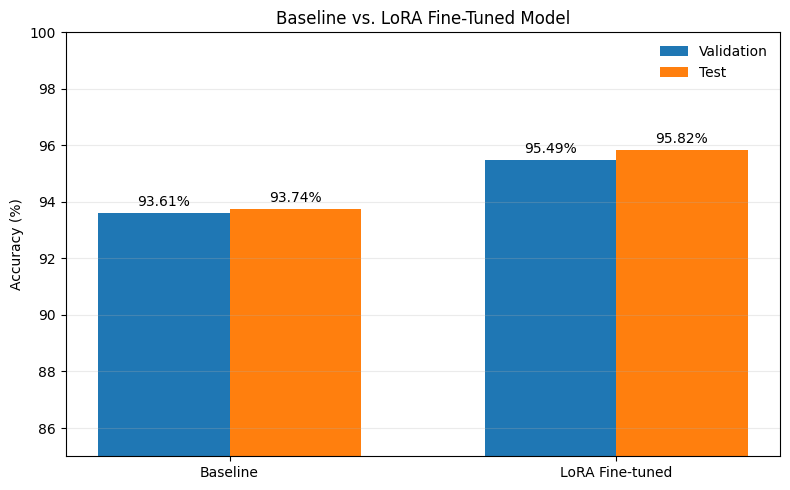

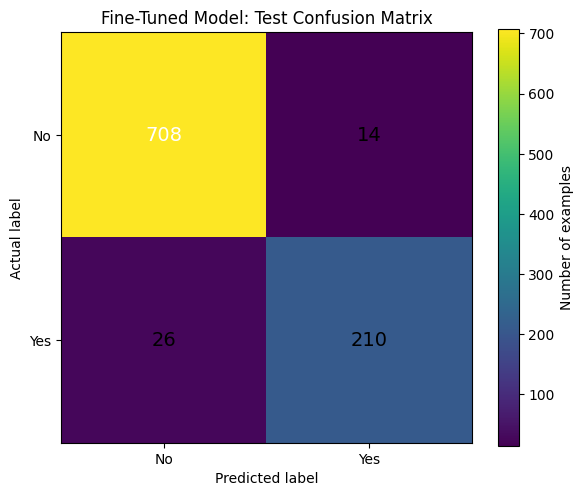

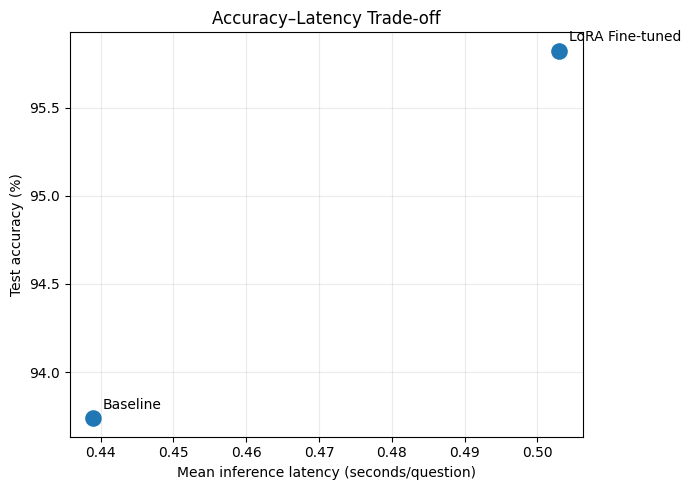

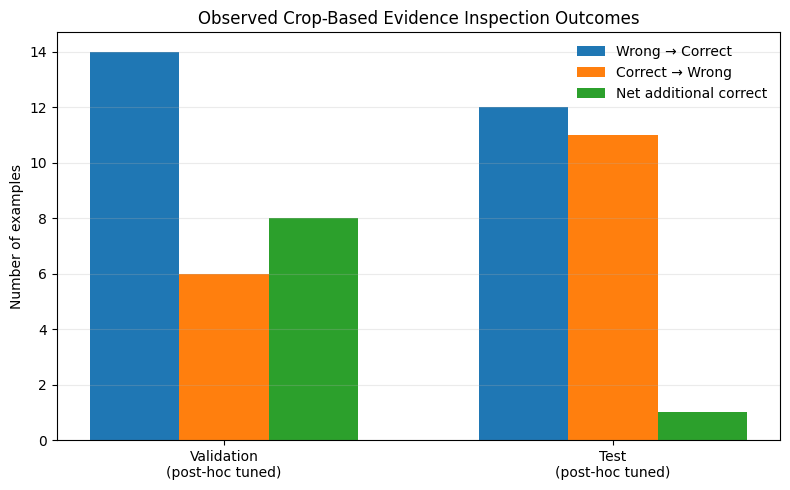

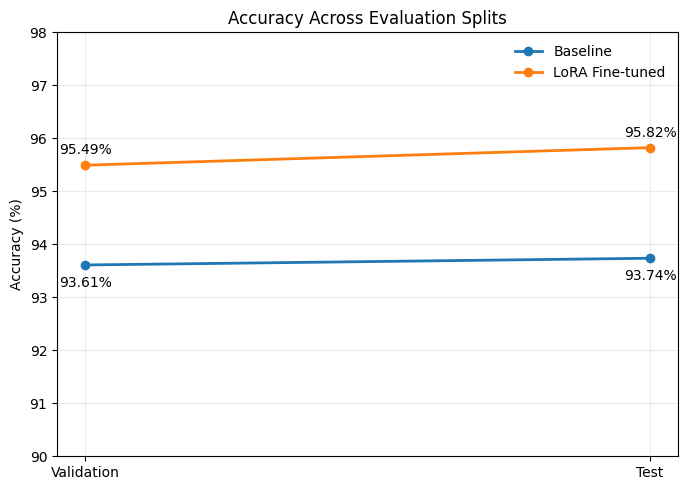


SUCCESS! Created the following ZIP:
/kaggle/working/VEERA_research_figures.zip

Files included:
 - figure1_accuracy_comparison.png
 - figure2_test_confusion_matrix.png
 - figure3_accuracy_latency_tradeoff.png
 - figure4_crop_policy_outcomes.png
 - figure5_accuracy_across_splits.png
 - figure_captions_and_interpretation.txt

In Kaggle, open the right-side Output panel.
Find VEERA_research_figures.zip and click Download.


In [38]:

import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt

# Output folder in Kaggle
OUT_DIR = "/kaggle/working/VEERA_research_figures"
os.makedirs(OUT_DIR, exist_ok=True)

# -----------------------------------------
# FIGURE 1: Baseline vs Fine-tuned Accuracy
# -----------------------------------------
models = ["Baseline", "LoRA Fine-tuned"]
validation = [93.61, 95.49]
test = [93.74, 95.82]

x = np.arange(len(models))
width = 0.34

fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - width/2, validation, width, label="Validation")
b2 = ax.bar(x + width/2, test, width, label="Test")

ax.set_ylabel("Accuracy (%)")
ax.set_title("Baseline vs. LoRA Fine-Tuned Model")
ax.set_xticks(x, models)
ax.set_ylim(85, 100)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
ax.bar_label(b1, fmt="%.2f%%", padding=3)
ax.bar_label(b2, fmt="%.2f%%", padding=3)

fig.tight_layout()
fig.savefig(f"{OUT_DIR}/figure1_accuracy_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# -----------------------------------------
# FIGURE 2: Fine-tuned Test Confusion Matrix
# Rows = actual; columns = predicted
# -----------------------------------------
cm = np.array([
    [708, 14],   # Actual No
    [26, 210]    # Actual Yes
])

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, interpolation="nearest")
ax.set_title("Fine-Tuned Model: Test Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_xticks([0, 1], ["No", "Yes"])
ax.set_yticks([0, 1], ["No", "Yes"])

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > cm.max()/2 else "black",
            fontsize=14
        )

fig.colorbar(im, ax=ax, label="Number of examples")
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/figure2_test_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# -----------------------------------------
# FIGURE 3: Accuracy vs Inference Latency
# -----------------------------------------
names = ["Baseline", "LoRA Fine-tuned"]
latency = [0.439, 0.503]
accuracy = [93.73695, 95.8246]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(latency, accuracy, s=120)

for name, lx, ay in zip(names, latency, accuracy):
    ax.annotate(name, (lx, ay), xytext=(7, 7),
                textcoords="offset points")

ax.set_xlabel("Mean inference latency (seconds/question)")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Accuracy–Latency Trade-off")
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(f"{OUT_DIR}/figure3_accuracy_latency_tradeoff.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# -----------------------------------------
# FIGURE 4: Crop Policy Outcomes
# Exploratory only: policy was tuned post hoc
# -----------------------------------------
splits = [
    "Validation\n(post-hoc tuned)",
    "Test\n(post-hoc tuned)"
]
corrected = [14, 12]
broken = [6, 11]
net_gain = [8, 1]

x = np.arange(len(splits))
width = 0.23

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width, corrected, width, label="Wrong → Correct")
ax.bar(x, broken, width, label="Correct → Wrong")
ax.bar(x + width, net_gain, width, label="Net additional correct")

ax.set_ylabel("Number of examples")
ax.set_title("Observed Crop-Based Evidence Inspection Outcomes")
ax.set_xticks(x, splits)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(f"{OUT_DIR}/figure4_crop_policy_outcomes.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# -----------------------------------------
# FIGURE 5: Accuracy Across Evaluation Splits
# -----------------------------------------
splits = ["Validation", "Test"]
baseline = [93.61, 93.73695]
finetuned = [95.4927, 95.8246]
x = np.arange(2)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, baseline, marker="o", linewidth=2, label="Baseline")
ax.plot(x, finetuned, marker="o", linewidth=2,
        label="LoRA Fine-tuned")

for i, value in enumerate(baseline):
    ax.annotate(f"{value:.2f}%", (x[i], value),
                xytext=(0, -16), textcoords="offset points",
                ha="center")

for i, value in enumerate(finetuned):
    ax.annotate(f"{value:.2f}%", (x[i], value),
                xytext=(0, 8), textcoords="offset points",
                ha="center")

ax.set_xticks(x, splits)
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(90, 98)
ax.set_title("Accuracy Across Evaluation Splits")
ax.legend(frameon=False)
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(f"{OUT_DIR}/figure5_accuracy_across_splits.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# -----------------------------------------
# Research captions and interpretations
# -----------------------------------------
captions = """
VEERA: RESEARCH FIGURE CAPTIONS AND INTERPRETATIONS

FIGURE 1 — Baseline vs. LoRA Fine-Tuned Accuracy

Caption:
Accuracy of the baseline Qwen2.5-VL-3B-Instruct model and its
LoRA fine-tuned version on the RePOPE validation and test splits.

Interpretation:
Validation accuracy increased from 93.61% to 95.49%, an improvement
of 1.88 percentage points. Test accuracy increased from 93.74% to
95.82%, an improvement of approximately 2.09 percentage points.
These results indicate improved binary yes/no classification
performance after fine-tuning on this dataset.


FIGURE 2 — Fine-Tuned Test Confusion Matrix

Caption:
Confusion matrix of the LoRA fine-tuned model on 958 RePOPE
test examples.

Interpretation:
The model correctly classified 708 of 722 actual "no" examples
and 210 of 236 actual "yes" examples. It produced 14 false positives
and 26 false negatives. This shows that false negatives were more
frequent than false positives in this evaluation.


FIGURE 3 — Accuracy–Latency Trade-off

Caption:
Comparison of test accuracy and mean inference latency for the
baseline and LoRA fine-tuned models.

Interpretation:
Fine-tuning improved test accuracy by approximately 2.09 percentage
points. Mean latency increased from approximately 0.439 to 0.503
seconds per question, around 14.6%. Latency depends on the hardware
and inference setup, so these values should be reported with the
experimental environment.


FIGURE 4 — Crop-Based Evidence Inspection Outcomes

Caption:
Number of predictions corrected, broken, and net additional correct
after applying the crop policy to the validation and test splits.

Interpretation:
On validation, 14 errors were corrected and 6 correct predictions
were broken, yielding a net gain of 8. On test, 12 were corrected
and 11 were broken, yielding a net gain of 1.

IMPORTANT LIMITATION:
The crop policy was tuned post hoc on both splits. These numbers are
exploratory and must not be presented as an unbiased estimate of
generalization. Tune the policy on development data and evaluate it
once on a separate untouched test set.


FIGURE 5 — Accuracy Across Evaluation Splits

Caption:
Baseline and LoRA fine-tuned accuracy on validation and test splits.

Interpretation:
The fine-tuned model outperformed the baseline on both recorded
splits. This figure presents the same accuracy results as Figure 1
in a different format; a research paper may use only one of them.


GENERAL LIMITATIONS

1. The model was fine-tuned for binary yes/no classification on
   RePOPE. These results do not establish general-purpose VQA ability.
2. The figures do not independently validate the full adaptive
   evidence acquisition, abstention, or compute-allocation pipeline.
3. The reliability score and coverage-risk curves for the fine-tuned
   model must be calculated from its own prediction scores.
4. Point estimates alone do not establish statistical significance.
   Consider paired confidence intervals or McNemar's test.
"""

caption_path = f"{OUT_DIR}/figure_captions_and_interpretation.txt"
with open(caption_path, "w", encoding="utf-8") as f:
    f.write(captions)

# -----------------------------------------
# Package everything into a ZIP
# -----------------------------------------
ZIP_PATH = "/kaggle/working/VEERA_research_figures.zip"

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in sorted(os.listdir(OUT_DIR)):
        full_path = os.path.join(OUT_DIR, filename)
        z.write(full_path, arcname=filename)

print("\nSUCCESS! Created the following ZIP:")
print(ZIP_PATH)
print("\nFiles included:")
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for name in z.namelist():
        print(" -", name)

print("\nIn Kaggle, open the right-side Output panel.")
print("Find VEERA_research_figures.zip and click Download.")
